MANDAKINI 23 SUBWATERSHEDS ERODIBILITY AND PROIRITIZATION STUDY

## Cell 1 - Install packages and import libraries

In [1]:
# ============================================================
# CELL 1: INSTALL PACKAGES AND IMPORT LIBRARIES
# Mandakini/RUSLE ML-DL workflow
# ============================================================

import sys
import subprocess
import importlib
import warnings
warnings.filterwarnings("ignore")

def install_if_missing(import_name, pip_name=None):
    pip_name = pip_name or import_name
    try:
        importlib.import_module(import_name)
        print(f"Package available: {import_name}")
    except Exception:
        print(f"Installing package: {pip_name}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

# Core ML / explainability / GIS packages
packages = [
    ("catboost", "catboost"),
    ("pytorch_tabnet", "pytorch-tabnet"),
    ("shap", "shap"),
    ("rasterio", "rasterio"),
    ("geopandas", "geopandas"),
    ("rasterstats", "rasterstats"),
    ("pyproj", "pyproj"),
    ("jenkspy", "jenkspy"),
    ("ee", "earthengine-api"),
    ("geemap", "geemap")
]

for import_name, pip_name in packages:
    install_if_missing(import_name, pip_name)

import os
import re
import gc
import json
import time
import math
import shutil
import zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm
from IPython.display import display, Image

from sklearn.model_selection import train_test_split, StratifiedKFold, GroupKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, confusion_matrix,
    classification_report, roc_curve, roc_auc_score
)
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator

from catboost import CatBoostClassifier, Pool
from pytorch_tabnet.tab_model import TabNetClassifier
import torch
import shap

import rasterio
from rasterio.enums import Resampling
from rasterio.warp import reproject, calculate_default_transform
from rasterio.features import geometry_mask
from rasterstats import zonal_stats
import geopandas as gpd
from shapely.geometry import shape, mapping
from pyproj import Transformer
import jenkspy

try:
    import ee
    import geemap
except Exception:
    ee = None
    geemap = None

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.family"] = "DejaVu Sans"

print("Cell 1 completed.")


Installing package: catboost
Installing package: pytorch-tabnet
Package available: shap
Package available: rasterio
Package available: geopandas
Package available: rasterstats
Package available: pyproj
Installing package: jenkspy
Package available: ee
Package available: geemap
Cell 1 completed.


## Cell 2 - Mount Drive, run folders, global settings

In [2]:
# ============================================================
# CELL 2: MOUNT DRIVE, RUN FOLDERS, GLOBAL SETTINGS
# ============================================================

from pathlib import Path
from datetime import datetime

try:
    from google.colab import drive, files
    IN_COLAB = True
except Exception:
    IN_COLAB = False
    files = None

if IN_COLAB:
    drive.mount("/content/drive")

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------
DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/Mandakini_23SW_Model_Inputs")
CSV_NAME = "Mandakini_20700_TargetSamples_10Predictors.csv"

# GEE assets
GEE_PROJECT = "askim-486112"
GEE_RUSLE_ASSET = "projects/askim-486112/assets/Mandakini_RUSLE"
GEE_SW23_ASSET = "projects/askim-486112/assets/Mandakini23SW"

# Study projection and scale
EXPORT_CRS = "EPSG:32644"
EXPORT_SCALE = 30

# ------------------------------------------------------------
# Resume/re-run settings
# ------------------------------------------------------------
# Put an existing run folder name here to resume, for example:
# RESUME_RUN_NAME = "RUN_UPDATED_10PREDICTORS_20260703_120000"
RESUME_RUN_NAME = None

FORCE_RETRAIN_MODELS = False
FORCE_REDO_TEST_EVALUATION = False
FORCE_REDO_CV = False
FORCE_REDO_EXPLAINABILITY = False
FORCE_REDO_FULL_AREA_PREDICTION = False
FORCE_REDO_GLOBAL_NATURAL_BREAKS = False
FORCE_REDO_SW_TABLES_AND_RANKING = False

# ------------------------------------------------------------
# Main modelling settings
# ------------------------------------------------------------
RANDOM_STATE = 42
TEST_SIZE = 0.15
VAL_SIZE_FROM_TRAINVAL = 0.1764705882   # gives 70/15/15 train/val/test
N_SPLITS = 5

# Full-area prediction
CHUNK_SIZE = 100000
MODELS_FOR_FULL_AREA = ["CatBoost", "ExtraTrees", "MLP_ANN", "TabNet"]

# Explainability
EXPLAIN_SAMPLE_N = 1500
EXPLAIN_BACKGROUND_N = 100
EXPLAIN_NSAMPLES = 100
PERMUTATION_IMPORTANCE_REPEATS = 5

# Natural breaks
CLASSIFICATION_METHOD = "GLOBAL_NATURAL_BREAKS_5CLASS"
N_NATURAL_BREAK_CLASSES = 5
GLOBAL_JENKS_MAX_VALUES = 400_000
GLOBAL_JENKS_RANDOM_SEED = 42

# ------------------------------------------------------------
# Strict predictors
# ------------------------------------------------------------
FEATURES = [
    "Lithology",
    "Lineament_Density",
    "Drainage_Density",
    "TRI",
    "TWI",
    "STI",
    "BSI",
    "NBR",
    "MNDWI",
    "LULC"
]

CATEGORICAL_FEATURES = ["Lithology", "LULC"]

NUMERIC_FEATURES = [
    "Lineament_Density",
    "Drainage_Density",
    "TRI",
    "TWI",
    "STI",
    "BSI",
    "NBR",
    "MNDWI"
]

TARGET_COL = "Target"
CLASS_ORDER = [0, 1, 2]
CLASS_LABELS = ["0", "1", "2"]

# 5-class map classes and colors requested
CLASS5_LABELS = {
    1: "Very Low",
    2: "Low",
    3: "Moderate",
    4: "High",
    5: "Very High"
}
CLASS5_COLORS = {
    1: "#1a9850",  # Green
    2: "#ffff00",  # Yellow
    3: "#fdae61",  # Orange
    4: "#d7191c",  # Red
    5: "#762a83"   # Purple
}

# ------------------------------------------------------------
# Run folder logic
# ------------------------------------------------------------
RUN_ID_FILE = DRIVE_PROJECT_DIR / "run_id_updated_10predictors.txt"

if RESUME_RUN_NAME is not None:
    RUN_NAME = RESUME_RUN_NAME
elif RUN_ID_FILE.exists():
    RUN_NAME = RUN_ID_FILE.read_text().strip()
else:
    RUN_NAME = "RUN_UPDATED_10PREDICTORS_" + datetime.now().strftime("%Y%m%d_%H%M%S")
    RUN_ID_FILE.write_text(RUN_NAME)

RUN_DIR = DRIVE_PROJECT_DIR / "Colab_Outputs" / RUN_NAME
MODEL_DIR = RUN_DIR / "models"
PLOT_DIR = RUN_DIR / "plots"
TABLE_DIR = RUN_DIR / "tables"
RASTER_DIR = RUN_DIR / "rasters"
EXPLAIN_DIR = RUN_DIR / "model_explainability"
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
MAP_DIR = RUN_DIR / "publication_maps"

for d in [RUN_DIR, MODEL_DIR, PLOT_DIR, TABLE_DIR, RASTER_DIR, EXPLAIN_DIR, CHECKPOINT_DIR, MAP_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Drive project directory:", DRIVE_PROJECT_DIR)
print("Run name:", RUN_NAME)
print("Run directory:", RUN_DIR)
print("Strict predictors:", FEATURES)
print("Categorical predictors:", CATEGORICAL_FEATURES)
print("Continuous predictors:", NUMERIC_FEATURES)
print("Cell 2 completed.")


Mounted at /content/drive
Drive project directory: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs
Run name: RUN_UPDATED_10PREDICTORS_20260703_130744
Run directory: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744
Strict predictors: ['Lithology', 'Lineament_Density', 'Drainage_Density', 'TRI', 'TWI', 'STI', 'BSI', 'NBR', 'MNDWI', 'LULC']
Categorical predictors: ['Lithology', 'LULC']
Continuous predictors: ['Lineament_Density', 'Drainage_Density', 'TRI', 'TWI', 'STI', 'BSI', 'NBR', 'MNDWI']
Cell 2 completed.


## Cell 3 - Load CSV and validate strict predictor names

In [3]:
# ============================================================
# CELL 3: LOAD CSV AND VALIDATE STRICT PREDICTOR NAMES
# ============================================================

def find_csv_file():
    direct = DRIVE_PROJECT_DIR / CSV_NAME
    if direct.exists():
        return direct

    candidates = []
    patterns = [
        "Mandakini_20700_TargetSamples_10Predictors.csv",
        "Mandakini_20700_TargetSamples_10Predictors*.csv",
        "*TargetSamples*10Predictors*.csv"
    ]
    for pat in patterns:
        candidates.extend(DRIVE_PROJECT_DIR.glob(pat))

    candidates = sorted(set(candidates), key=lambda p: p.stat().st_mtime, reverse=True)
    if not candidates:
        raise FileNotFoundError(f"No target-sample CSV found inside {DRIVE_PROJECT_DIR}")
    return candidates[0]

csv_path = find_csv_file()
print("Using CSV:", csv_path)

df = pd.read_csv(csv_path)
print("Initial shape:", df.shape)

# ------------------------------------------------------------
# Rename old column names to strict new names where needed
# ------------------------------------------------------------
rename_map = {
    "Lithology_ID": "Lithology",
    "Lineament_Density_km_per_km2": "Lineament_Density",
    "Drainage_Density_km_per_km2": "Drainage_Density",
    "SPI": "STI",
    "Distance_to_Streams_m": None,
    "Distance_to_Lineaments_Faults_m": None
}

for old, new in rename_map.items():
    if old in df.columns and new is not None and new not in df.columns:
        df = df.rename(columns={old: new})

# Do not silently create missing predictors.
required_cols = FEATURES + [TARGET_COL]
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(
        "Missing required columns in the CSV: "
        f"{missing}\nAvailable columns are: {list(df.columns)}"
    )

# Keep and clean predictor values
for c in FEATURES:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Categorical predictors: preserve coded classes as integer category codes.
# Do not fill with 0; missing values are treated as an error.
for c in CATEGORICAL_FEATURES:
    if df[c].isna().any():
        bad = int(df[c].isna().sum())
        raise ValueError(f"{c} has {bad} missing values. Fix the GEE extraction before modelling.")
    df[c] = np.rint(df[c]).astype(int)

# Continuous predictors
for c in NUMERIC_FEATURES:
    if df[c].isna().any():
        print(f"Warning: {c} has {df[c].isna().sum()} missing values. They will be imputed in model pipelines.")

df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")
if df[TARGET_COL].isna().any():
    raise ValueError("Target column has missing/non-numeric values.")
df[TARGET_COL] = df[TARGET_COL].astype(int)

# Ensure target classes are 0, 1, 2
bad_targets = sorted(set(df[TARGET_COL].unique()) - set(CLASS_ORDER))
if bad_targets:
    raise ValueError(f"Unexpected target classes found: {bad_targets}. Expected only 0, 1, 2.")

# Metadata columns
META_COLS = [c for c in ["OID", "SWID", "OBJECTID", "longitude", "latitude", "RUSLE_value", "RUSLE_5Class"] if c in df.columns]

# Model matrices
X = df[FEATURES].copy()
y = df[TARGET_COL].copy()

# Save cleaned sample copy
clean_csv = TABLE_DIR / "Clean_TargetSamples_10Predictors_StrictNames.csv"
df.to_csv(clean_csv, index=False)

print("Cleaned shape:", df.shape)
print("Clean sample saved:", clean_csv)
display(df[required_cols + META_COLS[:3]].head())
print("Cell 3 completed.")


Using CSV: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Mandakini_20700_TargetSamples_10Predictors_LithologyCorrected.csv
Initial shape: (20700, 27)
Cleaned shape: (20700, 27)
Clean sample saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Clean_TargetSamples_10Predictors_StrictNames.csv


,Lithology,Lineament_Density,Drainage_Density,TRI,TWI,STI,BSI,NBR,MNDWI,LULC,Target,OID,SWID,OBJECTID
0,19,7.036770,3.705127,21.944374,5.209485,43.565250,-0.174093,0.520621,-0.512913,2,0,SW01_0001,SW01,1
1,4,0.789408,0.506113,8.246211,6.861659,25.550053,-0.230498,0.586758,-0.601396,2,0,SW01_0002,SW01,1
2,19,3.794254,1.069521,3.614101,6.625894,2.652939,0.026253,0.272148,-0.536085,3,0,SW01_0003,SW01,1
3,4,3.259493,3.456845,10.498677,5.174385,15.620175,-0.274083,0.637460,-0.589895,2,0,SW01_0004,SW01,1
4,19,5.793240,3.055775,3.314763,10.753118,3.358453,-0.010008,0.264398,-0.479792,3,0,SW01_0005,SW01,1


Cell 3 completed.


# CELL 3B: REPLACE CSV LITHOLOGY VALUES USING CORRECTED GEOTIFF

In [4]:
# ============================================================
# Uses existing 20,700 point locations from longitude/latitude.
# Point locations will NOT change.
# ============================================================

import numpy as np
import pandas as pd
import rasterio
from pyproj import Transformer
from pathlib import Path
from IPython.display import display

print("Replacing CSV Lithology values using corrected Lithology GeoTIFF...")

# ------------------------------------------------------------
# 1. Locate corrected Lithology GeoTIFF
# ------------------------------------------------------------

lithology_tif = DRIVE_PROJECT_DIR / "Lithology.tif"

if not lithology_tif.exists():
    candidates = list(DRIVE_PROJECT_DIR.glob("*Lithology*.tif")) + list(DRIVE_PROJECT_DIR.glob("*lithology*.tif"))
    candidates = [p for p in candidates if "lookup" not in p.name.lower()]
    candidates = sorted(set(candidates), key=lambda p: p.stat().st_mtime, reverse=True)

    if len(candidates) == 0:
        raise FileNotFoundError(
            f"Could not find Lithology.tif in {DRIVE_PROJECT_DIR}. "
            "Make sure the corrected GeoTIFF is inside the same Drive project folder."
        )

    lithology_tif = candidates[0]

print("Using corrected Lithology raster:", lithology_tif)

# ------------------------------------------------------------
# 2. Check required point-coordinate columns
# ------------------------------------------------------------

required_point_cols = ["longitude", "latitude"]

missing_point_cols = [c for c in required_point_cols if c not in df.columns]
if missing_point_cols:
    raise ValueError(
        f"Missing coordinate columns in df: {missing_point_cols}. "
        "The existing 20,700 CSV must contain longitude and latitude."
    )

# Keep a backup of the bad/original Lithology column
if "Lithology" in df.columns:
    df["Lithology_Original_From_CSV"] = df["Lithology"].copy()
else:
    print("Lithology column was not found in CSV. A new Lithology column will be created.")

# ------------------------------------------------------------
# 3. Sample corrected Lithology raster at existing point locations
# ------------------------------------------------------------

lon = pd.to_numeric(df["longitude"], errors="coerce")
lat = pd.to_numeric(df["latitude"], errors="coerce")

if lon.isna().any() or lat.isna().any():
    raise ValueError("Some longitude/latitude values are missing or non-numeric.")

with rasterio.open(lithology_tif) as src:
    print("Lithology raster CRS:", src.crs)
    print("Lithology raster shape:", src.height, src.width)
    print("Lithology raster nodata:", src.nodata)

    # Convert existing longitude/latitude from EPSG:4326 into raster CRS
    if src.crs is None:
        raise ValueError("Lithology raster has no CRS. Re-export it with a valid CRS.")

    if src.crs.to_string() != "EPSG:4326":
        transformer = Transformer.from_crs("EPSG:4326", src.crs, always_xy=True)
        xs, ys = transformer.transform(lon.values, lat.values)
    else:
        xs, ys = lon.values, lat.values

    coords = list(zip(xs, ys))

    sampled_values = []
    for val in src.sample(coords):
        sampled_values.append(val[0])

    sampled_values = np.array(sampled_values)

    nodata = src.nodata

# ------------------------------------------------------------
# 4. Validate sampled Lithology values
# ------------------------------------------------------------

sampled_series = pd.Series(sampled_values, index=df.index)

# Convert to numeric
sampled_series = pd.to_numeric(sampled_series, errors="coerce")

# Treat raster nodata as missing
if nodata is not None:
    sampled_series = sampled_series.mask(sampled_series == nodata)

# Treat impossible values as missing
# Lithology codes should normally be 1–29
sampled_series = sampled_series.mask(sampled_series < 1)

missing_sampled = sampled_series.isna().sum()

if missing_sampled > 0:
    raise ValueError(
        f"{missing_sampled} points returned missing/nodata Lithology values from the GeoTIFF. "
        "Check whether Lithology.tif fully covers the 20,700 point locations."
    )

# Round to integer class codes
df["Lithology"] = np.rint(sampled_series.values).astype(int)

# ------------------------------------------------------------
# 5. Audit corrected Lithology
# ------------------------------------------------------------

lith_counts = df["Lithology"].value_counts(dropna=False).sort_index()
lith_unique = df["Lithology"].nunique(dropna=True)
lith_std = df["Lithology"].std()

print("\nCorrected Lithology value counts:")
print(lith_counts)

print("\nCorrected Lithology unique classes:", lith_unique)
print("Corrected Lithology standard deviation:", lith_std)

if lith_unique < 2:
    raise ValueError(
        "Corrected Lithology still has fewer than 2 classes. "
        "This means the Lithology GeoTIFF is still not giving real class variation at the 20,700 points."
    )

# ------------------------------------------------------------
# 6. Update X and categorical setup for later cells
# ------------------------------------------------------------

FEATURES = [
    "Lithology",
    "Lineament_Density",
    "Drainage_Density",
    "TRI",
    "TWI",
    "STI",
    "BSI",
    "NBR",
    "MNDWI",
    "LULC"
]

CATEGORICAL_FEATURES = ["Lithology", "LULC"]

NUMERIC_FEATURES = [
    "Lineament_Density",
    "Drainage_Density",
    "TRI",
    "TWI",
    "STI",
    "BSI",
    "NBR",
    "MNDWI"
]

X = df[FEATURES].copy()
y = df[TARGET_COL].copy()

# Ensure categorical features are integer coded
for c in CATEGORICAL_FEATURES:
    X[c] = pd.to_numeric(X[c], errors="coerce").round().astype(int)
    df[c] = pd.to_numeric(df[c], errors="coerce").round().astype(int)

# ------------------------------------------------------------
# 7. Save corrected CSV
# ------------------------------------------------------------

corrected_csv = DRIVE_PROJECT_DIR / "Mandakini_20700_TargetSamples_10Predictors_LithologyCorrected.csv"
df.to_csv(corrected_csv, index=False)

backup_csv = TABLE_DIR / "TargetSamples_10Predictors_LithologyCorrected.csv"
df.to_csv(backup_csv, index=False)

audit_df = lith_counts.reset_index()
audit_df.columns = ["Lithology", "Count"]
audit_df["Percent"] = audit_df["Count"] / len(df) * 100

audit_csv = TABLE_DIR / "Corrected_Lithology_ClassCode_Audit.csv"
audit_df.to_csv(audit_csv, index=False)

display(audit_df)

print("\nSaved corrected CSV to Drive:")
print(corrected_csv)

print("\nSaved corrected CSV backup to run table folder:")
print(backup_csv)

print("\nSaved corrected Lithology audit:")
print(audit_csv)

print("\nCell 3B completed successfully.")
print("The 20,700 point locations were preserved. Only the Lithology values were replaced.")

Replacing CSV Lithology values using corrected Lithology GeoTIFF...
Using corrected Lithology raster: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Lithology.tif
Lithology raster CRS: EPSG:32644
Lithology raster shape: 1909 1741
Lithology raster nodata: None

Corrected Lithology value counts:
Lithology
1      525
2        6
3      264
4     2394
5        1
7      115
8     4295
9        6
10    1442
11       7
12     112
13     205
15       2
16     213
17     127
18      19
19     715
20     638
21     381
22      16
23     913
24    1299
25     631
26      32
27    1448
28    4748
29     146
Name: count, dtype: int64

Corrected Lithology unique classes: 27
Corrected Lithology standard deviation: 9.64122482132672


,Lithology,Count,Percent
0,1,525,2.536232
1,2,6,0.028986
2,3,264,1.275362
3,4,2394,11.565217
4,5,1,0.004831
5,7,115,0.555556
6,8,4295,20.748792
7,9,6,0.028986
8,10,1442,6.966184
9,11,7,0.033816



Saved corrected CSV to Drive:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Mandakini_20700_TargetSamples_10Predictors_LithologyCorrected.csv

Saved corrected CSV backup to run table folder:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/TargetSamples_10Predictors_LithologyCorrected.csv

Saved corrected Lithology audit:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Corrected_Lithology_ClassCode_Audit.csv

Cell 3B completed successfully.
The 20,700 point locations were preserved. Only the Lithology values were replaced.


## Cell 4 - Categorical predictor audit and target distribution

Categorical predictor audit

Lithology
Lithology
1      525
2        6
3      264
4     2394
5        1
7      115
8     4295
9        6
10    1442
11       7
12     112
13     205
15       2
16     213
17     127
18      19
19     715
20     638
21     381
22      16
23     913
24    1299
25     631
26      32
27    1448
28    4748
29     146
Name: count, dtype: int64
Unique classes: 27
Standard deviation of coded classes: 9.64122482132672

LULC
LULC
0      128
1      389
2     5132
3    11459
4     3592
Name: count, dtype: int64
Unique classes: 5
Standard deviation of coded classes: 0.7316132466231426


,Predictor,Class_Code,Count,Percent
0,Lithology,1,525,2.536232
1,Lithology,2,6,0.028986
2,Lithology,3,264,1.275362
3,Lithology,4,2394,11.565217
4,Lithology,5,1,0.004831
5,Lithology,7,115,0.555556
6,Lithology,8,4295,20.748792
7,Lithology,9,6,0.028986
8,Lithology,10,1442,6.966184
9,Lithology,11,7,0.033816


,Target,Count,Percent
0,0,6900,33.333333
1,1,6900,33.333333
2,2,6900,33.333333


,SWID,Target,Count
0,SW01,0,300
1,SW01,1,300
2,SW01,2,300
3,SW02,0,300
4,SW02,1,300
5,SW02,2,300
6,SW03,0,300
7,SW03,1,300
8,SW03,2,300
9,SW04,0,300


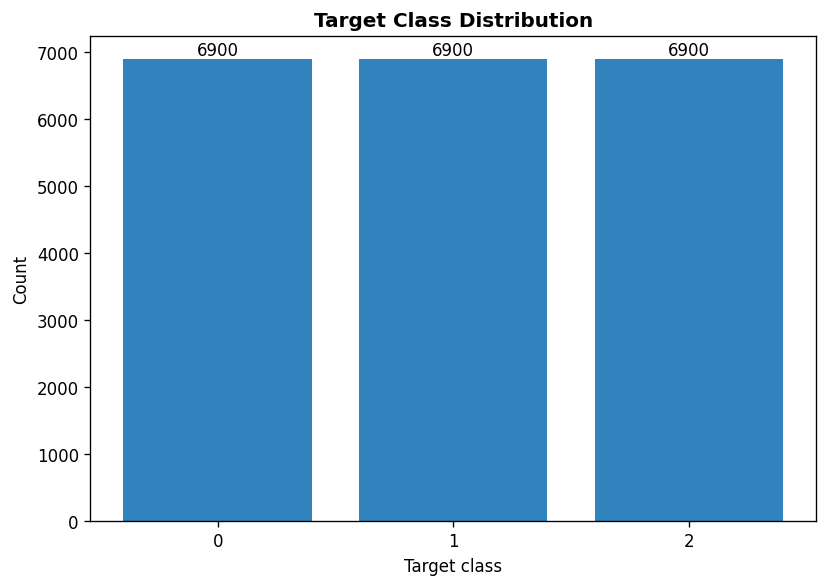

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/Target_Class_Distribution.png
Saved categorical audit: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Categorical_Predictor_ClassCode_Audit.csv
Cell 4 completed.


In [5]:
# ============================================================
# CELL 4: CATEGORICAL PREDICTOR AUDIT AND TARGET DISTRIBUTION
# This cell confirms Lithology and LULC have real class-code variation.
# ============================================================

print("Categorical predictor audit")
audit_rows = []

for c in CATEGORICAL_FEATURES:
    vc = df[c].value_counts(dropna=False).sort_index()
    print("\n", "=" * 60)
    print(c)
    print("=" * 60)
    print(vc)
    print("Unique classes:", df[c].nunique(dropna=True))
    print("Standard deviation of coded classes:", df[c].std())

    if df[c].nunique(dropna=True) < 2:
        raise ValueError(
            f"{c} has fewer than 2 classes in the sample table. "
            "The raster extraction likely failed or the layer has no variation in the samples."
        )

    for code, count in vc.items():
        audit_rows.append({
            "Predictor": c,
            "Class_Code": code,
            "Count": int(count),
            "Percent": float(count / len(df) * 100)
        })

categorical_audit_df = pd.DataFrame(audit_rows)
categorical_audit_csv = TABLE_DIR / "Categorical_Predictor_ClassCode_Audit.csv"
categorical_audit_df.to_csv(categorical_audit_csv, index=False)
display(categorical_audit_df)

# Target distribution
target_dist = df[TARGET_COL].value_counts().sort_index().reset_index()
target_dist.columns = ["Target", "Count"]
target_dist["Percent"] = target_dist["Count"] / len(df) * 100
target_dist_csv = TABLE_DIR / "Target_Class_Distribution.csv"
target_dist.to_csv(target_dist_csv, index=False)
display(target_dist)

# SW distribution if available
if "SWID" in df.columns:
    sw_dist = df.groupby(["SWID", TARGET_COL]).size().reset_index(name="Count")
    sw_dist_csv = TABLE_DIR / "SW_Target_Class_Distribution.csv"
    sw_dist.to_csv(sw_dist_csv, index=False)
    display(sw_dist.head(30))

# Simple target count plot in blue
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(target_dist["Target"].astype(str), target_dist["Count"], color="#3182bd")
ax.set_title("Target Class Distribution", fontweight="bold")
ax.set_xlabel("Target class")
ax.set_ylabel("Count")
for i, row in target_dist.iterrows():
    ax.text(i, row["Count"], f"{int(row['Count'])}", ha="center", va="bottom", fontsize=10)
fig.tight_layout()
out = PLOT_DIR / "Target_Class_Distribution.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", out)
print("Saved categorical audit:", categorical_audit_csv)
print("Cell 4 completed.")


## Cell 5 - Pearson correlation matrix

Creating Pearson correlation matrix for all 10 predictors...
Categorical predictors are included as encoded class codes: ['Lithology', 'LULC']
No fillna(0) will be used.
Absolute correlation values will NOT be used for color.
Rows used for all-10 predictor correlation: 20700

Lithology class-code audit
Lithology
1      525
2        6
3      264
4     2394
5        1
7      115
8     4295
9        6
10    1442
11       7
12     112
13     205
15       2
16     213
17     127
18      19
19     715
20     638
21     381
22      16
23     913
24    1299
25     631
26      32
27    1448
28    4748
29     146
Name: count, dtype: int64
Unique non-null classes: 27
Standard deviation: 9.64122482132672

LULC class-code audit
LULC
0      128
1      389
2     5132
3    11459
4     3592
Name: count, dtype: int64
Unique non-null classes: 5
Standard deviation: 0.7316132466231426


,Predictor,Class_Code,Count,Percent
0,Lithology,1,525,2.536232
1,Lithology,2,6,0.028986
2,Lithology,3,264,1.275362
3,Lithology,4,2394,11.565217
4,Lithology,5,1,0.004831
5,Lithology,7,115,0.555556
6,Lithology,8,4295,20.748792
7,Lithology,9,6,0.028986
8,Lithology,10,1442,6.966184
9,Lithology,11,7,0.033816


,Lithology,Lineament_Density,Drainage_Density,TRI,TWI,STI,BSI,NBR,MNDWI,LULC
Lithology,1.000000,0.001801,-0.040054,-0.063460,0.037097,-0.007947,0.028178,-0.029404,0.006932,-0.006830
Lineament_Density,0.001801,1.000000,-0.233896,0.328832,-0.144418,0.149903,-0.077250,0.088753,0.018515,0.048888
Drainage_Density,-0.040054,-0.233896,1.000000,-0.040101,0.201004,0.122658,0.021248,-0.042597,-0.013666,-0.021139
TRI,-0.063460,0.328832,-0.040101,1.000000,-0.400463,0.324175,-0.109962,0.152294,0.040937,0.033136
TWI,0.037097,-0.144418,0.201004,-0.400463,1.000000,0.547155,0.037146,-0.080089,0.042688,-0.006652
STI,-0.007947,0.149903,0.122658,0.324175,0.547155,1.000000,-0.108287,0.119882,0.005618,-0.005680
BSI,0.028178,-0.077250,0.021248,-0.109962,0.037146,-0.108287,1.000000,-0.963639,-0.242953,0.506850
NBR,-0.029404,0.088753,-0.042597,0.152294,-0.080089,0.119882,-0.963639,1.000000,0.138918,-0.476892
MNDWI,0.006932,0.018515,-0.013666,0.040937,0.042688,0.005618,-0.242953,0.138918,1.000000,-0.043476
LULC,-0.006830,0.048888,-0.021139,0.033136,-0.006652,-0.005680,0.506850,-0.476892,-0.043476,1.000000


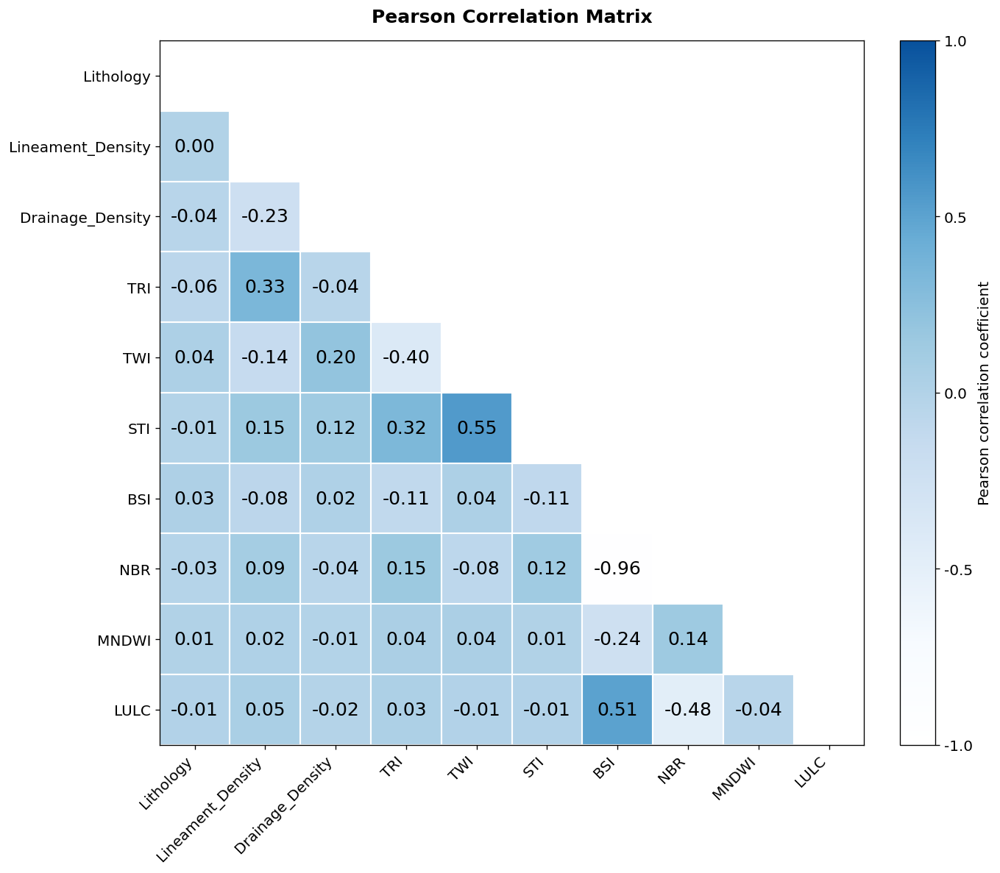

Saved categorical audit table: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Pearson_Categorical_Predictor_ClassCode_Audit.csv
Saved signed correlation table: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Pearson_Correlation_Matrix_All_10_Predictors_EncodedCategorical_Signed_NoFill.csv
Saved signed correlation image: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/Pearson_Correlation_Matrix_All_10_Predictors_EncodedCategorical_Signed_NoFill.png
Saved interpretation note: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Pearson_Correlation_All10_Interpretation_Note.txt
Cell 5 completed.


In [6]:
# ============================================================
# CELL 5: PEARSON CORRELATION MATRIX FOR ALL 10 PREDICTORS
# Lithology and LULC are included as encoded categorical class codes.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import LinearSegmentedColormap

# ------------------------------------------------------------
# 1. Define all 10 predictors using strict names
# ------------------------------------------------------------
ALL_10_PREDICTORS = [
    "Lithology",
    "Lineament_Density",
    "Drainage_Density",
    "TRI",
    "TWI",
    "STI",
    "BSI",
    "NBR",
    "MNDWI",
    "LULC"
]

CATEGORICAL_PREDICTORS = [
    "Lithology",
    "LULC"
]

# ------------------------------------------------------------
# 2. Check required columns
# ------------------------------------------------------------
missing_cols = [
    c for c in ALL_10_PREDICTORS
    if c not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Missing predictor columns in df: {missing_cols}"
    )

TABLE_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print("Creating Pearson correlation matrix for all 10 predictors...")
print(
    "Categorical predictors are included as encoded class codes:",
    CATEGORICAL_PREDICTORS
)
print("No fillna(0) will be used.")
print("Absolute correlation values will NOT be used for color.")

# ------------------------------------------------------------
# 3. Prepare data
# ------------------------------------------------------------
corr_df = df[ALL_10_PREDICTORS].copy()

for c in ALL_10_PREDICTORS:
    corr_df[c] = pd.to_numeric(
        corr_df[c],
        errors="coerce"
    )

# Keep categorical predictors as integer-coded classes
for c in CATEGORICAL_PREDICTORS:

    if corr_df[c].isna().any():
        print(
            f"WARNING: {c} has "
            f"{corr_df[c].isna().sum()} missing values."
        )

    else:
        corr_df[c] = np.rint(
            corr_df[c]
        ).astype(int)

# Replace infinite values with NaN
corr_df = corr_df.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove only rows where all 10 predictors are missing
corr_df = corr_df.dropna(
    how="all",
    subset=ALL_10_PREDICTORS
)

valid_rows = len(corr_df)

print(
    "Rows used for all-10 predictor correlation:",
    valid_rows
)

# ------------------------------------------------------------
# 4. Audit categorical predictor variation
# ------------------------------------------------------------
audit_rows = []

for c in CATEGORICAL_PREDICTORS:

    print("\n" + "=" * 60)
    print(f"{c} class-code audit")
    print("=" * 60)

    vc = (
        corr_df[c]
        .value_counts(dropna=False)
        .sort_index()
    )

    print(vc)

    unique_count = corr_df[c].nunique(
        dropna=True
    )

    std_value = corr_df[c].std(
        skipna=True
    )

    print(
        "Unique non-null classes:",
        unique_count
    )

    print(
        "Standard deviation:",
        std_value
    )

    if unique_count < 2:
        print(
            f"WARNING: {c} has fewer than 2 unique classes. "
            "Pearson correlation involving this predictor "
            "will be undefined and left blank."
        )

    for code, count in vc.items():

        audit_rows.append({
            "Predictor": c,
            "Class_Code": code,
            "Count": int(count),
            "Percent": float(
                count / len(corr_df) * 100
            )
        })

categorical_audit_df = pd.DataFrame(
    audit_rows
)

categorical_audit_csv = (
    TABLE_DIR /
    "Pearson_Categorical_Predictor_ClassCode_Audit.csv"
)

categorical_audit_df.to_csv(
    categorical_audit_csv,
    index=False
)

display(categorical_audit_df)

# ------------------------------------------------------------
# 5. Calculate signed Pearson correlation
# ------------------------------------------------------------
corr_matrix = corr_df[
    ALL_10_PREDICTORS
].corr(
    method="pearson"
)

# IMPORTANT:
# Do NOT use:
#
# corr_matrix.fillna(0)
#
# NaN means the correlation is undefined.
corr_csv = (
    TABLE_DIR /
    "Pearson_Correlation_Matrix_All_10_Predictors_"
    "EncodedCategorical_Signed_NoFill.csv"
)

corr_matrix.to_csv(corr_csv)

display(corr_matrix)

# ------------------------------------------------------------
# 6. Prepare lower-triangle matrix
# ------------------------------------------------------------
labels = ALL_10_PREDICTORS

n = len(labels)

# Mask:
# - upper triangle
# - diagonal
mask_upper_diag = np.triu(
    np.ones(
        (n, n),
        dtype=bool
    ),
    k=0
)

# Keep the TRUE SIGNED correlation values
plot_vals = (
    corr_matrix
    .values
    .copy()
    .astype(float)
)

# Hide upper triangle and diagonal
plot_vals[
    mask_upper_diag
] = np.nan

# ------------------------------------------------------------
# 7. Blue color scale
#
# IMPORTANT:
# No np.abs() is used.
#
# The signed correlation directly controls the color:
#
#   -1.0 = lightest end
#    0.0 = middle blue
#   +1.0 = deepest blue
# ------------------------------------------------------------
blue_cmap = LinearSegmentedColormap.from_list(
    "signed_custom_blues",
    [
        "#ffffff",
        "#f7fbff",
        "#deebf7",
        "#c6dbef",
        "#9ecae1",
        "#6baed6",
        "#3182bd",
        "#08519c"
    ]
)

# Undefined and masked cells remain white
blue_cmap.set_bad(
    color="white"
)

# ------------------------------------------------------------
# 8. Create figure
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(12, 10)
)

# IMPORTANT:
# Use plot_vals directly.
# Do NOT use np.abs(plot_vals).
im = ax.imshow(
    plot_vals,
    cmap=blue_cmap,
    vmin=-1,
    vmax=1
)

# ------------------------------------------------------------
# 9. Axis labels
# ------------------------------------------------------------
ax.set_xticks(
    np.arange(n)
)

ax.set_yticks(
    np.arange(n)
)

ax.set_xticklabels(
    labels,
    rotation=45,
    ha="right",
    fontsize=12
)

ax.set_yticklabels(
    labels,
    fontsize=12
)

# ------------------------------------------------------------
# 10. Write signed values below diagonal only
# ------------------------------------------------------------
for i in range(n):

    for j in range(n):

        if i > j:

            val = corr_matrix.iloc[
                i,
                j
            ]

            # Undefined values remain blank
            if pd.notna(val):

                ax.text(
                    j,
                    i,
                    f"{val:.2f}",
                    ha="center",
                    va="center",
                    color="black",
                    fontsize=15
                )

# ------------------------------------------------------------
# 11. Grid lines
# ------------------------------------------------------------
ax.set_xticks(
    np.arange(
        -0.5,
        n,
        1
    ),
    minor=True
)

ax.set_yticks(
    np.arange(
        -0.5,
        n,
        1
    ),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=1.3
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# ------------------------------------------------------------
# 12. Colorbar
# ------------------------------------------------------------
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Pearson correlation coefficient",
    fontsize=12
)

cbar.set_ticks(
    [-1.0, -0.5, 0.0, 0.5, 1.0]
)

cbar.set_ticklabels(
    ["-1.0", "-0.5", "0.0", "0.5", "1.0"]
)

cbar.ax.tick_params(labelsize=12)

# ------------------------------------------------------------
# 13. Title
# ------------------------------------------------------------
ax.set_title(
    "Pearson Correlation Matrix",
    fontsize=15,
    fontweight="bold",
    pad=15
)

fig.tight_layout()

# ------------------------------------------------------------
# 14. Save figure
# ------------------------------------------------------------
out_png = (
    PLOT_DIR /
    "Pearson_Correlation_Matrix_All_10_Predictors_"
    "EncodedCategorical_Signed_NoFill.png"
)

fig.savefig(
    out_png,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 15. Print output paths
# ------------------------------------------------------------
print(
    "Saved categorical audit table:",
    categorical_audit_csv
)

print(
    "Saved signed correlation table:",
    corr_csv
)

print(
    "Saved signed correlation image:",
    out_png
)

# ------------------------------------------------------------
# 16. Save manuscript interpretation note
# ------------------------------------------------------------
note_path = (
    TABLE_DIR /
    "Pearson_Correlation_All10_Interpretation_Note.txt"
)

note_text = """
Pearson correlation was computed for all 10 input predictors using the encoded
class codes for Lithology and LULC. These two predictors are categorical
variables in the modelling workflow and were not treated as continuous
variables during model training. Their inclusion in this matrix is diagnostic
only. Correlations involving categorical predictors should therefore be
interpreted cautiously because class codes represent category labels rather
than true continuous magnitudes.

The matrix visualization uses the actual signed Pearson correlation
coefficients. Absolute values were not used for color assignment. Therefore,
negative and positive coefficients occupy different positions on the signed
color scale.

No fillna(0) was applied. Undefined correlations were left blank in the
figure. Undefined correlations usually occur when a predictor has no class
variation or zero standard deviation in the sample table.
"""

note_path.write_text(
    note_text.strip()
)

print(
    "Saved interpretation note:",
    note_path
)

print("Cell 5 completed.")

## Cell 6 - Train, validation and test split

In [7]:
# ============================================================
# CELL 6: TRAIN / VALIDATION / TEST SPLIT
# ============================================================

split_path = CHECKPOINT_DIR / "Train_Validation_Test_Indices.json"

if split_path.exists():
    split_info = json.loads(split_path.read_text())
    train_idx = split_info["train_idx"]
    val_idx = split_info["val_idx"]
    test_idx = split_info["test_idx"]
else:
    all_idx = np.arange(len(df))

    trainval_idx, test_idx = train_test_split(
        all_idx,
        test_size=TEST_SIZE,
        stratify=y,
        random_state=RANDOM_STATE
    )

    y_trainval = y.iloc[trainval_idx]

    train_idx, val_idx = train_test_split(
        trainval_idx,
        test_size=VAL_SIZE_FROM_TRAINVAL,
        stratify=y_trainval,
        random_state=RANDOM_STATE
    )

    split_info = {
        "train_idx": [int(i) for i in train_idx],
        "val_idx": [int(i) for i in val_idx],
        "test_idx": [int(i) for i in test_idx]
    }
    split_path.write_text(json.dumps(split_info, indent=2))

X_train = X.iloc[train_idx].copy()
y_train = y.iloc[train_idx].copy()

X_val = X.iloc[val_idx].copy()
y_val = y.iloc[val_idx].copy()

X_test = X.iloc[test_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Train size:", len(X_train))
print("Validation size:", len(X_val))
print("Test size:", len(X_test))

split_summary = pd.DataFrame({
    "Subset": ["Train", "Validation", "Test"],
    "Count": [len(X_train), len(X_val), len(X_test)]
})
display(split_summary)

# Target distribution by split
rows = []
for name, yy in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    vc = yy.value_counts().sort_index()
    for cls in CLASS_ORDER:
        rows.append({"Subset": name, "Target": cls, "Count": int(vc.get(cls, 0))})
split_dist_df = pd.DataFrame(rows)
split_dist_df.to_csv(TABLE_DIR / "Train_Validation_Test_Target_Distribution.csv", index=False)
display(split_dist_df)

print("Cell 6 completed.")


Train size: 14490
Validation size: 3105
Test size: 3105


,Subset,Count
0,Train,14490
1,Validation,3105
2,Test,3105


,Subset,Target,Count
0,Train,0,4830
1,Train,1,4830
2,Train,2,4830
3,Validation,0,1035
4,Validation,1,1035
5,Validation,2,1035
6,Test,0,1035
7,Test,1,1035
8,Test,2,1035


Cell 6 completed.


## Cell 7 - Preprocessors, model builders and prediction helpers

In [8]:
# ============================================================
# CELL 7: PREPROCESSORS, MODEL BUILDERS AND PREDICTION HELPERS
# Categorical predictors are handled like the original Lithology_ID workflow:
# - CatBoost: categorical columns as strings/cat_features
# - ExtraTrees, MLP_ANN, TabNet: one-hot encoding
# - Only continuous predictors are scaled for MLP_ANN and TabNet
# ============================================================

def make_ohe():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

def make_onehot_only_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]), NUMERIC_FEATURES),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", make_ohe())
            ]), CATEGORICAL_FEATURES)
        ],
        remainder="drop"
    )

def make_onehot_scaler_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), NUMERIC_FEATURES),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", make_ohe())
            ]), CATEGORICAL_FEATURES)
        ],
        remainder="drop"
    )

def clean_raw_features(X_input):
    if isinstance(X_input, pd.DataFrame):
        Xp = X_input.copy()
    else:
        Xp = pd.DataFrame(X_input, columns=FEATURES)

    Xp = Xp[FEATURES].copy()

    for c in NUMERIC_FEATURES:
        Xp[c] = pd.to_numeric(Xp[c], errors="coerce")

    for c in CATEGORICAL_FEATURES:
        Xp[c] = pd.to_numeric(Xp[c], errors="coerce")
        if Xp[c].isna().any():
            raise ValueError(f"{c} contains NaN during prediction/preprocessing.")
        Xp[c] = np.rint(Xp[c]).astype(int)

    return Xp

def prepare_catboost_features(X_input):
    Xp = clean_raw_features(X_input)
    for c in CATEGORICAL_FEATURES:
        Xp[c] = Xp[c].astype(str)
    return Xp

def build_catboost():
    return CatBoostClassifier(
        loss_function="MultiClass",
        eval_metric="TotalF1",
        iterations=1200,
        learning_rate=0.03,
        depth=6,
        random_seed=RANDOM_STATE,
        l2_leaf_reg=3,
        early_stopping_rounds=120,
        verbose=200
    )

def build_extratrees():
    return Pipeline([
        ("preprocess", make_onehot_only_preprocessor()),
        ("model", ExtraTreesClassifier(
            n_estimators=800,
            max_features="sqrt",
            min_samples_leaf=1,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            class_weight="balanced"
        ))
    ])

def build_mlp():
    return Pipeline([
        ("preprocess", make_onehot_scaler_preprocessor()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(128, 64, 32),
            activation="relu",
            solver="adam",
            alpha=1e-4,
            learning_rate_init=1e-3,
            batch_size=256,
            max_iter=600,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=30,
            random_state=RANDOM_STATE,
            verbose=False
        ))
    ])

def build_tabnet():
    preprocessor = make_onehot_scaler_preprocessor()
    model = TabNetClassifier(
        n_d=32,
        n_a=32,
        n_steps=5,
        gamma=1.5,
        lambda_sparse=1e-4,
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=2e-2),
        scheduler_params={"step_size": 30, "gamma": 0.85},
        scheduler_fn=torch.optim.lr_scheduler.StepLR,
        mask_type="entmax",
        seed=RANDOM_STATE,
        verbose=10
    )
    return {"preprocessor": preprocessor, "model": model}

def get_model_classes(model_name, model):
    if model_name == "TabNet":
        return list(model["model"].classes_) if hasattr(model["model"], "classes_") else CLASS_ORDER
    if hasattr(model, "classes_"):
        return list(model.classes_)
    if hasattr(model, "named_steps") and hasattr(model.named_steps["model"], "classes_"):
        return list(model.named_steps["model"].classes_)
    return CLASS_ORDER

def align_proba_to_012(y_prob, model_classes):
    y_prob = np.asarray(y_prob)
    aligned = np.zeros((y_prob.shape[0], 3), dtype=float)
    for src_idx, cls in enumerate(model_classes):
        cls_int = int(cls)
        if cls_int in CLASS_ORDER:
            aligned[:, CLASS_ORDER.index(cls_int)] = y_prob[:, src_idx]
    return aligned

def predict_proba_model(model_name, model, X_input):
    Xp = clean_raw_features(X_input)

    if model_name == "CatBoost":
        Xc = prepare_catboost_features(Xp)
        y_prob = model.predict_proba(Xc)

    elif model_name in ["ExtraTrees", "MLP_ANN"]:
        y_prob = model.predict_proba(Xp)

    elif model_name == "TabNet":
        Xt = model["preprocessor"].transform(Xp).astype(np.float32)
        y_prob = model["model"].predict_proba(Xt)

    else:
        raise ValueError(model_name)

    return align_proba_to_012(y_prob, get_model_classes(model_name, model))

def predict_model(model_name, model, X_input):
    y_prob = predict_proba_model(model_name, model, X_input)
    y_pred = np.argmax(y_prob, axis=1)
    return y_pred, y_prob

def predict_susceptibility_score(model_name, model, X_input):
    y_prob = predict_proba_model(model_name, model, X_input)
    return y_prob[:, 2] + 0.5 * y_prob[:, 1]

def save_show(fig, out_path):
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", out_path)

print("Cell 7 completed.")


Cell 7 completed.


## Cell 8 - Train or load final models

In [9]:
# ============================================================
# CELL 8: TRAIN OR LOAD FINAL MODELS
# ============================================================

final_models = {}

def train_catboost_final():
    model_path = MODEL_DIR / "CatBoost_final.cbm"
    if model_path.exists() and not FORCE_RETRAIN_MODELS:
        model = CatBoostClassifier()
        model.load_model(str(model_path))
        print("Loaded existing CatBoost model.")
        return model

    train_pool = Pool(
        prepare_catboost_features(X_train),
        y_train,
        cat_features=CATEGORICAL_FEATURES
    )
    val_pool = Pool(
        prepare_catboost_features(X_val),
        y_val,
        cat_features=CATEGORICAL_FEATURES
    )

    model = build_catboost()
    model.fit(train_pool, eval_set=val_pool, use_best_model=True)
    model.save_model(str(model_path))
    return model

def train_extratrees_final():
    model_path = MODEL_DIR / "ExtraTrees_final.joblib"
    if model_path.exists() and not FORCE_RETRAIN_MODELS:
        print("Loaded existing ExtraTrees model.")
        return joblib.load(model_path)

    model = build_extratrees()
    model.fit(X_train, y_train)
    joblib.dump(model, model_path)
    return model

def train_mlp_final():
    model_path = MODEL_DIR / "MLP_ANN_final.joblib"
    if model_path.exists() and not FORCE_RETRAIN_MODELS:
        print("Loaded existing MLP_ANN model.")
        return joblib.load(model_path)

    model = build_mlp()
    model.fit(X_train, y_train)
    joblib.dump(model, model_path)
    return model

def train_tabnet_final():
    model_zip = MODEL_DIR / "TabNet_final.zip"
    prep_path = MODEL_DIR / "TabNet_preprocessor_final.joblib"

    if model_zip.exists() and prep_path.exists() and not FORCE_RETRAIN_MODELS:
        print("Loaded existing TabNet model.")
        preprocessor = joblib.load(prep_path)
        model = TabNetClassifier()
        model.load_model(str(model_zip))
        return {"preprocessor": preprocessor, "model": model}

    tabpack = build_tabnet()
    preprocessor = tabpack["preprocessor"]
    model = tabpack["model"]

    Xtr = preprocessor.fit_transform(X_train).astype(np.float32)
    Xv = preprocessor.transform(X_val).astype(np.float32)

    model.fit(
        X_train=Xtr,
        y_train=y_train.values,
        eval_set=[(Xv, y_val.values)],
        eval_name=["valid"],
        eval_metric=["accuracy"],
        max_epochs=200,
        patience=30,
        batch_size=1024,
        virtual_batch_size=128,
        num_workers=0,
        drop_last=False
    )

    model.save_model(str(model_zip).replace(".zip", ""))
    joblib.dump(preprocessor, prep_path)
    return {"preprocessor": preprocessor, "model": model}

start = time.time()
final_models["CatBoost"] = train_catboost_final()
final_models["ExtraTrees"] = train_extratrees_final()
final_models["MLP_ANN"] = train_mlp_final()
final_models["TabNet"] = train_tabnet_final()

print("Final model training/loading completed in minutes:", round((time.time() - start) / 60, 2))
print("Models:", list(final_models.keys()))
print("Cell 8 completed.")


Loaded existing CatBoost model.
Loaded existing ExtraTrees model.
Loaded existing MLP_ANN model.
Loaded existing TabNet model.
Final model training/loading completed in minutes: 0.32
Models: ['CatBoost', 'ExtraTrees', 'MLP_ANN', 'TabNet']
Cell 8 completed.


## Cell 9 - Test evaluation, confusion matrices and ROC curves

Starting test evaluation...
Models available: ['CatBoost', 'ExtraTrees', 'MLP_ANN', 'TabNet']
Predictors used: ['Lithology', 'Lineament_Density', 'Drainage_Density', 'TRI', 'TWI', 'STI', 'BSI', 'NBR', 'MNDWI', 'LULC']
Categorical predictors: ['Lithology', 'LULC']
Class order: [0, 1, 2]
Class labels: ['0', '1', '2']

Test sample count: 3105
Test target distribution:
0    1035
1    1035
2    1035
Name: count, dtype: int64

Evaluating model: CatBoost
Prediction completed.
Probability shape: (3105, 3)
Predicted class distribution:
0     963
1    1197
2     945
Name: count, dtype: int64


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted,Cohen_Kappa,MCC,ROC_AUC_Micro
0,CatBoost,0.894686,0.902833,0.894686,0.896227,0.902833,0.894686,0.896227,0.842029,0.84463,0.980111


,precision,recall,f1-score,support
Class_0,0.979232,0.911111,0.943944,1035.000000
Class_1,0.796992,0.921739,0.854839,1035.000000
Class_2,0.932275,0.851208,0.889899,1035.000000
accuracy,0.894686,0.894686,0.894686,0.894686
macro avg,0.902833,0.894686,0.896227,3105.000000
weighted avg,0.902833,0.894686,0.896227,3105.000000


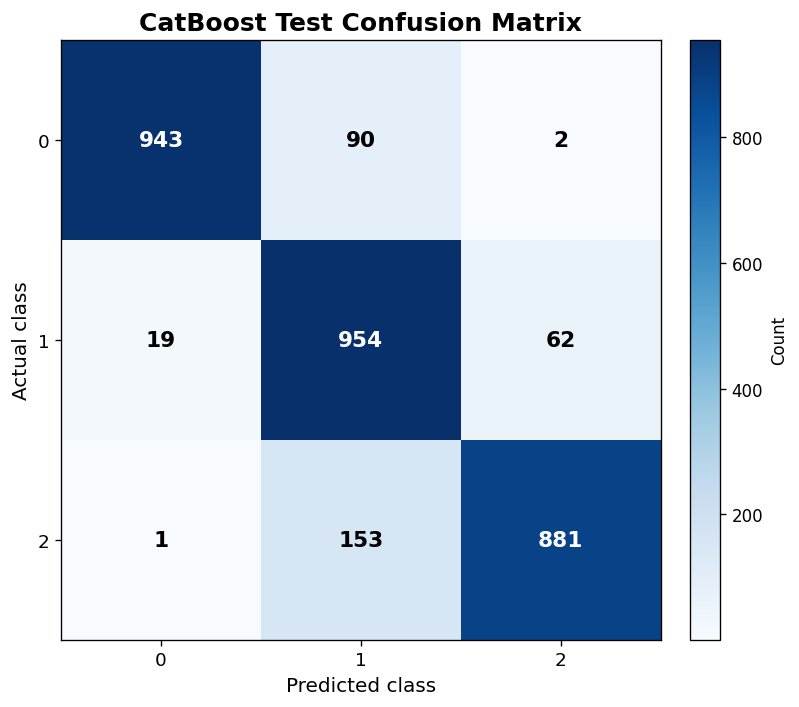

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/CatBoost_Test_Confusion_Matrix.png


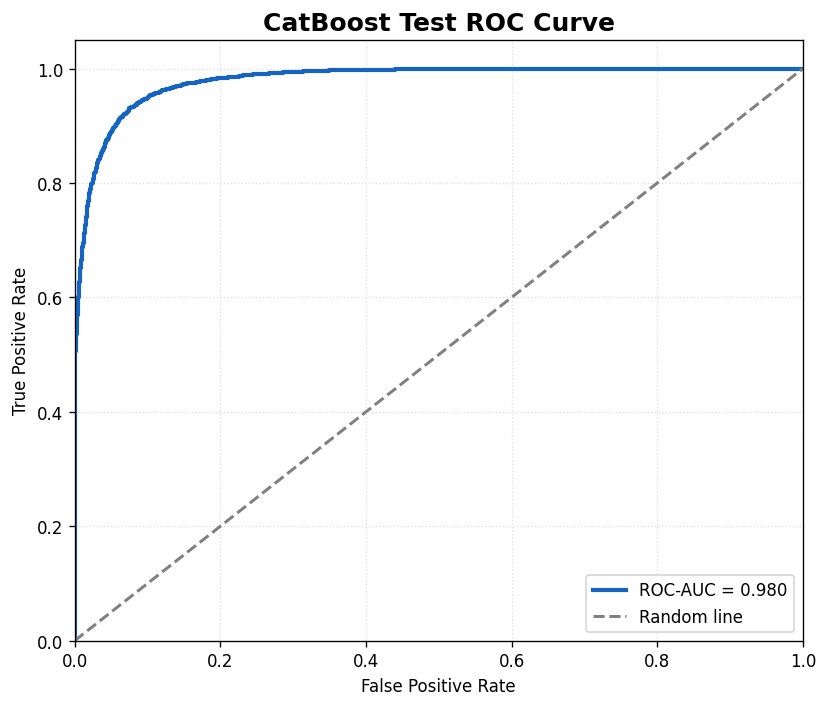

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/CatBoost_Test_ROC_Curve.png

Evaluating model: ExtraTrees
Prediction completed.
Probability shape: (3105, 3)
Predicted class distribution:
0     965
1    1187
2     953
Name: count, dtype: int64


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted,Cohen_Kappa,MCC,ROC_AUC_Micro
0,ExtraTrees,0.834461,0.842952,0.834461,0.83665,0.842952,0.834461,0.83665,0.751691,0.75373,0.954424


,precision,recall,f1-score,support
Class_0,0.938860,0.875362,0.906000,1035.000000
Class_1,0.725358,0.831884,0.774977,1035.000000
Class_2,0.864638,0.796135,0.828974,1035.000000
accuracy,0.834461,0.834461,0.834461,0.834461
macro avg,0.842952,0.834461,0.836650,3105.000000
weighted avg,0.842952,0.834461,0.836650,3105.000000


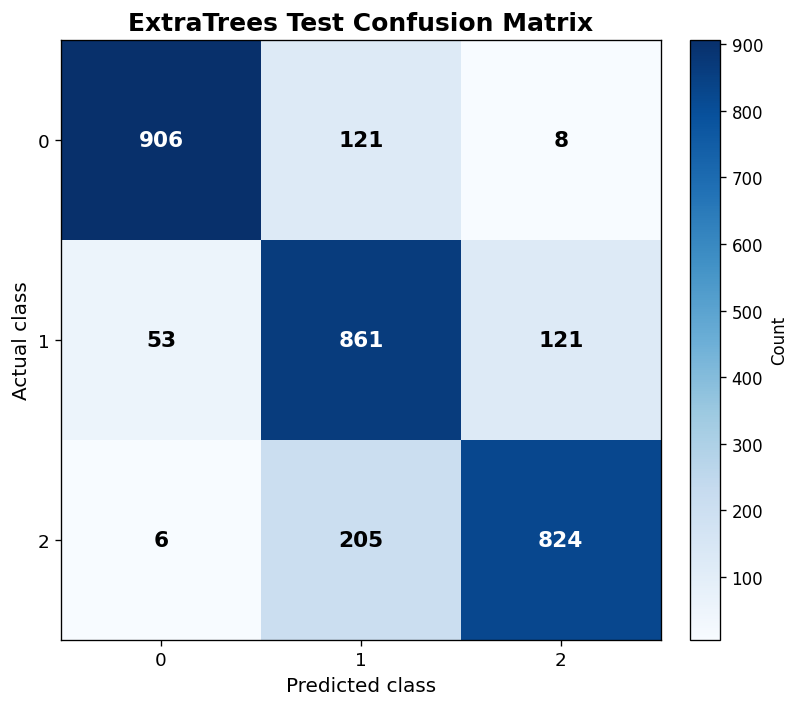

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/ExtraTrees_Test_Confusion_Matrix.png


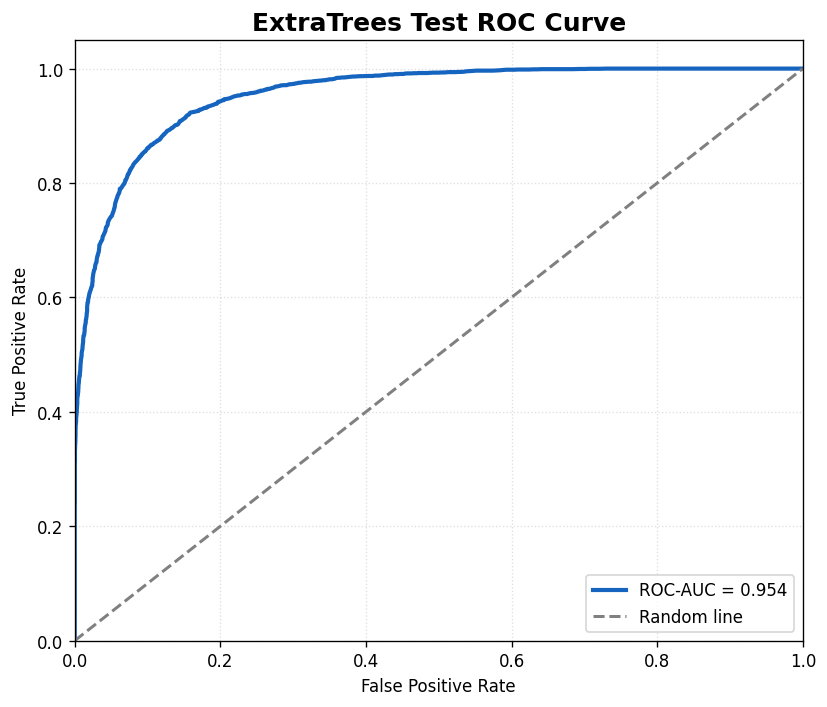

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/ExtraTrees_Test_ROC_Curve.png

Evaluating model: MLP_ANN
Prediction completed.
Probability shape: (3105, 3)
Predicted class distribution:
0     987
1    1082
2    1036
Name: count, dtype: int64


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted,Cohen_Kappa,MCC,ROC_AUC_Micro
0,MLP_ANN,0.899195,0.901184,0.899195,0.899872,0.901184,0.899195,0.899872,0.848792,0.84909,0.982494


,precision,recall,f1-score,support
Class_0,0.965552,0.920773,0.942631,1035.000000
Class_1,0.835490,0.873430,0.854039,1035.000000
Class_2,0.902510,0.903382,0.902945,1035.000000
accuracy,0.899195,0.899195,0.899195,0.899195
macro avg,0.901184,0.899195,0.899872,3105.000000
weighted avg,0.901184,0.899195,0.899872,3105.000000


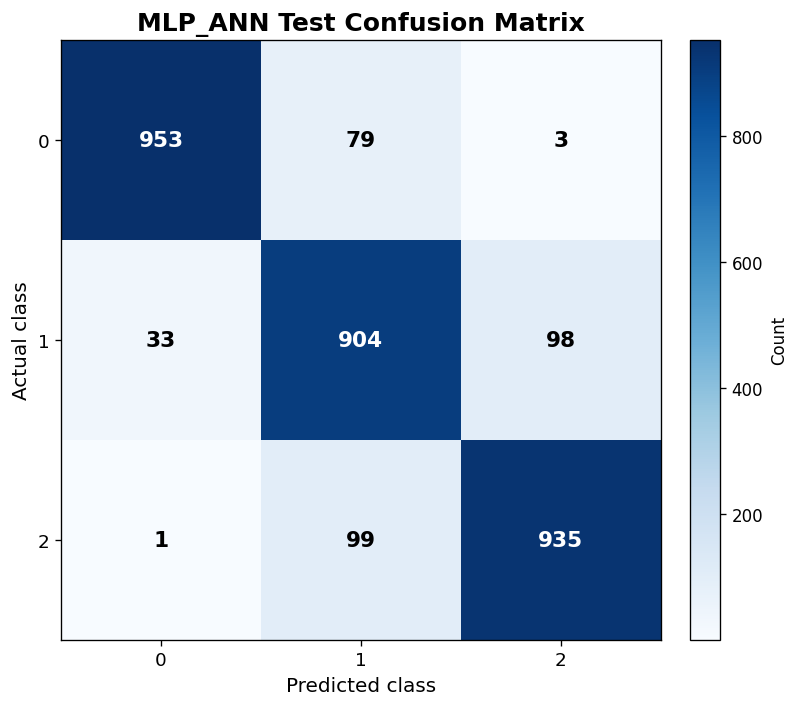

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/MLP_ANN_Test_Confusion_Matrix.png


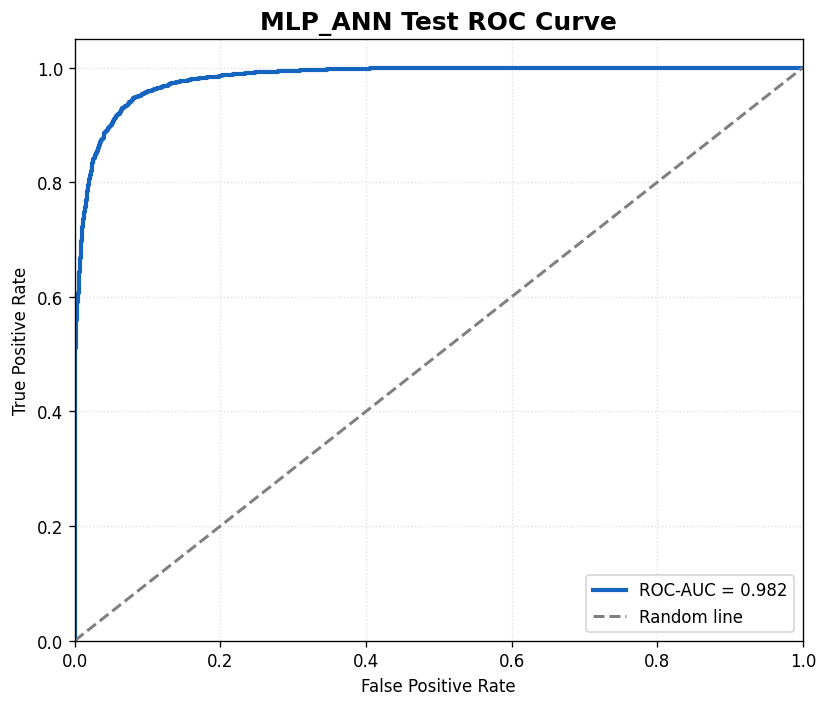

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/MLP_ANN_Test_ROC_Curve.png

Evaluating model: TabNet
Prediction completed.
Probability shape: (3105, 3)
Predicted class distribution:
0     973
1    1157
2     975
Name: count, dtype: int64


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted,Cohen_Kappa,MCC,ROC_AUC_Micro
0,TabNet,0.902093,0.907399,0.902093,0.903283,0.907399,0.902093,0.903283,0.85314,0.854626,0.981304


,precision,recall,f1-score,support
Class_0,0.975334,0.916908,0.945219,1035.000000
Class_1,0.817632,0.914010,0.863139,1035.000000
Class_2,0.929231,0.875362,0.901493,1035.000000
accuracy,0.902093,0.902093,0.902093,0.902093
macro avg,0.907399,0.902093,0.903283,3105.000000
weighted avg,0.907399,0.902093,0.903283,3105.000000


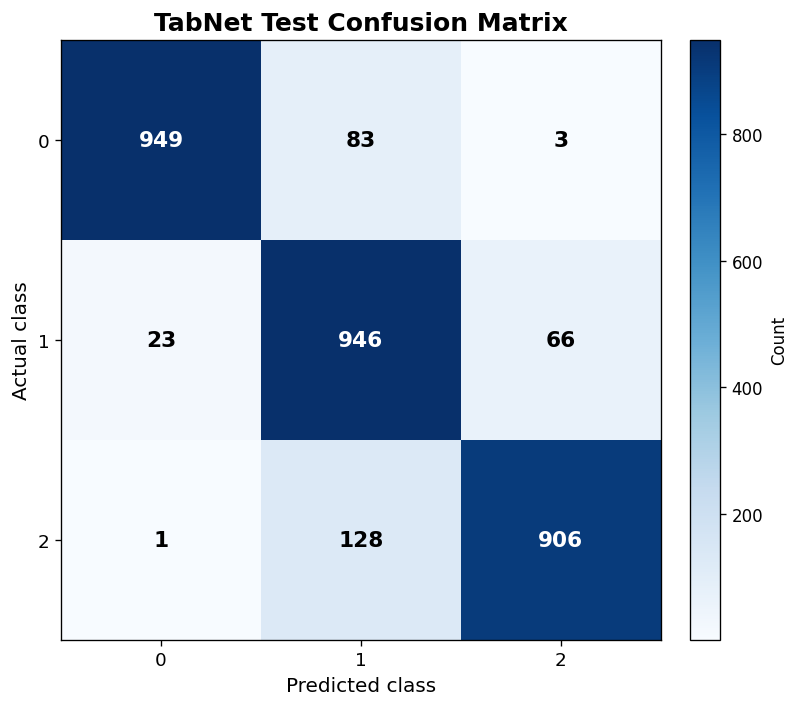

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/TabNet_Test_Confusion_Matrix.png


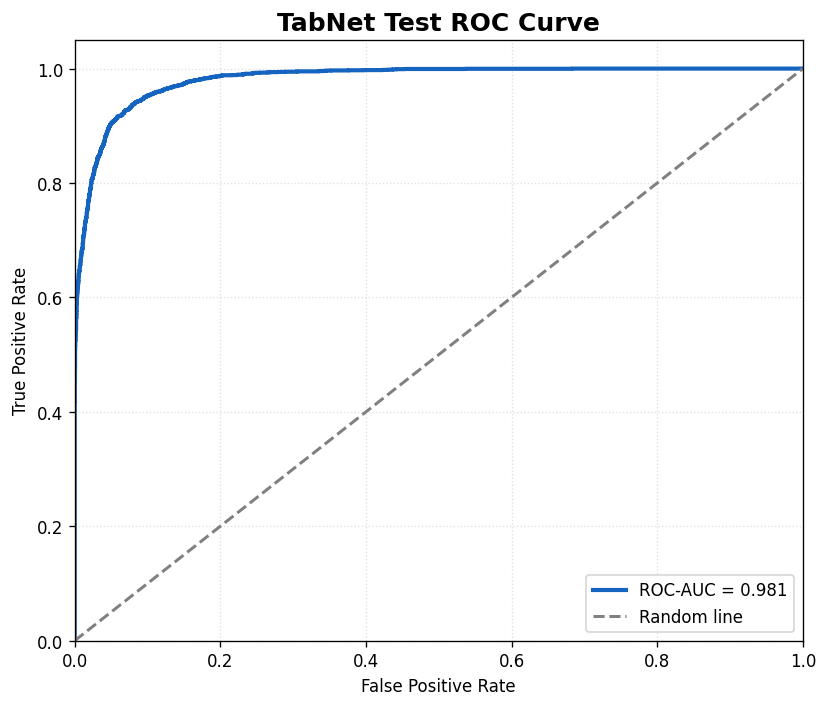

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/TabNet_Test_ROC_Curve.png


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted,Cohen_Kappa,MCC,ROC_AUC_Micro
0,MLP_ANN,0.899195,0.901184,0.899195,0.899872,0.901184,0.899195,0.899872,0.848792,0.849090,0.982494
1,TabNet,0.902093,0.907399,0.902093,0.903283,0.907399,0.902093,0.903283,0.853140,0.854626,0.981304
2,CatBoost,0.894686,0.902833,0.894686,0.896227,0.902833,0.894686,0.896227,0.842029,0.844630,0.980111
3,ExtraTrees,0.834461,0.842952,0.834461,0.836650,0.842952,0.834461,0.836650,0.751691,0.753730,0.954424


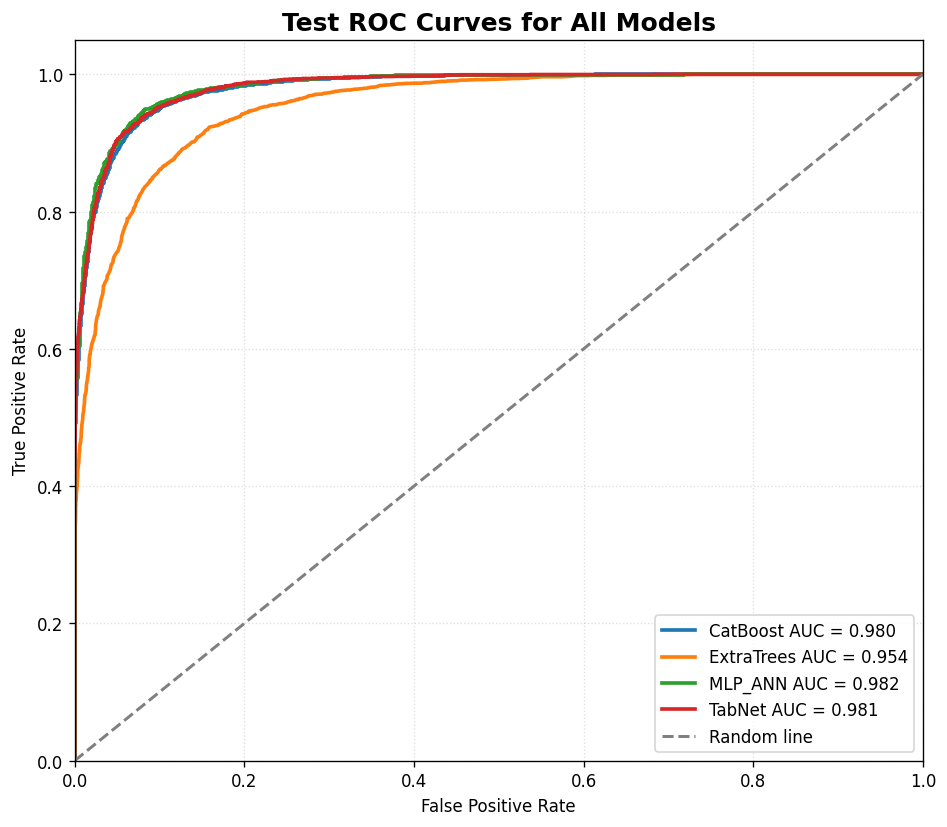

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/All_Models_Test_ROC_Curves.png


,Model,ROC_AUC_Micro
0,CatBoost,0.980111
1,ExtraTrees,0.954424
2,MLP_ANN,0.982494
3,TabNet,0.981304



Cell 9 completed successfully.


In [10]:
# ============================================================
# CELL 9: TEST EVALUATION, BLUE CONFUSION MATRICES AND ROC CURVES
# OUTPUTS:
# - Individual test metrics CSV
# - Combined test metrics CSV
# - Individual classification reports
# - Blue confusion matrices
# - Individual ROC curves
# - Combined ROC curve
#
# ROC STYLE:
# - Individual legend: ROC-AUC =
# - Dashed line: Random line
# - Combined legend: ModelName AUC =
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix
)

from sklearn.preprocessing import label_binarize


# ============================================================
# 1. REQUIRED SETTINGS AND CHECKS
# ============================================================

TABLE_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Use existing strict project settings where available.
if "CLASS_ORDER" not in globals():
    CLASS_ORDER = [0, 1, 2]

CLASS_ORDER = [int(c) for c in list(CLASS_ORDER)]

if "CLASS_LABELS" not in globals():
    CLASS_LABELS = [
        "Low",
        "Moderate",
        "High"
    ]

CLASS_LABELS = list(CLASS_LABELS)

if len(CLASS_LABELS) != len(CLASS_ORDER):
    raise ValueError(
        "CLASS_LABELS and CLASS_ORDER must contain the same number of classes."
    )

if "CATEGORICAL_FEATURES" not in globals():
    CATEGORICAL_FEATURES = [
        "Lithology",
        "LULC"
    ]

if "FEATURES" not in globals():
    FEATURES = [
        "Lithology",
        "Lineament_Density",
        "Drainage_Density",
        "TRI",
        "TWI",
        "STI",
        "BSI",
        "NBR",
        "MNDWI",
        "LULC"
    ]

required_objects = [
    "X_test",
    "y_test",
    "final_models"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise ValueError(
        f"Missing required notebook objects: {missing_objects}"
    )

missing_features = [
    c
    for c in FEATURES
    if c not in X_test.columns
]

if missing_features:
    raise ValueError(
        f"X_test is missing predictor columns: {missing_features}"
    )

print("Starting test evaluation...")
print("Models available:", list(final_models.keys()))
print("Predictors used:", FEATURES)
print("Categorical predictors:", CATEGORICAL_FEATURES)
print("Class order:", CLASS_ORDER)
print("Class labels:", CLASS_LABELS)


# ============================================================
# 2. LOCAL SAVE FUNCTION
# Prevents failure if the earlier save_show helper is unavailable.
# ============================================================

def save_show_evaluation(fig, out_path):

    out_path = Path(out_path)

    out_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    fig.savefig(
        out_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", out_path)


# ============================================================
# 3. PREPARE RAW FEATURE DATA
# ============================================================

def prepare_evaluation_features(X_input):
    """
    Prepare the strict 10 raw predictor columns.

    Continuous predictors remain numerical.
    Lithology and LULC remain categorical class codes.
    """

    if isinstance(X_input, pd.DataFrame):

        Xdf = X_input.copy()

    else:

        Xdf = pd.DataFrame(
            np.asarray(X_input),
            columns=FEATURES
        )

    # Strict predictor order
    Xdf = Xdf[FEATURES].copy()

    # Convert all predictor values to numeric first
    for c in FEATURES:

        Xdf[c] = pd.to_numeric(
            Xdf[c],
            errors="coerce"
        )

    # Check missing values
    missing_counts = Xdf.isna().sum()

    bad_missing = missing_counts[
        missing_counts > 0
    ]

    if len(bad_missing) > 0:

        raise ValueError(
            "Missing/non-numeric values found in evaluation predictors:\n"
            f"{bad_missing}"
        )

    # Keep categorical predictors as real whole-number class codes
    for c in CATEGORICAL_FEATURES:

        Xdf[c] = np.rint(
            Xdf[c].values
        ).astype(int)

    return Xdf


# ============================================================
# 4. ALIGN MODEL PROBABILITIES TO STRICT CLASS ORDER
# ============================================================

def align_probabilities_to_class_order(
    probabilities,
    model_classes=None
):
    """
    Returns probability columns strictly ordered according to CLASS_ORDER.
    """

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    if probabilities.ndim != 2:

        raise ValueError(
            f"Probability output must be 2D. "
            f"Received shape: {probabilities.shape}"
        )

    n_samples = probabilities.shape[0]
    n_classes = len(CLASS_ORDER)

    aligned = np.zeros(
        (n_samples, n_classes),
        dtype=float
    )

    # If model classes are unavailable, require direct column agreement.
    if model_classes is None:

        if probabilities.shape[1] != n_classes:

            raise ValueError(
                "Model class labels are unavailable and probability "
                f"output has {probabilities.shape[1]} columns, while "
                f"CLASS_ORDER has {n_classes} classes."
            )

        return probabilities

    model_classes = [
        int(c)
        for c in np.asarray(
            model_classes
        ).ravel()
    ]

    if len(model_classes) != probabilities.shape[1]:

        raise ValueError(
            "Number of model classes does not match probability columns. "
            f"Classes: {model_classes}; "
            f"Probability shape: {probabilities.shape}"
        )

    for probability_column, class_code in enumerate(model_classes):

        if class_code not in CLASS_ORDER:

            raise ValueError(
                f"Model returned unexpected class {class_code}. "
                f"Expected classes: {CLASS_ORDER}"
            )

        target_column = CLASS_ORDER.index(
            class_code
        )

        aligned[
            :,
            target_column
        ] = probabilities[
            :,
            probability_column
        ]

    return aligned


# ============================================================
# 5. FIXED PREDICTION HELPER
# This is the missing function that caused the NameError.
# ============================================================

def predict_model(
    model_name,
    model,
    X_input
):
    """
    Return:
        y_pred : predicted class codes
        y_prob : probabilities aligned to CLASS_ORDER

    Handles:
        CatBoost
        ExtraTrees
        MLP_ANN
        TabNet
    """

    Xraw = prepare_evaluation_features(
        X_input
    )

    # --------------------------------------------------------
    # CATBOOST
    # Lithology and LULC are categorical.
    # CatBoost receives them as strings.
    # --------------------------------------------------------

    if model_name == "CatBoost":

        Xmodel = Xraw.copy()

        for c in CATEGORICAL_FEATURES:

            Xmodel[c] = (
                Xmodel[c]
                .astype(str)
            )

        y_prob_raw = model.predict_proba(
            Xmodel
        )

        model_classes = getattr(
            model,
            "classes_",
            CLASS_ORDER
        )

        y_prob = align_probabilities_to_class_order(
            y_prob_raw,
            model_classes
        )

        # Derive predictions from aligned probabilities.
        # This guarantees strict agreement with CLASS_ORDER.
        predicted_indices = np.argmax(
            y_prob,
            axis=1
        )

        y_pred = np.asarray(
            [
                CLASS_ORDER[i]
                for i in predicted_indices
            ],
            dtype=int
        )

        return y_pred, y_prob


    # --------------------------------------------------------
    # EXTRATREES AND MLP/ANN
    # Their fitted pipelines/models handle preprocessing.
    # Raw categorical class codes remain integers.
    # --------------------------------------------------------

    elif model_name in [
        "ExtraTrees",
        "MLP_ANN"
    ]:

        Xmodel = Xraw.copy()

        y_prob_raw = model.predict_proba(
            Xmodel
        )

        model_classes = getattr(
            model,
            "classes_",
            None
        )

        # For sklearn pipelines, classes_ may be exposed through
        # the final estimator if not directly available.
        if model_classes is None:

            if hasattr(
                model,
                "named_steps"
            ):

                for possible_step in [
                    "model",
                    "classifier",
                    "estimator"
                ]:

                    if possible_step in model.named_steps:

                        final_estimator = (
                            model.named_steps[
                                possible_step
                            ]
                        )

                        model_classes = getattr(
                            final_estimator,
                            "classes_",
                            None
                        )

                        if model_classes is not None:
                            break

        if model_classes is None:

            model_classes = CLASS_ORDER

        y_prob = align_probabilities_to_class_order(
            y_prob_raw,
            model_classes
        )

        predicted_indices = np.argmax(
            y_prob,
            axis=1
        )

        y_pred = np.asarray(
            [
                CLASS_ORDER[i]
                for i in predicted_indices
            ],
            dtype=int
        )

        return y_pred, y_prob


    # --------------------------------------------------------
    # TABNET
    # Expected fitted structure:
    # {
    #     "preprocessor": fitted preprocessor,
    #     "model": fitted TabNet model
    # }
    # --------------------------------------------------------

    elif model_name == "TabNet":

        if not isinstance(
            model,
            dict
        ):

            raise TypeError(
                "TabNet final model must be a dictionary containing "
                "'preprocessor' and 'model'."
            )

        required_tabnet_keys = [
            "preprocessor",
            "model"
        ]

        missing_tabnet_keys = [
            key
            for key in required_tabnet_keys
            if key not in model
        ]

        if missing_tabnet_keys:

            raise KeyError(
                f"TabNet model dictionary is missing: "
                f"{missing_tabnet_keys}"
            )

        Xmodel = Xraw.copy()

        transformed = (
            model["preprocessor"]
            .transform(Xmodel)
        )

        # Convert sparse output if necessary.
        if hasattr(
            transformed,
            "toarray"
        ):

            transformed = (
                transformed.toarray()
            )

        transformed = np.asarray(
            transformed,
            dtype=np.float32
        )

        y_prob_raw = (
            model["model"]
            .predict_proba(
                transformed
            )
        )

        model_classes = getattr(
            model["model"],
            "classes_",
            CLASS_ORDER
        )

        y_prob = align_probabilities_to_class_order(
            y_prob_raw,
            model_classes
        )

        predicted_indices = np.argmax(
            y_prob,
            axis=1
        )

        y_pred = np.asarray(
            [
                CLASS_ORDER[i]
                for i in predicted_indices
            ],
            dtype=int
        )

        return y_pred, y_prob


    # --------------------------------------------------------
    # GENERIC FALLBACK
    # --------------------------------------------------------

    else:

        if not hasattr(
            model,
            "predict_proba"
        ):

            raise ValueError(
                f"Unsupported model '{model_name}' and "
                "predict_proba is unavailable."
            )

        Xmodel = Xraw.copy()

        y_prob_raw = model.predict_proba(
            Xmodel
        )

        model_classes = getattr(
            model,
            "classes_",
            CLASS_ORDER
        )

        y_prob = align_probabilities_to_class_order(
            y_prob_raw,
            model_classes
        )

        predicted_indices = np.argmax(
            y_prob,
            axis=1
        )

        y_pred = np.asarray(
            [
                CLASS_ORDER[i]
                for i in predicted_indices
            ],
            dtype=int
        )

        return y_pred, y_prob


# ============================================================
# 6. PREPARE TEST DATA
# ============================================================

eval_outputs_exist = (
    TABLE_DIR /
    "All_Models_Test_Evaluation_Metrics.csv"
).exists()

X_test_eval = (
    X_test[
        FEATURES
    ]
    .copy()
)

y_true = (
    pd.to_numeric(
        y_test,
        errors="raise"
    )
    .astype(int)
    .values
)

# Strict validation of test classes
unexpected_test_classes = sorted(
    set(
        np.unique(y_true)
    )
    -
    set(CLASS_ORDER)
)

if unexpected_test_classes:

    raise ValueError(
        "Unexpected classes found in y_test: "
        f"{unexpected_test_classes}. "
        f"Expected: {CLASS_ORDER}"
    )

y_true_bin = label_binarize(
    y_true,
    classes=CLASS_ORDER
)

if y_true_bin.ndim != 2:

    raise ValueError(
        f"Unexpected binarized target shape: {y_true_bin.shape}"
    )

print("\nTest sample count:", len(X_test_eval))
print("Test target distribution:")

print(
    pd.Series(y_true)
    .value_counts()
    .sort_index()
)


# ============================================================
# 7. EVALUATE ALL FOUR MODELS
# ============================================================

all_metrics = []
all_roc_data = []

# Convert to dictionary after initialization
all_roc_data = {}


for model_name in [
    "CatBoost",
    "ExtraTrees",
    "MLP_ANN",
    "TabNet"
]:

    if model_name not in final_models:

        print(
            f"\nSkipping {model_name}: "
            "not found in final_models."
        )

        continue


    print(
        "\n" + "=" * 70
    )

    print(
        "Evaluating model:",
        model_name
    )

    print(
        "=" * 70
    )


    model = final_models[
        model_name
    ]


    # --------------------------------------------------------
    # FIXED MODEL PREDICTION
    # --------------------------------------------------------

    y_pred, y_prob = predict_model(
        model_name,
        model,
        X_test_eval
    )


    y_pred = np.asarray(
        y_pred,
        dtype=int
    ).ravel()


    y_prob = np.asarray(
        y_prob,
        dtype=float
    )


    # --------------------------------------------------------
    # STRICT OUTPUT CHECKS
    # --------------------------------------------------------

    if len(y_pred) != len(y_true):

        raise ValueError(
            f"{model_name}: prediction count "
            f"{len(y_pred)} does not match test count "
            f"{len(y_true)}."
        )


    expected_probability_shape = (
        len(y_true),
        len(CLASS_ORDER)
    )


    if y_prob.shape != expected_probability_shape:

        raise ValueError(
            f"{model_name}: probability shape "
            f"{y_prob.shape} does not match expected "
            f"{expected_probability_shape}."
        )


    if not np.all(
        np.isfinite(y_prob)
    ):

        raise ValueError(
            f"{model_name}: non-finite values found "
            "in predicted probabilities."
        )


    if np.any(
        y_prob < -1e-8
    ) or np.any(
        y_prob > 1 + 1e-8
    ):

        raise ValueError(
            f"{model_name}: predicted probabilities "
            "fall outside the expected 0–1 range."
        )


    probability_row_sums = (
        y_prob.sum(axis=1)
    )


    if not np.allclose(
        probability_row_sums,
        1.0,
        atol=1e-4
    ):

        print(
            f"WARNING: {model_name} probability rows "
            "do not all sum exactly to 1."
        )


    print(
        "Prediction completed."
    )

    print(
        "Probability shape:",
        y_prob.shape
    )

    print(
        "Predicted class distribution:"
    )

    print(
        pd.Series(y_pred)
        .value_counts()
        .sort_index()
    )


    # ========================================================
    # TEST METRICS
    # ========================================================

    acc = accuracy_score(
        y_true,
        y_pred
    )


    prec_macro = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )


    rec_macro = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )


    f1_macro = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )


    prec_weighted = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )


    rec_weighted = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )


    f1_weighted = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )


    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )


    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )


    auc_micro = roc_auc_score(
        y_true_bin,
        y_prob,
        multi_class="ovr",
        average="micro"
    )


    row = {

        "Model":
            model_name,

        "Accuracy":
            acc,

        "Precision_Macro":
            prec_macro,

        "Recall_Macro":
            rec_macro,

        "F1_Macro":
            f1_macro,

        "Precision_Weighted":
            prec_weighted,

        "Recall_Weighted":
            rec_weighted,

        "F1_Weighted":
            f1_weighted,

        "Cohen_Kappa":
            kappa,

        "MCC":
            mcc,

        "ROC_AUC_Micro":
            auc_micro
    }


    all_metrics.append(
        row
    )


    # --------------------------------------------------------
    # SAVE METRICS PER MODEL
    # --------------------------------------------------------

    model_metrics_df = pd.DataFrame(
        [row]
    )


    model_metrics_df.to_csv(

        TABLE_DIR /

        f"{model_name}_Test_Evaluation_Metrics.csv",

        index=False
    )


    display(
        model_metrics_df
    )


    # ========================================================
    # CLASSIFICATION REPORT
    # ========================================================

    report_df = pd.DataFrame(

        classification_report(

            y_true,

            y_pred,

            labels=CLASS_ORDER,

            target_names=[
                f"Class_{c}"
                for c in CLASS_ORDER
            ],

            output_dict=True,

            zero_division=0

        )

    ).transpose()


    report_df.to_csv(

        TABLE_DIR /

        f"{model_name}_Test_Classification_Report.csv"
    )


    display(
        report_df
    )


    # ========================================================
    # CONFUSION MATRIX IN SHADES OF BLUE
    # ========================================================

    cm = confusion_matrix(

        y_true,

        y_pred,

        labels=CLASS_ORDER
    )


    cm_df = pd.DataFrame(

        cm,

        index=[
            f"Actual_{c}"
            for c in CLASS_ORDER
        ],

        columns=[
            f"Predicted_{c}"
            for c in CLASS_ORDER
        ]
    )


    cm_df.to_csv(

        TABLE_DIR /

        f"{model_name}_Test_Confusion_Matrix.csv"
    )


    fig, ax = plt.subplots(
        figsize=(7, 6)
    )


    im = ax.imshow(
        cm,
        cmap="Blues"
    )


    ax.set_xticks(
        np.arange(
            len(CLASS_ORDER)
        )
    )


    ax.set_yticks(
        np.arange(
            len(CLASS_ORDER)
        )
    )


    ax.set_xticklabels(
        CLASS_LABELS,
        fontsize=11
    )


    ax.set_yticklabels(
        CLASS_LABELS,
        fontsize=11
    )


    ax.set_xlabel(
        "Predicted class",
        fontsize=12
    )


    ax.set_ylabel(
        "Actual class",
        fontsize=12
    )


    ax.set_title(

        f"{model_name} Test Confusion Matrix",

        fontsize=15,

        fontweight="bold"
    )


    threshold = (
        cm.max() / 2
        if cm.max() > 0
        else 0
    )


    for i in range(
        cm.shape[0]
    ):

        for j in range(
            cm.shape[1]
        ):

            ax.text(

                j,

                i,

                f"{cm[i, j]}",

                ha="center",

                va="center",

                color=(
                    "white"
                    if cm[i, j] > threshold
                    else "black"
                ),

                fontsize=13,

                fontweight="bold"
            )


    cbar = fig.colorbar(

        im,

        ax=ax,

        fraction=0.046,

        pad=0.04
    )


    cbar.set_label(
        "Count"
    )


    fig.tight_layout()


    save_show_evaluation(

        fig,

        PLOT_DIR /

        f"{model_name}_Test_Confusion_Matrix.png"
    )


    # ========================================================
    # INDIVIDUAL MICRO-AVERAGE ROC
    # ========================================================

    fpr_micro, tpr_micro, _ = roc_curve(

        y_true_bin.ravel(),

        y_prob.ravel()
    )


    all_roc_data[
        model_name
    ] = {

        "fpr":
            fpr_micro,

        "tpr":
            tpr_micro,

        "auc":
            auc_micro
    }


    fig, ax = plt.subplots(
        figsize=(7, 6)
    )


    ax.plot(

        fpr_micro,

        tpr_micro,

        color="#1565C0",

        linewidth=2.5,

        label=
            f"ROC-AUC = {auc_micro:.3f}"
    )


    ax.plot(

        [0, 1],

        [0, 1],

        linestyle="--",

        color="gray",

        linewidth=1.8,

        label="Random line"
    )


    ax.set_xlim(
        [0, 1]
    )


    ax.set_ylim(
        [0, 1.05]
    )


    ax.set_xlabel(
        "False Positive Rate"
    )


    ax.set_ylabel(
        "True Positive Rate"
    )


    ax.set_title(

        f"{model_name} Test ROC Curve",

        fontsize=15,

        fontweight="bold"
    )


    ax.legend(
        loc="lower right",
        frameon=True
    )


    ax.grid(
        True,
        linestyle=":",
        alpha=0.4
    )


    fig.tight_layout()


    save_show_evaluation(

        fig,

        PLOT_DIR /

        f"{model_name}_Test_ROC_Curve.png"
    )


# ============================================================
# 8. COMBINED METRICS
# ============================================================

if len(all_metrics) == 0:

    raise ValueError(
        "No models were evaluated."
    )


all_metrics_df = (

    pd.DataFrame(
        all_metrics
    )

    .sort_values(
        "ROC_AUC_Micro",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


all_metrics_df.to_csv(

    TABLE_DIR /

    "All_Models_Test_Evaluation_Metrics.csv",

    index=False
)


display(
    all_metrics_df
)


# ============================================================
# 9. COMBINED ROC CURVES
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 7)
)


for model_name, roc_info in all_roc_data.items():

    ax.plot(

        roc_info["fpr"],

        roc_info["tpr"],

        linewidth=2.2,

        label=(
            f"{model_name} AUC = "
            f"{roc_info['auc']:.3f}"
        )
    )


ax.plot(

    [0, 1],

    [0, 1],

    linestyle="--",

    linewidth=1.8,

    color="gray",

    label="Random line"
)


ax.set_xlim(
    [0, 1]
)


ax.set_ylim(
    [0, 1.05]
)


ax.set_xlabel(
    "False Positive Rate"
)


ax.set_ylabel(
    "True Positive Rate"
)


ax.set_title(

    "Test ROC Curves for All Models",

    fontsize=15,

    fontweight="bold"
)


ax.legend(
    loc="lower right",
    frameon=True
)


ax.grid(
    True,
    linestyle=":",
    alpha=0.4
)


fig.tight_layout()


save_show_evaluation(

    fig,

    PLOT_DIR /

    "All_Models_Test_ROC_Curves.png"
)


# ============================================================
# 10. SAVE ROC-AUC SUMMARY
# ============================================================

roc_auc_summary_df = pd.DataFrame(

    [

        {

            "Model":
                model_name,

            "ROC_AUC_Micro":
                roc_info["auc"]

        }

        for model_name, roc_info
        in all_roc_data.items()

    ]
)


roc_auc_summary_df.to_csv(

    TABLE_DIR /

    "All_Models_Test_ROC_AUC_Summary.csv",

    index=False
)


display(
    roc_auc_summary_df
)


print("\nCell 9 completed successfully.")

## Cell 10 - Stratified 5-fold verification point plots

Starting corrected stratified 5-fold verification...
CV data source: TRAINING SET ONLY
Training observations available for CV: 14490
Training target distribution:
0    4830
1    4830
2    4830
Name: count, dtype: int64
Loaded existing corrected TRAINING-ONLY 5-fold verification tables.


,Model,Fold,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted,Cohen_Kappa,MCC,ROC_AUC_Micro
0,CatBoost,1,0.891994,0.900680,0.891994,0.893729,0.900680,0.891994,0.893729,0.837992,0.840667,0.978931
1,CatBoost,2,0.881297,0.894286,0.881297,0.883533,0.894286,0.881297,0.883533,0.821946,0.826355,0.975009
2,CatBoost,3,0.893375,0.900912,0.893375,0.894947,0.900912,0.893375,0.894947,0.840062,0.842310,0.979665
3,CatBoost,4,0.886128,0.895799,0.886128,0.887870,0.895799,0.886128,0.887870,0.829193,0.832365,0.978665
4,CatBoost,5,0.888889,0.897635,0.888889,0.890753,0.897635,0.888889,0.890753,0.833333,0.835882,0.978099
5,ExtraTrees,1,0.834369,0.841355,0.834369,0.836382,0.841355,0.834369,0.836382,0.751553,0.753007,0.956773
6,ExtraTrees,2,0.828157,0.839931,0.828157,0.830873,0.839931,0.828157,0.830873,0.742236,0.745395,0.951494
7,ExtraTrees,3,0.830918,0.839447,0.830918,0.833351,0.839447,0.830918,0.833351,0.746377,0.748181,0.957841
8,ExtraTrees,4,0.836439,0.841934,0.836439,0.837904,0.841934,0.836439,0.837904,0.754658,0.755912,0.956582
9,ExtraTrees,5,0.827812,0.835723,0.827812,0.830163,0.835723,0.827812,0.830163,0.741718,0.743285,0.954067


,Model,Accuracy_mean,Accuracy_std,Precision_Macro_mean,Precision_Macro_std,Recall_Macro_mean,Recall_Macro_std,F1_Macro_mean,F1_Macro_std,Precision_Weighted_mean,...,Recall_Weighted_mean,Recall_Weighted_std,F1_Weighted_mean,F1_Weighted_std,Cohen_Kappa_mean,Cohen_Kappa_std,MCC_mean,MCC_std,ROC_AUC_Micro_mean,ROC_AUC_Micro_std
0,CatBoost,0.888337,0.004835,0.897862,0.002930,0.888337,0.004835,0.890166,0.004614,0.897862,...,0.888337,0.004835,0.890166,0.004614,0.832505,0.007252,0.835516,0.006455,0.978074,0.001804
1,ExtraTrees,0.831539,0.003799,0.839678,0.002432,0.831539,0.003799,0.833735,0.003372,0.839678,...,0.831539,0.003799,0.833735,0.003372,0.747308,0.005698,0.749156,0.005245,0.955351,0.002563
2,MLP_ANN,0.903037,0.004054,0.905284,0.003626,0.903037,0.004054,0.903657,0.003903,0.905284,...,0.903037,0.004054,0.903657,0.003903,0.854555,0.006080,0.855045,0.005810,0.982809,0.000651
3,TabNet,0.899103,0.008667,0.904073,0.007845,0.899103,0.008667,0.900284,0.008486,0.904073,...,0.899103,0.008667,0.900284,0.008486,0.848654,0.013000,0.849965,0.012739,0.980535,0.002587


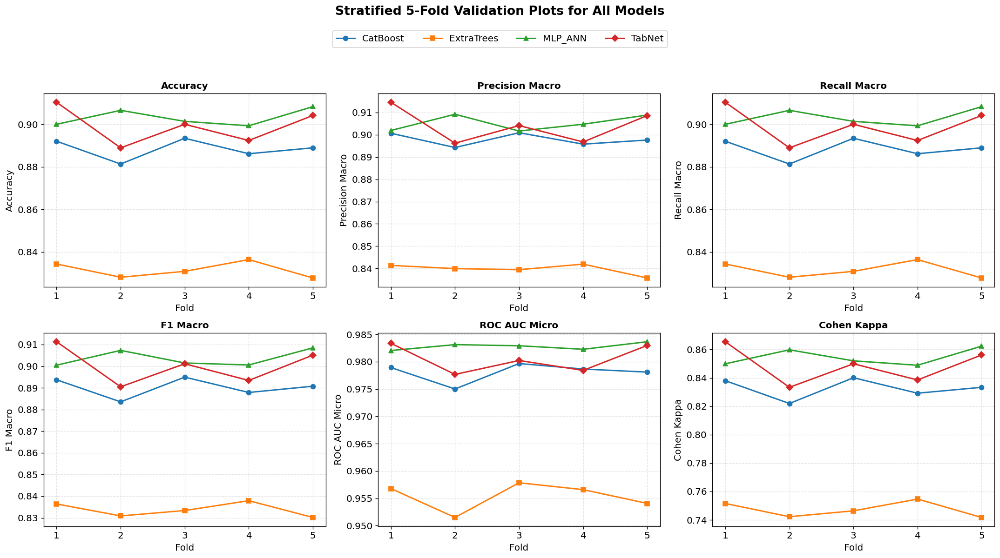

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/Stratified5Fold_TRAINING_ONLY_Verification_Plots_All_Models.png
Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Stratified5Fold_TRAINING_ONLY_Verification_Metrics_ByFold.csv
Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Stratified5Fold_TRAINING_ONLY_Verification_Metrics_Summary.csv
Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Stratified5Fold_TRAINING_ONLY_Verification_PlotData_Long.csv

Cell 10 completed.
5-fold CV source: TRAINING SET ONLY (14,490 observations).
Final held-out test evaluation remains in Cell 9.


In [11]:
# ============================================================
# CELL 10: STRATIFIED 5-FOLD VERIFICATION POINT PLOTS ONLY
# CORRECTED: 5-FOLD CV USES THE 70% TRAINING SUBSET ONLY
# ============================================================

# ============================================================
# STRICT TRAINING-DATA CHECK
# ============================================================

EXPECTED_TRAIN_ROWS_CV = 14490


required_cv_objects = [
    "X_train",
    "y_train",
    "TABLE_DIR",
    "PLOT_DIR",
    "RANDOM_STATE",
    "N_SPLITS",
    "FORCE_REDO_CV"
]


missing_cv_objects = [
    name
    for name in required_cv_objects
    if name not in globals()
]


if missing_cv_objects:

    raise RuntimeError(
        "Missing required objects for Cell 10:\n"
        f"{missing_cv_objects}"
    )


if len(X_train) != EXPECTED_TRAIN_ROWS_CV:

    raise RuntimeError(
        "Training-set size mismatch.\n"
        f"Expected {EXPECTED_TRAIN_ROWS_CV:,} observations, "
        f"but found {len(X_train):,}.\n"
        "Cell 10 must use only the original 70% training subset."
    )


if len(y_train) != EXPECTED_TRAIN_ROWS_CV:

    raise RuntimeError(
        "y_train size mismatch.\n"
        f"Expected {EXPECTED_TRAIN_ROWS_CV:,} observations, "
        f"but found {len(y_train):,}."
    )


print(
    "Starting corrected stratified 5-fold verification..."
)


print(
    "CV data source: TRAINING SET ONLY"
)


print(
    "Training observations available for CV:",
    len(X_train)
)


print(
    "Training target distribution:"
)


print(
    pd.Series(
        np.asarray(
            y_train
        ).reshape(-1)
    )
    .value_counts()
    .sort_index()
)


# ============================================================
# MODEL FITTING FUNCTION FOR EACH CV FOLD
# ============================================================

def fit_model_on_fold(
    model_name,
    X_train_fold,
    y_train_fold,
    X_valid_fold,
    y_valid_fold
):

    if model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",
            eval_metric="TotalF1",
            iterations=700,
            learning_rate=0.03,
            depth=6,
            l2_leaf_reg=3,
            random_seed=RANDOM_STATE,
            verbose=False
        )


        train_pool = Pool(
            prepare_catboost_features(
                X_train_fold
            ),
            y_train_fold,
            cat_features=CATEGORICAL_FEATURES
        )


        valid_pool = Pool(
            prepare_catboost_features(
                X_valid_fold
            ),
            y_valid_fold,
            cat_features=CATEGORICAL_FEATURES
        )


        model.fit(
            train_pool,
            eval_set=valid_pool,
            use_best_model=False,
            verbose=False
        )


        return model


    if model_name == "ExtraTrees":

        model = Pipeline([

            (
                "preprocess",
                make_onehot_only_preprocessor()
            ),

            (
                "model",
                ExtraTreesClassifier(
                    n_estimators=500,
                    max_features="sqrt",
                    min_samples_leaf=1,
                    class_weight="balanced",
                    random_state=RANDOM_STATE,
                    n_jobs=-1
                )
            )
        ])


        model.fit(
            X_train_fold,
            y_train_fold
        )


        return model


    if model_name == "MLP_ANN":

        model = Pipeline([

            (
                "preprocess",
                make_onehot_scaler_preprocessor()
            ),

            (
                "model",
                MLPClassifier(
                    hidden_layer_sizes=(128, 64, 32),
                    activation="relu",
                    solver="adam",
                    alpha=1e-4,
                    learning_rate_init=1e-3,
                    batch_size=256,
                    max_iter=500,
                    early_stopping=True,
                    validation_fraction=0.10,
                    n_iter_no_change=25,
                    random_state=RANDOM_STATE,
                    verbose=False
                )
            )
        ])


        model.fit(
            X_train_fold,
            y_train_fold
        )


        return model


    if model_name == "TabNet":

        preprocessor = (
            make_onehot_scaler_preprocessor()
        )


        model = TabNetClassifier(
            n_d=32,
            n_a=32,
            n_steps=5,
            gamma=1.5,
            lambda_sparse=1e-4,
            optimizer_fn=torch.optim.Adam,
            optimizer_params=dict(
                lr=2e-2
            ),
            scheduler_fn=torch.optim.lr_scheduler.StepLR,
            scheduler_params={
                "step_size": 30,
                "gamma": 0.85
            },
            mask_type="entmax",
            seed=RANDOM_STATE,
            verbose=0
        )


        Xtr = (
            preprocessor
            .fit_transform(
                X_train_fold
            )
            .astype(
                np.float32
            )
        )


        Xva = (
            preprocessor
            .transform(
                X_valid_fold
            )
            .astype(
                np.float32
            )
        )


        model.fit(

            X_train=Xtr,

            y_train=
                y_train_fold.values,

            eval_set=[
                (
                    Xva,
                    y_valid_fold.values
                )
            ],

            eval_name=[
                "valid"
            ],

            eval_metric=[
                "accuracy"
            ],

            max_epochs=120,

            patience=20,

            batch_size=1024,

            virtual_batch_size=128,

            num_workers=0,

            drop_last=False
        )


        return {
            "preprocessor":
                preprocessor,

            "model":
                model
        }


    raise ValueError(
        model_name
    )


# ============================================================
# CORRECTED TRAINING-ONLY 5-FOLD OUTPUT PATHS
# ============================================================

cv_fold_csv = (
    TABLE_DIR /
    "Stratified5Fold_TRAINING_ONLY_Verification_Metrics_ByFold.csv"
)


cv_summary_csv = (
    TABLE_DIR /
    "Stratified5Fold_TRAINING_ONLY_Verification_Metrics_Summary.csv"
)


# ============================================================
# RUN OR LOAD CORRECTED TRAINING-ONLY 5-FOLD CV
# ============================================================

if (
    cv_fold_csv.exists()
    and cv_summary_csv.exists()
    and not FORCE_REDO_CV
):

    cv_fold_df = pd.read_csv(
        cv_fold_csv
    )


    cv_summary_df = pd.read_csv(
        cv_summary_csv
    )


    print(
        "Loaded existing corrected "
        "TRAINING-ONLY 5-fold verification tables."
    )


else:

    skf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE
    )


    fold_rows = []


    start_cv = time.time()


    for model_name in [
        "CatBoost",
        "ExtraTrees",
        "MLP_ANN",
        "TabNet"
    ]:

        print(
            "\nRunning Stratified 5-Fold Verification for:",
            model_name
        )


        print(
            "  Data source: X_train / y_train only"
        )


        fold_no = 1


        # ====================================================
        # CRITICAL CORRECTION:
        # OLD:
        #     skf.split(X, y)
        #
        # CORRECT:
        #     skf.split(X_train, y_train)
        #
        # Therefore validation and test observations are NOT
        # included in the 5-fold cross-validation.
        # ====================================================

        for train_i, valid_i in skf.split(
            X_train,
            y_train
        ):

            print(
                f"  Fold {fold_no}/{N_SPLITS}"
            )


            Xtr = (
                X_train
                .iloc[
                    train_i
                ]
                .copy()
            )


            ytr = (
                y_train
                .iloc[
                    train_i
                ]
                .copy()
            )


            Xva = (
                X_train
                .iloc[
                    valid_i
                ]
                .copy()
            )


            yva = (
                y_train
                .iloc[
                    valid_i
                ]
                .copy()
            )


            print(
                "    Fold training rows:",
                len(Xtr),
                "| Fold validation rows:",
                len(Xva)
            )


            fold_model = fit_model_on_fold(
                model_name,
                Xtr,
                ytr,
                Xva,
                yva
            )


            y_pred, y_prob = predict_model(
                model_name,
                fold_model,
                Xva
            )


            yva_bin = label_binarize(
                yva.values,
                classes=CLASS_ORDER
            )


            fold_rows.append({

                "Model":
                    model_name,

                "Fold":
                    fold_no,

                "Accuracy":
                    accuracy_score(
                        yva,
                        y_pred
                    ),

                "Precision_Macro":
                    precision_score(
                        yva,
                        y_pred,
                        average="macro",
                        zero_division=0
                    ),

                "Recall_Macro":
                    recall_score(
                        yva,
                        y_pred,
                        average="macro",
                        zero_division=0
                    ),

                "F1_Macro":
                    f1_score(
                        yva,
                        y_pred,
                        average="macro",
                        zero_division=0
                    ),

                "Precision_Weighted":
                    precision_score(
                        yva,
                        y_pred,
                        average="weighted",
                        zero_division=0
                    ),

                "Recall_Weighted":
                    recall_score(
                        yva,
                        y_pred,
                        average="weighted",
                        zero_division=0
                    ),

                "F1_Weighted":
                    f1_score(
                        yva,
                        y_pred,
                        average="weighted",
                        zero_division=0
                    ),

                "Cohen_Kappa":
                    cohen_kappa_score(
                        yva,
                        y_pred
                    ),

                "MCC":
                    matthews_corrcoef(
                        yva,
                        y_pred
                    ),

                "ROC_AUC_Micro":
                    roc_auc_score(
                        yva_bin,
                        y_prob,
                        multi_class="ovr",
                        average="micro"
                    )
            })


            fold_no += 1


    cv_fold_df = (

        pd.DataFrame(
            fold_rows
        )

        .sort_values(
            [
                "Model",
                "Fold"
            ]
        )

        .reset_index(
            drop=True
        )
    )


    cv_fold_df.to_csv(
        cv_fold_csv,
        index=False
    )


    summary_cols = [
        "Accuracy",
        "Precision_Macro",
        "Recall_Macro",
        "F1_Macro",
        "Precision_Weighted",
        "Recall_Weighted",
        "F1_Weighted",
        "Cohen_Kappa",
        "MCC",
        "ROC_AUC_Micro"
    ]


    cv_summary_df = (

        cv_fold_df

        .groupby(
            "Model"
        )[
            summary_cols
        ]

        .agg(
            [
                "mean",
                "std"
            ]
        )
    )


    cv_summary_df.columns = [
        f"{a}_{b}"
        for a, b
        in cv_summary_df.columns
    ]


    cv_summary_df = (
        cv_summary_df
        .reset_index()
    )


    cv_summary_df.to_csv(
        cv_summary_csv,
        index=False
    )


    print(
        "5-fold verification completed in minutes:",
        round(
            (
                time.time()
                -
                start_cv
            )
            /
            60,
            2
        )
    )


# ============================================================
# DISPLAY CORRECTED 5-FOLD TABLES
# ============================================================

display(
    cv_fold_df
)


display(
    cv_summary_df
)


# ============================================================
# LONG-FORM PLOT DATA
# ============================================================

metrics_to_plot = [
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "ROC_AUC_Micro",
    "Cohen_Kappa"
]


long_rows = []


for metric in metrics_to_plot:

    tmp = cv_fold_df[
        [
            "Model",
            "Fold",
            metric
        ]
    ].copy()


    tmp[
        "Metric"
    ] = metric


    tmp = tmp.rename(
        columns={
            metric:
                "Value"
        }
    )


    long_rows.append(
        tmp
    )


cv_plot_long_df = pd.concat(
    long_rows,
    ignore_index=True
)


cv_plot_long_csv = (
    TABLE_DIR /
    "Stratified5Fold_TRAINING_ONLY_Verification_PlotData_Long.csv"
)


cv_plot_long_df.to_csv(
    cv_plot_long_csv,
    index=False
)


# ============================================================
# ONE COMBINED POINT PLOT
# SAME 6-PANEL FIGURE DESIGN AS THE ORIGINAL CELL
# ============================================================

model_order = [
    "CatBoost",
    "ExtraTrees",
    "MLP_ANN",
    "TabNet"
]


marker_map = {
    "CatBoost":
        "o",

    "ExtraTrees":
        "s",

    "MLP_ANN":
        "^",

    "TabNet":
        "D"
}


# Font settings
MAIN_TITLE_FONT_SIZE = 16
ALL_OTHER_FONT_SIZE = 12


fig, axes = plt.subplots(
    2,
    3,
    figsize=(
        18,
        10
    )
)


axes = axes.flatten()


for ax, metric in zip(
    axes,
    metrics_to_plot
):

    for model_name in model_order:

        tmp = (

            cv_fold_df[
                cv_fold_df[
                    "Model"
                ]
                ==
                model_name
            ]

            .sort_values(
                "Fold"
            )
        )


        ax.plot(

            tmp[
                "Fold"
            ],

            tmp[
                metric
            ],

            marker=
                marker_map[
                    model_name
                ],

            linewidth=1.8,

            markersize=6,

            label=
                model_name
        )


    ax.set_title(

        metric.replace(
            "_",
            " "
        ),

        fontsize=
            ALL_OTHER_FONT_SIZE,

        fontweight=
            "bold"
    )


    ax.set_xlabel(
        "Fold",
        fontsize=
            ALL_OTHER_FONT_SIZE
    )


    ax.set_ylabel(

        metric.replace(
            "_",
            " "
        ),

        fontsize=
            ALL_OTHER_FONT_SIZE
    )


    ax.set_xticks(
        range(
            1,
            N_SPLITS + 1
        )
    )


    ax.tick_params(
        axis="both",
        labelsize=
            ALL_OTHER_FONT_SIZE
    )


    ax.grid(
        True,
        linestyle="--",
        alpha=0.35
    )


handles, labels = (
    axes[
        0
    ]
    .get_legend_handles_labels()
)


fig.suptitle(

    "Stratified 5-Fold Validation Plots for All Models",

    fontsize=
        MAIN_TITLE_FONT_SIZE,

    fontweight=
        "bold",

    y=0.995
)


fig.legend(

    handles,

    labels,

    loc=
        "upper center",

    bbox_to_anchor=(
        0.5,
        0.958
    ),

    ncol=4,

    frameon=True,

    fontsize=
        ALL_OTHER_FONT_SIZE
)


fig.tight_layout(
    rect=[
        0,
        0,
        1,
        0.91
    ]
)


pointplot_png = (
    PLOT_DIR /
    "Stratified5Fold_TRAINING_ONLY_Verification_Plots_All_Models.png"
)


fig.savefig(
    pointplot_png,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


plt.close(
    fig
)


print(
    "Saved:",
    pointplot_png
)


print(
    "Saved:",
    cv_fold_csv
)


print(
    "Saved:",
    cv_summary_csv
)


print(
    "Saved:",
    cv_plot_long_csv
)


print(
    "\nCell 10 completed."
)


print(
    "5-fold CV source: TRAINING SET ONLY "
    f"({len(X_train):,} observations)."
)


print(
    "Final held-out test evaluation remains in Cell 9."
)


## Cell 11 - Model-level explainability for all 10 predictors

Starting model-level explainability for all 10 predictors...
SHAP explanation source: TEST SET ONLY
Available test observations: 3105
Selected SHAP explanation observations: 1500
SHAP explanation target distribution:
Target
0    500
1    500
2    500
Name: count, dtype: int64
SHAP background source: TRAINING SET ONLY
Lithology explainability sample unique classes: [1, 3, 4, 7, 8, 10, 11, 12, 13, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
LULC explainability sample unique classes: [0, 1, 2, 3, 4]
Explainability sample size: 1500
Background size: 100
Predictors used: ['Lithology', 'Lineament_Density', 'Drainage_Density', 'TRI', 'TWI', 'STI', 'BSI', 'NBR', 'MNDWI', 'LULC']

Explaining model: CatBoost


,Model,Feature,Permutation_Importance_Mean,Permutation_Importance_Std
0,CatBoost,BSI,0.447343,0.008306
1,CatBoost,MNDWI,0.257842,0.007028
2,CatBoost,STI,0.236135,0.003038
3,CatBoost,NBR,0.061256,0.003217
4,CatBoost,TRI,0.030982,0.002051
5,CatBoost,TWI,0.017456,0.001402
6,CatBoost,LULC,0.008631,0.001849
7,CatBoost,Lithology,0.007923,0.000663
8,CatBoost,Lineament_Density,0.002834,0.001570
9,CatBoost,Drainage_Density,0.000322,0.000955


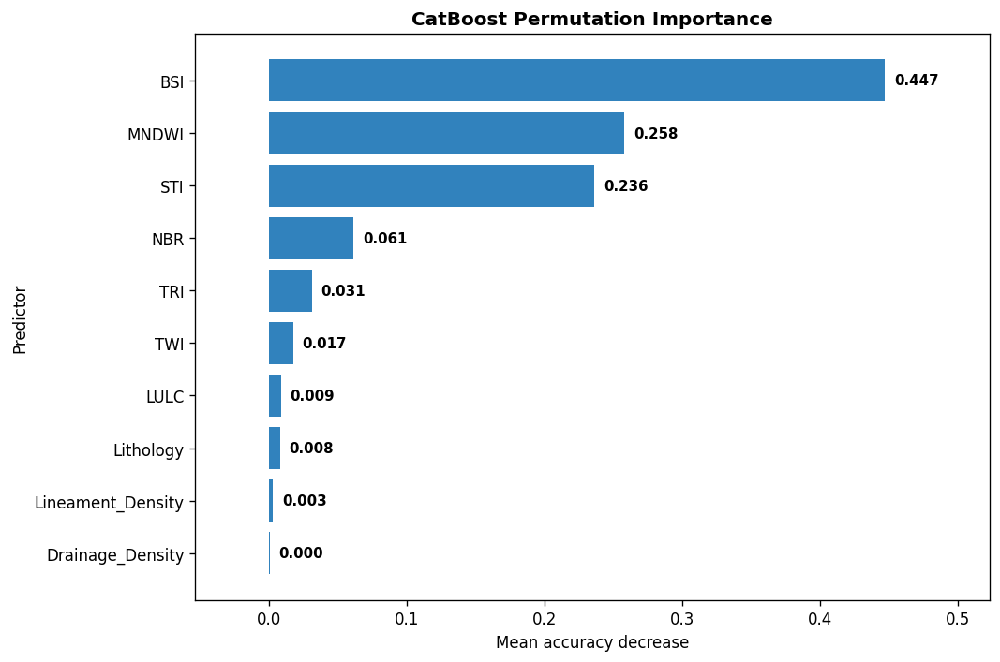

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_Permutation_Importance_All10Predictors.png


,Model,Feature,MeanAbsSHAP_ModelLevel_SusceptibilityScore
6,CatBoost,BSI,0.265423
8,CatBoost,MNDWI,0.134462
5,CatBoost,STI,0.115947
3,CatBoost,TRI,0.028024
7,CatBoost,NBR,0.025378
9,CatBoost,LULC,0.014133
4,CatBoost,TWI,0.013598
0,CatBoost,Lithology,0.013285
2,CatBoost,Drainage_Density,0.006477
1,CatBoost,Lineament_Density,0.005211


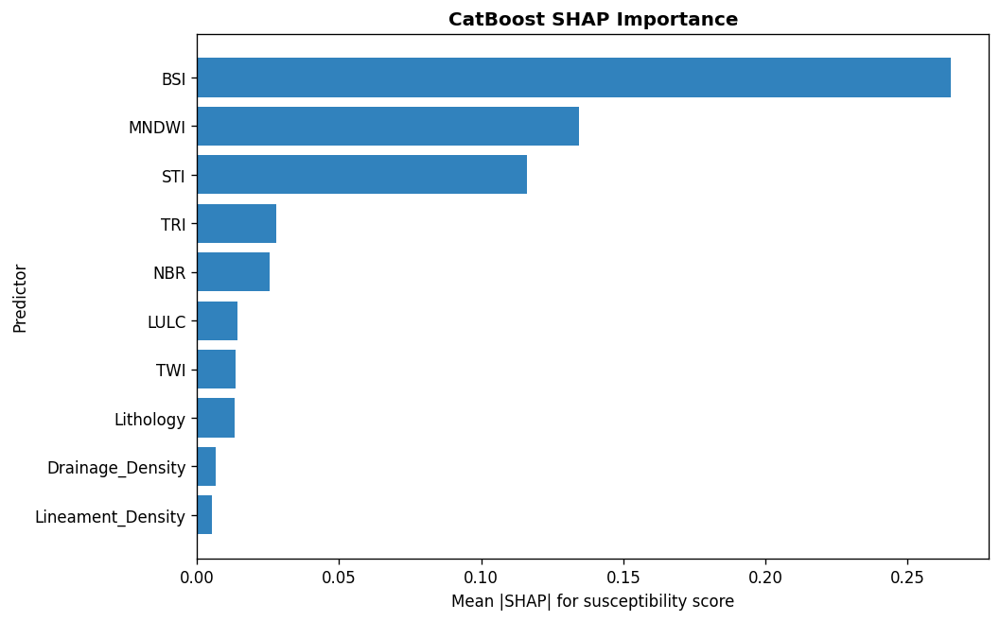

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_SHAP_Bar_ModelLevel_All10Predictors.png


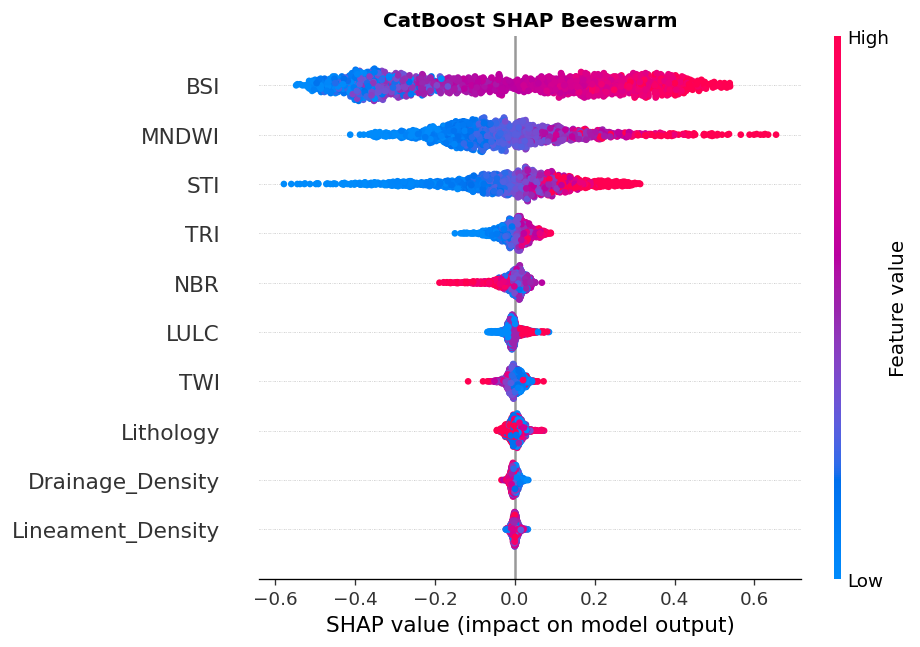

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_SHAP_Beeswarm_ModelLevel_All10Predictors.png


<Figure size 840x600 with 0 Axes>

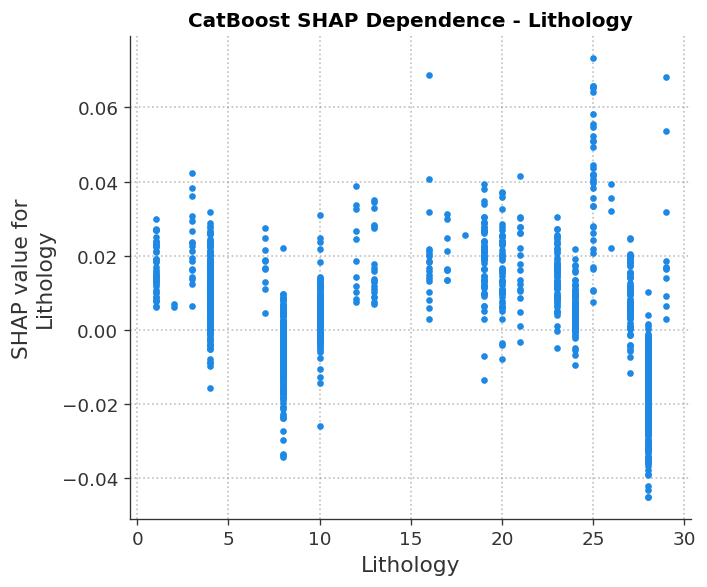

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_SHAP_Dependence_Lithology.png


<Figure size 840x600 with 0 Axes>

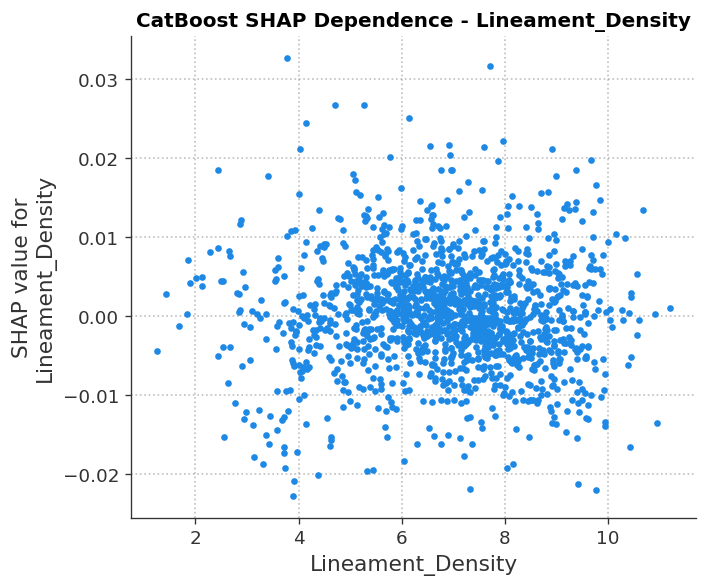

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_SHAP_Dependence_Lineament_Density.png


<Figure size 840x600 with 0 Axes>

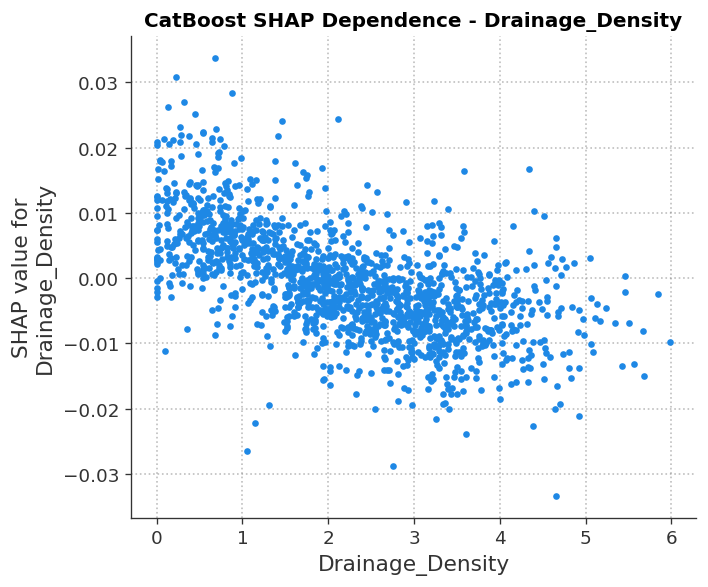

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_SHAP_Dependence_Drainage_Density.png


<Figure size 840x600 with 0 Axes>

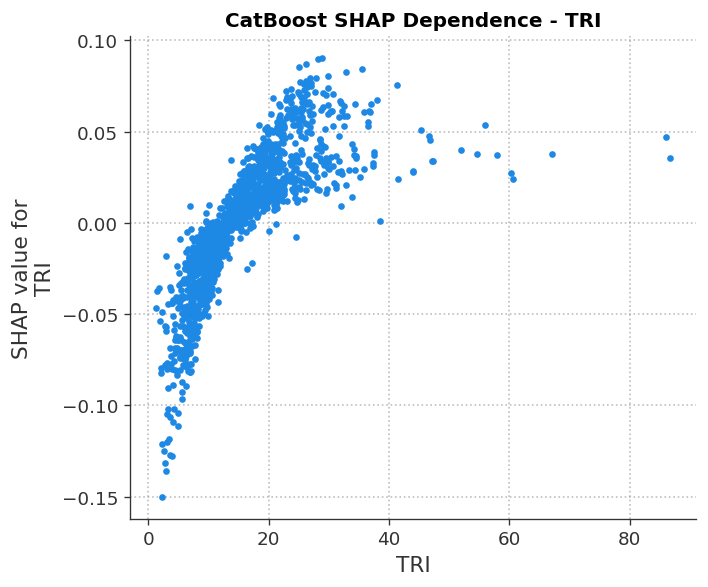

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_SHAP_Dependence_TRI.png


<Figure size 840x600 with 0 Axes>

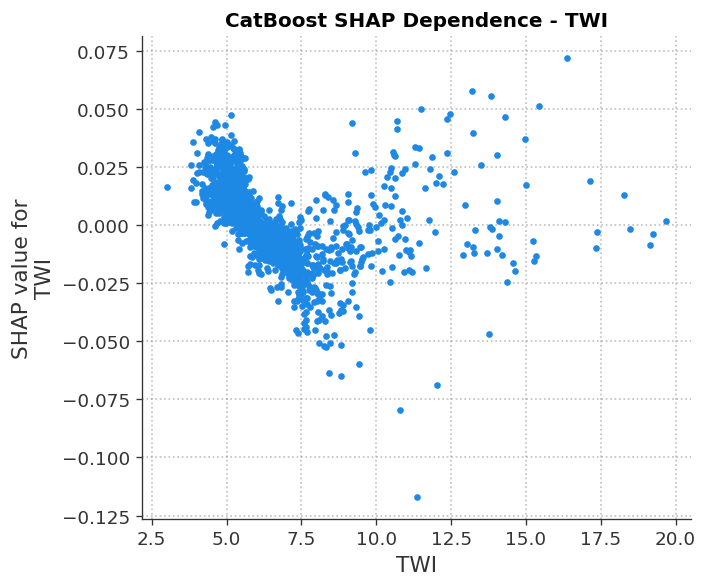

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_SHAP_Dependence_TWI.png


<Figure size 840x600 with 0 Axes>

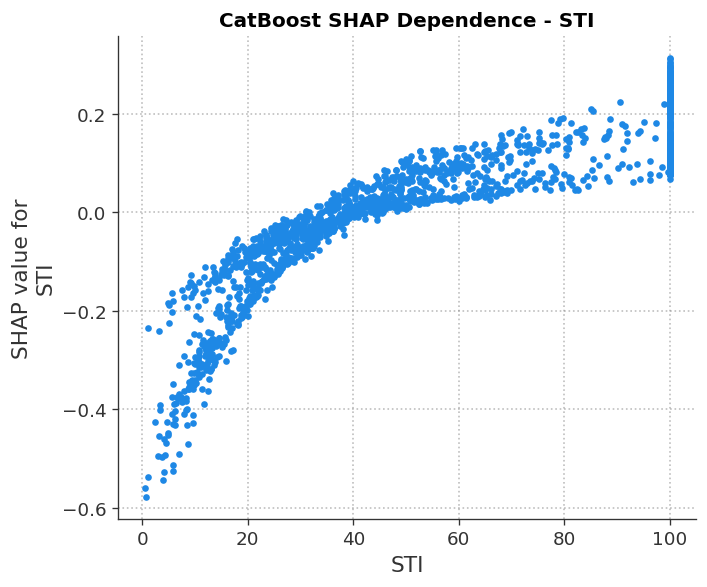

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_SHAP_Dependence_STI.png


<Figure size 840x600 with 0 Axes>

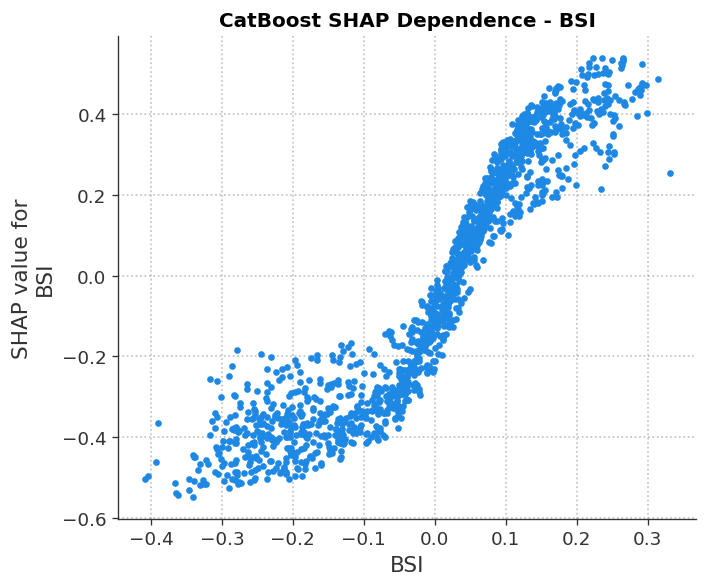

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_SHAP_Dependence_BSI.png


<Figure size 840x600 with 0 Axes>

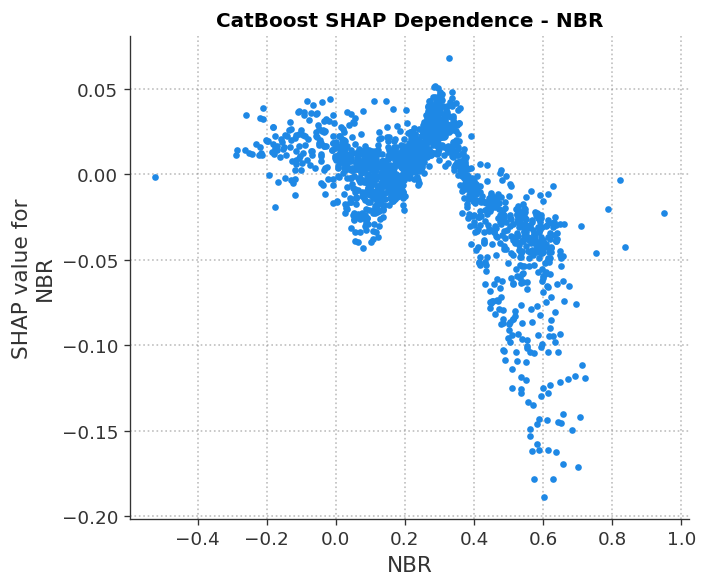

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_SHAP_Dependence_NBR.png


<Figure size 840x600 with 0 Axes>

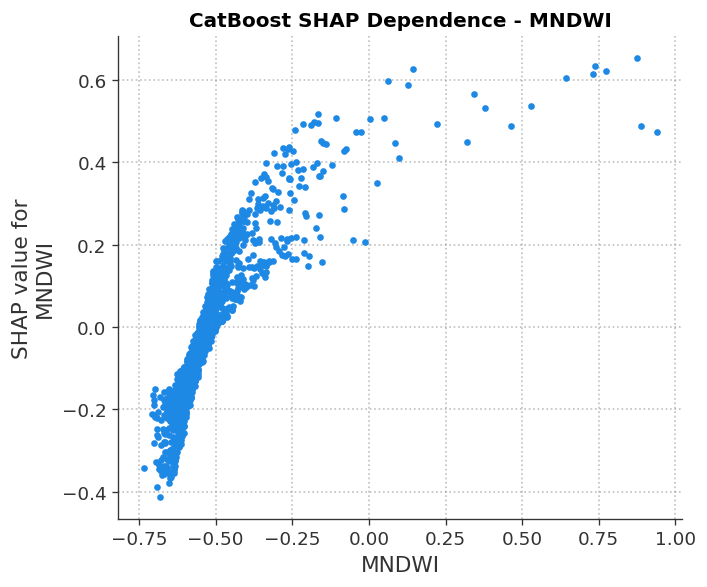

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_SHAP_Dependence_MNDWI.png


<Figure size 840x600 with 0 Axes>

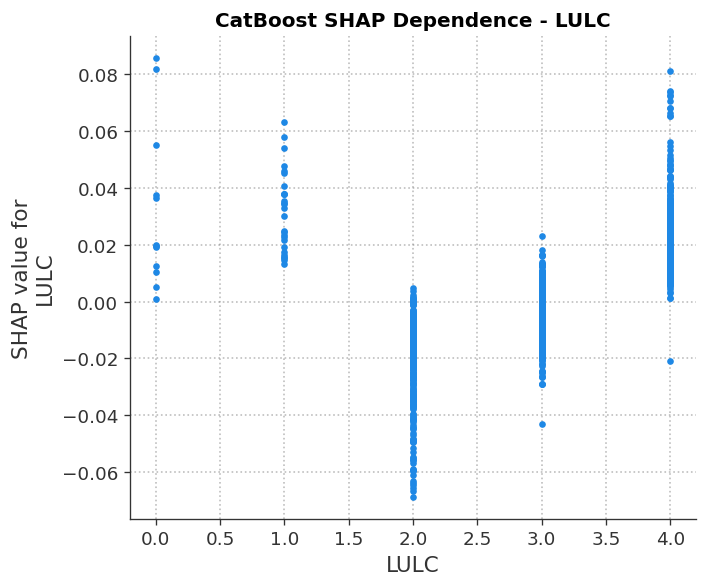

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_SHAP_Dependence_LULC.png

Explaining model: ExtraTrees


,Model,Feature,Permutation_Importance_Mean,Permutation_Importance_Std
0,ExtraTrees,BSI,0.163736,0.007787
1,ExtraTrees,NBR,0.163092,0.005395
2,ExtraTrees,STI,0.157166,0.002608
3,ExtraTrees,MNDWI,0.114911,0.003686
4,ExtraTrees,LULC,0.075427,0.004700
5,ExtraTrees,TRI,0.028599,0.003606
6,ExtraTrees,Lithology,0.020676,0.002728
7,ExtraTrees,TWI,0.003607,0.002159
8,ExtraTrees,Lineament_Density,-0.000322,0.001996
9,ExtraTrees,Drainage_Density,-0.001417,0.003053


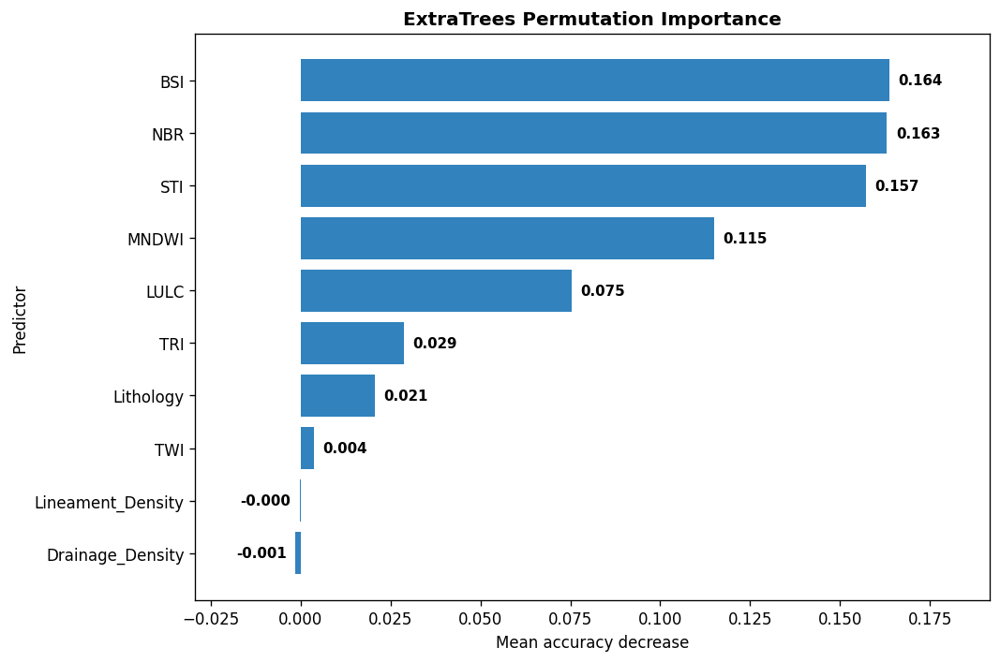

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_Permutation_Importance_All10Predictors.png


,Model,Feature,MeanAbsSHAP_ModelLevel_SusceptibilityScore
7,ExtraTrees,NBR,0.113335
6,ExtraTrees,BSI,0.111820
5,ExtraTrees,STI,0.085683
9,ExtraTrees,LULC,0.062812
8,ExtraTrees,MNDWI,0.059095
0,ExtraTrees,Lithology,0.031743
3,ExtraTrees,TRI,0.029232
4,ExtraTrees,TWI,0.013291
1,ExtraTrees,Lineament_Density,0.010446
2,ExtraTrees,Drainage_Density,0.010134


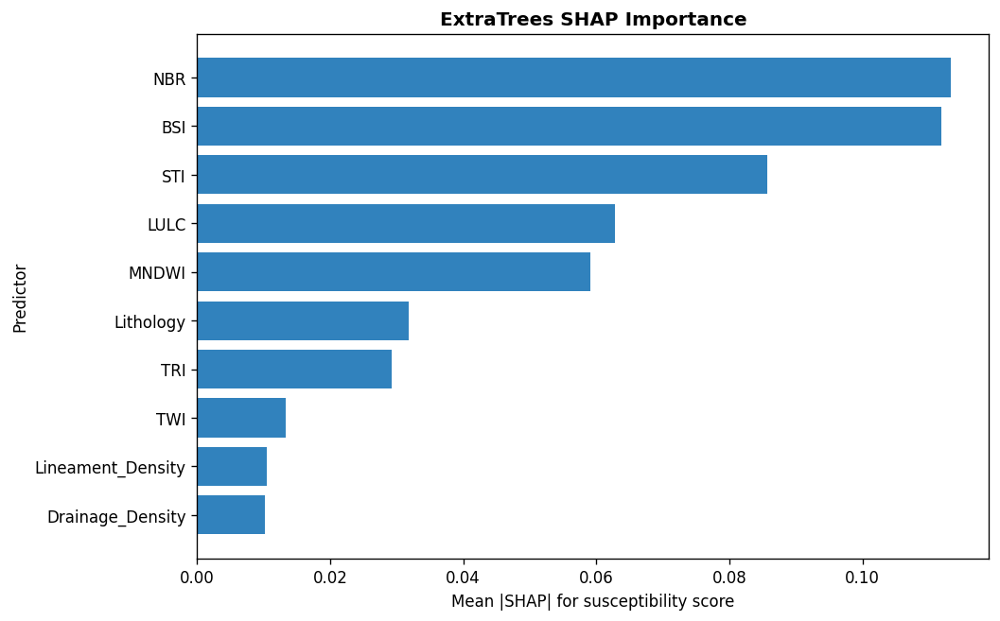

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_SHAP_Bar_ModelLevel_All10Predictors.png


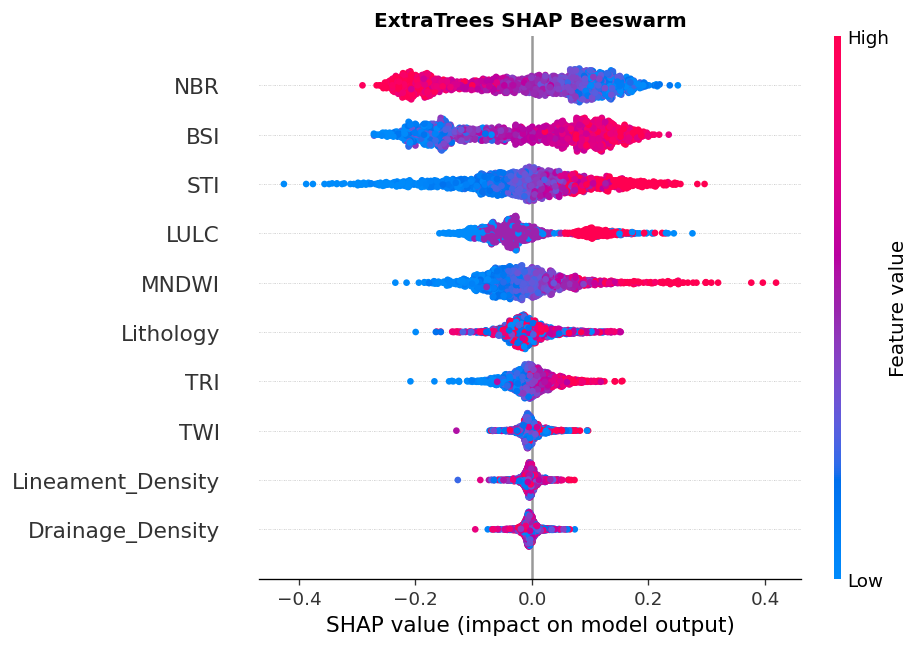

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_SHAP_Beeswarm_ModelLevel_All10Predictors.png


<Figure size 840x600 with 0 Axes>

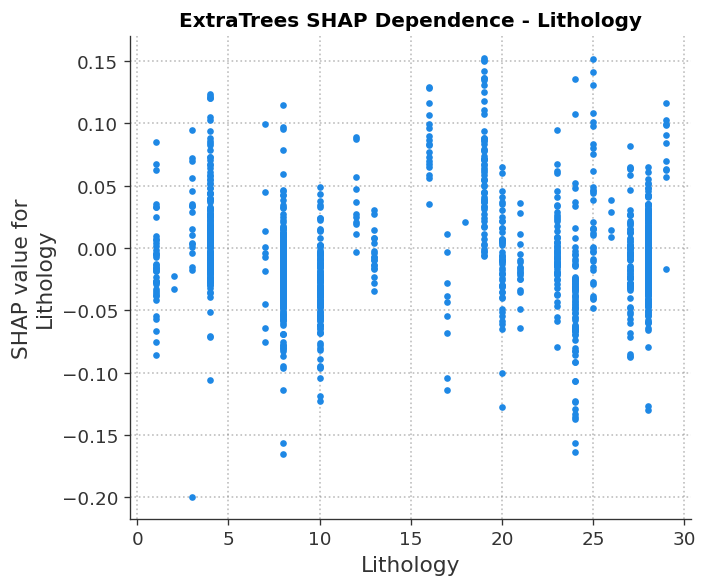

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_SHAP_Dependence_Lithology.png


<Figure size 840x600 with 0 Axes>

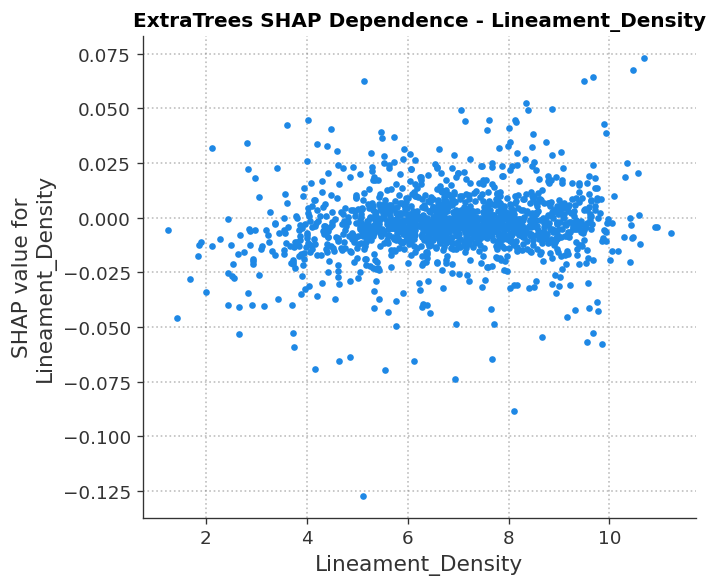

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_SHAP_Dependence_Lineament_Density.png


<Figure size 840x600 with 0 Axes>

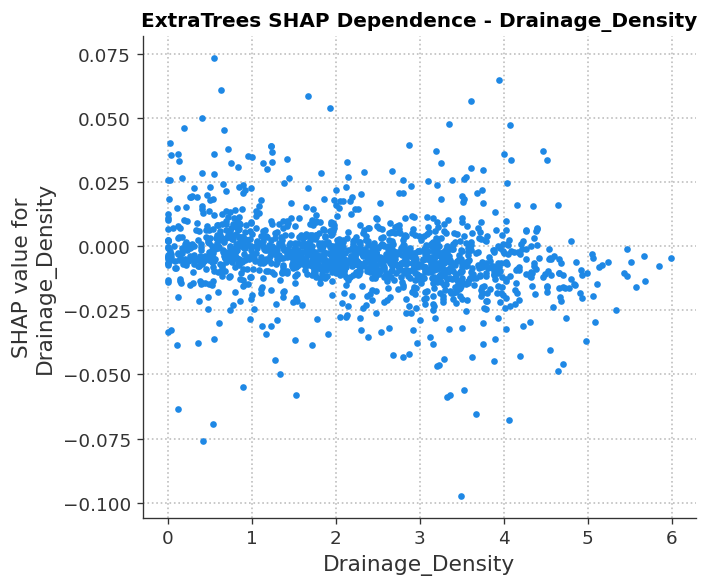

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_SHAP_Dependence_Drainage_Density.png


<Figure size 840x600 with 0 Axes>

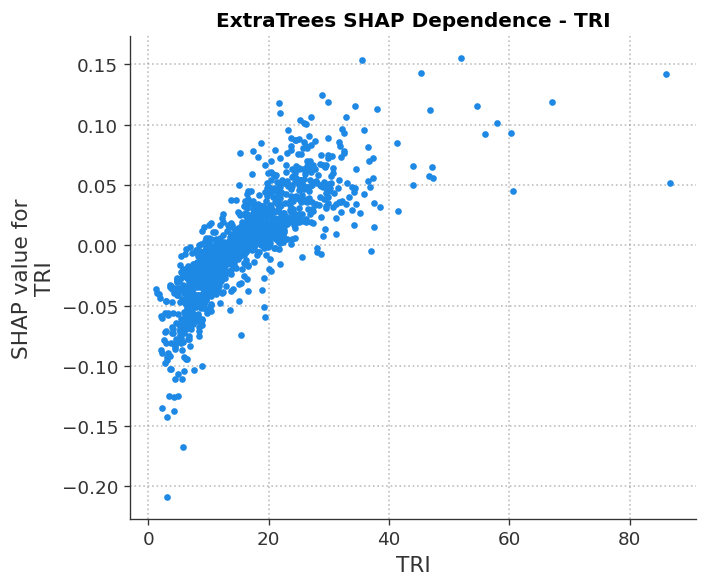

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_SHAP_Dependence_TRI.png


<Figure size 840x600 with 0 Axes>

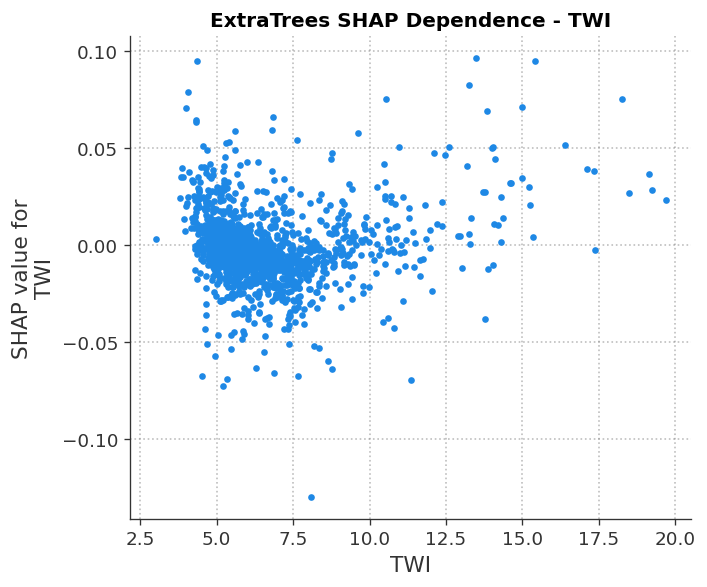

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_SHAP_Dependence_TWI.png


<Figure size 840x600 with 0 Axes>

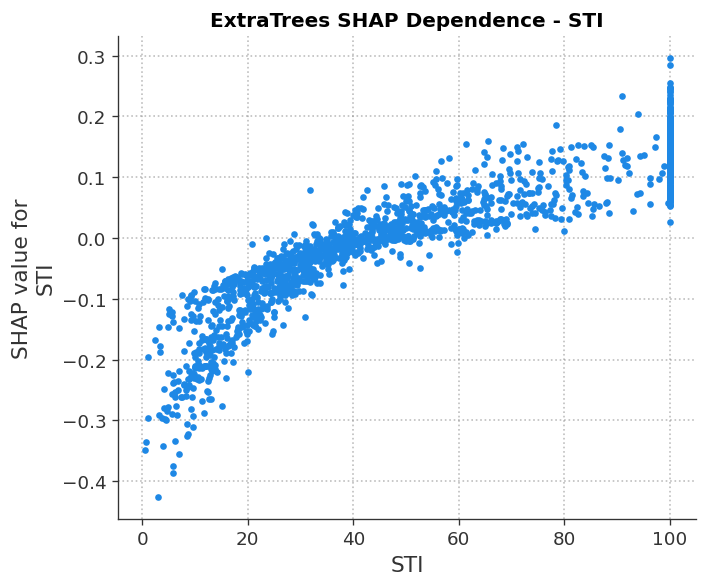

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_SHAP_Dependence_STI.png


<Figure size 840x600 with 0 Axes>

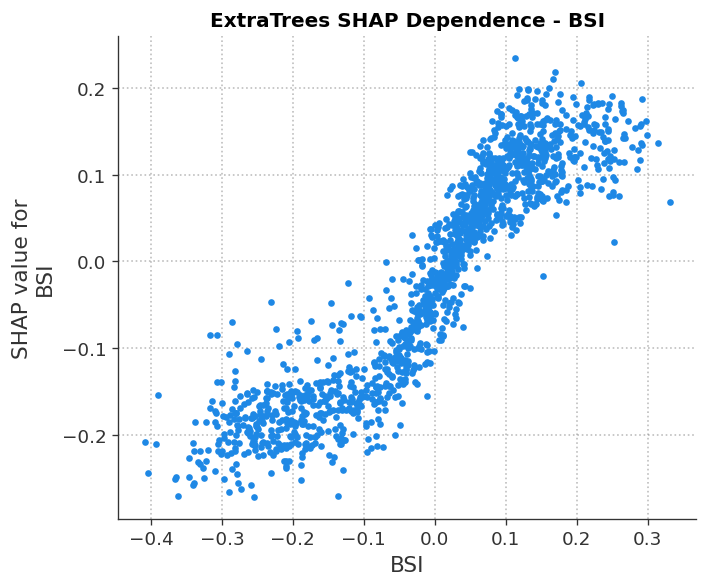

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_SHAP_Dependence_BSI.png


<Figure size 840x600 with 0 Axes>

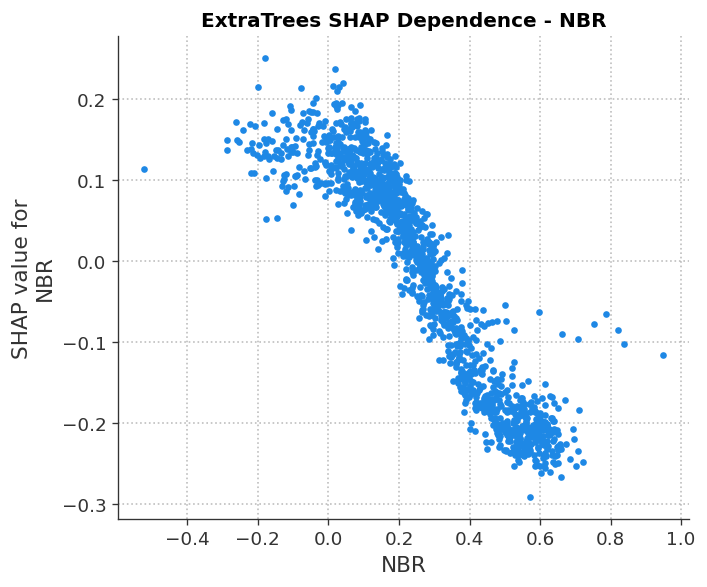

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_SHAP_Dependence_NBR.png


<Figure size 840x600 with 0 Axes>

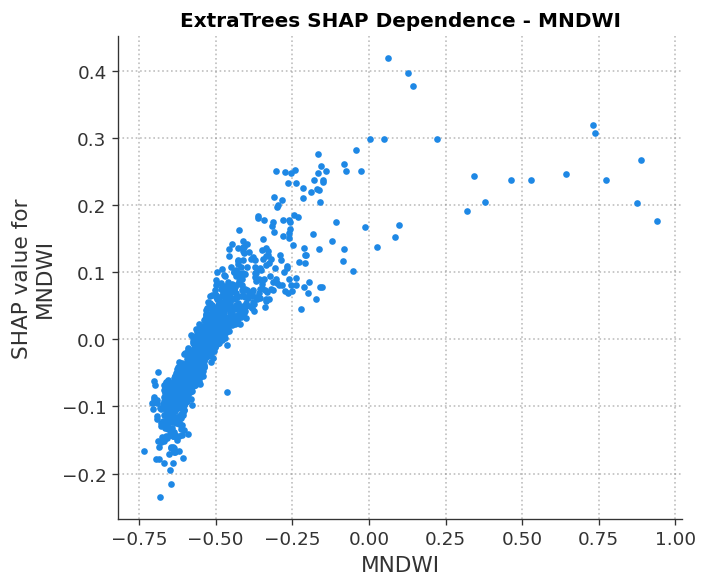

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_SHAP_Dependence_MNDWI.png


<Figure size 840x600 with 0 Axes>

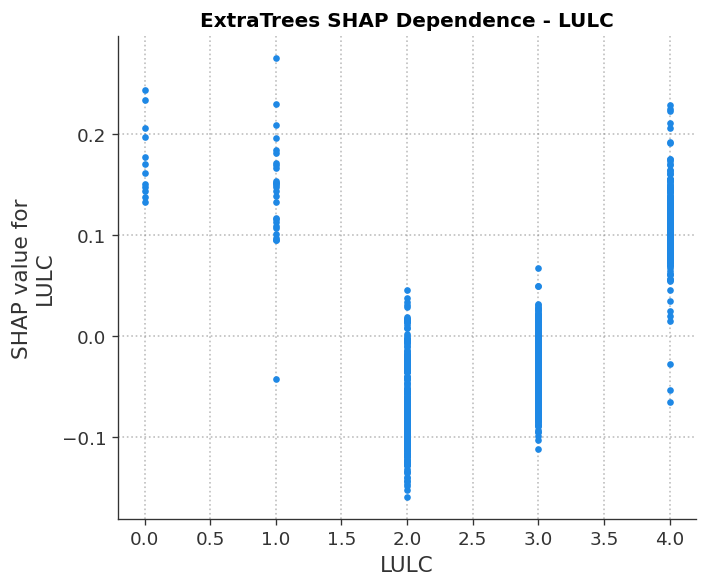

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_SHAP_Dependence_LULC.png

Explaining model: MLP_ANN


,Model,Feature,Permutation_Importance_Mean,Permutation_Importance_Std
0,MLP_ANN,BSI,0.547246,0.007908
1,MLP_ANN,MNDWI,0.301900,0.005899
2,MLP_ANN,STI,0.277359,0.002150
3,MLP_ANN,NBR,0.118583,0.006358
4,MLP_ANN,TWI,0.073816,0.004076
5,MLP_ANN,Lithology,0.016296,0.001747
6,MLP_ANN,TRI,0.015072,0.002353
7,MLP_ANN,Lineament_Density,0.004380,0.002113
8,MLP_ANN,LULC,0.004122,0.001195
9,MLP_ANN,Drainage_Density,0.000064,0.002588


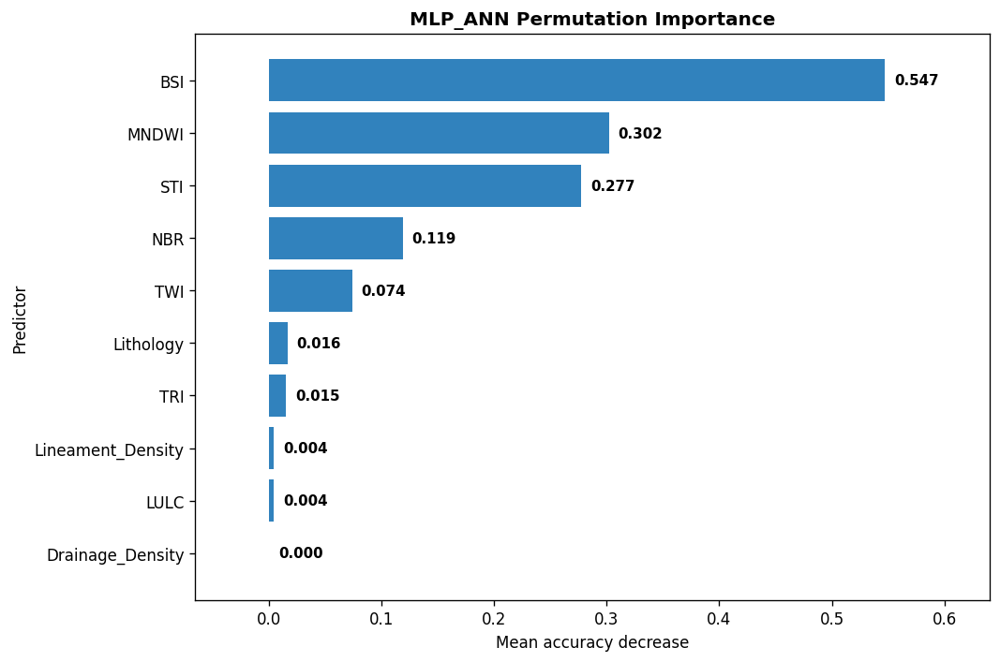

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_Permutation_Importance_All10Predictors.png


,Model,Feature,MeanAbsSHAP_ModelLevel_SusceptibilityScore
6,MLP_ANN,BSI,0.322317
8,MLP_ANN,MNDWI,0.139077
5,MLP_ANN,STI,0.131473
7,MLP_ANN,NBR,0.047289
4,MLP_ANN,TWI,0.034578
0,MLP_ANN,Lithology,0.019090
3,MLP_ANN,TRI,0.013470
9,MLP_ANN,LULC,0.011879
1,MLP_ANN,Lineament_Density,0.008797
2,MLP_ANN,Drainage_Density,0.008183


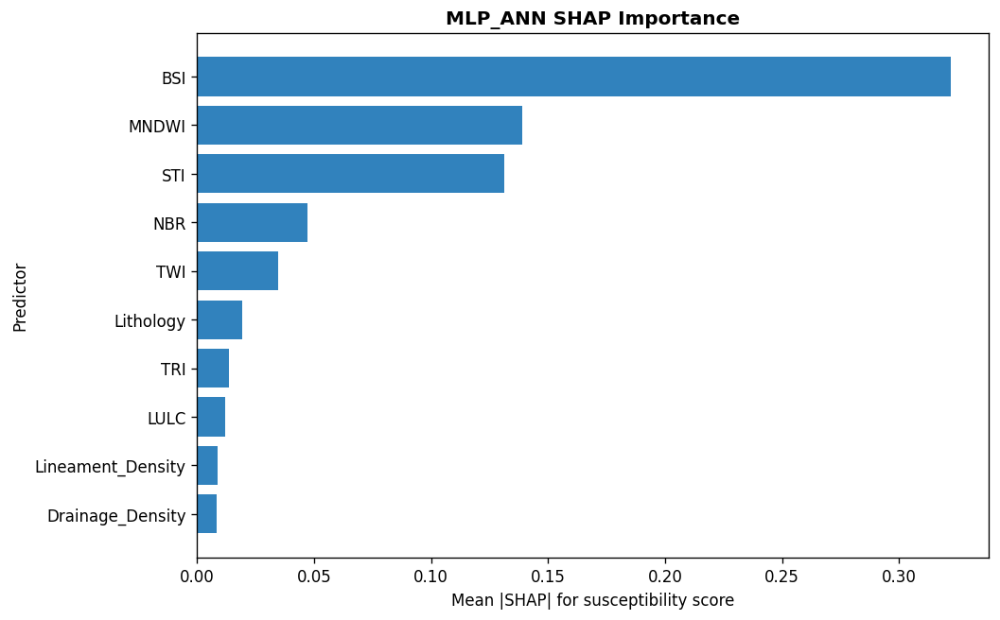

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_SHAP_Bar_ModelLevel_All10Predictors.png


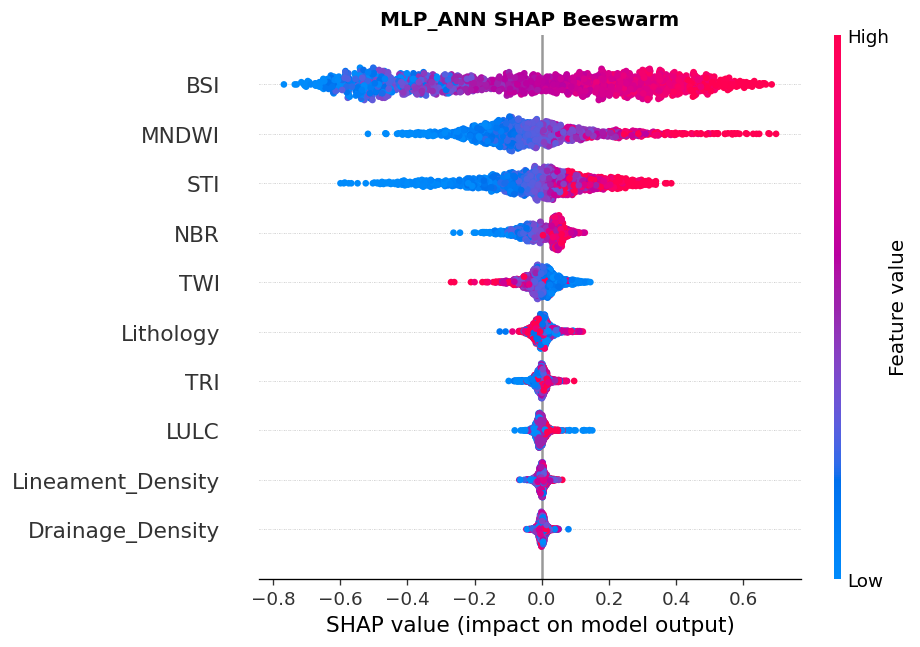

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_SHAP_Beeswarm_ModelLevel_All10Predictors.png


<Figure size 840x600 with 0 Axes>

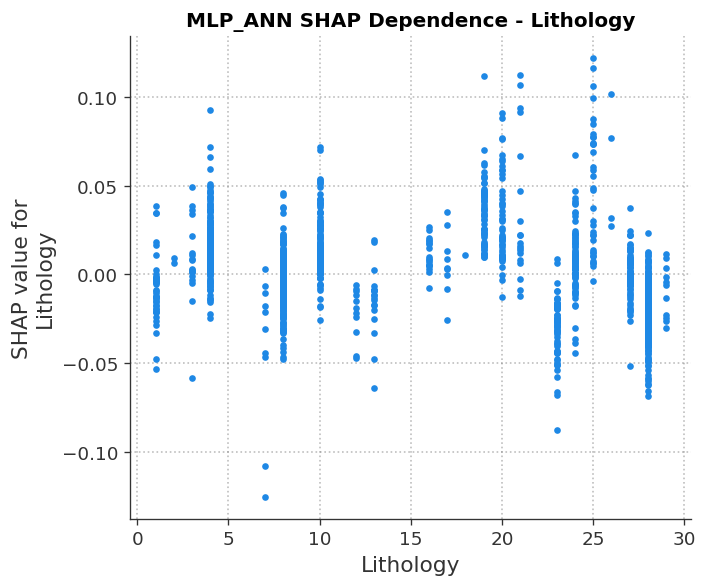

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_SHAP_Dependence_Lithology.png


<Figure size 840x600 with 0 Axes>

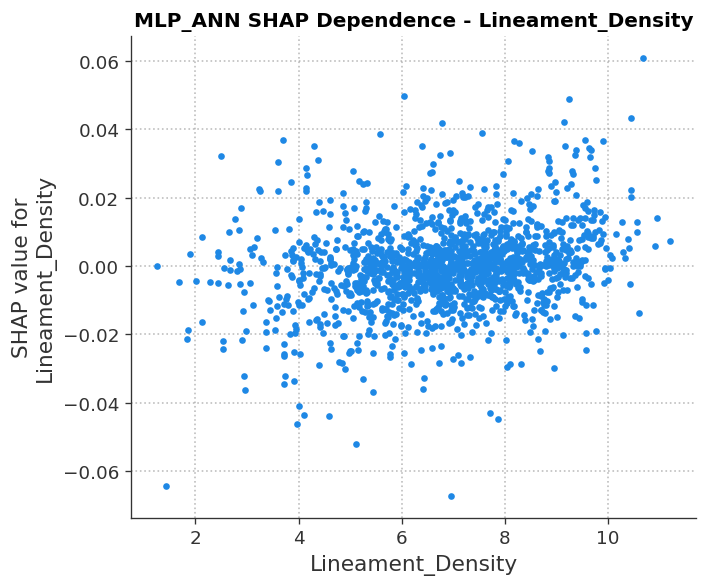

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_SHAP_Dependence_Lineament_Density.png


<Figure size 840x600 with 0 Axes>

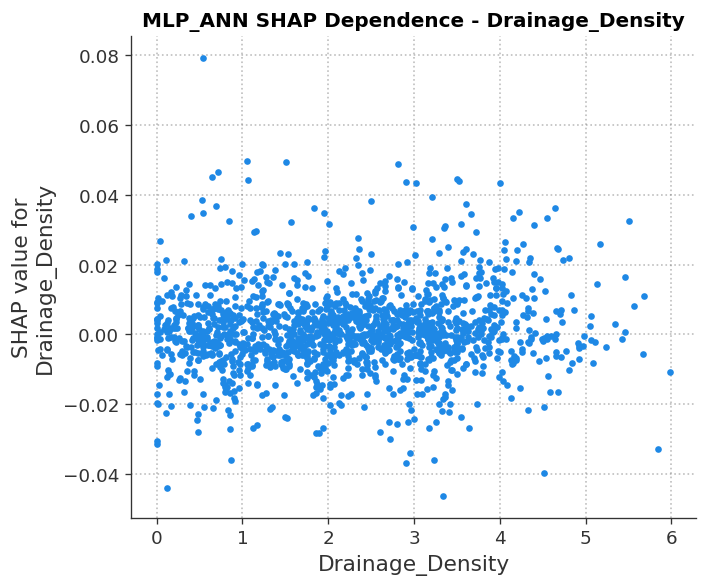

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_SHAP_Dependence_Drainage_Density.png


<Figure size 840x600 with 0 Axes>

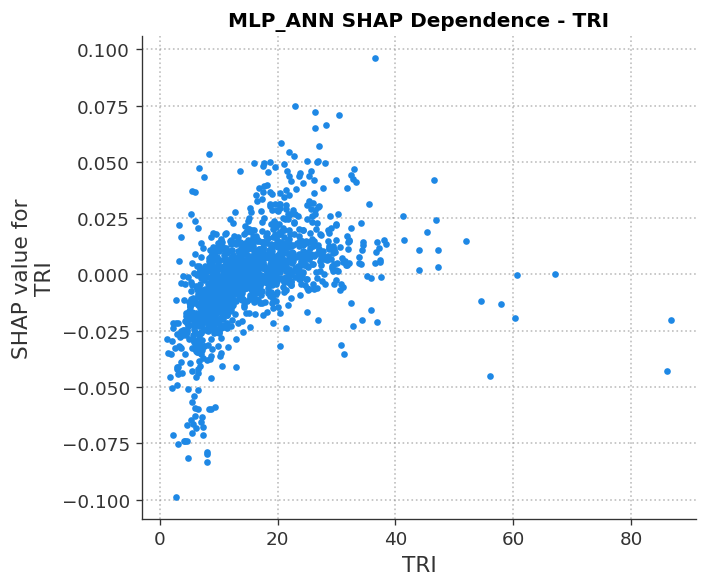

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_SHAP_Dependence_TRI.png


<Figure size 840x600 with 0 Axes>

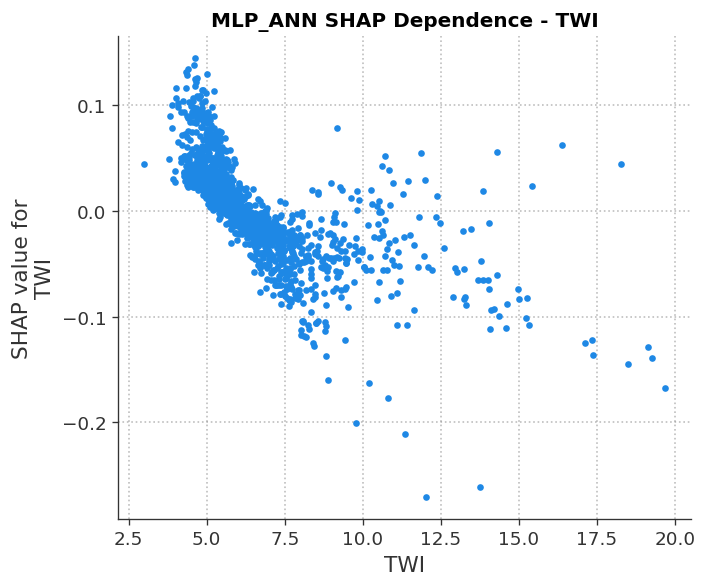

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_SHAP_Dependence_TWI.png


<Figure size 840x600 with 0 Axes>

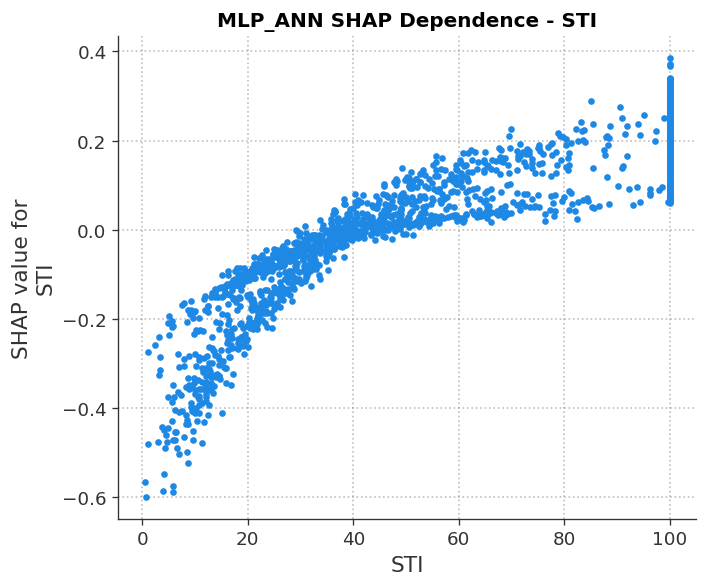

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_SHAP_Dependence_STI.png


<Figure size 840x600 with 0 Axes>

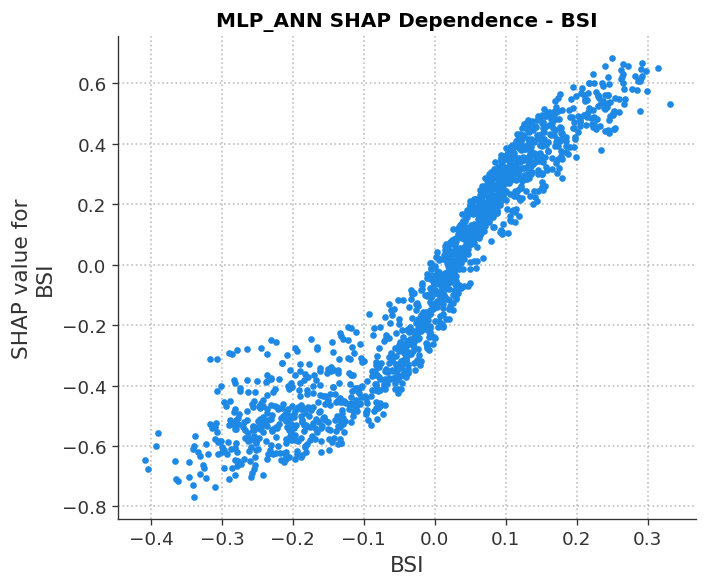

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_SHAP_Dependence_BSI.png


<Figure size 840x600 with 0 Axes>

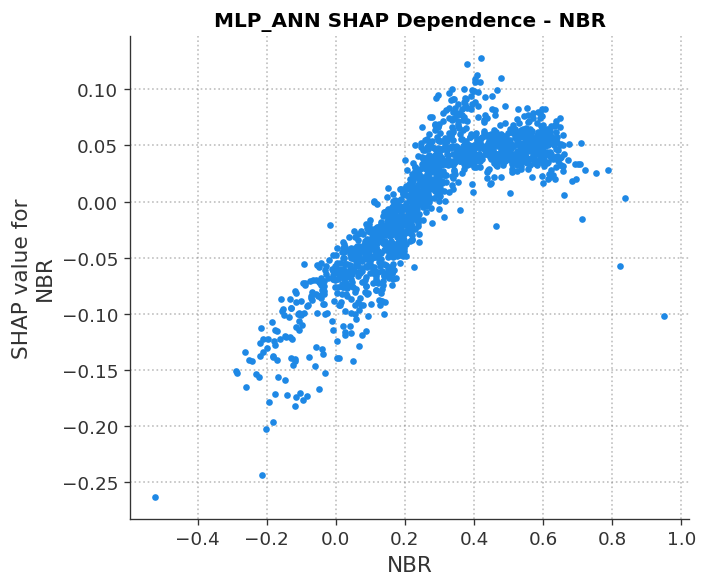

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_SHAP_Dependence_NBR.png


<Figure size 840x600 with 0 Axes>

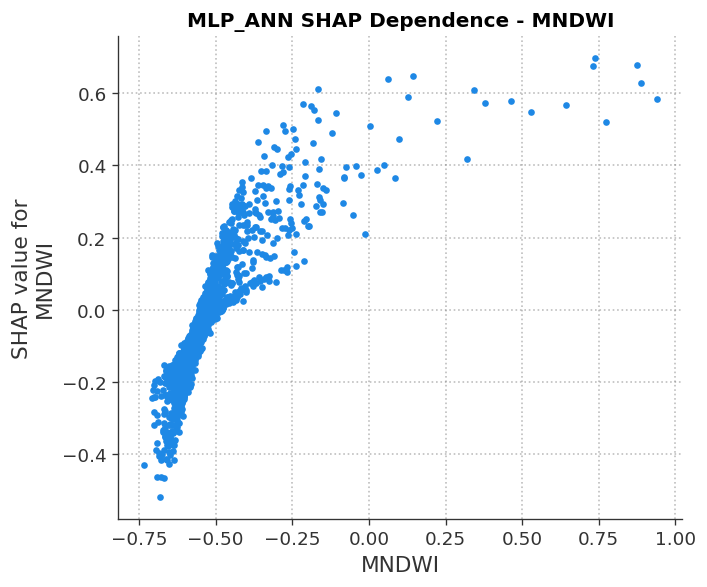

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_SHAP_Dependence_MNDWI.png


<Figure size 840x600 with 0 Axes>

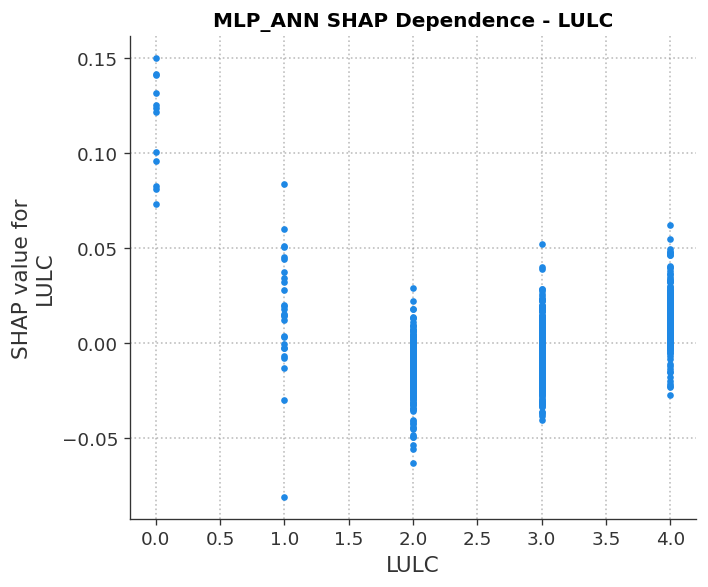

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_SHAP_Dependence_LULC.png

Explaining model: TabNet


,Model,Feature,Permutation_Importance_Mean,Permutation_Importance_Std
0,TabNet,BSI,0.502222,0.011189
1,TabNet,MNDWI,0.286312,0.006314
2,TabNet,STI,0.267762,0.004202
3,TabNet,TWI,0.064090,0.002349
4,TabNet,NBR,0.032593,0.001279
5,TabNet,Lithology,0.019259,0.002159
6,TabNet,TRI,0.015008,0.001420
7,TabNet,LULC,0.005990,0.001360
8,TabNet,Lineament_Density,0.005862,0.002244
9,TabNet,Drainage_Density,0.001546,0.001047


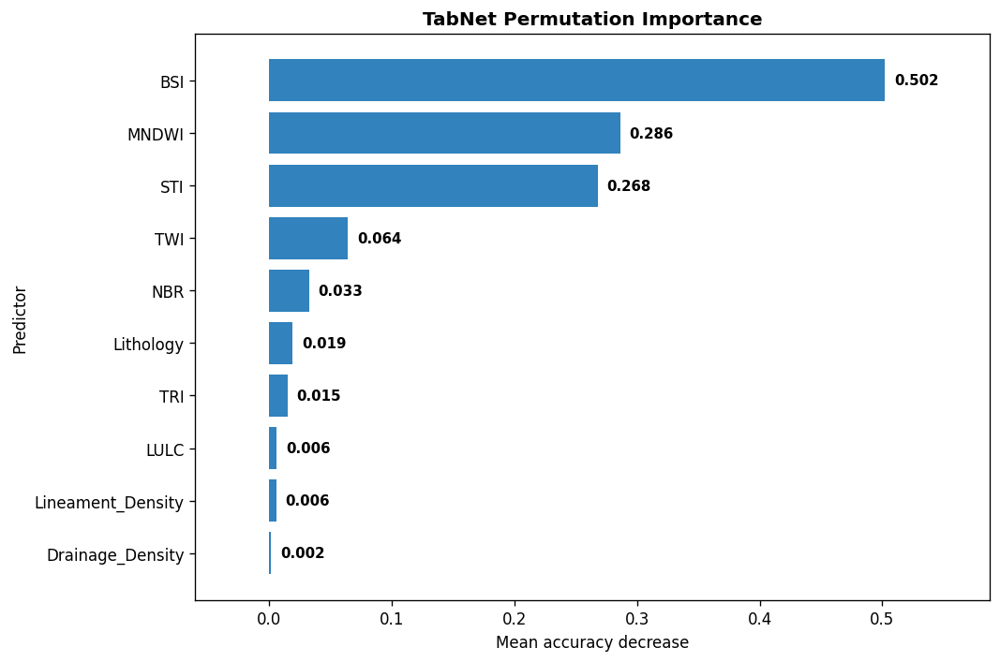

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_Permutation_Importance_All10Predictors.png


,Model,Feature,MeanAbsSHAP_ModelLevel_SusceptibilityScore
6,TabNet,BSI,0.295300
8,TabNet,MNDWI,0.139354
5,TabNet,STI,0.130081
4,TabNet,TWI,0.028199
0,TabNet,Lithology,0.018408
7,TabNet,NBR,0.015359
3,TabNet,TRI,0.012270
9,TabNet,LULC,0.007240
1,TabNet,Lineament_Density,0.007085
2,TabNet,Drainage_Density,0.005354


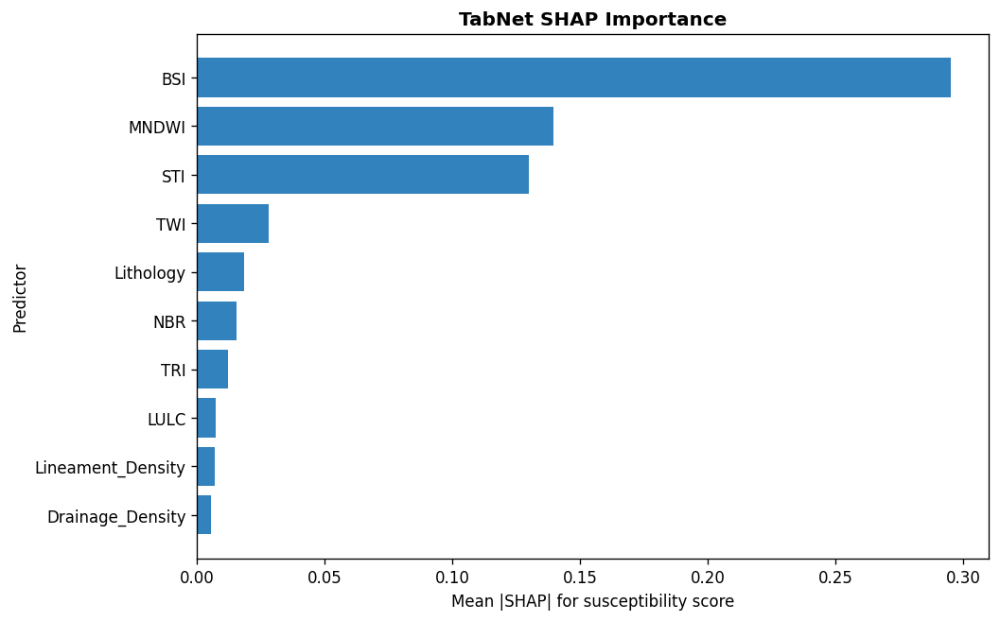

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_SHAP_Bar_ModelLevel_All10Predictors.png


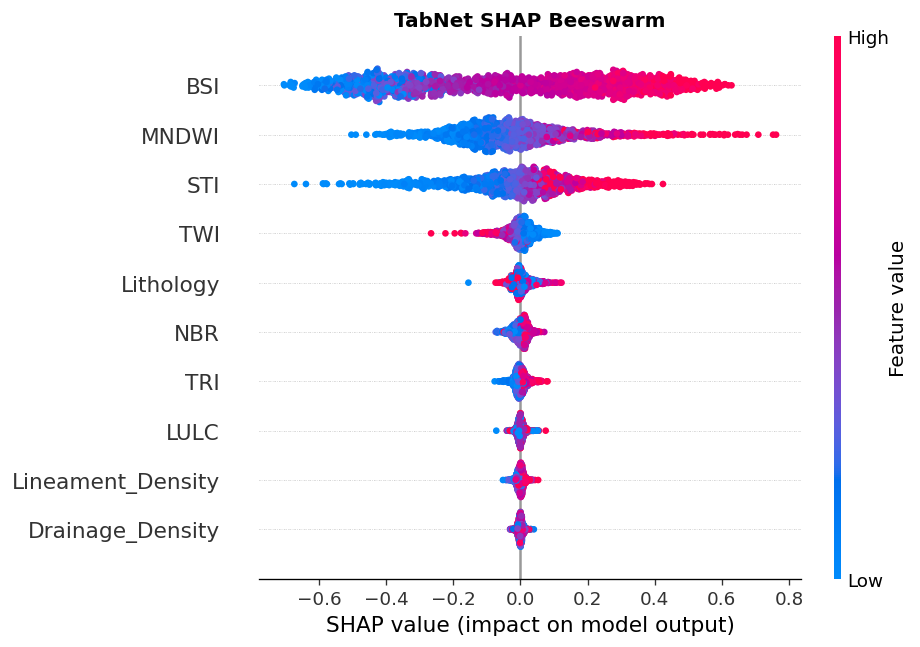

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_SHAP_Beeswarm_ModelLevel_All10Predictors.png


<Figure size 840x600 with 0 Axes>

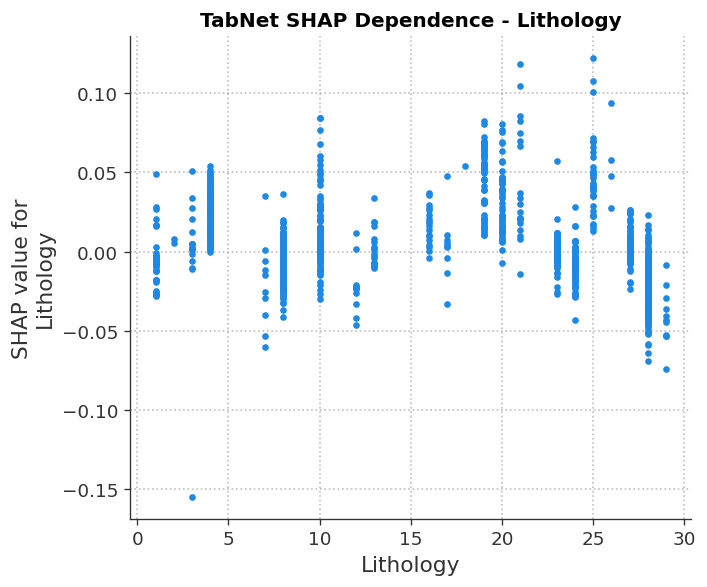

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_SHAP_Dependence_Lithology.png


<Figure size 840x600 with 0 Axes>

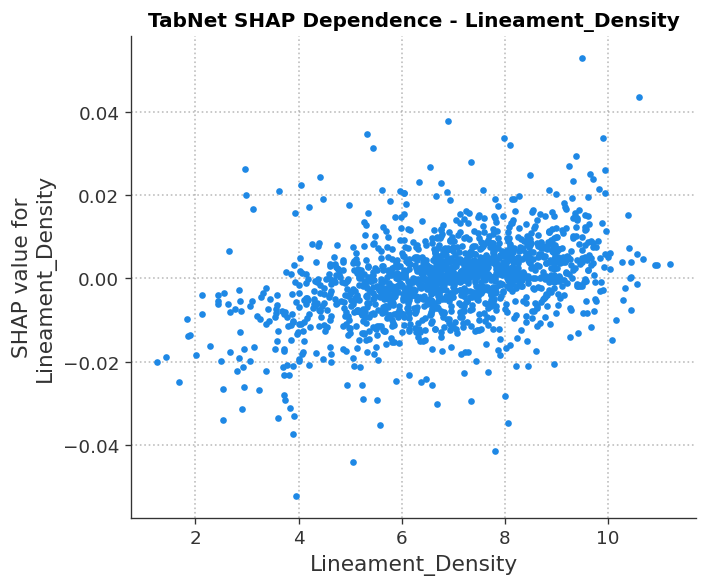

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_SHAP_Dependence_Lineament_Density.png


<Figure size 840x600 with 0 Axes>

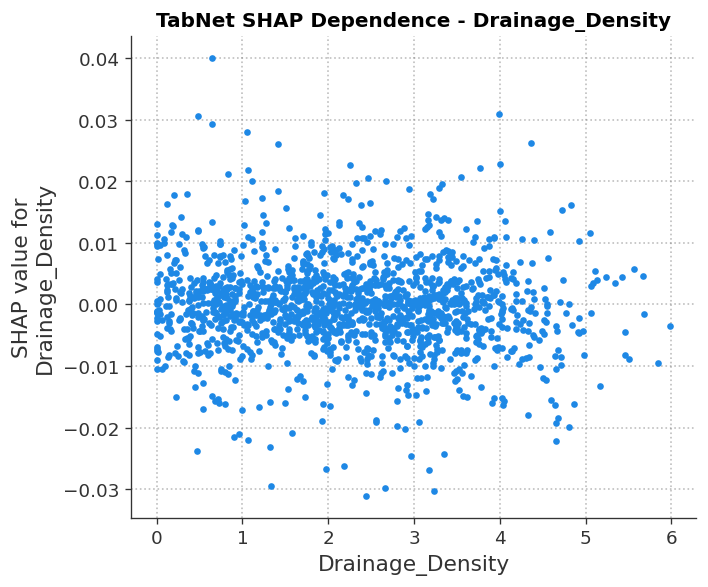

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_SHAP_Dependence_Drainage_Density.png


<Figure size 840x600 with 0 Axes>

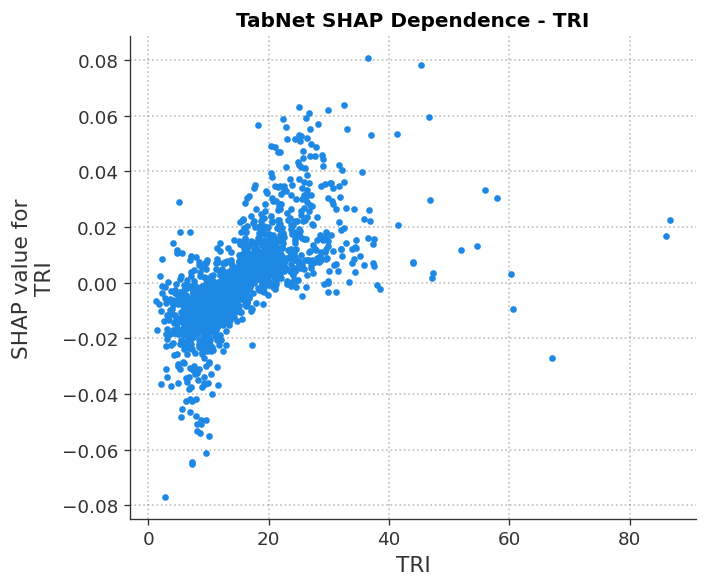

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_SHAP_Dependence_TRI.png


<Figure size 840x600 with 0 Axes>

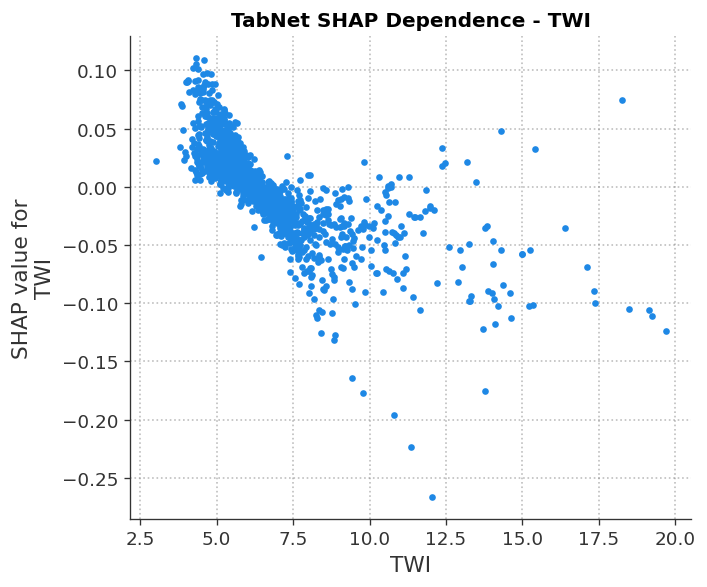

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_SHAP_Dependence_TWI.png


<Figure size 840x600 with 0 Axes>

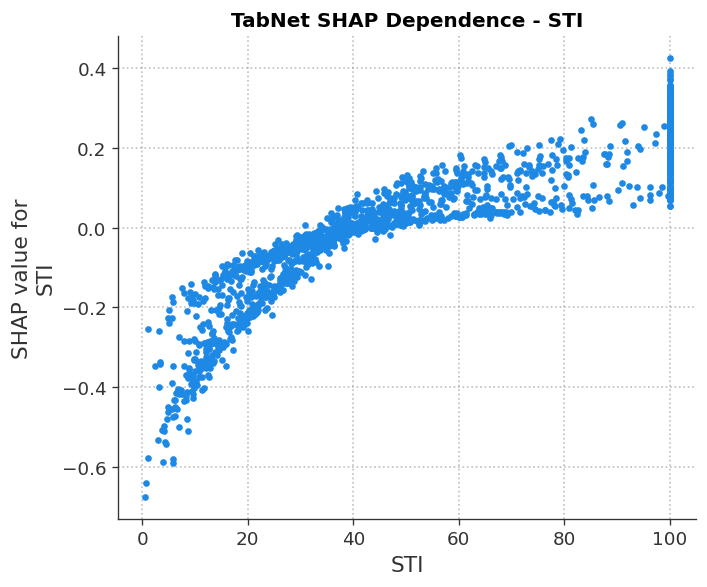

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_SHAP_Dependence_STI.png


<Figure size 840x600 with 0 Axes>

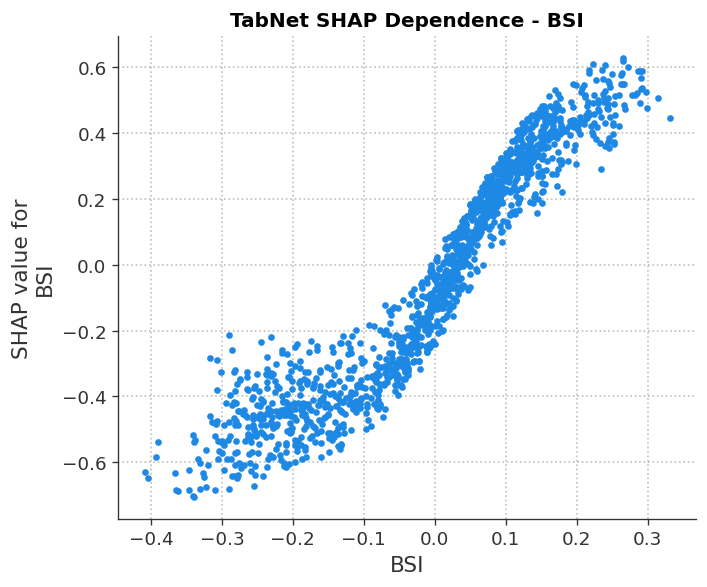

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_SHAP_Dependence_BSI.png


<Figure size 840x600 with 0 Axes>

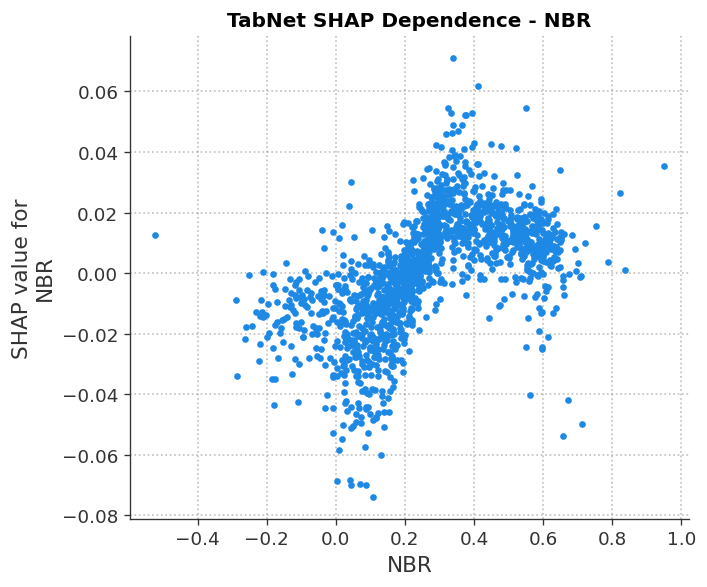

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_SHAP_Dependence_NBR.png


<Figure size 840x600 with 0 Axes>

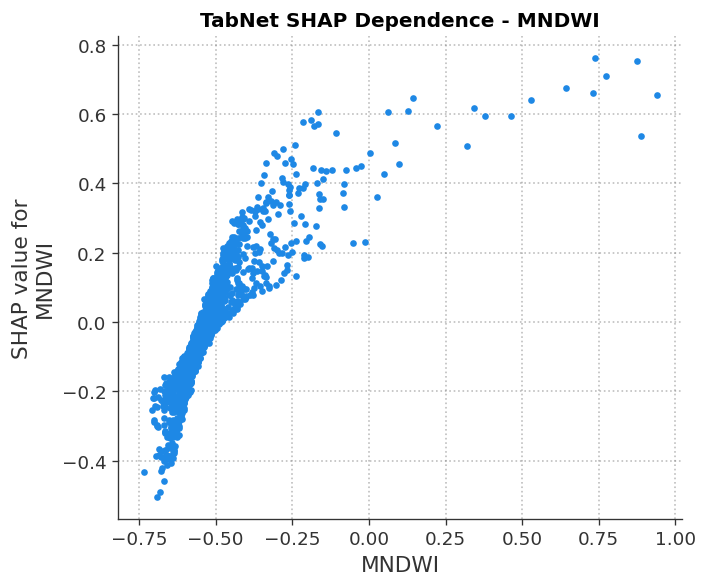

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_SHAP_Dependence_MNDWI.png


<Figure size 840x600 with 0 Axes>

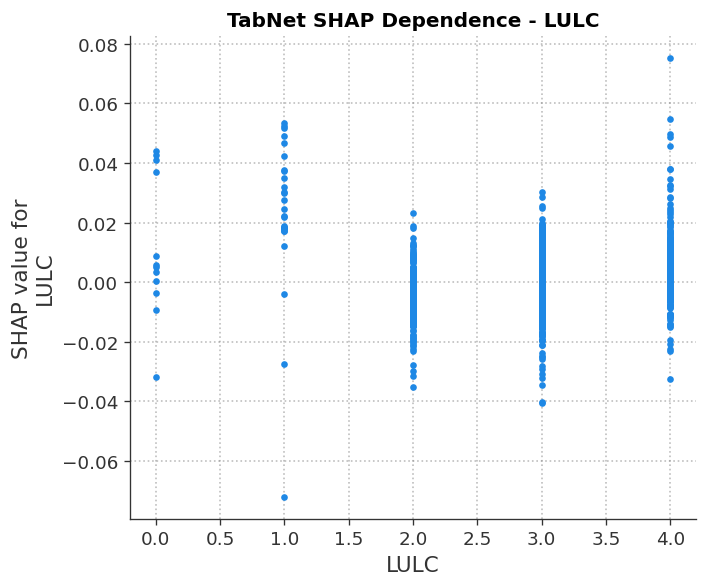

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_SHAP_Dependence_LULC.png


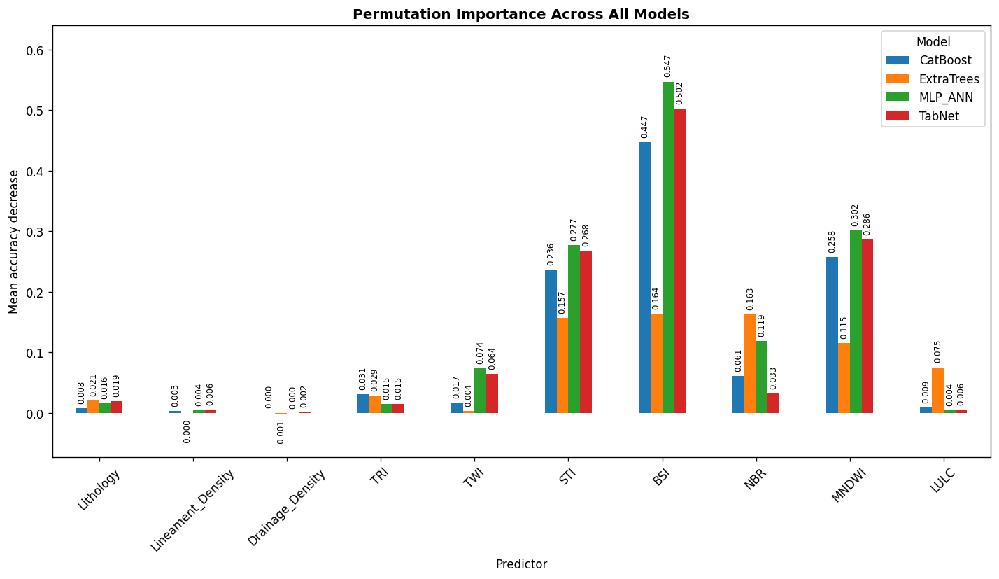

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/All_Models_Permutation_Importance_All10Predictors.png


Model,CatBoost,ExtraTrees,MLP_ANN,TabNet
Feature,,,,
Lithology,0.007923,0.020676,0.016296,0.019259
Lineament_Density,0.002834,-0.000322,0.004380,0.005862
Drainage_Density,0.000322,-0.001417,0.000064,0.001546
TRI,0.030982,0.028599,0.015072,0.015008
TWI,0.017456,0.003607,0.073816,0.064090
STI,0.236135,0.157166,0.277359,0.267762
BSI,0.447343,0.163736,0.547246,0.502222
NBR,0.061256,0.163092,0.118583,0.032593
MNDWI,0.257842,0.114911,0.301900,0.286312


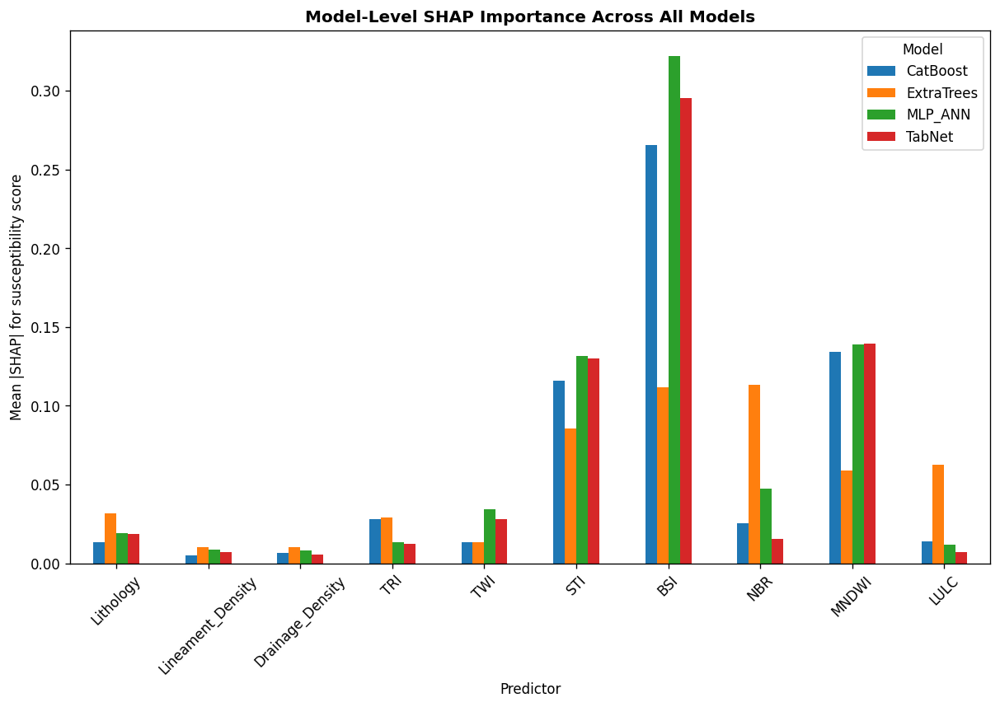

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/All_Models_SHAP_Importance_ModelLevel_All10Predictors.png


Model,CatBoost,ExtraTrees,MLP_ANN,TabNet
Feature,,,,
Lithology,0.013285,0.031743,0.019090,0.018408
Lineament_Density,0.005211,0.010446,0.008797,0.007085
Drainage_Density,0.006477,0.010134,0.008183,0.005354
TRI,0.028024,0.029232,0.013470,0.012270
TWI,0.013598,0.013291,0.034578,0.028199
STI,0.115947,0.085683,0.131473,0.130081
BSI,0.265423,0.111820,0.322317,0.295300
NBR,0.025378,0.113335,0.047289,0.015359
MNDWI,0.134462,0.059095,0.139077,0.139354


Cell 11 completed.


In [12]:
# ============================================================
# CELL 11: MODEL-LEVEL EXPLAINABILITY FOR ALL 10 PREDICTORS
# ============================================================

from pathlib import Path

print("Starting model-level explainability for all 10 predictors...")


# ============================================================
# LOCAL FIGURE SAVE/DISPLAY HELPER
# ============================================================

def save_show(fig, out_path):
    """
    Save a Matplotlib figure at 300 dpi, display it,
    close it safely, and print the output path.
    """

    out_path = Path(out_path)

    out_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    fig.savefig(
        out_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(
        "Saved:",
        out_path
    )


# ============================================================
# PERMUTATION IMPORTANCE WRAPPER
# ============================================================

class PermutationImportanceWrapper(BaseEstimator):

    def __init__(self, model_name, model):
        self.model_name = model_name
        self.model = model

    def fit(self, X, y=None):
        return self

    def predict(self, X):

        return predict_model(
            self.model_name,
            self.model,
            X
        )[0]

    def score(self, X, y):

        y_pred = self.predict(X)

        return accuracy_score(
            y,
            y_pred
        )


# ============================================================
# MODEL-LEVEL SUSCEPTIBILITY SCORE FUNCTION
# ============================================================

def make_model_score_function(model_name, model):

    def score_fn(arr):

        Xtmp = pd.DataFrame(
            np.asarray(arr),
            columns=FEATURES
        )

        return predict_susceptibility_score(
            model_name,
            model,
            Xtmp
        )

    return score_fn


# ============================================================
# EXPLAINABILITY SAMPLE
# TEST SET ONLY
# ============================================================

# IMPORTANT:
# The SHAP explanation sample is drawn strictly from the held-out
# 15% TEST SET (X_test / y_test), not from the full 20,700-point df.
#
# EXPLAIN_SAMPLE_N remains 1500.
# EXPLAIN_BACKGROUND_N remains 100.
#
# A new checkpoint filename is used so that any previously saved
# explainability indices drawn from the full dataset cannot be reused.

explain_sample_path = (
    CHECKPOINT_DIR /
    "Explainability_TestOnly_Sample_Indices.json"
)


# Build a test-only sampling table while preserving the original
# X_test indices so that the selected rows can be retrieved exactly.
test_explain_pool = (
    X_test[
        FEATURES
    ]
    .copy()
)


test_explain_pool[
    TARGET_COL
] = np.asarray(
    y_test
).reshape(
    -1
)


if (
    explain_sample_path.exists()
    and not FORCE_REDO_EXPLAINABILITY
):

    explain_indices = json.loads(
        explain_sample_path.read_text()
    )


    # Strict validation:
    # every saved explainability index must belong to X_test.
    invalid_indices = [
        i
        for i in explain_indices
        if i not in X_test.index
    ]


    if invalid_indices:

        raise RuntimeError(
            "The saved test-only explainability checkpoint contains "
            "indices that are not part of X_test. Delete this checkpoint "
            "or set FORCE_REDO_EXPLAINABILITY=True and rerun Cell 11."
        )

else:

    n_explain = min(
        EXPLAIN_SAMPLE_N,
        len(test_explain_pool)
    )

    sampled_parts = []

    for cls, g in test_explain_pool.groupby(
        TARGET_COL
    ):

        n_cls = max(
            1,
            int(
                round(
                    n_explain *
                    len(g) /
                    len(test_explain_pool)
                )
            )
        )

        n_cls = min(
            n_cls,
            len(g)
        )

        sampled_parts.append(
            g.sample(
                n=n_cls,
                random_state=RANDOM_STATE
            )
        )

    explain_df = pd.concat(
        sampled_parts,
        axis=0
    )

    if len(explain_df) > n_explain:

        explain_df = explain_df.sample(
            n=n_explain,
            random_state=RANDOM_STATE
        )

    explain_indices = (
        explain_df.index.tolist()
    )

    explain_sample_path.write_text(
        json.dumps(
            [
                int(i)
                for i in explain_indices
            ]
        )
    )


X_explain = X_test.loc[
    explain_indices,
    FEATURES
].copy()


# Confirm that every SHAP explanation observation is from X_test.
if not set(
    explain_indices
).issubset(
    set(
        X_test.index
    )
):

    raise RuntimeError(
        "Explainability sample contains observations outside X_test."
    )


# Print the exact test-only SHAP sample distribution.
explain_target_distribution = (
    test_explain_pool.loc[
        explain_indices,
        TARGET_COL
    ]
    .value_counts()
    .sort_index()
)


print(
    "SHAP explanation source: TEST SET ONLY"
)

print(
    "Available test observations:",
    len(X_test)
)

print(
    "Selected SHAP explanation observations:",
    len(X_explain)
)

print(
    "SHAP explanation target distribution:"
)

print(
    explain_target_distribution
)


background_n = min(
    EXPLAIN_BACKGROUND_N,
    len(X_train)
)


X_background = (
    X_train[FEATURES]
    .sample(
        n=background_n,
        random_state=RANDOM_STATE
    )
    .copy()
)


print(
    "SHAP background source: TRAINING SET ONLY"
)


# ============================================================
# CONFIRM CATEGORICAL VARIATION
# ============================================================

for c in CATEGORICAL_FEATURES:

    print(
        f"{c} explainability sample unique classes:",
        sorted(
            X_explain[c]
            .unique()
            .tolist()
        )
    )

    if X_explain[c].nunique() < 2:

        print(
            f"Warning: {c} has fewer than 2 classes "
            f"in the explainability sample."
        )


print(
    "Explainability sample size:",
    len(X_explain)
)

print(
    "Background size:",
    len(X_background)
)

print(
    "Predictors used:",
    FEATURES
)


all_perm_rows = []
all_shap_rows = []


# ============================================================
# LOOP THROUGH ALL FOUR MODELS
# ============================================================

for model_name in [
    "CatBoost",
    "ExtraTrees",
    "MLP_ANN",
    "TabNet"
]:

    if model_name not in final_models:
        continue


    model = final_models[
        model_name
    ]


    model_dir = (
        EXPLAIN_DIR /
        model_name
    )

    model_dir.mkdir(
        parents=True,
        exist_ok=True
    )


    print(
        "\nExplaining model:",
        model_name
    )


    # ========================================================
    # PERMUTATION IMPORTANCE
    # ========================================================

    perm_path = (
        model_dir /
        f"{model_name}_Permutation_Importance_All10Predictors.csv"
    )


    if (
        perm_path.exists()
        and not FORCE_REDO_EXPLAINABILITY
    ):

        perm_df = pd.read_csv(
            perm_path
        )

    else:

        wrapper = PermutationImportanceWrapper(
            model_name,
            model
        )


        perm = permutation_importance(

            estimator=wrapper,

            X=X_test[
                FEATURES
            ].copy(),

            y=y_test,

            n_repeats=
                PERMUTATION_IMPORTANCE_REPEATS,

            random_state=
                RANDOM_STATE,

            n_jobs=1,

            scoring=None
        )


        perm_df = pd.DataFrame({

            "Model":
                model_name,

            "Feature":
                FEATURES,

            "Permutation_Importance_Mean":
                perm.importances_mean,

            "Permutation_Importance_Std":
                perm.importances_std

        }).sort_values(

            "Permutation_Importance_Mean",

            ascending=False
        )


        perm_df.to_csv(
            perm_path,
            index=False
        )


    all_perm_rows.append(
        perm_df
    )


    display(
        perm_df
    )


    # ========================================================
    # INDIVIDUAL PERMUTATION IMPORTANCE BAR GRAPH
    # VALUES SHOWN
    # NO ERROR-BAR TICKS AFTER BARS
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(9, 6)
    )


    tmp = perm_df.sort_values(
        "Permutation_Importance_Mean",
        ascending=True
    )


    # IMPORTANT:
    # xerr has been removed so there are no error-bar ticks
    # or whiskers after the bars.

    bars = ax.barh(

        tmp["Feature"],

        tmp["Permutation_Importance_Mean"],

        color="#3182bd"
    )


    # --------------------------------------------------------
    # SHOW THE VALUE OF EACH PERMUTATION IMPORTANCE BAR
    # --------------------------------------------------------

    bar_values = (
        tmp[
            "Permutation_Importance_Mean"
        ]
        .to_numpy(dtype=float)
    )


    finite_bar_values = bar_values[
        np.isfinite(bar_values)
    ]


    if finite_bar_values.size > 0:

        value_range = (
            float(np.nanmax(finite_bar_values)) -
            float(np.nanmin(finite_bar_values))
        )

        max_abs_value = float(
            np.nanmax(
                np.abs(finite_bar_values)
            )
        )

    else:

        value_range = 0.0
        max_abs_value = 0.0


    label_offset = max(
        value_range * 0.015,
        max_abs_value * 0.015,
        0.0005
    )


    for bar, value in zip(
        bars,
        bar_values
    ):

        if not np.isfinite(value):
            continue


        if value >= 0:

            text_x = (
                bar.get_width() +
                label_offset
            )

            text_ha = "left"

        else:

            text_x = (
                bar.get_width() -
                label_offset
            )

            text_ha = "right"


        ax.text(

            text_x,

            bar.get_y() +
            bar.get_height() / 2,

            f"{value:.3f}",

            ha=text_ha,

            va="center",

            fontsize=9,

            fontweight="bold",

            color="black"
        )


    # Give value labels enough space inside the axes
    current_xlim = ax.get_xlim()


    positive_space = max(
        current_xlim[1],
        float(np.nanmax(bar_values))
        if np.isfinite(bar_values).any()
        else 0
    )


    negative_space = min(
        current_xlim[0],
        float(np.nanmin(bar_values))
        if np.isfinite(bar_values).any()
        else 0
    )


    extra_space = max(
        max_abs_value * 0.12,
        0.005
    )


    ax.set_xlim(
        negative_space - extra_space,
        positive_space + extra_space
    )


    # Removed: " - All 10 Predictors"
    ax.set_title(

        f"{model_name} Permutation Importance",

        fontweight="bold"
    )


    ax.set_xlabel(
        "Mean accuracy decrease"
    )


    ax.set_ylabel(
        "Predictor"
    )


    fig.tight_layout()


    save_show(

        fig,

        model_dir /
        f"{model_name}_Permutation_Importance_All10Predictors.png"
    )


    # ========================================================
    # SHAP KERNELEXPLAINER ON MODEL-LEVEL SUSCEPTIBILITY SCORE
    # ========================================================

    shap_values_path = (

        model_dir /

        f"{model_name}_SHAP_Values_ModelLevel.npy"
    )


    shap_data_path = (

        model_dir /

        f"{model_name}_SHAP_InputSample_All10Predictors.csv"
    )


    if (

        shap_values_path.exists()

        and shap_data_path.exists()

        and not FORCE_REDO_EXPLAINABILITY
    ):

        shap_values_arr = np.load(
            shap_values_path
        )


        X_shap_display = pd.read_csv(
            shap_data_path
        )


    else:

        score_fn = make_model_score_function(
            model_name,
            model
        )


        background = (
            X_background[
                FEATURES
            ]
            .copy()
        )


        sample = (
            X_explain[
                FEATURES
            ]
            .copy()
        )


        explainer = shap.KernelExplainer(
            score_fn,
            background
        )


        shap_values_arr = (
            explainer.shap_values(

                sample,

                nsamples=
                    EXPLAIN_NSAMPLES
            )
        )


        shap_values_arr = np.asarray(
            shap_values_arr
        )


        if shap_values_arr.ndim == 3:

            shap_values_arr = (
                shap_values_arr[
                    :,
                    :,
                    0
                ]
            )


        X_shap_display = sample.copy()


        np.save(
            shap_values_path,
            shap_values_arr
        )


        X_shap_display.to_csv(
            shap_data_path,
            index=False
        )


    # ========================================================
    # MEAN ABSOLUTE SHAP IMPORTANCE
    # ========================================================

    mean_abs_shap = np.mean(

        np.abs(
            shap_values_arr
        ),

        axis=0
    )


    shap_imp_df = pd.DataFrame({

        "Model":
            model_name,

        "Feature":
            FEATURES,

        "MeanAbsSHAP_ModelLevel_SusceptibilityScore":
            mean_abs_shap

    }).sort_values(

        "MeanAbsSHAP_ModelLevel_SusceptibilityScore",

        ascending=False
    )


    shap_imp_df.to_csv(

        model_dir /

        f"{model_name}_SHAP_Importance_ModelLevel_All10Predictors.csv",

        index=False
    )


    all_shap_rows.append(
        shap_imp_df
    )


    display(
        shap_imp_df
    )


    # ========================================================
    # SHAP BAR PLOT
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(9, 6)
    )


    tmp = shap_imp_df.sort_values(

        "MeanAbsSHAP_ModelLevel_SusceptibilityScore",

        ascending=True
    )


    ax.barh(

        tmp["Feature"],

        tmp[
            "MeanAbsSHAP_ModelLevel_SusceptibilityScore"
        ],

        color="#3182bd"
    )


    # Removed: " - All 10 Predictors"
    ax.set_title(

        f"{model_name} SHAP Importance",

        fontweight="bold"
    )


    ax.set_xlabel(
        "Mean |SHAP| for susceptibility score"
    )


    ax.set_ylabel(
        "Predictor"
    )


    save_show(

        fig,

        model_dir /

        f"{model_name}_SHAP_Bar_ModelLevel_All10Predictors.png"
    )


    # ========================================================
    # SHAP BEESWARM
    # MORE VISIBLE HORIZONTAL DOTTED GUIDE LINES
    # ========================================================

    plt.figure(
        figsize=(9, 6)
    )


    shap.summary_plot(

        shap_values_arr,

        X_shap_display[
            FEATURES
        ],

        feature_names=
            FEATURES,

        max_display=10,

        show=False
    )


    ax = plt.gca()


    ax.set_axisbelow(
        True
    )


    ax.grid(

        axis="y",

        linestyle=":",


        linewidth=0.50,

        color="#A0A0A0",

        alpha=0.45
    )


    # Removed: " - All 10 Predictors"
    plt.title(

        f"{model_name} SHAP Beeswarm",

        fontweight="bold"
    )


    plt.tight_layout()


    beeswarm_path = (

        model_dir /

        f"{model_name}_SHAP_Beeswarm_ModelLevel_All10Predictors.png"
    )


    plt.savefig(

        beeswarm_path,

        dpi=300,

        bbox_inches="tight"
    )


    plt.show()

    plt.close()


    print(
        "Saved:",
        beeswarm_path
    )


    # ========================================================
    # SHAP DEPENDENCE PLOTS FOR ALL 10 PREDICTORS
    # MORE VISIBLE DOTTED GRID LINES
    # ========================================================

    for feat in FEATURES:


        plt.figure(
            figsize=(7, 5)
        )


        shap.dependence_plot(

            feat,

            shap_values_arr,

            X_shap_display[
                FEATURES
            ],

            feature_names=
                FEATURES,

            interaction_index=
                None,

            show=False
        )


        ax = plt.gca()


        ax.set_axisbelow(
            True
        )


        ax.grid(

            True,

            linestyle=":",

            linewidth=1.0,

            color="#808080",

            alpha=0.50
        )


        plt.title(

            f"{model_name} SHAP Dependence - {feat}",

            fontweight="bold"
        )


        plt.tight_layout()


        dep_path = (

            model_dir /

            f"{model_name}_SHAP_Dependence_{feat}.png"
        )


        plt.savefig(

            dep_path,

            dpi=300,

            bbox_inches="tight"
        )


        plt.show()

        plt.close()


        print(
            "Saved:",
            dep_path
        )


# ============================================================
# COMBINED PERMUTATION IMPORTANCE OUTPUTS
# ============================================================

all_perm_importance = pd.concat(

    all_perm_rows,

    ignore_index=True
)


all_perm_importance.to_csv(

    EXPLAIN_DIR /

    "All_Models_Permutation_Importance_All10Predictors.csv",

    index=False
)


perm_pivot = all_perm_importance.pivot_table(

    index="Feature",

    columns="Model",

    values="Permutation_Importance_Mean",

    aggfunc="mean"

).reindex(
    FEATURES
)


# ============================================================
# COMBINED PERMUTATION IMPORTANCE BAR GRAPH
# VALUES SHOWN FOR ALL MODEL BARS
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 7)
)


perm_pivot.plot(
    kind="bar",
    ax=ax
)


ax.set_title(

    "Permutation Importance Across All Models",

    fontweight="bold"
)


ax.set_xlabel(
    "Predictor"
)


ax.set_ylabel(
    "Mean accuracy decrease"
)


ax.tick_params(
    axis="x",
    rotation=45
)


ax.legend(
    title="Model"
)


# ------------------------------------------------------------
# SHOW VALUES ON EVERY COMBINED PERMUTATION BAR
# ------------------------------------------------------------

combined_values = (
    perm_pivot
    .to_numpy(dtype=float)
)


finite_combined_values = (
    combined_values[
        np.isfinite(
            combined_values
        )
    ]
)


if finite_combined_values.size > 0:

    combined_max_abs = float(
        np.nanmax(
            np.abs(
                finite_combined_values
            )
        )
    )

else:

    combined_max_abs = 0.0


combined_label_offset = max(
    combined_max_abs * 0.015,
    0.0005
)


for container in ax.containers:

    for bar in container:

        value = bar.get_height()


        if not np.isfinite(value):
            continue


        if value >= 0:

            text_y = (
                value +
                combined_label_offset
            )

            vertical_alignment = "bottom"

        else:

            text_y = (
                value -
                combined_label_offset
            )

            vertical_alignment = "top"


        ax.text(

            bar.get_x() +
            bar.get_width() / 2,

            text_y,

            f"{value:.3f}",

            ha="center",

            va=vertical_alignment,

            fontsize=7,

            rotation=90,

            color="black"
        )


# Give value labels enough vertical space
ymin, ymax = ax.get_ylim()


ax.set_ylim(

    ymin -
    max(
        combined_max_abs * 0.08,
        0.005
    ),

    ymax +
    max(
        combined_max_abs * 0.12,
        0.005
    )
)


fig.tight_layout()


save_show(

    fig,

    EXPLAIN_DIR /

    "All_Models_Permutation_Importance_All10Predictors.png"
)


display(
    perm_pivot
)


# ============================================================
# COMBINED SHAP IMPORTANCE OUTPUTS
# ============================================================

all_shap_importance = pd.concat(

    all_shap_rows,

    ignore_index=True
)


all_shap_importance.to_csv(

    EXPLAIN_DIR /

    "All_Models_SHAP_Importance_ModelLevel_All10Predictors.csv",

    index=False
)


shap_pivot = all_shap_importance.pivot_table(

    index="Feature",

    columns="Model",

    values=
        "MeanAbsSHAP_ModelLevel_SusceptibilityScore",

    aggfunc="mean"

).reindex(
    FEATURES
)


fig, ax = plt.subplots(
    figsize=(12, 7)
)


shap_pivot.plot(
    kind="bar",
    ax=ax
)


ax.set_title(

    "Model-Level SHAP Importance Across All Models",

    fontweight="bold"
)


ax.set_xlabel(
    "Predictor"
)


ax.set_ylabel(
    "Mean |SHAP| for susceptibility score"
)


ax.tick_params(
    axis="x",
    rotation=45
)


ax.legend(
    title="Model"
)


save_show(

    fig,

    EXPLAIN_DIR /

    "All_Models_SHAP_Importance_ModelLevel_All10Predictors.png"
)


display(
    shap_pivot
)


print(
    "Cell 11 completed."
)

# CELL 11B: SHAP XAI SW-LEVEL PREDICTOR INFLUENCE HEATMAP

Starting SW-level SHAP XAI heatmap generation...
Predictors used: ['Lithology', 'Lineament_Density', 'Drainage_Density', 'TRI', 'TWI', 'STI', 'BSI', 'NBR', 'MNDWI', 'LULC']
Categorical predictors: ['Lithology', 'LULC']
SHAP explanation source: TEST SET ONLY
Original held-out test rows: 3105
Valid test rows available for SHAP: 3105
SHAP explain sample size: 1500
SHAP explain sample target distribution:
Target
0    500
1    500
2    500
Name: count, dtype: int64
SHAP background source: TRAINING SET ONLY
SHAP background size: 100

Explaining model: CatBoost
Loaded existing SHAP arrays for CatBoost


,SWID,Lithology,Lineament_Density,Drainage_Density,TRI,TWI,STI,BSI,NBR,MNDWI,LULC
0,SW01,0.017964,0.005361,0.007094,0.028762,0.016970,0.149205,0.217283,0.027391,0.111748,0.016851
1,SW02,0.017985,0.005131,0.007501,0.025094,0.013917,0.118462,0.268140,0.023650,0.139623,0.013295
2,SW03,0.017020,0.004562,0.005849,0.031423,0.016545,0.142002,0.247963,0.022662,0.086130,0.011563
3,SW04,0.017146,0.006236,0.006424,0.031629,0.015007,0.139376,0.238860,0.020346,0.089050,0.010922
4,SW05,0.012806,0.004856,0.006569,0.027232,0.013938,0.091376,0.268843,0.023784,0.130514,0.012641
5,SW06,0.013207,0.004486,0.005898,0.045231,0.014235,0.136608,0.215160,0.020413,0.121803,0.011376
6,SW07,0.023076,0.005070,0.007041,0.022252,0.010136,0.092324,0.257304,0.019706,0.147253,0.015091
7,SW08,0.016016,0.005586,0.006571,0.021609,0.013862,0.121071,0.317307,0.026841,0.177307,0.017868
8,SW09,0.008921,0.005209,0.006255,0.021413,0.013239,0.092803,0.302265,0.025558,0.159563,0.015717
9,SW10,0.007963,0.005035,0.007103,0.028175,0.012554,0.134477,0.338793,0.039477,0.177993,0.021215


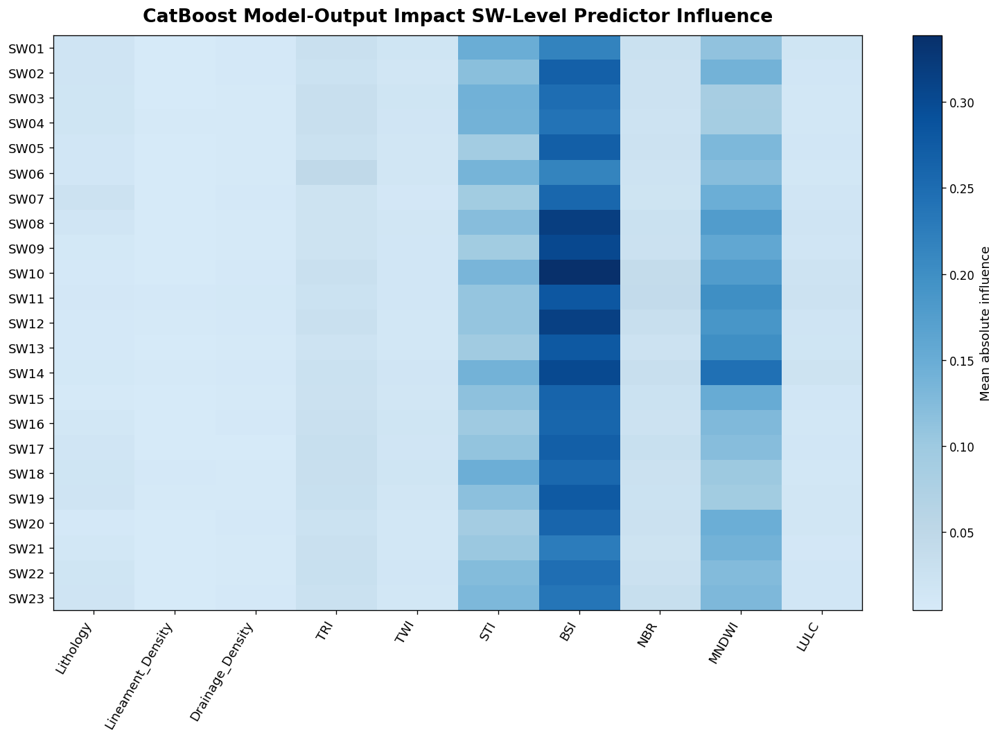

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/CatBoost/CatBoost_SW_Level_Predictor_Influence_Heatmap.png

Explaining model: ExtraTrees
Loaded existing SHAP arrays for ExtraTrees


,SWID,Lithology,Lineament_Density,Drainage_Density,TRI,TWI,STI,BSI,NBR,MNDWI,LULC
0,SW01,0.039980,0.006274,0.006207,0.024883,0.009788,0.102531,0.095118,0.091010,0.043161,0.060448
1,SW02,0.028081,0.008781,0.007780,0.024781,0.008050,0.088100,0.113431,0.101005,0.063326,0.055248
2,SW03,0.014858,0.005352,0.004826,0.027991,0.009098,0.109770,0.109900,0.113384,0.034868,0.045529
3,SW04,0.016328,0.008300,0.006085,0.028077,0.012652,0.107711,0.102157,0.106524,0.037131,0.045806
4,SW05,0.018011,0.005020,0.005563,0.028827,0.008534,0.067150,0.118632,0.123248,0.055972,0.058059
5,SW06,0.020524,0.007486,0.006399,0.039623,0.009195,0.100497,0.096788,0.101290,0.048578,0.053445
6,SW07,0.023863,0.007110,0.007945,0.025736,0.008369,0.064483,0.098035,0.096402,0.060326,0.065567
7,SW08,0.023413,0.005796,0.005913,0.023656,0.009876,0.084631,0.117976,0.106432,0.076308,0.078142
8,SW09,0.030928,0.004834,0.007629,0.021523,0.009016,0.063303,0.119830,0.113378,0.063333,0.076436
9,SW10,0.026785,0.006496,0.006356,0.028936,0.008081,0.085362,0.134803,0.145395,0.082905,0.078682


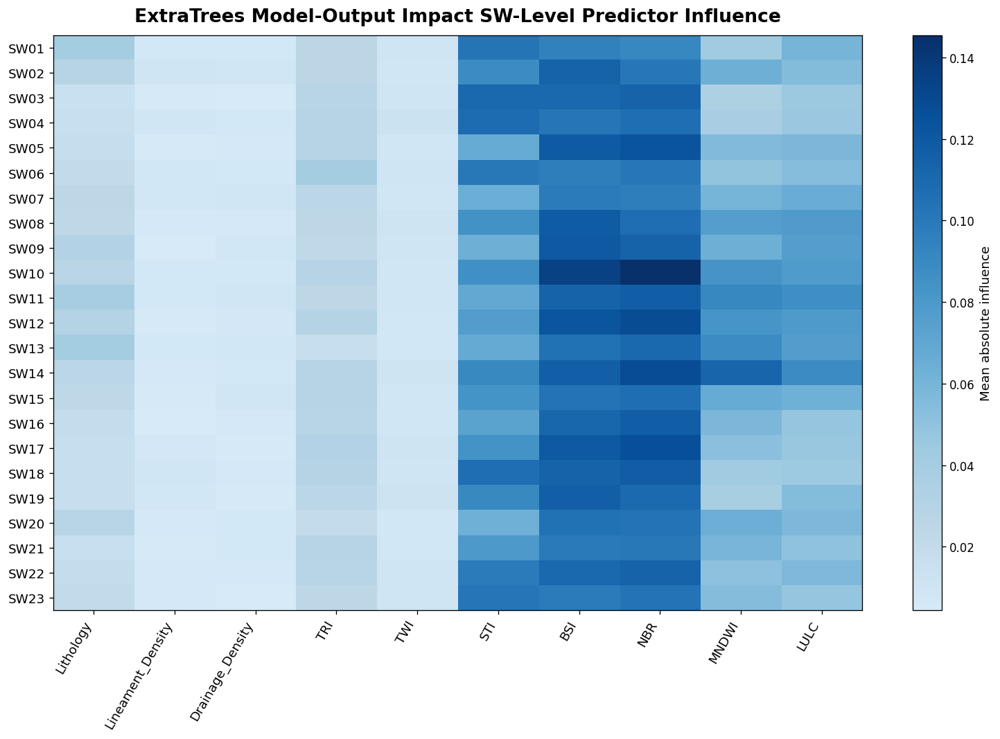

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/ExtraTrees/ExtraTrees_SW_Level_Predictor_Influence_Heatmap.png

Explaining model: MLP_ANN
Loaded existing SHAP arrays for MLP_ANN


,SWID,Lithology,Lineament_Density,Drainage_Density,TRI,TWI,STI,BSI,NBR,MNDWI,LULC
0,SW01,0.030550,0.008487,0.007858,0.018418,0.034384,0.169145,0.258501,0.033193,0.113581,0.010253
1,SW02,0.022939,0.010500,0.008634,0.015984,0.031640,0.134588,0.316457,0.040043,0.140256,0.011190
2,SW03,0.014263,0.011086,0.008596,0.015973,0.039293,0.169990,0.288396,0.048750,0.087620,0.009432
3,SW04,0.019150,0.011857,0.007995,0.017033,0.029056,0.161879,0.280672,0.042569,0.088605,0.011136
4,SW05,0.016801,0.005680,0.005814,0.010993,0.026445,0.103144,0.333032,0.041714,0.130881,0.010147
5,SW06,0.020814,0.006960,0.007847,0.022250,0.043173,0.163906,0.257777,0.041670,0.126679,0.010100
6,SW07,0.032121,0.008492,0.010575,0.011337,0.023874,0.109725,0.302179,0.041879,0.152028,0.010615
7,SW08,0.023591,0.011748,0.007485,0.011405,0.036640,0.139991,0.386231,0.042595,0.181825,0.013283
8,SW09,0.019480,0.008461,0.008791,0.009603,0.035919,0.106531,0.374528,0.051524,0.165989,0.012484
9,SW10,0.014575,0.008927,0.008589,0.013228,0.025601,0.136115,0.438472,0.067041,0.173148,0.014586


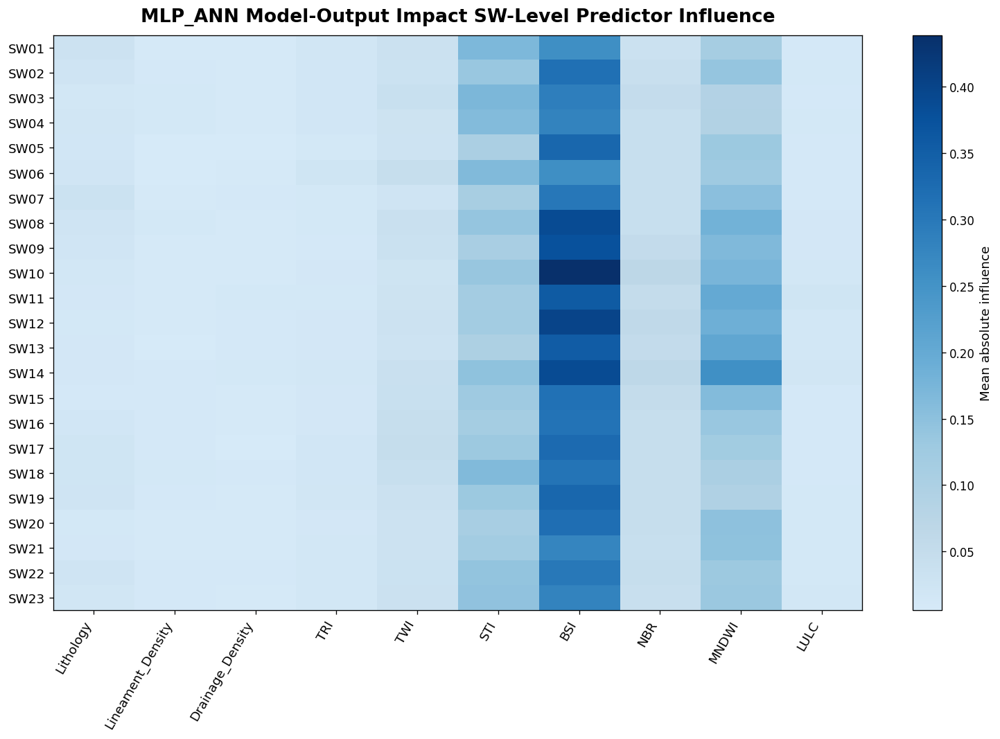

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/MLP_ANN/MLP_ANN_SW_Level_Predictor_Influence_Heatmap.png

Explaining model: TabNet
Loaded existing SHAP arrays for TabNet


,SWID,Lithology,Lineament_Density,Drainage_Density,TRI,TWI,STI,BSI,NBR,MNDWI,LULC
0,SW01,0.032774,0.006704,0.006442,0.012823,0.030200,0.169737,0.235196,0.012172,0.108459,0.007003
1,SW02,0.030608,0.005812,0.006015,0.015054,0.026340,0.135599,0.290032,0.013235,0.141254,0.006247
2,SW03,0.016810,0.007908,0.006317,0.012227,0.029147,0.170964,0.267049,0.020731,0.086855,0.007172
3,SW04,0.021823,0.008090,0.005694,0.015441,0.025745,0.165365,0.259613,0.019920,0.091428,0.008275
4,SW05,0.015675,0.005771,0.005080,0.011289,0.023450,0.104893,0.306428,0.014131,0.129161,0.005653
5,SW06,0.020420,0.006983,0.004870,0.016838,0.037026,0.161459,0.239185,0.013797,0.127551,0.006950
6,SW07,0.032945,0.006418,0.004583,0.012140,0.018185,0.107185,0.276403,0.010437,0.151693,0.006401
7,SW08,0.027265,0.007521,0.005362,0.010273,0.021137,0.128858,0.350683,0.013215,0.182055,0.008966
8,SW09,0.017679,0.004678,0.004903,0.010146,0.022828,0.098683,0.338064,0.010119,0.162504,0.008743
9,SW10,0.012155,0.006298,0.004929,0.010013,0.019096,0.140859,0.396919,0.013681,0.180651,0.007937


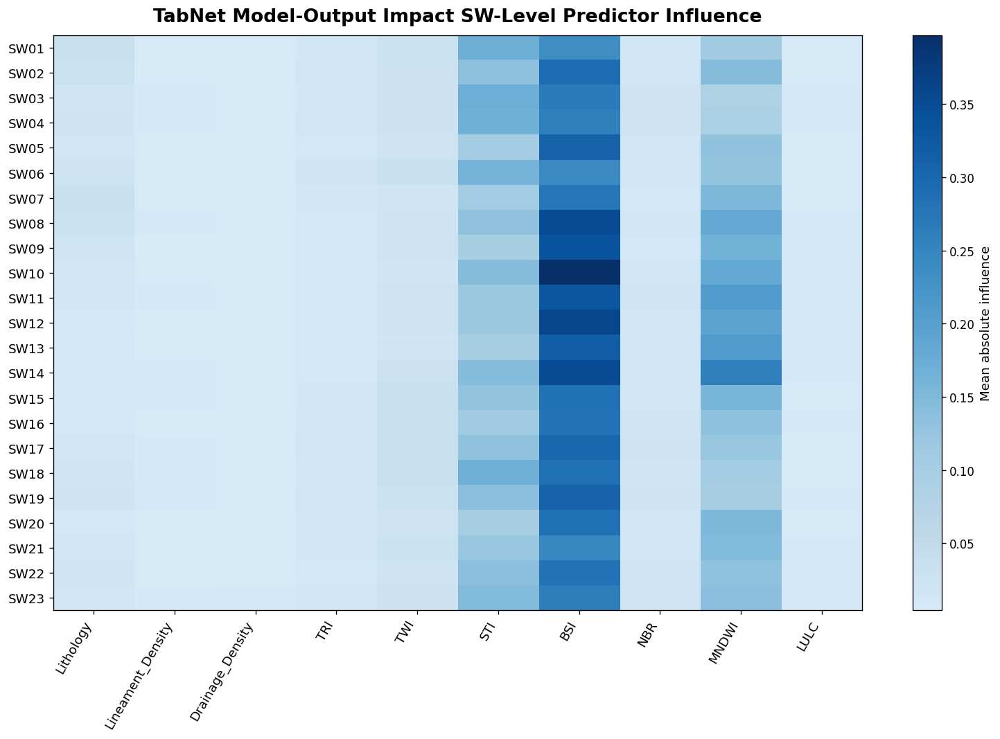

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet/TabNet_SW_Level_Predictor_Influence_Heatmap.png
Saved combined SW heatmap table: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/All_Models_SW_Level_Predictor_Influence_Long.csv
SW-level SHAP XAI heatmap generation completed.


In [13]:
# ============================================================
# - Produces one heatmap per model
# - Rows    = SW01 ... SW23
# - Columns = 10 predictors
# - Values  = mean absolute SHAP influence
# - Low influence = light blue
# - Increasing influence = progressively darker shades of blue
# - Reduced white appearance at the low-influence end
# - Explains model-output susceptibility score:
#       Susceptibility = P_high + 0.5 * P_moderate
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from pathlib import Path
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap


# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

STRICT_FEATURES = [
    "Lithology",
    "Lineament_Density",
    "Drainage_Density",
    "TRI",
    "TWI",
    "STI",
    "BSI",
    "NBR",
    "MNDWI",
    "LULC"
]

CATEGORICAL_FEATURES = [
    "Lithology",
    "LULC"
]


if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42


if "FORCE_REDO_EXPLAINABILITY" not in globals():
    FORCE_REDO_EXPLAINABILITY = False


# You can adjust these if needed
SW_SHAP_SAMPLE_N = 1500
SW_SHAP_BACKGROUND_N = 100
SW_SHAP_NSAMPLES = 100


# ------------------------------------------------------------
# CUSTOM HEATMAP COLOR SCALE
#
# Low influence  = light blue
# Medium influence = medium blue
# High influence = dark blue
#
# No white color is included.
# ------------------------------------------------------------

influence_cmap = LinearSegmentedColormap.from_list(
    "Blue_Influence_Less_White",
    [
        "#d6eaf8",  # very low influence: light blue
        "#bdd7e7",  # low influence
        "#9ecae1",  # lower-medium influence
        "#6baed6",  # medium influence
        "#4292c6",  # moderately high influence
        "#2171b5",  # high influence
        "#08519c",  # very high influence
        "#08306b"   # highest influence: darkest blue
    ]
)


# ------------------------------------------------------------
# 2. CHECK REQUIRED OBJECTS
# ------------------------------------------------------------

required_globals = [
    "df",
    "final_models",
    "EXPLAIN_DIR",
    "CHECKPOINT_DIR",
    "X_test",
    "y_test",
    "X_train"
]


missing_required = [
    v
    for v in required_globals
    if v not in globals()
]


if missing_required:

    raise ValueError(
        f"Missing required objects in notebook: {missing_required}"
    )


if "TARGET_COL" not in globals():

    TARGET_COL = "Target"


if TARGET_COL not in df.columns:

    raise ValueError(
        f"TARGET_COL '{TARGET_COL}' was not found in df."
    )


if "SWID" not in df.columns:

    raise ValueError(
        "df must contain 'SWID' column for subwatershed-level SHAP heatmaps."
    )


missing_feature_cols = [
    c
    for c in STRICT_FEATURES
    if c not in df.columns
]


if missing_feature_cols:

    raise ValueError(
        f"Missing predictor columns in df: {missing_feature_cols}"
    )


EXPLAIN_DIR = Path(
    EXPLAIN_DIR
)


CHECKPOINT_DIR = Path(
    CHECKPOINT_DIR
)


EXPLAIN_DIR.mkdir(
    parents=True,
    exist_ok=True
)


CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print(
    "Starting SW-level SHAP XAI heatmap generation..."
)


print(
    "Predictors used:",
    STRICT_FEATURES
)


print(
    "Categorical predictors:",
    CATEGORICAL_FEATURES
)


# ------------------------------------------------------------
# 3. PREPARE FEATURE TABLE
# TEST SET ONLY
# ------------------------------------------------------------

# IMPORTANT:
# SHAP explanations in this cell are now drawn strictly from the
# held-out 15% TEST SET (X_test / y_test), not from the full df.
#
# The original X_test indices are used to recover the correct SWID
# for every held-out test observation from df.

missing_test_indices = [
    idx
    for idx in X_test.index
    if idx not in df.index
]


if missing_test_indices:

    raise ValueError(
        "Some X_test indices were not found in df, so SWID cannot "
        "be matched safely to the held-out test observations."
    )


X_all = X_test[
    STRICT_FEATURES
].copy()


y_all = pd.Series(
    np.asarray(
        y_test
    ).reshape(-1),
    index=X_test.index,
    name=TARGET_COL
)


sw_all = (
    df.loc[
        X_test.index,
        "SWID"
    ]
    .astype(str)
    .copy()
)


if len(X_all) != len(y_all):

    raise ValueError(
        "X_test and y_test do not contain the same number of rows."
    )


for c in STRICT_FEATURES:

    X_all[c] = pd.to_numeric(
        X_all[c],
        errors="coerce"
    )


# Categorical cleaning
for c in CATEGORICAL_FEATURES:

    X_all[c] = np.rint(
        X_all[c]
    ).astype("Int64")


# Remove invalid rows from the TEST pool only
valid_mask = np.ones(
    len(X_all),
    dtype=bool
)


for c in STRICT_FEATURES:

    valid_mask &= (
        X_all[c]
        .notna()
        .values
    )


X_all = (
    X_all.loc[
        valid_mask
    ]
    .reset_index(
        drop=True
    )
)


y_all = (
    y_all.loc[
        valid_mask
    ]
    .reset_index(
        drop=True
    )
)


sw_all = (
    sw_all.loc[
        valid_mask
    ]
    .reset_index(
        drop=True
    )
)


print(
    "SHAP explanation source: TEST SET ONLY"
)


print(
    "Original held-out test rows:",
    len(X_test)
)


print(
    "Valid test rows available for SHAP:",
    len(X_all)
)


# ------------------------------------------------------------
# 4. SAMPLE INDICES FOR SHAP
# ------------------------------------------------------------

sample_json = (
    CHECKPOINT_DIR /
    "SW_Level_SHAP_TEST_ONLY_Sample_Indices.json"
)


if (
    sample_json.exists()
    and not FORCE_REDO_EXPLAINABILITY
):

    explain_indices = json.loads(
        sample_json.read_text()
    )


    explain_indices = [

        int(i)

        for i in explain_indices

        if int(i) < len(X_all)
    ]


else:

    n_explain = min(
        SW_SHAP_SAMPLE_N,
        len(X_all)
    )


    # Stratified sampling by target
    sampled_parts = []


    for cls, grp in pd.concat(

        [
            X_all,
            y_all.rename(
                TARGET_COL
            )
        ],

        axis=1

    ).groupby(
        TARGET_COL
    ):


        n_grp = max(

            1,

            int(
                round(
                    n_explain *
                    len(grp) /
                    len(X_all)
                )
            )
        )


        n_grp = min(
            n_grp,
            len(grp)
        )


        sampled_parts.append(

            grp.sample(
                n=n_grp,
                random_state=RANDOM_STATE
            )
        )


    sampled_df = (

        pd.concat(
            sampled_parts,
            axis=0
        )

        .sample(
            frac=1,
            random_state=RANDOM_STATE
        )
    )


    explain_indices = (
        sampled_df
        .index
        .tolist()
    )


    if len(explain_indices) > n_explain:

        explain_indices = (
            explain_indices[
                :n_explain
            ]
        )


    sample_json.write_text(

        json.dumps(

            [
                int(i)
                for i in explain_indices
            ]
        )
    )


X_explain = (

    X_all.loc[
        explain_indices
    ]

    .reset_index(
        drop=True
    )
)


y_explain = (

    y_all.loc[
        explain_indices
    ]

    .reset_index(
        drop=True
    )
)


sw_explain = (

    sw_all.loc[
        explain_indices
    ]

    .reset_index(
        drop=True
    )
)


print(
    "SHAP explain sample size:",
    len(X_explain)
)


print(
    "SHAP explain sample target distribution:"
)


print(
    y_explain
    .value_counts()
    .sort_index()
)


# Background sample
# IMPORTANT:
# The observations being explained come from TEST data only,
# while the SHAP background comes from TRAINING data only.

X_background_pool = X_train[
    STRICT_FEATURES
].copy()


for c in STRICT_FEATURES:

    X_background_pool[c] = pd.to_numeric(
        X_background_pool[c],
        errors="coerce"
    )


for c in CATEGORICAL_FEATURES:

    X_background_pool[c] = np.rint(
        X_background_pool[c]
    ).astype("Int64")


background_valid_mask = np.ones(
    len(X_background_pool),
    dtype=bool
)


for c in STRICT_FEATURES:

    background_valid_mask &= (
        X_background_pool[c]
        .notna()
        .values
    )


X_background_pool = (
    X_background_pool.loc[
        background_valid_mask
    ]
    .reset_index(
        drop=True
    )
)


bg_n = min(
    SW_SHAP_BACKGROUND_N,
    len(X_background_pool)
)


X_background = (

    X_background_pool.sample(
        n=bg_n,
        random_state=RANDOM_STATE
    )

    .reset_index(
        drop=True
    )
)


print(
    "SHAP background source: TRAINING SET ONLY"
)


print(
    "SHAP background size:",
    len(X_background)
)


# ------------------------------------------------------------
# 5. HELPERS
# ------------------------------------------------------------

def save_show(
    fig,
    out_path
):

    out_path = Path(
        out_path
    )


    out_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )


    fig.savefig(
        out_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()


    plt.close(
        fig
    )


    print(
        "Saved:",
        out_path
    )


def preprocess_for_model(
    model_name,
    Xdf
):

    Xdf = Xdf.copy()


    # Categorical -> integer class codes first
    for c in CATEGORICAL_FEATURES:


        Xdf[c] = pd.to_numeric(
            Xdf[c],
            errors="coerce"
        )


        Xdf[c] = np.rint(
            Xdf[c]
        ).astype(int)


    # CatBoost needs categorical strings
    if model_name == "CatBoost":


        for c in CATEGORICAL_FEATURES:


            Xdf[c] = (
                Xdf[c]
                .astype(str)
            )


    return Xdf


def align_proba_to_012(
    proba,
    classes_
):

    proba = np.asarray(
        proba,
        dtype=float
    )


    out = np.zeros(

        (
            proba.shape[0],
            3
        ),

        dtype=float
    )


    classes_ = [
        int(c)
        for c in classes_
    ]


    for i, c in enumerate(
        classes_
    ):

        out[
            :,
            c
        ] = proba[
            :,
            i
        ]


    return out


def predict_proba_any(
    model_name,
    model,
    Xdf
):

    Xtmp = preprocess_for_model(
        model_name,
        Xdf
    )


    if model_name == "CatBoost":


        y_prob = model.predict_proba(
            Xtmp
        )


        classes_ = getattr(
            model,
            "classes_",
            [0, 1, 2]
        )


        return align_proba_to_012(
            y_prob,
            classes_
        )


    elif model_name in [
        "ExtraTrees",
        "MLP_ANN"
    ]:


        y_prob = model.predict_proba(
            Xtmp
        )


        classes_ = getattr(
            model,
            "classes_",
            [0, 1, 2]
        )


        return align_proba_to_012(
            y_prob,
            classes_
        )


    elif model_name == "TabNet":


        # Expected structure:
        # model = {
        #   "model": fitted_tabnet_model,
        #   "preprocessor": fitted_preprocessor
        # }


        arr = (

            model[
                "preprocessor"
            ]

            .transform(
                Xtmp
            )

            .astype(
                np.float32
            )
        )


        y_prob = (

            model[
                "model"
            ]

            .predict_proba(
                arr
            )
        )


        classes_ = getattr(

            model[
                "model"
            ],

            "classes_",

            [0, 1, 2]
        )


        return align_proba_to_012(
            y_prob,
            classes_
        )


    else:


        # Generic fallback
        if hasattr(
            model,
            "predict_proba"
        ):


            y_prob = (
                model.predict_proba(
                    Xtmp
                )
            )


            classes_ = getattr(
                model,
                "classes_",
                [0, 1, 2]
            )


            return align_proba_to_012(
                y_prob,
                classes_
            )


        raise ValueError(
            f"Unsupported model for SHAP: {model_name}"
        )


def predict_susceptibility_score(
    model_name,
    model,
    Xdf
):

    y_prob = predict_proba_any(
        model_name,
        model,
        Xdf
    )


    # Susceptibility score =
    # P_high + 0.5 * P_moderate

    return (

        y_prob[
            :,
            2
        ]

        +

        0.5 *

        y_prob[
            :,
            1
        ]
    )


def make_model_score_function(
    model_name,
    model
):

    def score_fn(
        arr
    ):


        arr = np.asarray(
            arr
        )


        Xtmp = pd.DataFrame(
            arr,
            columns=STRICT_FEATURES
        )


        return predict_susceptibility_score(
            model_name,
            model,
            Xtmp
        )


    return score_fn


def sw_sort_key(
    s
):

    s = str(
        s
    )


    digits = "".join(

        ch

        for ch in s

        if ch.isdigit()
    )


    return (

        int(
            digits
        )

        if digits

        else 9999
    )


# Desired SW order
# Keep the complete SW order from the full study inventory so that
# SW01 ... SW23 remain available in the final heatmap even though
# SHAP explanations are calculated from test observations only.
sw_order = sorted(
    df["SWID"]
    .astype(str)
    .unique()
    .tolist(),
    key=sw_sort_key
)


# ------------------------------------------------------------
# 6. RUN SHAP FOR EACH MODEL AND CREATE SW HEATMAP
# ------------------------------------------------------------

all_sw_heat_tables = []


for model_name, model in final_models.items():


    print(
        "\n" + "=" * 70
    )


    print(
        "Explaining model:",
        model_name
    )


    print(
        "=" * 70
    )


    model_explain_dir = (
        EXPLAIN_DIR /
        model_name
    )


    model_explain_dir.mkdir(
        parents=True,
        exist_ok=True
    )


    shap_values_path = (

        model_explain_dir /

        f"{model_name}_SW_Level_SHAP_Values_TEST_ONLY.npy"
    )


    sample_path = (

        model_explain_dir /

        f"{model_name}_SW_Level_SHAP_InputSample_TEST_ONLY.csv"
    )


    sw_heat_csv = (

        model_explain_dir /

        f"{model_name}_SW_Level_Predictor_Influence_Table.csv"
    )


    sw_points_csv = (

        model_explain_dir /

        f"{model_name}_SW_Level_SHAP_PointValues.csv"
    )


    # --------------------------------------------------------
    # Load or compute SHAP values
    # --------------------------------------------------------

    if (

        shap_values_path.exists()

        and sample_path.exists()

        and not FORCE_REDO_EXPLAINABILITY

    ):


        shap_values_arr = np.load(
            shap_values_path
        )


        shap_input_df = pd.read_csv(
            sample_path
        )


        print(
            "Loaded existing SHAP arrays for",
            model_name
        )


    else:


        background = (

            X_background[
                STRICT_FEATURES
            ]

            .copy()
        )


        sample = (

            X_explain[
                STRICT_FEATURES
            ]

            .copy()
        )


        score_fn = (

            make_model_score_function(
                model_name,
                model
            )
        )


        print(
            "Building KernelExplainer for",
            model_name
        )


        explainer = shap.KernelExplainer(
            score_fn,
            background
        )


        print(
            "Calculating SHAP values..."
        )


        shap_values_arr = (

            explainer.shap_values(
                sample,
                nsamples=SW_SHAP_NSAMPLES
            )
        )


        # SHAP can return list/array depending on version
        if isinstance(
            shap_values_arr,
            list
        ):


            shap_values_arr = np.asarray(
                shap_values_arr
            )


            if shap_values_arr.ndim == 3:


                shap_values_arr = (
                    shap_values_arr[
                        0
                    ]
                )


        else:


            shap_values_arr = np.asarray(
                shap_values_arr
            )


        if shap_values_arr.ndim == 3:


            shap_values_arr = (
                shap_values_arr[
                    :,
                    :,
                    0
                ]
            )


        if shap_values_arr.ndim != 2:


            raise ValueError(

                f"Unexpected SHAP shape for "
                f"{model_name}: "
                f"{shap_values_arr.shape}"
            )


        shap_input_df = sample.copy()


        shap_input_df[
            "SWID"
        ] = sw_explain.values


        shap_input_df[
            "Target"
        ] = y_explain.values


        np.save(
            shap_values_path,
            shap_values_arr
        )


        shap_input_df.to_csv(
            sample_path,
            index=False
        )


        print(
            "Saved SHAP arrays for",
            model_name
        )


    # --------------------------------------------------------
    # POINT-LEVEL SHAP TABLE
    # --------------------------------------------------------

    shap_point_df = pd.DataFrame(

        shap_values_arr,

        columns=[
            f"SHAP_{c}"
            for c in STRICT_FEATURES
        ]
    )


    abs_shap_point_df = pd.DataFrame(

        np.abs(
            shap_values_arr
        ),

        columns=[
            f"Abs_SHAP_{c}"
            for c in STRICT_FEATURES
        ]
    )


    points_out = pd.concat(

        [

            pd.DataFrame({

                "SWID":
                    sw_explain.values,

                "Target":
                    y_explain.values

            }),


            X_explain.reset_index(
                drop=True
            ),


            shap_point_df.reset_index(
                drop=True
            ),


            abs_shap_point_df.reset_index(
                drop=True
            )

        ],

        axis=1
    )


    points_out.to_csv(
        sw_points_csv,
        index=False
    )


    # --------------------------------------------------------
    # SW-LEVEL MEAN ABSOLUTE SHAP
    # --------------------------------------------------------

    abs_cols = [

        f"Abs_SHAP_{c}"

        for c in STRICT_FEATURES
    ]


    sw_heat_df = (

        points_out

        .groupby(
            "SWID"
        )[abs_cols]

        .mean()

        .reset_index()
    )


    rename_map = {

        f"Abs_SHAP_{c}":
            c

        for c in STRICT_FEATURES
    }


    sw_heat_df = (

        sw_heat_df.rename(
            columns=rename_map
        )
    )


    sw_heat_df[
        "SW_sort"
    ] = (

        sw_heat_df[
            "SWID"
        ]

        .map(
            sw_sort_key
        )
    )


    sw_heat_df = (

        sw_heat_df

        .sort_values(
            "SW_sort"
        )

        .drop(
            columns=[
                "SW_sort"
            ]
        )

        .reset_index(
            drop=True
        )
    )


    # Ensure full expected order if some SWs are missing
    sw_heat_df = (

        sw_heat_df

        .set_index(
            "SWID"
        )

        .reindex(
            sw_order
        )

        .reset_index()
    )


    sw_heat_df.to_csv(
        sw_heat_csv,
        index=False
    )


    display(
        sw_heat_df
    )


    all_sw_heat_tables.append(

        sw_heat_df.assign(
            Model=model_name
        )
    )


    # --------------------------------------------------------
    # HEATMAP PLOT
    # --------------------------------------------------------

    heat_values = (

        sw_heat_df[
            STRICT_FEATURES
        ]

        .values

        .astype(
            float
        )
    )


    fig, ax = plt.subplots(
        figsize=(13, 9)
    )


    # --------------------------------------------------------
    # HEATMAP COLOR SCALE:
    # low influence = light blue
    # increasing influence = progressively darker blue
    # reduced white appearance
    # --------------------------------------------------------

    im = ax.imshow(

        heat_values,

        cmap=influence_cmap,

        aspect="auto"
    )


    ax.set_xticks(

        np.arange(
            len(
                STRICT_FEATURES
            )
        )
    )


    ax.set_yticks(

        np.arange(
            len(
                sw_heat_df
            )
        )
    )


    ax.set_xticklabels(

        STRICT_FEATURES,

        rotation=60,

        ha="right",

        fontsize=11
    )


    ax.set_yticklabels(

        sw_heat_df[
            "SWID"
        ]

        .astype(
            str
        )

        .tolist(),

        fontsize=11
    )


    ax.set_title(

        f"{model_name} Model-Output Impact "
        f"SW-Level Predictor Influence",

        fontsize=16,

        fontweight="bold",

        pad=12
    )


    cbar = fig.colorbar(
        im,
        ax=ax
    )


    cbar.set_label(
        "Mean absolute influence",
        fontsize=11
    )


    fig.tight_layout()


    heat_png = (

        model_explain_dir /

        f"{model_name}_SW_Level_"
        f"Predictor_Influence_Heatmap.png"
    )


    save_show(
        fig,
        heat_png
    )


# ------------------------------------------------------------
# 7. COMBINED EXPORT
# ------------------------------------------------------------

if all_sw_heat_tables:


    combined_sw_heat_df = pd.concat(
        all_sw_heat_tables,
        ignore_index=True
    )


    combined_csv = (

        EXPLAIN_DIR /

        "All_Models_SW_Level_"
        "Predictor_Influence_Long.csv"
    )


    combined_sw_heat_df.to_csv(
        combined_csv,
        index=False
    )


    print(
        "Saved combined SW heatmap table:",
        combined_csv
    )


print(
    "SW-level SHAP XAI heatmap generation completed."
)

# 11 C. CROSS-MODEL SHAP FEATURE IMPORTANCE BAR CHART

Feature order used:
['Lithology', 'Lineament_Density', 'Drainage_Density', 'TRI', 'TWI', 'STI', 'BSI', 'NBR', 'MNDWI', 'LULC']
Loaded combined SHAP importance table:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/All_Models_SHAP_Importance_ModelLevel_All10Predictors.csv
Saved relative SHAP importance table:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/Cross_Model_Relative_SHAP_Feature_Importance_Percent.csv


Model,CatBoost,ExtraTrees,MLP_ANN,TabNet
Feature,,,,
Lithology,2.14,6.02,2.59,2.79
Lineament_Density,0.84,1.98,1.20,1.08
Drainage_Density,1.04,1.92,1.11,0.81
TRI,4.51,5.54,1.83,1.86
TWI,2.19,2.52,4.70,4.28
STI,18.64,16.24,17.86,19.75
BSI,42.68,21.19,43.78,44.83
NBR,4.08,21.48,6.42,2.33
MNDWI,21.62,11.20,18.89,21.16


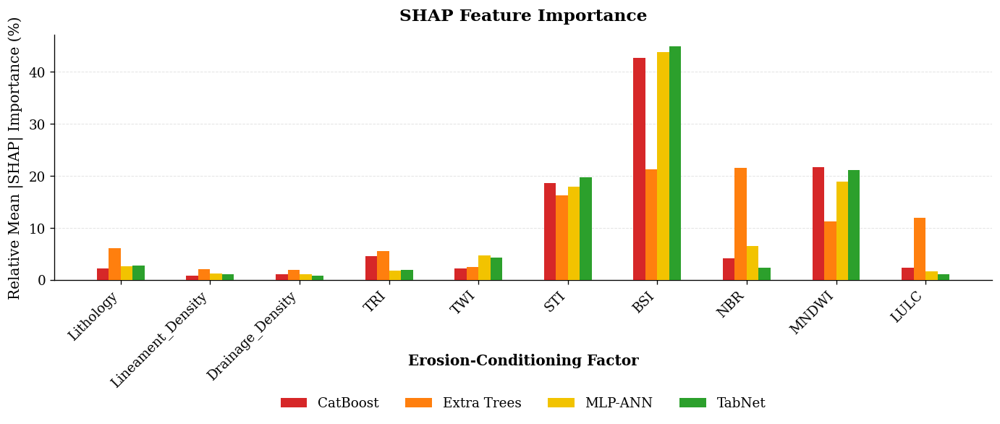

Saved PNG:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/Cross_Model_Relative_SHAP_Feature_Importance.png
Saved TIFF:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/Cross_Model_Relative_SHAP_Feature_Importance.tif


In [14]:
# ============================================================
# CROSS-MODEL SHAP FEATURE IMPORTANCE BAR CHART
# Models: CatBoost, Extra Trees, MLP-ANN, TabNet
# Reads SHAP importance outputs already created by Cell 11
# Output: grouped bar chart + CSV table
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ------------------------------------------------------------
# 1. Output folders
# ------------------------------------------------------------
if "EXPLAIN_DIR" not in globals():
    EXPLAIN_DIR = Path(
        "/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs"
    )

if "PLOT_DIR" not in globals():
    PLOT_DIR = EXPLAIN_DIR

EXPLAIN_DIR = Path(EXPLAIN_DIR)
PLOT_DIR = Path(PLOT_DIR)

EXPLAIN_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Feature names in the strict study order
# ------------------------------------------------------------
DEFAULT_FEATURES = [
    "Lithology",
    "Lineament_Density",
    "Drainage_Density",
    "TRI",
    "TWI",
    "STI",
    "BSI",
    "NBR",
    "MNDWI",
    "LULC"
]

if "FEATURES" in globals():
    feature_names = list(FEATURES)
else:
    feature_names = DEFAULT_FEATURES

print("Feature order used:")
print(feature_names)


# ------------------------------------------------------------
# 3. Model order, display labels, and colors
# ------------------------------------------------------------
MODEL_ORDER = [
    "CatBoost",
    "ExtraTrees",
    "MLP_ANN",
    "TabNet"
]

MODEL_LABELS = {
    "CatBoost": "CatBoost",
    "ExtraTrees": "Extra Trees",
    "MLP_ANN": "MLP-ANN",
    "TabNet": "TabNet"
}

MODEL_COLORS = {
    "CatBoost": "#D62728",     # red
    "ExtraTrees": "#FF7F0E",   # orange
    "MLP_ANN": "#F2C300",      # strong golden-yellow
    "TabNet": "#2CA02C"        # green
}

MODEL_NAME_ALIASES = {
    "CatBoost": "CatBoost",
    "ExtraTrees": "ExtraTrees",
    "Extra Trees": "ExtraTrees",
    "Extra_Trees": "ExtraTrees",
    "MLP_ANN": "MLP_ANN",
    "MLP-ANN": "MLP_ANN",
    "MLP ANN": "MLP_ANN",
    "TabNet": "TabNet"
}


# ------------------------------------------------------------
# 4. Load SHAP importance table
# ------------------------------------------------------------
combined_csv = (
    EXPLAIN_DIR /
    "All_Models_SHAP_Importance_ModelLevel_All10Predictors.csv"
)

if combined_csv.exists():

    shap_importance = pd.read_csv(combined_csv)

    print("Loaded combined SHAP importance table:")
    print(combined_csv)

else:

    print("Combined SHAP importance table not found.")
    print("Trying to rebuild it from model-specific SHAP importance files...")

    shap_rows = []

    for model_name in MODEL_ORDER:

        model_csv = (
            EXPLAIN_DIR /
            model_name /
            f"{model_name}_SHAP_Importance_ModelLevel_All10Predictors.csv"
        )

        if not model_csv.exists():
            raise FileNotFoundError(
                f"Missing SHAP importance file for {model_name}:\n"
                f"{model_csv}\n\n"
                "Run the model-level SHAP explainability cell first, then run this cell again."
            )

        temp = pd.read_csv(model_csv)

        if "Model" not in temp.columns:
            temp["Model"] = model_name

        shap_rows.append(temp)

    shap_importance = pd.concat(
        shap_rows,
        ignore_index=True
    )

    shap_importance.to_csv(
        combined_csv,
        index=False
    )

    print("Rebuilt and saved combined SHAP table:")
    print(combined_csv)


# ------------------------------------------------------------
# 5. Standardize column names
# ------------------------------------------------------------
required_cols = [
    "Model",
    "Feature",
    "MeanAbsSHAP_ModelLevel_SusceptibilityScore"
]

missing_cols = [
    c for c in required_cols
    if c not in shap_importance.columns
]

if missing_cols:
    raise ValueError(
        "Missing required columns in SHAP importance table: "
        + str(missing_cols)
    )

shap_importance = shap_importance[required_cols].copy()

shap_importance["Model"] = (
    shap_importance["Model"]
    .astype(str)
    .map(lambda x: MODEL_NAME_ALIASES.get(x, x))
)

shap_importance["Feature"] = shap_importance["Feature"].astype(str)

shap_importance[
    "MeanAbsSHAP_ModelLevel_SusceptibilityScore"
] = pd.to_numeric(
    shap_importance[
        "MeanAbsSHAP_ModelLevel_SusceptibilityScore"
    ],
    errors="coerce"
)

if shap_importance[
    "MeanAbsSHAP_ModelLevel_SusceptibilityScore"
].isna().any():

    bad = shap_importance[
        shap_importance[
            "MeanAbsSHAP_ModelLevel_SusceptibilityScore"
        ].isna()
    ]

    print(bad)

    raise ValueError(
        "Some SHAP importance values are missing or non-numeric."
    )


# ------------------------------------------------------------
# 6. Create pivot table in strict feature and model order
# ------------------------------------------------------------
shap_pivot = shap_importance.pivot_table(
    index="Feature",
    columns="Model",
    values="MeanAbsSHAP_ModelLevel_SusceptibilityScore",
    aggfunc="mean"
)

shap_pivot = shap_pivot.reindex(feature_names)
shap_pivot = shap_pivot[MODEL_ORDER]

if shap_pivot.isna().any().any():

    print("SHAP pivot table contains missing values:")
    display(shap_pivot)

    raise ValueError(
        "Some features or models are missing from the SHAP importance table."
    )


# ------------------------------------------------------------
# 7. Convert to relative SHAP importance percentage per model
# ------------------------------------------------------------
relative_df = shap_pivot.copy()

for model_name in MODEL_ORDER:

    model_total = relative_df[model_name].sum()

    if model_total == 0:
        relative_df[model_name] = 0.0
    else:
        relative_df[model_name] = (
            relative_df[model_name] / model_total
        ) * 100.0


# ------------------------------------------------------------
# 8. Save relative SHAP importance table
# ------------------------------------------------------------
relative_csv = (
    EXPLAIN_DIR /
    "Cross_Model_Relative_SHAP_Feature_Importance_Percent.csv"
)

relative_df.to_csv(
    relative_csv,
    index_label="Factor"
)

print("Saved relative SHAP importance table:")
print(relative_csv)

display(relative_df.round(2))


# ------------------------------------------------------------
# 9. Font settings
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "DejaVu Serif",
        "Liberation Serif"
    ],
    "axes.unicode_minus": False
})


# ------------------------------------------------------------
# 10. Plot grouped bar chart
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(12, 6)
)

group_spacing = 1.35
bar_width = 0.18

x = np.arange(len(feature_names)) * group_spacing

offsets = {
    "CatBoost": -1.5 * bar_width,
    "ExtraTrees": -0.5 * bar_width,
    "MLP_ANN": 0.5 * bar_width,
    "TabNet": 1.5 * bar_width
}

for model_name in MODEL_ORDER:

    ax.bar(
        x + offsets[model_name],
        relative_df[model_name].values,
        width=bar_width,
        color=MODEL_COLORS[model_name],
        edgecolor="none",
        linewidth=0,
        label=MODEL_LABELS[model_name],
        zorder=3
    )


# ------------------------------------------------------------
# 11. Axis formatting
# ------------------------------------------------------------
ax.set_title(
    "SHAP Feature Importance",
    fontsize=14,
    fontweight="bold",
    pad=12
)

ax.set_xlabel(
    "Erosion-Conditioning Factor",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)

# Force x-axis label to appear above the model legend
ax.xaxis.set_label_coords(0.5, -0.30)

ax.set_ylabel(
    "Relative Mean |SHAP| Importance (%)",
    fontsize=12
)

ax.set_xticks(x)

ax.set_xticklabels(
    feature_names,
    rotation=45,
    ha="right",
    fontsize=11
)

ax.tick_params(
    axis="y",
    labelsize=11
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.6,
    alpha=0.35,
    zorder=0
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# ------------------------------------------------------------
# 12. Legend
# ------------------------------------------------------------
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.43),
    ncol=4,
    frameon=False,
    fontsize=11
)


# ------------------------------------------------------------
# 13. Save figure
# ------------------------------------------------------------
plt.subplots_adjust(
    bottom=0.43,
    top=0.90,
    left=0.08,
    right=0.98
)

png_path = (
    PLOT_DIR /
    "Cross_Model_Relative_SHAP_Feature_Importance.png"
)

tif_path = (
    PLOT_DIR /
    "Cross_Model_Relative_SHAP_Feature_Importance.tif"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    tif_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("Saved PNG:")
print(png_path)

print("Saved TIFF:")
print(tif_path)

## Cell 12 - Get SW polygons and RUSLE subwatershed statistics

In [15]:
# ============================================================
# CELL 12: GET SW POLYGONS AND RUSLE SUBWATERSHED STATISTICS
# This cell uses GEE if available, otherwise reuses existing local files.
# ============================================================

sw_gdf = None
rusle_sw_stats = None

sw_geojson = TABLE_DIR / "SW23_from_GEE.geojson"
rusle_stats_csv = TABLE_DIR / "RUSLE_Subwatershed_Statistics.csv"

def initialize_gee():
    if ee is None:
        raise ImportError("earthengine-api is not available.")
    try:
        ee.Initialize(project=GEE_PROJECT)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=GEE_PROJECT)
    print("GEE initialized.")

try:
    initialize_gee()

    sw_fc = ee.FeatureCollection(GEE_SW23_ASSET)
    if geemap is not None:
        sw_gdf = geemap.ee_to_gdf(sw_fc)
        if "OBJECTID_NUM" not in sw_gdf.columns:
            if "OBJECTID" in sw_gdf.columns:
                sw_gdf["OBJECTID_NUM"] = sw_gdf["OBJECTID"].astype(int)
            else:
                sw_gdf["OBJECTID_NUM"] = np.arange(1, len(sw_gdf) + 1)
        if "SWID" not in sw_gdf.columns:
            sw_gdf["SWID"] = sw_gdf["OBJECTID_NUM"].astype(int).apply(lambda x: f"SW{x:02d}")
        sw_gdf = sw_gdf.set_crs("EPSG:4326", allow_override=True)
        sw_gdf.to_file(sw_geojson, driver="GeoJSON")
        print("Saved SW polygons:", sw_geojson)

    rusle_img = ee.Image(GEE_RUSLE_ASSET).select(0).rename("RUSLE_value")
    stats_fc = rusle_img.reduceRegions(
        collection=sw_fc,
        reducer=ee.Reducer.mean().combine(
            reducer2=ee.Reducer.sum(),
            sharedInputs=True
        ).combine(
            reducer2=ee.Reducer.count(),
            sharedInputs=True
        ),
        scale=EXPORT_SCALE,
        crs=EXPORT_CRS,
        tileScale=8
    )

    stats_gdf = geemap.ee_to_gdf(stats_fc) if geemap is not None else None
    if stats_gdf is not None:
        if "OBJECTID_NUM" not in stats_gdf.columns:
            if "OBJECTID" in stats_gdf.columns:
                stats_gdf["OBJECTID_NUM"] = stats_gdf["OBJECTID"].astype(int)
            else:
                stats_gdf["OBJECTID_NUM"] = np.arange(1, len(stats_gdf) + 1)
        if "SWID" not in stats_gdf.columns:
            stats_gdf["SWID"] = stats_gdf["OBJECTID_NUM"].astype(int).apply(lambda x: f"SW{x:02d}")

        # common reducer output names may be mean/sum/count
        mean_col = "mean" if "mean" in stats_gdf.columns else None
        sum_col = "sum" if "sum" in stats_gdf.columns else None
        count_col = "count" if "count" in stats_gdf.columns else None

        rusle_sw_stats = pd.DataFrame({
            "SWID": stats_gdf["SWID"].astype(str),
            "OBJECTID_NUM": stats_gdf["OBJECTID_NUM"].astype(int),
            "Mean_RUSLE": stats_gdf[mean_col] if mean_col else np.nan,
            "RUSLE_Sum_RasterUnits": stats_gdf[sum_col] if sum_col else np.nan,
            "RUSLE_ValidPixelCount": stats_gdf[count_col] if count_col else np.nan
        })

        # Approx total annual loss = mean soil loss t/ha/yr * area ha
        if sw_gdf is not None:
            sw_area = sw_gdf.to_crs(EXPORT_CRS).copy()
            sw_area["SW_Area_km2"] = sw_area.geometry.area / 1e6
            rusle_sw_stats = rusle_sw_stats.merge(
                sw_area[["SWID", "SW_Area_km2"]],
                on="SWID",
                how="left"
            )
            rusle_sw_stats["Total_RUSLE_Loss_tyr"] = rusle_sw_stats["Mean_RUSLE"] * rusle_sw_stats["SW_Area_km2"] * 100.0

        rusle_sw_stats.to_csv(rusle_stats_csv, index=False)
        print("Saved RUSLE SW stats:", rusle_stats_csv)

except Exception as e:
    print("GEE/SW/RUSLE fetch failed:", repr(e))

# Fallback to local files
if sw_gdf is None:
    if sw_geojson.exists():
        sw_gdf = gpd.read_file(sw_geojson)
        print("Loaded local SW polygons:", sw_geojson)
    else:
        print("SW polygons not available. Maps/ranking will continue without SW overlay where necessary.")

if rusle_sw_stats is None:
    if rusle_stats_csv.exists():
        rusle_sw_stats = pd.read_csv(rusle_stats_csv)
        print("Loaded local RUSLE SW stats:", rusle_stats_csv)
    else:
        print("RUSLE SW stats not available. Ranking will omit RUSLE term.")

if sw_gdf is not None:
    if "OBJECTID_NUM" not in sw_gdf.columns:
        if "OBJECTID" in sw_gdf.columns:
            sw_gdf["OBJECTID_NUM"] = sw_gdf["OBJECTID"].astype(int)
        else:
            sw_gdf["OBJECTID_NUM"] = np.arange(1, len(sw_gdf) + 1)
    if "SWID" not in sw_gdf.columns:
        sw_gdf["SWID"] = sw_gdf["OBJECTID_NUM"].astype(int).apply(lambda x: f"SW{x:02d}")
    sw_gdf["SWID"] = sw_gdf["SWID"].astype(str)
    display(sw_gdf[["SWID", "OBJECTID_NUM"]].head())

if rusle_sw_stats is not None:
    display(rusle_sw_stats.head())

print("Cell 12 completed.")


GEE initialized.
Saved SW polygons: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/SW23_from_GEE.geojson
Saved RUSLE SW stats: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/RUSLE_Subwatershed_Statistics.csv


,SWID,OBJECTID_NUM
0,SW23,23
1,SW22,22
2,SW21,21
3,SW20,20
4,SW19,19


,SWID,OBJECTID_NUM,Mean_RUSLE,RUSLE_Sum_RasterUnits,RUSLE_ValidPixelCount,SW_Area_km2,Total_RUSLE_Loss_tyr
0,SW23,23,128.198351,1.081927e+07,85193,75.956027,973743.740427
1,SW22,22,122.097331,4.722859e+06,39491,34.814826,425079.736551
2,SW21,21,77.731054,1.034484e+07,134662,119.779394,931057.853266
3,SW20,20,111.210477,7.115275e+06,64762,57.583270,640386.293231
4,SW19,19,120.400471,3.701432e+06,31272,27.668997,333136.032392


Cell 12 completed.


## Cell 13 - Build strict 10-predictor raster stack from individual GeoTIFFs

Lithology: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Lithology.tif
Lineament_Density: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Copy of Mandakini_Lineament_Density_km_per_km2.tif
Drainage_Density: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Copy of Mandakini_Drainage_Density_km_per_km2.tif
TRI: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/TRI.tif
TWI: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Copy of Mandakini_TWI.tif
STI: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/STI.tif
BSI: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Copy of Mandakini_BSI.tif
NBR: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Copy of Mandakini_NBR.tif
MNDWI: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Copy of Mandakini_MNDWI.tif
LULC: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Mandakini_23SW_LULC_2025.tif
Reference raster: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/TRI.tif
Using existing strict predictor stack: /content/drive/MyDrive

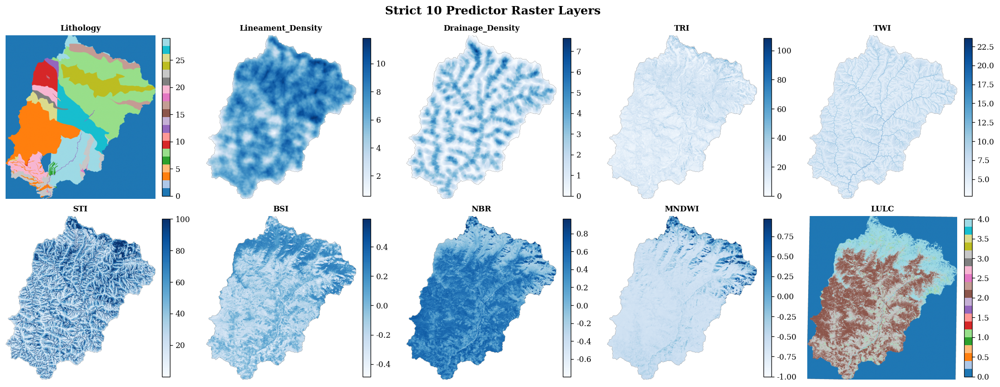

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/Strict_10_Predictor_Raster_Layers_Preview.png
Cell 13 completed.


In [16]:
# ============================================================
# CELL 13: BUILD STRICT 10-PREDICTOR RASTER STACK FROM INDIVIDUAL GEOTIFFS
# Categorical rasters use nearest-neighbour alignment.
# Continuous rasters use bilinear alignment.
# Output band descriptions use strict predictor names.
# ============================================================

def find_raster_for_feature(feature):
    patterns = {
        "Lithology": [
            "Lithology.tif",
            "*Lithology*.tif",
            "*Lithology_ID_Raster_30m*.tif"
        ],
        "Lineament_Density": [
            "Lineament_Density.tif",
            "*Lineament_Density*.tif",
            "*Lineament_Density_km_per_km2*.tif"
        ],
        "Drainage_Density": [
            "Drainage_Density.tif",
            "*Drainage_Density*.tif",
            "*Drainage_Density_km_per_km2*.tif"
        ],
        "TRI": ["TRI.tif", "*TRI*.tif"],
        "TWI": ["TWI.tif", "*TWI*.tif"],
        "STI": ["STI.tif", "*STI*.tif", "*SPI*.tif"],
        "BSI": ["BSI.tif", "*BSI*.tif"],
        "NBR": ["NBR.tif", "*NBR*.tif"],
        "MNDWI": ["MNDWI.tif", "*MNDWI*.tif"],
        "LULC": ["LULC.tif", "*LULC*.tif", "*Mandakini_23SW_LULC_2025*.tif"]
    }

    candidates = []
    for pat in patterns[feature]:
        candidates.extend(DRIVE_PROJECT_DIR.glob(pat))
        candidates.extend(DRIVE_PROJECT_DIR.glob("Copy of " + pat))

    # remove unwanted files
    clean = []
    for p in candidates:
        name = p.name.lower()
        if p.suffix.lower() not in [".tif", ".tiff"]:
            continue
        if "colour" in name or "rgb" in name or "rusle" in name:
            continue
        clean.append(p)

    clean = sorted(set(clean), key=lambda p: p.stat().st_mtime, reverse=True)
    if not clean:
        return None
    return clean[0]

raster_sources = {}
for feat in FEATURES:
    p = find_raster_for_feature(feat)
    raster_sources[feat] = p
    print(f"{feat}: {p}")

missing_rasters = [f for f, p in raster_sources.items() if p is None]
if missing_rasters:
    raise FileNotFoundError(f"Missing raster files for predictors: {missing_rasters}")

# Reference raster: use first continuous if possible
ref_path = raster_sources["TRI"] if raster_sources.get("TRI") else list(raster_sources.values())[0]
print("Reference raster:", ref_path)

stack_path = RASTER_DIR / "Predictor_Stack_10Bands_StrictNames.tif"

if stack_path.exists() and not FORCE_REDO_FULL_AREA_PREDICTION:
    print("Using existing strict predictor stack:", stack_path)
else:
    with rasterio.open(ref_path) as ref:
        ref_profile = ref.profile.copy()
        ref_crs = ref.crs
        ref_transform = ref.transform
        ref_height = ref.height
        ref_width = ref.width
        ref_nodata = ref.nodata

    stacked_arrays = []
    stack_nodata = -9999.0

    for feat in FEATURES:
        path = raster_sources[feat]
        print("Aligning:", feat, "from", path.name)

        with rasterio.open(path) as src:
            src_arr = src.read(1)
            dst_arr = np.full((ref_height, ref_width), stack_nodata, dtype=np.float32)

            resampling = Resampling.nearest if feat in CATEGORICAL_FEATURES else Resampling.bilinear

            reproject(
                source=src_arr,
                destination=dst_arr,
                src_transform=src.transform,
                src_crs=src.crs,
                src_nodata=src.nodata,
                dst_transform=ref_transform,
                dst_crs=ref_crs,
                dst_nodata=stack_nodata,
                resampling=resampling
            )

            if feat in CATEGORICAL_FEATURES:
                dst_arr = np.rint(dst_arr).astype(np.float32)

            stacked_arrays.append(dst_arr)

    out_profile = ref_profile.copy()
    out_profile.update(
        driver="GTiff",
        count=len(FEATURES),
        dtype="float32",
        nodata=stack_nodata,
        compress="lzw"
    )

    with rasterio.open(stack_path, "w", **out_profile) as dst:
        for i, (feat, arr) in enumerate(zip(FEATURES, stacked_arrays), start=1):
            dst.write(arr.astype(np.float32), i)
            dst.set_band_description(i, feat)

    print("Saved strict predictor stack:", stack_path)

# Preview all 10 layers
with rasterio.open(stack_path) as src:
    arr = src.read()
    desc = list(src.descriptions)
    print("Stack shape:", arr.shape)
    print("Band descriptions:", desc)

    fig, axes = plt.subplots(2, 5, figsize=(18, 7))
    axes = axes.flatten()
    for i, feat in enumerate(FEATURES):
        band = arr[i]
        nd = src.nodata
        show_arr = np.where(band == nd, np.nan, band)

        ax = axes[i]
        if feat in CATEGORICAL_FEATURES:
            im = ax.imshow(show_arr, cmap="tab20")
        else:
            im = ax.imshow(show_arr, cmap="Blues")
        ax.set_title(feat, fontsize=10, fontweight="bold")
        ax.set_axis_off()
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    fig.suptitle("Strict 10 Predictor Raster Layers", fontsize=15, fontweight="bold")
    fig.tight_layout()
    out_preview = PLOT_DIR / "Strict_10_Predictor_Raster_Layers_Preview.png"
    fig.savefig(out_preview, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", out_preview)

print("Cell 13 completed.")


# CELL 13 B: BUILD STRICT 10-PREDICTOR RASTER STACK FROM INDIVIDUAL GEOTIFFS

Raster sources detected:
Lithology: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Lithology.tif
Lineament_Density: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Copy of Mandakini_Lineament_Density_km_per_km2.tif
Drainage_Density: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Copy of Mandakini_Drainage_Density_km_per_km2.tif
TRI: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/TRI.tif
TWI: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Copy of Mandakini_TWI.tif
STI: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/STI.tif
BSI: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Copy of Mandakini_BSI.tif
NBR: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Copy of Mandakini_NBR.tif
MNDWI: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Copy of Mandakini_MNDWI.tif
LULC: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Mandakini_23SW_LULC_2025.tif

Reference raster: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/TRI.tif
Using existing strict predictor sta

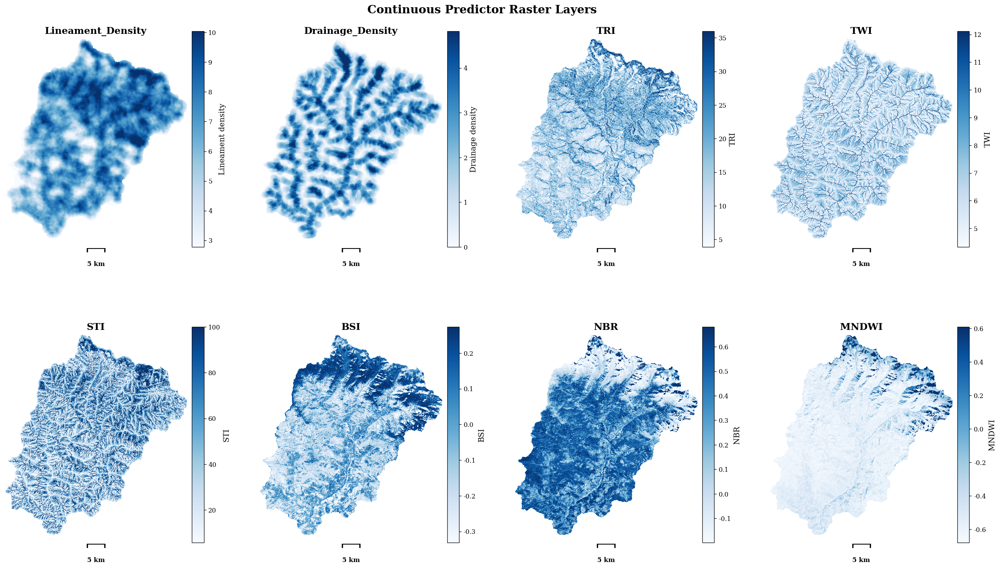

Saved continuous predictor image: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/Continuous_8_Predictor_Raster_Layers.png
Lithology classes displayed: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
LULC classes displayed: [0, 1, 2, 3, 4]


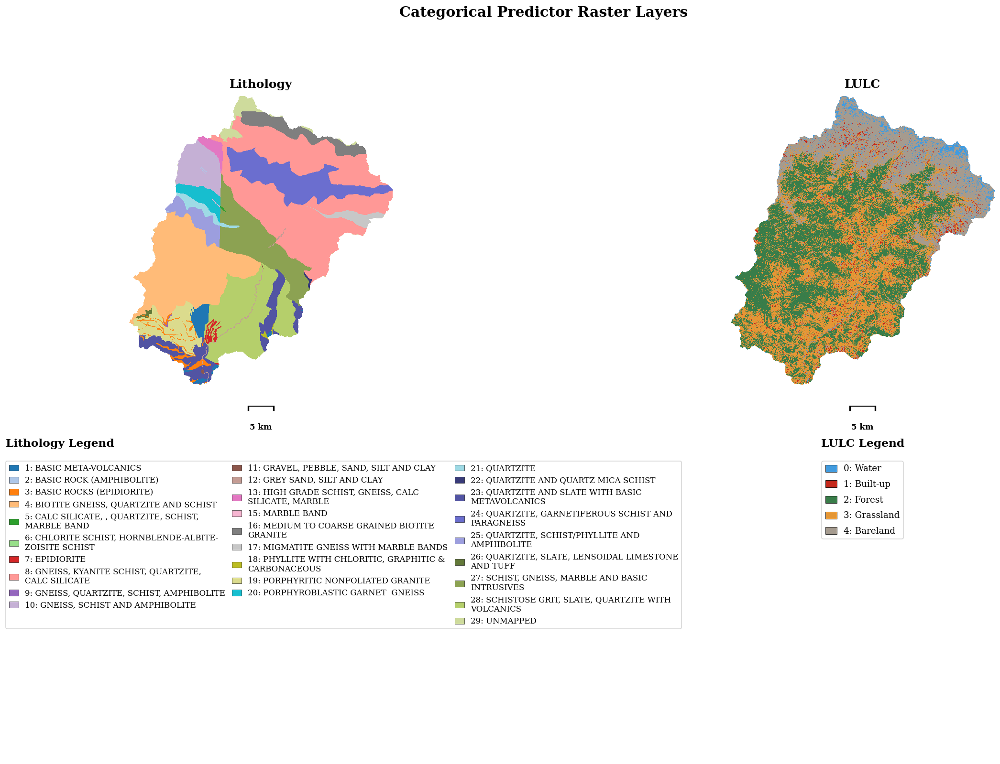

Saved categorical predictor image: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/Categorical_Predictor_Raster_Layers.png

Cell 13 completed successfully.


In [17]:
# ============================================================
# CELL 13: BUILD STRICT 10-PREDICTOR RASTER STACK FROM INDIVIDUAL GEOTIFFS
# AND EXPORT TWO CLEAN PREVIEW FIGURES:
#   1. 8 continuous predictors in one PNG
#   2. 2 categorical predictors in one separate PNG
#
# Categorical rasters use nearest-neighbour alignment.
# Continuous rasters use bilinear alignment.
# Output band descriptions use strict predictor names.
#
# SCALE REQUIREMENTS:
# - Every map has a 5 km scale.
# - Scale bars are placed BELOW the raster maps.
# - Scale bars do NOT cross or cover any raster pixels.
# - Continuous-map color bars remain at the right of each map.
# - LULC map, scale and legend remain vertically aligned.
# ============================================================

from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import rasterio

from rasterio.warp import reproject
from rasterio.enums import Resampling

import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib import cm


# ------------------------------------------------------------
# 1. Predictor definitions
# ------------------------------------------------------------

FEATURES = [
    "Lithology",
    "Lineament_Density",
    "Drainage_Density",
    "TRI",
    "TWI",
    "STI",
    "BSI",
    "NBR",
    "MNDWI",
    "LULC"
]


CATEGORICAL_FEATURES = [
    "Lithology",
    "LULC"
]


CONTINUOUS_FEATURES = [
    "Lineament_Density",
    "Drainage_Density",
    "TRI",
    "TWI",
    "STI",
    "BSI",
    "NBR",
    "MNDWI"
]


PLOT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


RASTER_DIR.mkdir(
    parents=True,
    exist_ok=True
)


if "FORCE_REDO_FULL_AREA_PREDICTION" not in globals():

    FORCE_REDO_FULL_AREA_PREDICTION = False


# ------------------------------------------------------------
# 2. Raster file finder
# ------------------------------------------------------------

def find_raster_for_feature(feature):

    patterns = {

        "Lithology": [
            "Lithology.tif",
            "*Lithology*.tif",
            "*Lithology_ID_Raster_30m*.tif"
        ],

        "Lineament_Density": [
            "Lineament_Density.tif",
            "*Lineament_Density*.tif",
            "*Lineament_Density_km_per_km2*.tif"
        ],

        "Drainage_Density": [
            "Drainage_Density.tif",
            "*Drainage_Density*.tif",
            "*Drainage_Density_km_per_km2*.tif"
        ],

        "TRI": [
            "TRI.tif",
            "*TRI*.tif"
        ],

        "TWI": [
            "TWI.tif",
            "*TWI*.tif"
        ],

        "STI": [
            "STI.tif",
            "*STI*.tif",
            "*SPI*.tif"
        ],

        "BSI": [
            "BSI.tif",
            "*BSI*.tif"
        ],

        "NBR": [
            "NBR.tif",
            "*NBR*.tif"
        ],

        "MNDWI": [
            "MNDWI.tif",
            "*MNDWI*.tif"
        ],

        "LULC": [
            "LULC.tif",
            "*LULC*.tif",
            "*Mandakini_23SW_LULC_2025*.tif"
        ]
    }


    candidates = []


    for pat in patterns[feature]:

        candidates.extend(
            DRIVE_PROJECT_DIR.glob(
                pat
            )
        )

        candidates.extend(
            DRIVE_PROJECT_DIR.glob(
                "Copy of " + pat
            )
        )


    clean = []


    for p in candidates:

        name = p.name.lower()


        if p.suffix.lower() not in [
            ".tif",
            ".tiff"
        ]:

            continue


        if (
            "colour" in name
            or "color" in name
            or "rgb" in name
            or "rusle" in name
        ):

            continue


        clean.append(
            p
        )


    clean = sorted(

        set(clean),

        key=lambda p: p.stat().st_mtime,

        reverse=True
    )


    return (
        clean[0]
        if clean
        else None
    )


# ------------------------------------------------------------
# 3. Detect all raster sources
# ------------------------------------------------------------

raster_sources = {}


print(
    "Raster sources detected:"
)


for feat in FEATURES:

    p = find_raster_for_feature(
        feat
    )


    raster_sources[
        feat
    ] = p


    print(
        f"{feat}: {p}"
    )


missing_rasters = [

    f

    for f, p in raster_sources.items()

    if p is None
]


if missing_rasters:

    raise FileNotFoundError(

        f"Missing raster files for predictors: "
        f"{missing_rasters}"
    )


# ------------------------------------------------------------
# 4. Reference raster
# ------------------------------------------------------------

ref_path = (

    raster_sources[
        "TRI"
    ]

    if raster_sources.get(
        "TRI"
    )

    else list(
        raster_sources.values()
    )[0]
)


print(
    "\nReference raster:",
    ref_path
)


stack_path = (

    RASTER_DIR /

    "Predictor_Stack_10Bands_StrictNames.tif"
)


# ------------------------------------------------------------
# 5. Build aligned 10-band stack
# ------------------------------------------------------------

if (

    stack_path.exists()

    and not FORCE_REDO_FULL_AREA_PREDICTION

):


    print(
        "Using existing strict predictor stack:",
        stack_path
    )


else:


    with rasterio.open(
        ref_path
    ) as ref:


        ref_profile = (
            ref.profile.copy()
        )


        ref_crs = (
            ref.crs
        )


        ref_transform = (
            ref.transform
        )


        ref_height = (
            ref.height
        )


        ref_width = (
            ref.width
        )


    stack_nodata = -9999.0


    stacked_arrays = []


    for feat in FEATURES:


        src_path = (
            raster_sources[
                feat
            ]
        )


        print(
            "Aligning:",
            feat,
            "from",
            src_path.name
        )


        with rasterio.open(
            src_path
        ) as src:


            src_arr = (
                src.read(
                    1
                )
            )


            dst_arr = np.full(

                (
                    ref_height,
                    ref_width
                ),

                stack_nodata,

                dtype=np.float32
            )


            resampling_method = (

                Resampling.nearest

                if feat in CATEGORICAL_FEATURES

                else Resampling.bilinear
            )


            reproject(

                source=src_arr,

                destination=dst_arr,

                src_transform=
                    src.transform,

                src_crs=
                    src.crs,

                src_nodata=
                    src.nodata,

                dst_transform=
                    ref_transform,

                dst_crs=
                    ref_crs,

                dst_nodata=
                    stack_nodata,

                resampling=
                    resampling_method
            )


            if feat in CATEGORICAL_FEATURES:


                dst_arr = np.rint(
                    dst_arr
                ).astype(
                    np.float32
                )


            stacked_arrays.append(
                dst_arr
            )


    out_profile = (
        ref_profile.copy()
    )


    out_profile.update(

        driver="GTiff",

        count=len(
            FEATURES
        ),

        dtype="float32",

        nodata=
            stack_nodata,

        compress="lzw"
    )


    with rasterio.open(

        stack_path,

        "w",

        **out_profile

    ) as dst:


        for i, (
            feat,
            arr
        ) in enumerate(

            zip(
                FEATURES,
                stacked_arrays
            ),

            start=1
        ):


            dst.write(

                arr.astype(
                    np.float32
                ),

                i
            )


            dst.set_band_description(
                i,
                feat
            )


    print(
        "Saved strict predictor stack:",
        stack_path
    )


# ------------------------------------------------------------
# 6. Read the stack
# ------------------------------------------------------------

with rasterio.open(
    stack_path
) as src:


    stack_arr = (
        src.read()
    )


    stack_desc = list(
        src.descriptions
    )


    stack_nodata = (
        src.nodata
    )


    # Needed for accurate 5 km scale bars
    stack_transform = (
        src.transform
    )


    stack_width = (
        src.width
    )


    stack_height = (
        src.height
    )


    stack_crs = (
        src.crs
    )


print(
    "\nStack shape:",
    stack_arr.shape
)


print(
    "Band descriptions:",
    stack_desc
)


print(
    "Stack CRS:",
    stack_crs
)


print(
    "Pixel size:",
    (
        abs(
            stack_transform.a
        ),
        abs(
            stack_transform.e
        )
    )
)


band_dict = {}


for i, feat in enumerate(
    stack_desc
):


    band = (
        stack_arr[
            i
        ]
        .astype(
            np.float32
        )
    )


    if stack_nodata is not None:


        band = np.where(

            band == stack_nodata,

            np.nan,

            band
        )


    band_dict[
        feat
    ] = band


# ------------------------------------------------------------
# 7. Helper functions and lookup labels
# ------------------------------------------------------------

def get_display_limits(arr):


    vals = arr[
        np.isfinite(
            arr
        )
    ]


    if vals.size == 0:

        return 0, 1


    vmin = np.nanpercentile(
        vals,
        2
    )


    vmax = np.nanpercentile(
        vals,
        98
    )


    if np.isclose(
        vmin,
        vmax
    ):


        vmin = np.nanmin(
            vals
        )


        vmax = np.nanmax(
            vals
        )


    if np.isclose(
        vmin,
        vmax
    ):


        vmax = (
            vmin + 1
        )


    return vmin, vmax


def wrap_label(
    text,
    width=38
):


    text = str(
        text
    )


    return "\n".join(

        textwrap.wrap(

            text,

            width=width
        )
    )


# ------------------------------------------------------------
# 5 KM SCALE-BAR HELPER
#
# The scale bar is placed on a separate axis BELOW each map.
# It does not cross or cover any raster pixels.
# ------------------------------------------------------------

def draw_5km_scalebar(
    ax,
    raster_width_pixels,
    raster_transform,
    length_km=5
):


    ax.set_xlim(
        0,
        1
    )


    ax.set_ylim(
        0,
        1
    )


    ax.axis(
        "off"
    )


    pixel_width_m = abs(
        raster_transform.a
    )


    raster_width_m = (

        raster_width_pixels *

        pixel_width_m
    )


    requested_length_m = (

        length_km *

        1000.0
    )


    scale_fraction = (

        requested_length_m /

        raster_width_m
    )


    scale_fraction = min(
        scale_fraction,
        0.80
    )


    x_center = 0.50


    x0 = (

        x_center -

        scale_fraction / 2
    )


    x1 = (

        x_center +

        scale_fraction / 2
    )


    # Scale line position
    y0 = 1.0


    tick_height = 0.16


    ax.plot(

        [
            x0,
            x1
        ],

        [
            y0,
            y0
        ],

        color="black",

        linewidth=2.0,

        solid_capstyle="butt"
    )


    ax.plot(

        [
            x0,
            x0
        ],

        [
            y0 - tick_height,
            y0 + tick_height
        ],

        color="black",

        linewidth=2.0
    )


    ax.plot(

        [
            x1,
            x1
        ],

        [
            y0 - tick_height,
            y0 + tick_height
        ],

        color="black",

        linewidth=2.0
    )


    ax.text(

        x_center,

        0.25,

        f"{length_km} km",

        ha="center",

        va="center",

        fontsize=10,

        fontweight="bold",

        color="black"
    )


# ------------------------------------------------------------
# Lithology class labels
# ------------------------------------------------------------

DEFAULT_LITHOLOGY_LABELS = {

    1: "BASIC META-VOLCANICS",

    2: "BASIC ROCK (AMPHIBOLITE)",

    3: "BASIC ROCKS (EPIDIORITE)",

    4: "BIOTITE GNEISS, QUARTZITE AND SCHIST",

    5: "CALC SILICATE, QUARTZITE, SCHIST, MARBLE BAND",

    6: "CHLORITE SCHIST, HORNBLENDE-ALBITE-ZOISITE SCHIST",

    7: "EPIDIORITE",

    8: "GNEISS, KYANITE SCHIST, QUARTZITE, CALC SILICATE",

    9: "GNEISS, QUARTZITE, SCHIST, AMPHIBOLITE",

    10: "GNEISS, SCHIST AND AMPHIBOLITE",

    11: "GRAVEL, PEBBLE, SAND, SILT AND CLAY",

    12: "GREY SAND, SILT AND CLAY",

    13: "HIGH GRADE SCHIST, GNEISS, CALC SILICATE, MARBLE",

    14: "LIMESTONE, DOLOMITE, SHALE AND CHERTY QUARTZITE",

    15: "MARBLE BAND",

    16: "MEDIUM TO COARSE GRAINED BIOTITE GRANITE",

    17: "MIGMATITE GNEISS WITH MARBLE BANDS",

    18: "PHYLLITE WITH CHLORITIC, GRAPHITIC & CARBONACEOUS",

    19: "PORPHYRITIC NONFOLIATED GRANITE",

    20: "PORPHYROBLASTIC GARNET GNEISS",

    21: "QUARTZITE",

    22: "QUARTZITE AND QUARTZ MICA SCHIST",

    23: "QUARTZITE AND SLATE WITH BASIC METAVOLCANICS",

    24: "QUARTZITE, GARNETIFEROUS SCHIST AND PARAGNEISS",

    25: "QUARTZITE, SCHIST/PHYLLITE AND AMPHIBOLITE",

    26: "QUARTZITE, SLATE, LENSOIDAL LIMESTONE AND TUFF",

    27: "SCHIST, GNEISS, MARBLE AND BASIC INTRUSIVES",

    28: "SCHISTOSE GRIT, SLATE, QUARTZITE WITH VOLCANICS",

    29: "UNMAPPED"
}


# ------------------------------------------------------------
# LULC classes
# ------------------------------------------------------------

LULC_LABELS = {

    0: "Water",

    1: "Built-up",

    2: "Forest",

    3: "Grassland",

    4: "Bareland"
}


LULC_COLORS = {

    0: "#419BDF",

    1: "#C4281B",

    2: "#397D49",

    3: "#E49635",

    4: "#A59B8F"
}


# ------------------------------------------------------------
# Try to override lithology labels from lookup CSV
# ------------------------------------------------------------

def load_lithology_lookup():


    lookup_candidates = [

        DRIVE_PROJECT_DIR /
        "Mandakini_Lithology_ID_Lookup_Table.csv",

        DRIVE_PROJECT_DIR /
        "Mandakini_Lithology_Lookup_Table.csv",

        DRIVE_PROJECT_DIR /
        "Lithology_ID_Lookup_Table.csv"
    ]


    lookup_candidates += list(

        DRIVE_PROJECT_DIR.glob(
            "*Lithology*Lookup*.csv"
        )
    )


    lookup_candidates = [

        p

        for p in lookup_candidates

        if p.exists()
    ]


    if len(
        lookup_candidates
    ) == 0:


        print(
            "No lithology lookup CSV found. "
            "Using built-in lithology labels."
        )


        return (
            DEFAULT_LITHOLOGY_LABELS.copy()
        )


    lookup_path = (
        lookup_candidates[
            0
        ]
    )


    print(
        "Using lithology lookup table:",
        lookup_path
    )


    lookup_df = pd.read_csv(
        lookup_path
    )


    cols_lower = {

        c.lower(): c

        for c in lookup_df.columns
    }


    code_col = None


    for possible in [

        "lithology",

        "lithology_id",

        "id",

        "code",

        "class_id",

        "litho_id"
    ]:


        if possible in cols_lower:


            code_col = (
                cols_lower[
                    possible
                ]
            )


            break


    name_col = None


    for possible in [

        "lithologic",

        "lithology_name",

        "name",

        "class_name",

        "unit_name"
    ]:


        if possible in cols_lower:


            name_col = (
                cols_lower[
                    possible
                ]
            )


            break


    if (
        code_col is None
        or name_col is None
    ):


        print(
            "Could not detect lookup code/name columns. "
            "Using built-in lithology labels."
        )


        return (
            DEFAULT_LITHOLOGY_LABELS.copy()
        )


    lookup_df[
        code_col
    ] = pd.to_numeric(

        lookup_df[
            code_col
        ],

        errors="coerce"
    )


    lookup_df = (

        lookup_df.dropna(
            subset=[
                code_col
            ]
        )
    )


    lookup_df[
        code_col
    ] = (

        lookup_df[
            code_col
        ]

        .astype(
            int
        )
    )


    out = (
        DEFAULT_LITHOLOGY_LABELS.copy()
    )


    for _, row in lookup_df.iterrows():


        out[

            int(
                row[
                    code_col
                ]
            )

        ] = str(

            row[
                name_col
            ]
        )


    return out


LITHOLOGY_LABELS = (
    load_lithology_lookup()
)


# ============================================================
# 8. CONTINUOUS PREDICTORS PREVIEW
#
# Each of the 8 predictor panels contains:
#
#   Map | Color bar
#   5 km scale | blank
#
# The scale is below the map and does not cover the raster.
# ============================================================

continuous_png = (

    PLOT_DIR /

    "Continuous_8_Predictor_Raster_Layers.png"
)


continuous_colorbar_labels = {

    "Lineament_Density":
        "Lineament density",

    "Drainage_Density":
        "Drainage density",

    "TRI":
        "TRI",

    "TWI":
        "TWI",

    "STI":
        "STI",

    "BSI":
        "BSI",

    "NBR":
        "NBR",

    "MNDWI":
        "MNDWI"
}


fig = plt.figure(
    figsize=(22, 13)
)


outer_gs = fig.add_gridspec(

    nrows=2,

    ncols=4,

    hspace=0.24,

    wspace=0.28
)


for panel_index, feat in enumerate(
    CONTINUOUS_FEATURES
):


    row = (
        panel_index // 4
    )


    col = (
        panel_index % 4
    )


    # --------------------------------------------------------
    # Nested layout for EACH continuous map
    #
    # Top-left  = map
    # Top-right = color bar
    # Bottom-left = 5 km scale
    # Bottom-right = blank
    # --------------------------------------------------------

    panel_gs = (

        outer_gs[
            row,
            col
        ]

        .subgridspec(

            nrows=2,

            ncols=2,

            height_ratios=[
                1.0,
                0.10
            ],

            width_ratios=[
                1.0,
                0.065
            ],

            hspace=0.01,

            wspace=0.05
        )
    )


    ax_map = fig.add_subplot(
        panel_gs[
            0,
            0
        ]
    )


    ax_cbar = fig.add_subplot(
        panel_gs[
            0,
            1
        ]
    )


    ax_scale = fig.add_subplot(
        panel_gs[
            1,
            0
        ]
    )


    ax_blank = fig.add_subplot(
        panel_gs[
            1,
            1
        ]
    )


    ax_blank.axis(
        "off"
    )


    arr = band_dict[
        feat
    ]


    vmin, vmax = (
        get_display_limits(
            arr
        )
    )


    im = ax_map.imshow(

        arr,

        cmap="Blues",

        vmin=vmin,

        vmax=vmax,

        interpolation="nearest"
    )


    ax_map.set_title(

        feat,

        fontsize=15,

        fontweight="bold",

        pad=8
    )


    ax_map.set_axis_off()


    # --------------------------------------------------------
    # Color bar
    # --------------------------------------------------------

    cb = fig.colorbar(

        im,

        cax=ax_cbar
    )


    cb.ax.set_ylabel(

        continuous_colorbar_labels.get(
            feat,
            feat
        ),

        rotation=90,

        fontsize=12
    )


    cb.ax.tick_params(
        labelsize=10
    )


    # --------------------------------------------------------
    # 5 km scale BELOW the map
    # --------------------------------------------------------

    draw_5km_scalebar(

        ax_scale,

        raster_width_pixels=
            stack_width,

        raster_transform=
            stack_transform,

        length_km=5
    )


fig.suptitle(

    "Continuous Predictor Raster Layers",

    fontsize=18,

    fontweight="bold",

    y=0.985
)


fig.subplots_adjust(

    left=0.025,

    right=0.985,

    bottom=0.04,

    top=0.94
)


fig.savefig(

    continuous_png,

    dpi=300,

    bbox_inches="tight"
)


plt.show()


plt.close(
    fig
)


print(
    "Saved continuous predictor image:",
    continuous_png
)


# ============================================================
# 9. CATEGORICAL PREDICTORS PREVIEW
#
# Row 1:
#   Lithology map | LULC map
#
# Row 2:
#   5 km scale    | 5 km scale
#
# Row 3:
#   Lithology legend | LULC legend
#
# Scale bars do not cross either raster.
# ============================================================

categorical_png = (

    PLOT_DIR /

    "Categorical_Predictor_Raster_Layers.png"
)


lith_arr = (

    band_dict[
        "Lithology"
    ]

    .copy()
)


lulc_arr = (

    band_dict[
        "LULC"
    ]

    .copy()
)


# ------------------------------------------------------------
# Study-area mask
#
# Lithology classes 1–29 define the actual area footprint.
# Genuine LULC Water = 0 inside the area is retained.
# ------------------------------------------------------------

study_area_mask = (

    np.isfinite(
        lith_arr
    )

    &

    (
        lith_arr >= 1
    )

    &

    (
        lith_arr <= 29
    )
)


lith_arr = np.where(

    study_area_mask,

    lith_arr,

    np.nan
)


lulc_arr = np.where(

    study_area_mask,

    lulc_arr,

    np.nan
)


lulc_arr = np.where(

    (
        lulc_arr >= 0
    )

    &

    (
        lulc_arr <= 4
    ),

    lulc_arr,

    np.nan
)


lith_vals = sorted(

    [

        int(v)

        for v in np.unique(

            lith_arr[
                np.isfinite(
                    lith_arr
                )
            ]
        )
    ]
)


lulc_vals = sorted(

    [

        int(v)

        for v in np.unique(

            lulc_arr[
                np.isfinite(
                    lulc_arr
                )
            ]
        )
    ]
)


print(
    "Lithology classes displayed:",
    lith_vals
)


print(
    "LULC classes displayed:",
    lulc_vals
)


# ------------------------------------------------------------
# Lithology colormap
# ------------------------------------------------------------

n_lith = max(
    len(
        lith_vals
    ),
    1
)


base_colors = []


for cmap_name in [

    "tab20",

    "tab20b",

    "tab20c"
]:

    cmap_obj = cm.get_cmap(
        cmap_name
    )


    base_colors.extend(

        [

            cmap_obj(i)

            for i in range(
                cmap_obj.N
            )
        ]
    )


if n_lith > len(
    base_colors
):


    extra = cm.get_cmap(

        "gist_ncar",

        n_lith
    )


    lith_colors = [

        extra(i)

        for i in range(
            n_lith
        )
    ]


else:


    lith_colors = (

        base_colors[
            :n_lith
        ]
    )


lith_cmap = ListedColormap(
    lith_colors
)


lith_cmap.set_bad(

    color="white",

    alpha=1.0
)


lith_bounds = np.arange(

    -0.5,

    n_lith + 0.5,

    1
)


lith_norm = BoundaryNorm(

    lith_bounds,

    lith_cmap.N
)


lith_plot = np.full(

    lith_arr.shape,

    np.nan,

    dtype=np.float32
)


lith_code_to_idx = {}


for idx, code in enumerate(
    lith_vals
):


    lith_code_to_idx[
        code
    ] = idx


    lith_plot[

        np.isclose(
            lith_arr,
            code
        )

    ] = idx


# ------------------------------------------------------------
# LULC colormap
# ------------------------------------------------------------

lulc_colors = [

    LULC_COLORS.get(
        v,
        "#bdbdbd"
    )

    for v in lulc_vals
]


lulc_cmap = ListedColormap(
    lulc_colors
)


lulc_cmap.set_bad(

    color="white",

    alpha=1.0
)


lulc_bounds = np.arange(

    -0.5,

    len(
        lulc_vals
    ) + 0.5,

    1
)


lulc_norm = BoundaryNorm(

    lulc_bounds,

    lulc_cmap.N
)


lulc_plot = np.full(

    lulc_arr.shape,

    np.nan,

    dtype=np.float32
)


lulc_code_to_idx = {}


for idx, code in enumerate(
    lulc_vals
):


    lulc_code_to_idx[
        code
    ] = idx


    lulc_plot[

        np.isclose(
            lulc_arr,
            code
        )

    ] = idx


# ------------------------------------------------------------
# Figure layout
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(25, 15)
)


gs = fig.add_gridspec(

    nrows=3,

    ncols=2,

    height_ratios=[
        1.0,
        0.10,
        1.05
    ],

    width_ratios=[
        1.0,
        1.0
    ],

    hspace=0.10,

    wspace=0.18
)


# Map axes

ax_map_lith = fig.add_subplot(
    gs[
        0,
        0
    ]
)


ax_map_lulc = fig.add_subplot(
    gs[
        0,
        1
    ]
)


# Scale axes

ax_scale_lith = fig.add_subplot(
    gs[
        1,
        0
    ]
)


ax_scale_lulc = fig.add_subplot(
    gs[
        1,
        1
    ]
)


# Legend axes

ax_leg_lith = fig.add_subplot(
    gs[
        2,
        0
    ]
)


ax_leg_lulc = fig.add_subplot(
    gs[
        2,
        1
    ]
)


# ------------------------------------------------------------
# Plot Lithology
# ------------------------------------------------------------

ax_map_lith.imshow(

    lith_plot,

    cmap=lith_cmap,

    norm=lith_norm,

    interpolation="nearest"
)


ax_map_lith.set_title(

    "Lithology",

    fontsize=15,

    fontweight="bold",

    pad=10
)


ax_map_lith.set_axis_off()


# ------------------------------------------------------------
# Plot LULC
# ------------------------------------------------------------

ax_map_lulc.imshow(

    lulc_plot,

    cmap=lulc_cmap,

    norm=lulc_norm,

    interpolation="nearest"
)


ax_map_lulc.set_title(

    "LULC",

    fontsize=15,

    fontweight="bold",

    pad=10
)


ax_map_lulc.set_axis_off()


# ------------------------------------------------------------
# Draw categorical 5 km scales
# ------------------------------------------------------------

draw_5km_scalebar(

    ax_scale_lith,

    raster_width_pixels=
        stack_width,

    raster_transform=
        stack_transform,

    length_km=5
)


draw_5km_scalebar(

    ax_scale_lulc,

    raster_width_pixels=
        stack_width,

    raster_transform=
        stack_transform,

    length_km=5
)


# ------------------------------------------------------------
# Legend axes
# ------------------------------------------------------------

ax_leg_lith.axis(
    "off"
)


ax_leg_lulc.axis(
    "off"
)


# ------------------------------------------------------------
# Lithology legend patches
# ------------------------------------------------------------

lith_patches = []


for code in lith_vals:


    idx = (
        lith_code_to_idx[
            code
        ]
    )


    color = (
        lith_colors[
            idx
        ]
    )


    label = (

        LITHOLOGY_LABELS.get(

            code,

            f"Lithology {code}"
        )
    )


    label = wrap_label(

        label,

        width=38
    )


    lith_patches.append(

        Patch(

            facecolor=color,

            edgecolor="black",

            linewidth=0.35,

            label=
                f"{code}: {label}"
        )
    )


# ------------------------------------------------------------
# LULC legend patches
# ------------------------------------------------------------

lulc_patches = []


for code in lulc_vals:


    color = LULC_COLORS.get(

        code,

        "#bdbdbd"
    )


    label = LULC_LABELS.get(

        code,

        f"LULC {code}"
    )


    lulc_patches.append(

        Patch(

            facecolor=color,

            edgecolor="black",

            linewidth=0.5,

            label=
                f"{code}: {label}"
        )
    )


# ------------------------------------------------------------
# Lithology legend
# ------------------------------------------------------------

ax_leg_lith.text(

    0.00,

    1.02,

    "Lithology Legend",

    fontsize=14,

    fontweight="bold",

    va="bottom",

    ha="left",

    transform=
        ax_leg_lith.transAxes
)


ax_leg_lith.legend(

    handles=
        lith_patches,

    loc=
        "upper left",

    bbox_to_anchor=
        (
            0.00,
            0.98
        ),

    ncol=3,

    frameon=True,

    fontsize=10,

    title=None,

    borderaxespad=0.0,

    handlelength=1.2,

    handleheight=0.8,

    columnspacing=0.85,

    labelspacing=0.50
)


# ------------------------------------------------------------
# LULC legend
# ------------------------------------------------------------

ax_leg_lulc.text(

    0.50,

    1.02,

    "LULC Legend",

    fontsize=14,

    fontweight="bold",

    va="bottom",

    ha="center",

    transform=
        ax_leg_lulc.transAxes
)


ax_leg_lulc.legend(

    handles=
        lulc_patches,

    loc=
        "upper center",

    bbox_to_anchor=
        (
            0.50,
            0.98
        ),

    ncol=1,

    frameon=True,

    fontsize=11,

    title=None,

    borderaxespad=0.0,

    handlelength=1.3,

    handleheight=0.9,

    columnspacing=1.0,

    labelspacing=0.8
)


# ------------------------------------------------------------
# Main title
# ------------------------------------------------------------

fig.suptitle(

    "Categorical Predictor Raster Layers",

    fontsize=18,

    fontweight="bold",

    y=0.985
)


fig.tight_layout(

    rect=[
        0,
        0,
        1,
        0.965
    ]
)


# ------------------------------------------------------------
# Final vertical alignment
#
# LULC map, 5 km scale and legend use exactly the same
# horizontal position and width.
# ------------------------------------------------------------

fig.canvas.draw()


lulc_map_pos = (
    ax_map_lulc.get_position()
)


lulc_scale_pos = (
    ax_scale_lulc.get_position()
)


lulc_legend_pos = (
    ax_leg_lulc.get_position()
)


ax_scale_lulc.set_position(

    [

        lulc_map_pos.x0,

        lulc_scale_pos.y0,

        lulc_map_pos.width,

        lulc_scale_pos.height
    ]
)


ax_leg_lulc.set_position(

    [

        lulc_map_pos.x0,

        lulc_legend_pos.y0,

        lulc_map_pos.width,

        lulc_legend_pos.height
    ]
)


# Align Lithology scale under Lithology map

lith_map_pos = (
    ax_map_lith.get_position()
)


lith_scale_pos = (
    ax_scale_lith.get_position()
)


ax_scale_lith.set_position(

    [

        lith_map_pos.x0,

        lith_scale_pos.y0,

        lith_map_pos.width,

        lith_scale_pos.height
    ]
)


# ------------------------------------------------------------
# Save categorical image
# ------------------------------------------------------------

fig.savefig(

    categorical_png,

    dpi=300,

    bbox_inches="tight"
)


plt.show()


plt.close(
    fig
)


print(
    "Saved categorical predictor image:",
    categorical_png
)


print(
    "\nCell 13 completed successfully."
)

# CELL 13B EXPORT THE 10 ECF RASTERS AS TWO 5-LAYER OVERLAY STACKS

Using raster stack:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/rasters/Predictor_Stack_10Bands_StrictNames.tif

Saved overlay figure:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/Ten_ECF_Compact_Overlay_Stacks_No_Labels.png


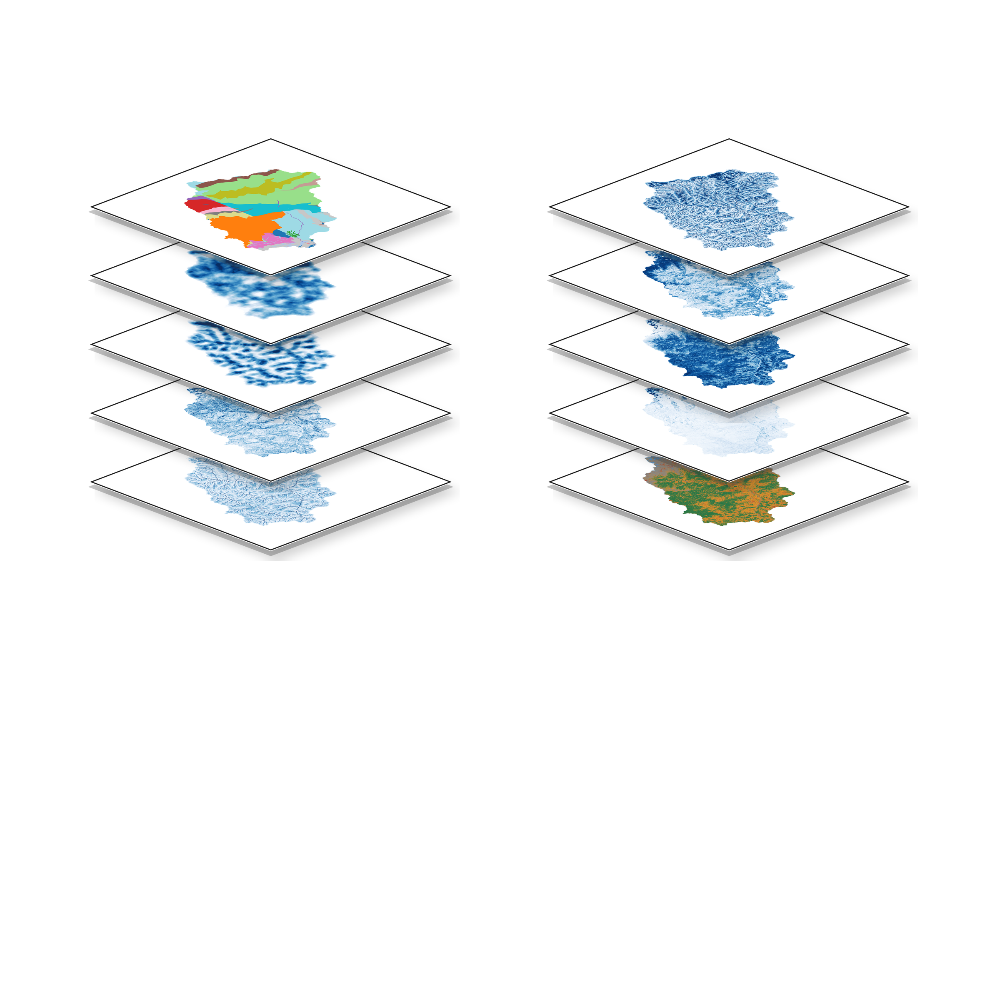

In [18]:
# ============================================================
# TWO COMPACT 5-LAYER GIS OVERLAY STACKS
# Sample-style close overlays
# No layer names
# Two columns
# Square white background
# ============================================================

from pathlib import Path
import re
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from matplotlib.colors import Normalize
from matplotlib import cm
from PIL import Image, ImageDraw, ImageFilter


# ------------------------------------------------------------
# 1. Required layer arrangement
#    First item appears at the TOP of each overlay stack
# ------------------------------------------------------------

LEFT_STACK = [
    "Lithology",
    "Lineament_Density",
    "Drainage_Density",
    "TRI",
    "TWI"
]

RIGHT_STACK = [
    "STI",
    "BSI",
    "NBR",
    "MNDWI",
    "LULC"
]

ALL_LAYERS = LEFT_STACK + RIGHT_STACK


# ------------------------------------------------------------
# 2. Locate the existing 10-band raster stack
# ------------------------------------------------------------

stack_candidates = []

if "stack_path" in globals():
    stack_candidates.append(Path(stack_path))

if "RASTER_DIR" in globals():
    stack_candidates.append(
        Path(RASTER_DIR) / "Predictor_Stack_10Bands_StrictNames.tif"
    )

if "DRIVE_PROJECT_DIR" in globals():
    stack_candidates.extend(
        list(
            Path(DRIVE_PROJECT_DIR).rglob(
                "Predictor_Stack_10Bands_StrictNames.tif"
            )
        )
    )

# Final fallback search
stack_candidates.extend(
    list(
        Path("/content/drive/MyDrive").rglob(
            "Predictor_Stack_10Bands_StrictNames.tif"
        )
    )
)

stack_candidates = [
    p for p in stack_candidates
    if p.exists()
]

if not stack_candidates:
    raise FileNotFoundError(
        "Predictor_Stack_10Bands_StrictNames.tif was not found. "
        "Run the predictor-stack creation cell first."
    )

STACK_PATH = max(
    stack_candidates,
    key=lambda p: p.stat().st_mtime
)

print("Using raster stack:")
print(STACK_PATH)


# ------------------------------------------------------------
# 3. Output folder
# ------------------------------------------------------------

if "PLOT_DIR" in globals():
    OUTPUT_DIR = Path(PLOT_DIR)

elif "DRIVE_PROJECT_DIR" in globals():
    OUTPUT_DIR = (
        Path(DRIVE_PROJECT_DIR)
        / "Colab_Outputs"
        / "plots"
    )

else:
    OUTPUT_DIR = Path("/content")

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

OUTPUT_PNG = (
    OUTPUT_DIR
    / "Ten_ECF_Compact_Overlay_Stacks_No_Labels.png"
)


# ------------------------------------------------------------
# 4. Read the raster bands
# ------------------------------------------------------------

with rasterio.open(STACK_PATH) as src:
    raster_stack = src.read().astype(np.float32)
    band_descriptions = list(src.descriptions)
    nodata_value = src.nodata


# ------------------------------------------------------------
# 5. Standardize band names
# ------------------------------------------------------------

def normalize_name(name):
    return re.sub(
        r"[^a-z0-9]",
        "",
        str(name).lower()
    )


expected_order = [
    "Lithology",
    "Lineament_Density",
    "Drainage_Density",
    "TRI",
    "TWI",
    "STI",
    "BSI",
    "NBR",
    "MNDWI",
    "LULC"
]

# Use expected order if band descriptions are missing
if (
    len(band_descriptions) != raster_stack.shape[0]
    or any(
        d is None or str(d).strip() == ""
        for d in band_descriptions
    )
):
    if raster_stack.shape[0] != 10:
        raise ValueError(
            f"Expected 10 bands, but found "
            f"{raster_stack.shape[0]} bands."
        )

    band_descriptions = expected_order


name_lookup = {
    normalize_name(name): name
    for name in expected_order
}

layer_arrays = {}

for band_index, original_name in enumerate(
    band_descriptions
):
    normalized = normalize_name(original_name)

    if normalized not in name_lookup:
        continue

    standard_name = name_lookup[normalized]

    array = raster_stack[
        band_index
    ].astype(np.float32)

    if nodata_value is not None:
        array = np.where(
            array == nodata_value,
            np.nan,
            array
        )

    layer_arrays[standard_name] = array


missing_layers = [
    name for name in ALL_LAYERS
    if name not in layer_arrays
]

if missing_layers:
    raise ValueError(
        "Missing layers: "
        + ", ".join(missing_layers)
    )


# ------------------------------------------------------------
# 6. Basin mask
#    This prevents Lithology and LULC background pixels
#    from appearing as blue rectangular areas
# ------------------------------------------------------------

reference_array = layer_arrays[
    "Lineament_Density"
]

basin_mask = np.isfinite(
    reference_array
)

if not np.any(basin_mask):
    raise ValueError(
        "The basin mask contains no valid pixels."
    )

rows, cols = np.where(
    basin_mask
)

row_min = rows.min()
row_max = rows.max() + 1

col_min = cols.min()
col_max = cols.max() + 1

cropped_basin_mask = basin_mask[
    row_min:row_max,
    col_min:col_max
]


# ------------------------------------------------------------
# 7. Categorical colors
# ------------------------------------------------------------

LULC_COLORS = {
    0: (70, 150, 220, 255),   # Water
    1: (180, 45, 25, 255),    # Built-up
    2: (45, 120, 70, 255),    # Forest
    3: (220, 145, 45, 255),   # Grassland
    4: (145, 135, 120, 255)   # Bareland
}


# ------------------------------------------------------------
# 8. Convert each raster into a transparent RGBA image
# ------------------------------------------------------------

def raster_to_rgba(layer_name):
    array = layer_arrays[layer_name]

    crop = array[
        row_min:row_max,
        col_min:col_max
    ]

    valid = (
        cropped_basin_mask
        & np.isfinite(crop)
    )

    rgba = np.zeros(
        (
            crop.shape[0],
            crop.shape[1],
            4
        ),
        dtype=np.uint8
    )

    # --------------------------
    # LULC
    # --------------------------
    if layer_name == "LULC":
        rounded = np.rint(crop)

        for class_code, color in LULC_COLORS.items():
            selection = (
                valid
                & (rounded == class_code)
            )

            rgba[selection] = color

    # --------------------------
    # Lithology
    # --------------------------
    elif layer_name == "Lithology":
        rounded = np.rint(crop)

        lithology_classes = sorted(
            np.unique(
                rounded[valid]
            ).astype(int).tolist()
        )

        lithology_cmap = cm.get_cmap(
            "tab20",
            max(
                len(lithology_classes),
                20
            )
        )

        for class_index, class_code in enumerate(
            lithology_classes
        ):
            color = tuple(
                (
                    np.array(
                        lithology_cmap(
                            class_index
                            % lithology_cmap.N
                        )
                    )
                    * 255
                ).astype(np.uint8)
            )

            selection = (
                valid
                & (rounded == class_code)
            )

            rgba[selection] = color

    # --------------------------
    # Continuous layers
    # --------------------------
    else:
        values = crop[valid]

        if values.size == 0:
            return Image.fromarray(
                rgba,
                mode="RGBA"
            )

        lower_limit = float(
            np.nanpercentile(
                values,
                2
            )
        )

        upper_limit = float(
            np.nanpercentile(
                values,
                98
            )
        )

        if (
            not np.isfinite(lower_limit)
            or not np.isfinite(upper_limit)
            or np.isclose(
                lower_limit,
                upper_limit
            )
        ):
            lower_limit = float(
                np.nanmin(values)
            )

            upper_limit = float(
                np.nanmax(values)
            )

        if np.isclose(
            lower_limit,
            upper_limit
        ):
            upper_limit = lower_limit + 1.0

        normalization = Normalize(
            vmin=lower_limit,
            vmax=upper_limit,
            clip=True
        )

        mapped = (
            plt.get_cmap("Blues")(
                normalization(crop)
            )
            * 255
        ).astype(np.uint8)

        rgba[valid] = mapped[valid]

    # Outside the basin remains transparent
    rgba[~valid, 3] = 0

    return Image.fromarray(
        rgba,
        mode="RGBA"
    )


# ------------------------------------------------------------
# 9. Image resampling settings
# ------------------------------------------------------------

if hasattr(Image, "Resampling"):
    RESAMPLE_LANCZOS = Image.Resampling.LANCZOS
    RESAMPLE_BICUBIC = Image.Resampling.BICUBIC

else:
    RESAMPLE_LANCZOS = Image.LANCZOS
    RESAMPLE_BICUBIC = Image.BICUBIC


# ------------------------------------------------------------
# 10. Create one square map tile
#     Every tile uses the same dimensions
# ------------------------------------------------------------

TILE_SIZE = 620
MAP_MARGIN = 60


def create_square_tile(layer_name):
    map_image = raster_to_rgba(
        layer_name
    )

    available_size = (
        TILE_SIZE
        - 2 * MAP_MARGIN
    )

    scale_factor = min(
        available_size
        / map_image.width,

        available_size
        / map_image.height
    )

    resized_width = max(
        1,
        int(
            map_image.width
            * scale_factor
        )
    )

    resized_height = max(
        1,
        int(
            map_image.height
            * scale_factor
        )
    )

    map_image = map_image.resize(
        (
            resized_width,
            resized_height
        ),
        RESAMPLE_LANCZOS
    )

    tile = Image.new(
        "RGBA",
        (
            TILE_SIZE,
            TILE_SIZE
        ),
        (
            255,
            255,
            255,
            255
        )
    )

    paste_x = (
        TILE_SIZE
        - resized_width
    ) // 2

    paste_y = (
        TILE_SIZE
        - resized_height
    ) // 2

    tile.alpha_composite(
        map_image,
        (
            paste_x,
            paste_y
        )
    )

    # Thin border around the square tile
    draw = ImageDraw.Draw(
        tile
    )

    draw.rectangle(
        [
            3,
            3,
            TILE_SIZE - 4,
            TILE_SIZE - 4
        ],
        outline=(
            35,
            35,
            35,
            255
        ),
        width=5
    )

    return tile


# ------------------------------------------------------------
# 11. Convert square tile into compact isometric layer
#     Similar to the sample image
# ------------------------------------------------------------

def create_isometric_layer(layer_name):
    tile = create_square_tile(
        layer_name
    )

    # Rotate the square into a diamond
    diamond = tile.rotate(
        45,
        resample=RESAMPLE_BICUBIC,
        expand=True,
        fillcolor=(
            255,
            255,
            255,
            0
        )
    )

    # Compress vertically to form the GIS overlay appearance
    compressed_height = int(
        diamond.height
        * 0.38
    )

    diamond = diamond.resize(
        (
            diamond.width,
            compressed_height
        ),
        RESAMPLE_LANCZOS
    )

    # Crop unnecessary transparent margins
    alpha_bbox = diamond.getchannel(
        "A"
    ).getbbox()

    if alpha_bbox:
        diamond = diamond.crop(
            alpha_bbox
        )

    return diamond


isometric_layers = {
    layer_name: create_isometric_layer(
        layer_name
    )
    for layer_name in ALL_LAYERS
}


# ------------------------------------------------------------
# 12. Square white output canvas
# ------------------------------------------------------------

CANVAS_SIZE = 2400

canvas = Image.new(
    "RGBA",
    (
        CANVAS_SIZE,
        CANVAS_SIZE
    ),
    (
        255,
        255,
        255,
        255
    )
)


# ------------------------------------------------------------
# 13. Compact overlay settings
#     Small vertical separation matches the sample
# ------------------------------------------------------------

LEFT_CENTER_X = 650
RIGHT_CENTER_X = 1750

STACK_TOP = 330

# Small offset so layers overlap closely
VERTICAL_STEP = 165


def paste_compact_stack(
    layer_names,
    center_x
):
    """
    Draw the lowest layer first and the highest layer last,
    producing a closely overlapped GIS stack.
    """

    layer_positions = {}

    for layer_index, layer_name in enumerate(
        layer_names
    ):
        layer_image = isometric_layers[
            layer_name
        ]

        x_position = int(
            center_x
            - layer_image.width / 2
        )

        y_position = int(
            STACK_TOP
            + layer_index
            * VERTICAL_STEP
        )

        layer_positions[layer_name] = (
            x_position,
            y_position
        )

    # Draw from bottom to top
    for layer_name in reversed(
        layer_names
    ):
        layer_image = isometric_layers[
            layer_name
        ]

        x_position, y_position = (
            layer_positions[layer_name]
        )

        # Subtle gray layer thickness
        thickness_layer = Image.new(
            "RGBA",
            layer_image.size,
            (
                70,
                70,
                70,
                0
            )
        )

        thickness_alpha = (
            layer_image
            .getchannel("A")
            .point(
                lambda pixel:
                int(pixel * 0.32)
            )
        )

        thickness_layer.putalpha(
            thickness_alpha
        )

        canvas.alpha_composite(
            thickness_layer,
            (
                x_position,
                y_position + 12
            )
        )

        # Soft shadow
        shadow = Image.new(
            "RGBA",
            layer_image.size,
            (
                0,
                0,
                0,
                0
            )
        )

        shadow_alpha = (
            layer_image
            .getchannel("A")
            .filter(
                ImageFilter.GaussianBlur(
                    12
                )
            )
            .point(
                lambda pixel:
                int(pixel * 0.18)
            )
        )

        shadow.putalpha(
            shadow_alpha
        )

        canvas.alpha_composite(
            shadow,
            (
                x_position + 15,
                y_position + 23
            )
        )

        # Main layer
        canvas.alpha_composite(
            layer_image,
            (
                x_position,
                y_position
            )
        )


paste_compact_stack(
    LEFT_STACK,
    LEFT_CENTER_X
)

paste_compact_stack(
    RIGHT_STACK,
    RIGHT_CENTER_X
)


# ------------------------------------------------------------
# 14. Save output
# ------------------------------------------------------------

canvas_rgb = canvas.convert(
    "RGB"
)

canvas_rgb.save(
    OUTPUT_PNG,
    dpi=(
        300,
        300
    ),
    quality=95
)

print("\nSaved overlay figure:")
print(OUTPUT_PNG)

display(
    canvas_rgb
)

## Cell 14 - Full-area prediction and 5-class soil erodibility maps

Stack band descriptions: ['Lithology', 'Lineament_Density', 'Drainage_Density', 'TRI', 'TWI', 'STI', 'BSI', 'NBR', 'MNDWI', 'LULC']
Valid pixels for full-area prediction: 1824573
Using existing prediction rasters for: CatBoost
Using existing prediction rasters for: ExtraTrees
Using existing prediction rasters for: MLP_ANN
Using existing prediction rasters for: TabNet
Loaded existing global natural breaks: [0.0, 0.12276537716388702, 0.3676319122314453, 0.6309212446212769, 0.8766800165176392, 1.0]
Using existing final 5-class raster for: CatBoost


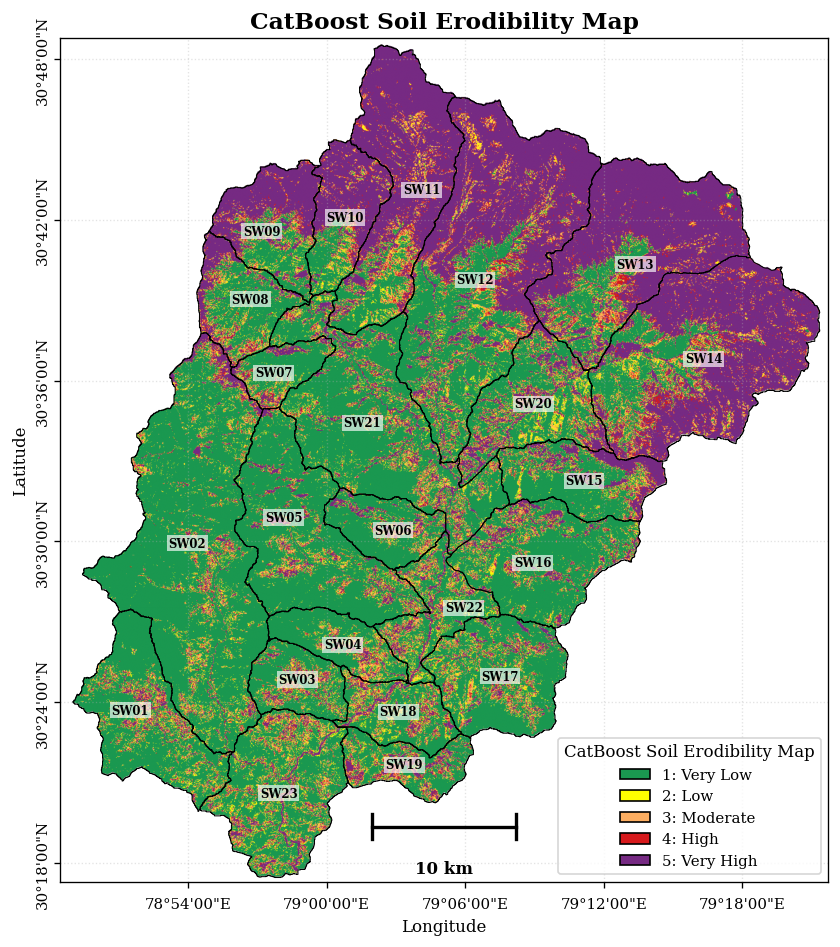

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/publication_maps/CatBoost_Soil_Erodibility_Map.png
Using existing final 5-class raster for: ExtraTrees


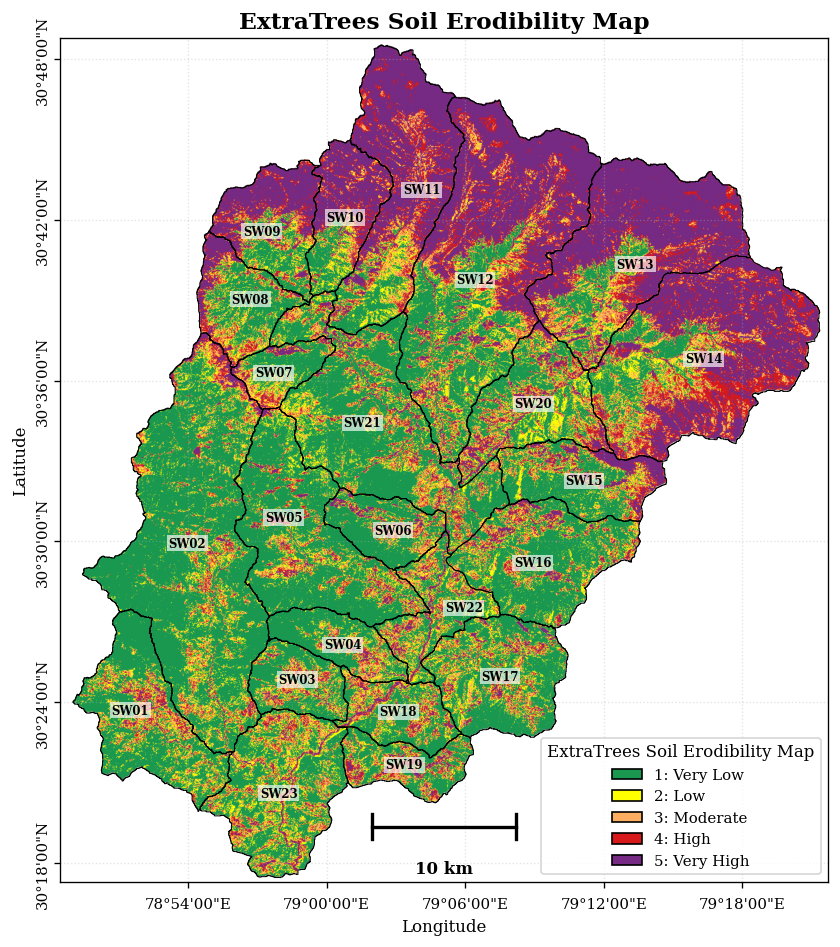

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/publication_maps/ExtraTrees_Soil_Erodibility_Map.png
Using existing final 5-class raster for: MLP_ANN


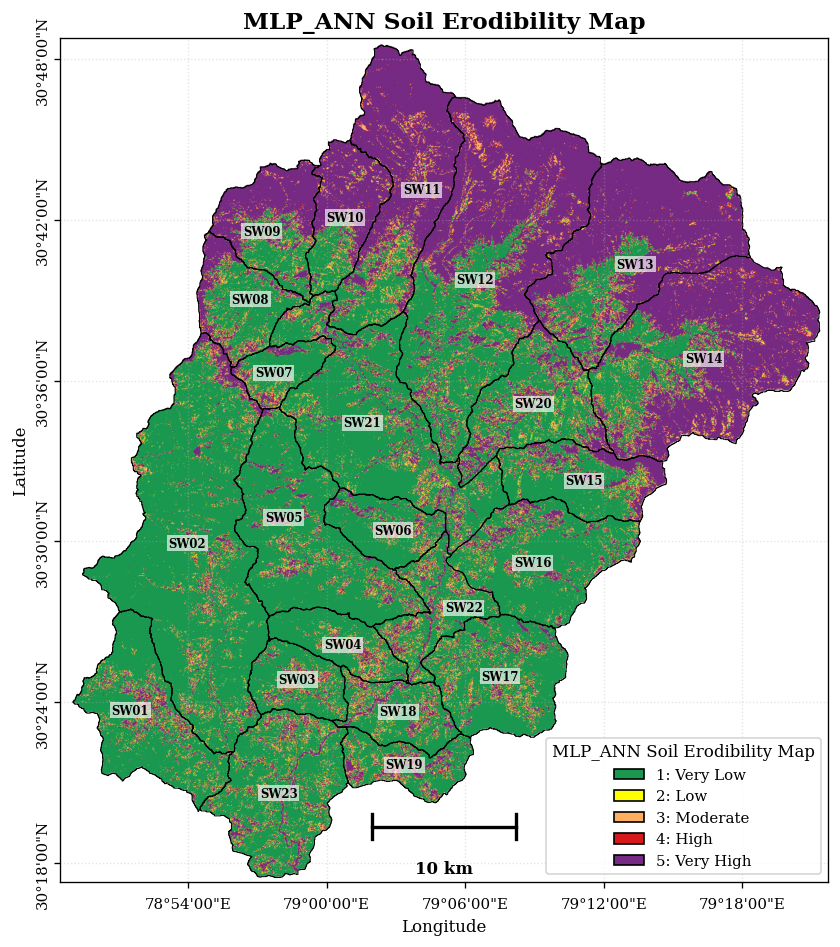

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/publication_maps/MLP_ANN_Soil_Erodibility_Map.png
Using existing final 5-class raster for: TabNet


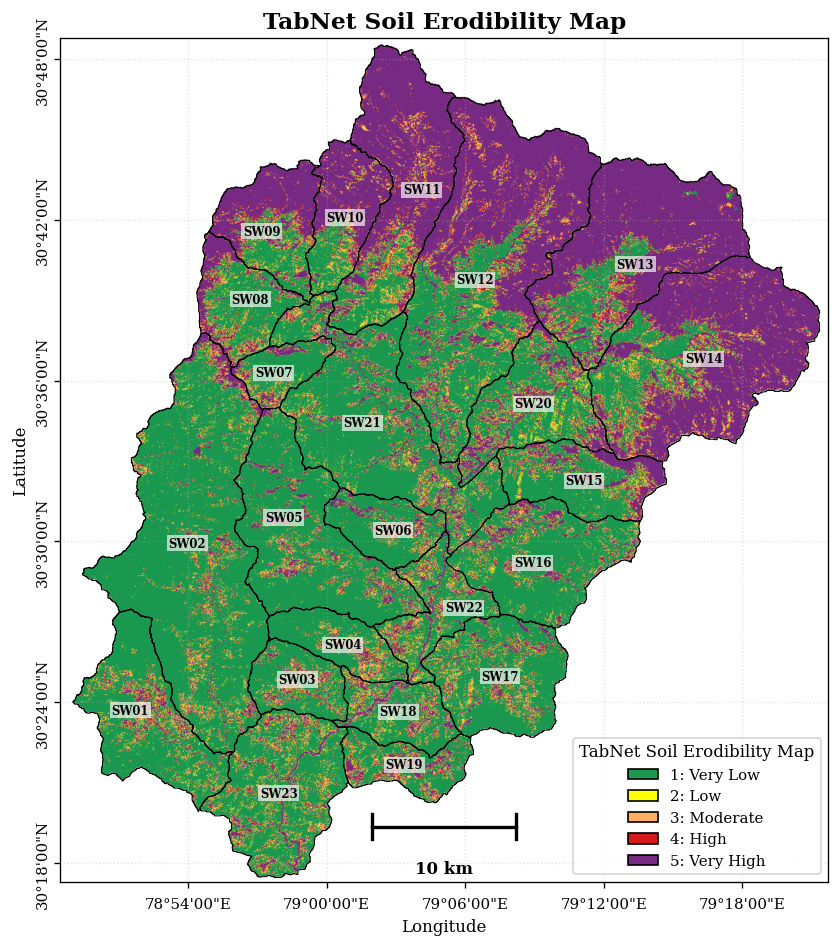

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/publication_maps/TabNet_Soil_Erodibility_Map.png
Prediction completed for: ['CatBoost', 'ExtraTrees', 'MLP_ANN', 'TabNet']
Cell 14 completed.


In [19]:
# ============================================================
# CELL 14: FULL-AREA PREDICTION AND 5-CLASS SOIL ERODIBILITY MAPS
# Uses all 10 predictors and all 4 models.
# Final classification uses global natural breaks.
# ============================================================

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

prediction_raster_outputs_by_model = {}

def collect_susceptibility_values(score_paths, max_values=GLOBAL_JENKS_MAX_VALUES):
    rng = np.random.default_rng(GLOBAL_JENKS_RANDOM_SEED)
    all_vals = []
    per_model_cap = max(10000, int(max_values / max(1, len(score_paths))))

    for model_name, path in score_paths.items():
        with rasterio.open(path) as src:
            vals = src.read(1).astype(np.float32)
            nodata = src.nodata
            valid = np.isfinite(vals)
            if nodata is not None and not np.isnan(nodata):
                valid &= vals != nodata
            vals = vals[valid]

        if len(vals) == 0:
            continue

        if len(vals) > per_model_cap:
            # random sample + forced high tail so rare extremes are not missed
            random_n = int(per_model_cap * 0.85)
            tail_n = per_model_cap - random_n
            rand_idx = rng.choice(len(vals), size=random_n, replace=False)
            tail_vals = np.sort(vals)[-tail_n:] if len(vals) > tail_n else vals
            vals_used = np.concatenate([vals[rand_idx], tail_vals])
        else:
            vals_used = vals

        print(f"{model_name} values used for global Jenks:", len(vals_used))
        all_vals.append(vals_used)

    if not all_vals:
        raise ValueError("No valid susceptibility-score values found for natural breaks.")

    return np.concatenate(all_vals)


def compute_or_load_global_breaks(score_paths):
    breaks_path = TABLE_DIR / "Global_Natural_Breaks_5Class_SusceptibilityScore.json"

    if breaks_path.exists() and not FORCE_REDO_GLOBAL_NATURAL_BREAKS:
        breaks = json.loads(breaks_path.read_text())
        print("Loaded existing global natural breaks:", breaks)
        return breaks

    vals = collect_susceptibility_values(score_paths)
    vals = vals[np.isfinite(vals)]

    try:
        breaks = jenkspy.jenks_breaks(vals, n_classes=5)
    except TypeError:
        breaks = jenkspy.jenks_breaks(vals, nb_class=5)
    except Exception as e:
        print("Jenks failed, using quantile fallback:", repr(e))
        breaks = np.quantile(vals, [0, 0.2, 0.4, 0.6, 0.8, 1]).tolist()

    breaks[0] = float(np.nanmin(vals))
    breaks[-1] = float(np.nanmax(vals))
    breaks = [float(b) for b in breaks]

    breaks_path.write_text(json.dumps(breaks, indent=2))
    print("Saved global natural breaks:", breaks_path)
    print("Breaks:", breaks)
    return breaks


def classify_5class(score_arr, breaks):
    out = np.full(score_arr.shape, -9999, dtype=np.int16)
    valid = np.isfinite(score_arr)
    out[(score_arr >= breaks[0]) & (score_arr <= breaks[1]) & valid] = 1
    out[(score_arr > breaks[1]) & (score_arr <= breaks[2]) & valid] = 2
    out[(score_arr > breaks[2]) & (score_arr <= breaks[3]) & valid] = 3
    out[(score_arr > breaks[3]) & (score_arr <= breaks[4]) & valid] = 4
    out[(score_arr > breaks[4]) & (score_arr <= breaks[5]) & valid] = 5
    return out


def decimal_to_dms(value, is_lon=True):
    hemi = ("E" if value >= 0 else "W") if is_lon else ("N" if value >= 0 else "S")
    value = abs(value)
    deg = int(value)
    minutes_float = (value - deg) * 60
    minutes = int(minutes_float)
    seconds = int(round((minutes_float - minutes) * 60))

    if seconds == 60:
        seconds = 0
        minutes += 1

    if minutes == 60:
        minutes = 0
        deg += 1

    return f"{deg}°{minutes:02d}'{seconds:02d}\"{hemi}"


def lon_formatter(x, pos):
    return decimal_to_dms(x, is_lon=True)


def lat_formatter(y, pos):
    return decimal_to_dms(y, is_lon=False)


def add_scalebar_lonlat(ax, length_km=10):
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    lat_mid = (ymin + ymax) / 2
    km_per_deg_lon = 111.32 * np.cos(np.deg2rad(lat_mid))
    length_deg = length_km / km_per_deg_lon

    # --------------------------------------------------------
    #  SCALE-BAR POSITION
    # --------------------------------------------------------
    x_center = xmin + (xmax - xmin) * 0.50
    x0 = x_center - (length_deg / 2)
    x1 = x_center + (length_deg / 2)

    y0 = ymin + (ymax - ymin) * 0.065

    ax.plot([x0, x1], [y0, y0], color="black", linewidth=2)
    ax.plot(
        [x0, x0],
        [y0 - (ymax - ymin) * 0.015, y0 + (ymax - ymin) * 0.015],
        color="black",
        linewidth=2
    )
    ax.plot(
        [x1, x1],
        [y0 - (ymax - ymin) * 0.015, y0 + (ymax - ymin) * 0.015],
        color="black",
        linewidth=2
    )
    ax.text(
        (x0 + x1) / 2,
        y0 - (ymax - ymin) * 0.04,
        f"{length_km} km",
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold"
    )


def plot_5class_map(tif_path, model_name, out_png):
    cmap = ListedColormap([CLASS5_COLORS[i] for i in range(1, 6)])
    norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5, 5.5], cmap.N)

    with rasterio.open(tif_path) as src:
        arr = src.read(1)
        nd = src.nodata

        # Reproject for preview to EPSG:4326 so coordinates are DMS.
        dst_crs = "EPSG:4326"
        transform, width, height = calculate_default_transform(
            src.crs,
            dst_crs,
            src.width,
            src.height,
            *src.bounds
        )

        dst_arr = np.full((height, width), -9999, dtype=np.int16)

        reproject(
            source=arr,
            destination=dst_arr,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=nd,
            dst_transform=transform,
            dst_crs=dst_crs,
            dst_nodata=-9999,
            resampling=Resampling.nearest
        )

        left = transform.c
        top = transform.f
        right = left + transform.a * width
        bottom = top + transform.e * height
        extent = [left, right, bottom, top]
        show_arr = np.where(dst_arr == -9999, np.nan, dst_arr)

    fig, ax = plt.subplots(figsize=(11, 8))

    ax.imshow(
        show_arr,
        cmap=cmap,
        norm=norm,
        extent=extent,
        origin="upper"
    )

    if sw_gdf is not None:
        sw_plot = sw_gdf.to_crs("EPSG:4326")
        sw_plot.boundary.plot(ax=ax, color="black", linewidth=0.6)

        for _, row in sw_plot.iterrows():
            rp = row.geometry.representative_point()
            ax.text(
                rp.x,
                rp.y,
                str(row["SWID"]),
                ha="center",
                va="center",
                fontsize=7,
                fontweight="bold",
                bbox=dict(facecolor="white", alpha=0.65, edgecolor="none", pad=1)
            )

    handles = [
        Patch(
            facecolor=CLASS5_COLORS[i],
            edgecolor="black",
            label=f"{i}: {CLASS5_LABELS[i]}"
        )
        for i in range(1, 6)
    ]

    ax.legend(
        handles=handles,
        title=f"{model_name} Soil Erodibility Map",
        loc="lower right",
        frameon=True,
        fontsize=9,
        title_fontsize=10
    )

    add_scalebar_lonlat(ax, length_km=10)

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    ax.xaxis.set_major_formatter(FuncFormatter(lon_formatter))
    ax.yaxis.set_major_formatter(FuncFormatter(lat_formatter))

    ax.tick_params(axis="x", labelrotation=0, labelsize=9, pad=6)
    ax.tick_params(axis="y", labelrotation=90, labelsize=9, pad=7)

    # Keep latitude coordinate labels centered on their grid ticks
    for label in ax.get_yticklabels():
        label.set_rotation(90)
        label.set_rotation_mode("anchor")
        label.set_verticalalignment("center")
        label.set_horizontalalignment("center")

    ax.grid(True, linestyle=":", alpha=0.35)

    ax.set_title(
        f"{model_name} Soil Erodibility Map",
        fontsize=14,
        fontweight="bold"
    )

    fig.tight_layout()
    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", out_png)


# ------------------------------------------------------------
# 1. Full-area model prediction
# ------------------------------------------------------------
score_paths = {}

with rasterio.open(stack_path) as src:
    profile = src.profile.copy()
    arr = src.read()
    desc = list(src.descriptions)

    print("Stack band descriptions:", desc)

    if desc and set(FEATURES).issubset(set(desc)):
        idx = [{d: i for i, d in enumerate(desc)}[f] for f in FEATURES]
        arr = arr[idx, :, :]
    else:
        arr = arr[:len(FEATURES), :, :]

    nodata = src.nodata
    height, width = arr.shape[1], arr.shape[2]

    mask = np.ones((height, width), dtype=bool)

    for i, feat in enumerate(FEATURES):
        band = arr[i]
        mask &= np.isfinite(band)

        if nodata is not None and not np.isnan(nodata):
            mask &= band != nodata

    rows, cols = np.where(mask)
    n_valid = len(rows)

    print("Valid pixels for full-area prediction:", n_valid)

    out_float = profile.copy()
    out_float.update(
        driver="GTiff",
        count=1,
        dtype="float32",
        nodata=np.nan,
        compress="lzw"
    )

    out_int = profile.copy()
    out_int.update(
        driver="GTiff",
        count=1,
        dtype="int16",
        nodata=-9999,
        compress="lzw"
    )

    for model_name in MODELS_FOR_FULL_AREA:
        if model_name not in final_models:
            continue

        model = final_models[model_name]

        files = {
            "P_low": RASTER_DIR / f"{model_name}_P_low.tif",
            "P_moderate": RASTER_DIR / f"{model_name}_P_moderate.tif",
            "P_high": RASTER_DIR / f"{model_name}_P_high.tif",
            "Predicted_Class": RASTER_DIR / f"{model_name}_Predicted_Class.tif",
            "Susceptibility_Score": RASTER_DIR / f"{model_name}_Susceptibility_Score.tif",
        }

        if files["Susceptibility_Score"].exists() and not FORCE_REDO_FULL_AREA_PREDICTION:
            print("Using existing prediction rasters for:", model_name)

            prediction_raster_outputs_by_model[model_name] = {
                k: str(v) for k, v in files.items()
            }

            score_paths[model_name] = str(files["Susceptibility_Score"])
            continue

        print("Predicting full area for:", model_name)

        proba_stack = np.full((3, height, width), np.nan, dtype=np.float32)
        pred_class = np.full((height, width), -9999, dtype=np.int16)

        for start in tqdm(
            range(0, n_valid, CHUNK_SIZE),
            desc=f"{model_name} full-area prediction"
        ):
            end = min(start + CHUNK_SIZE, n_valid)
            rr = rows[start:end]
            cc = cols[start:end]

            data = arr[:, rr, cc].T.astype(np.float32)
            chunk_df = pd.DataFrame(data, columns=FEATURES)

            # Ensure categorical predictors are whole-number codes.
            for c in CATEGORICAL_FEATURES:
                chunk_df[c] = np.rint(chunk_df[c]).astype(int)

            y_pred, y_prob = predict_model(model_name, model, chunk_df)

            for k in range(3):
                proba_stack[k, rr, cc] = y_prob[:, k].astype(np.float32)

            pred_class[rr, cc] = y_pred.astype(np.int16)

        susceptibility_score = proba_stack[2] + 0.5 * proba_stack[1]

        for k, key in enumerate(["P_low", "P_moderate", "P_high"]):
            with rasterio.open(files[key], "w", **out_float) as dst:
                dst.write(proba_stack[k], 1)
                dst.set_band_description(1, key)

        with rasterio.open(files["Predicted_Class"], "w", **out_int) as dst:
            dst.write(pred_class, 1)
            dst.set_band_description(1, "Predicted_Class_0_1_2")

        with rasterio.open(files["Susceptibility_Score"], "w", **out_float) as dst:
            dst.write(susceptibility_score.astype(np.float32), 1)
            dst.set_band_description(1, "Susceptibility_Score")

        prediction_raster_outputs_by_model[model_name] = {
            k: str(v) for k, v in files.items()
        }

        score_paths[model_name] = str(files["Susceptibility_Score"])


# ------------------------------------------------------------
# 2. Global natural breaks and final 5-class rasters/maps
# ------------------------------------------------------------
global_breaks = compute_or_load_global_breaks(score_paths)

for model_name, outputs in prediction_raster_outputs_by_model.items():
    final_tif = RASTER_DIR / f"{model_name}_Final_5Class_Soil_Erodibility.tif"

    if (
        final_tif.exists()
        and not FORCE_REDO_FULL_AREA_PREDICTION
        and not FORCE_REDO_GLOBAL_NATURAL_BREAKS
    ):
        print("Using existing final 5-class raster for:", model_name)

    else:
        with rasterio.open(outputs["Susceptibility_Score"]) as src:
            score = src.read(1).astype(np.float32)
            profile = src.profile.copy()

            final_5 = classify_5class(score, global_breaks)

            profile.update(
                dtype="int16",
                nodata=-9999,
                count=1,
                compress="lzw"
            )

            with rasterio.open(final_tif, "w", **profile) as dst:
                dst.write(final_5, 1)
                dst.set_band_description(1, "Final_5Class_Soil_Erodibility")

    prediction_raster_outputs_by_model[model_name]["Final_5Class_Soil_Erodibility"] = str(final_tif)

    out_png = MAP_DIR / f"{model_name}_Soil_Erodibility_Map.png"
    plot_5class_map(final_tif, model_name, out_png)


with open(RASTER_DIR / "Prediction_Raster_Outputs_By_Model.json", "w") as f:
    json.dump(prediction_raster_outputs_by_model, f, indent=2)

print("Prediction completed for:", list(prediction_raster_outputs_by_model.keys()))
print("Cell 14 completed.")

# CELL 15: OVERALL AND 23-SW 5-CLASS ERODIBILITY AREA STATISTICS

In [20]:
# ============================================================
# CELL 15: OVERALL AND 23-SW 5-CLASS ERODIBILITY AREA STATISTICS
# Outputs:
#   1. Overall area and percentage by 5 erodibility classes for each model
#   2. Individual 23 SW area and percentage by 5 erodibility classes for each model
# ============================================================

import json
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
from rasterstats import zonal_stats
from IPython.display import display

print("Starting 5-class erodibility area and percentage calculations...")

# ------------------------------------------------------------
# 1. Make sure output folders exist
# ------------------------------------------------------------
TABLE_DIR.mkdir(parents=True, exist_ok=True)
RASTER_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Class labels
# ------------------------------------------------------------
if "CLASS5_LABELS" not in globals():
    CLASS5_LABELS = {
        1: "Very Low",
        2: "Low",
        3: "Moderate",
        4: "High",
        5: "Very High"
    }

CLASS_CODES = [1, 2, 3, 4, 5]

# ------------------------------------------------------------
# 3. Load prediction raster output dictionary if needed
# ------------------------------------------------------------
if "prediction_raster_outputs_by_model" not in globals() or len(prediction_raster_outputs_by_model) == 0:
    pred_json = RASTER_DIR / "Prediction_Raster_Outputs_By_Model.json"

    if not pred_json.exists():
        raise FileNotFoundError(
            f"Prediction output JSON not found: {pred_json}. "
            "Run Cell 14 first."
        )

    with open(pred_json, "r") as f:
        prediction_raster_outputs_by_model = json.load(f)

print("Models found:", list(prediction_raster_outputs_by_model.keys()))

# ------------------------------------------------------------
# 4. Load SW polygons if needed
# ------------------------------------------------------------
if "sw_gdf" not in globals() or sw_gdf is None:
    possible_sw_files = [
        TABLE_DIR / "SW23_from_GEE.geojson",
        TABLE_DIR / "Mandakini_SW23_from_GEE.geojson"
    ]

    sw_file = None
    for p in possible_sw_files:
        if p.exists():
            sw_file = p
            break

    if sw_file is None:
        raise FileNotFoundError(
            "SW polygon GeoJSON not found. Run the SW/GEE boundary cell before this cell."
        )

    sw_gdf = gpd.read_file(sw_file)
    print("Loaded SW polygons:", sw_file)

if "OBJECTID_NUM" not in sw_gdf.columns:
    if "OBJECTID" in sw_gdf.columns:
        sw_gdf["OBJECTID_NUM"] = sw_gdf["OBJECTID"].astype(int)
    else:
        sw_gdf["OBJECTID_NUM"] = np.arange(1, len(sw_gdf) + 1)

if "SWID" not in sw_gdf.columns:
    sw_gdf["SWID"] = sw_gdf["OBJECTID_NUM"].astype(int).apply(lambda x: f"SW{x:02d}")

sw_gdf["OBJECTID_NUM"] = sw_gdf["OBJECTID_NUM"].astype(int)
sw_gdf["SWID"] = sw_gdf["SWID"].astype(str)

print("SW polygon count:", len(sw_gdf))

# ------------------------------------------------------------
# 5. Helper function
# ------------------------------------------------------------
def class_col_name(class_code, suffix):
    class_name = CLASS5_LABELS[class_code].replace(" ", "_")
    return f"Class{class_code}_{class_name}_{suffix}"

# ------------------------------------------------------------
# 6. Overall area and percentage by class for each model
# ------------------------------------------------------------
overall_rows = []

for model_name, outputs in prediction_raster_outputs_by_model.items():
    print("\nCalculating overall 5-class area for:", model_name)

    if "Final_5Class_Soil_Erodibility" not in outputs:
        raise KeyError(
            f"Final_5Class_Soil_Erodibility missing for {model_name}. "
            "Run Cell 14 first."
        )

    f5_path = outputs["Final_5Class_Soil_Erodibility"]

    with rasterio.open(f5_path) as src:
        arr = src.read(1)
        nodata = src.nodata
        transform = src.transform

        pixel_area_km2 = abs(transform.a * transform.e) / 1e6

        valid_mask = np.isfinite(arr)

        if nodata is not None:
            valid_mask &= arr != nodata

        valid_mask &= np.isin(arr, CLASS_CODES)

        total_valid_pixels = int(valid_mask.sum())
        total_valid_area_km2 = total_valid_pixels * pixel_area_km2

        for class_code in CLASS_CODES:
            class_mask = valid_mask & (arr == class_code)
            pixel_count = int(class_mask.sum())
            area_km2 = pixel_count * pixel_area_km2
            percent = (area_km2 / total_valid_area_km2 * 100) if total_valid_area_km2 > 0 else np.nan

            overall_rows.append({
                "Model": model_name,
                "Class_Code": class_code,
                "Erodibility_Class": CLASS5_LABELS[class_code],
                "Pixel_Count": pixel_count,
                "Area_km2": area_km2,
                "Percent": percent,
                "Total_Valid_Pixels_Model": total_valid_pixels,
                "Total_Valid_Area_km2_Model": total_valid_area_km2
            })

overall_area_df = pd.DataFrame(overall_rows)

overall_csv = TABLE_DIR / "Overall_5Class_Erodibility_Area_Percent_By_Model.csv"
overall_area_df.to_csv(overall_csv, index=False)

print("\nOverall 5-class erodibility area and percentage table:")
display(overall_area_df)

print("Saved overall CSV:", overall_csv)

# ------------------------------------------------------------
# 7. Individual 23 SW area and percentage by class for each model
# ------------------------------------------------------------
sw_rows = []

for model_name, outputs in prediction_raster_outputs_by_model.items():
    print("\nCalculating SW-level 5-class area for:", model_name)

    f5_path = outputs["Final_5Class_Soil_Erodibility"]

    with rasterio.open(f5_path) as src:
        raster_crs = src.crs
        nodata = src.nodata
        transform = src.transform
        pixel_area_km2 = abs(transform.a * transform.e) / 1e6

    swp = sw_gdf.to_crs(raster_crs).copy()
    swp["SW_Area_km2_Geometry"] = swp.geometry.area / 1e6

    # categorical=True returns class-code counts inside each SW
    zs = zonal_stats(
        swp,
        f5_path,
        categorical=True,
        nodata=nodata,
        all_touched=False
    )

    for i, stats in enumerate(zs):
        swid = str(swp.iloc[i]["SWID"])
        objid = int(swp.iloc[i]["OBJECTID_NUM"])
        sw_area_km2_geom = float(swp.iloc[i]["SW_Area_km2_Geometry"])

        total_valid_pixels_sw = int(sum([stats.get(c, 0) for c in CLASS_CODES]))
        total_valid_area_km2_sw = total_valid_pixels_sw * pixel_area_km2

        row = {
            "Model": model_name,
            "SWID": swid,
            "OBJECTID_NUM": objid,
            "SW_Area_km2_Geometry": sw_area_km2_geom,
            "Total_Valid_Pixels_SW": total_valid_pixels_sw,
            "Total_Valid_Area_km2_SW": total_valid_area_km2_sw
        }

        for class_code in CLASS_CODES:
            class_name = CLASS5_LABELS[class_code].replace(" ", "_")

            pixel_count = int(stats.get(class_code, 0))
            area_km2 = pixel_count * pixel_area_km2
            percent = (area_km2 / total_valid_area_km2_sw * 100) if total_valid_area_km2_sw > 0 else np.nan

            row[f"Class{class_code}_{class_name}_Pixel_Count"] = pixel_count
            row[f"Class{class_code}_{class_name}_Area_km2"] = area_km2
            row[f"Class{class_code}_{class_name}_Percent"] = percent

        sw_rows.append(row)

sw_area_df = pd.DataFrame(sw_rows)

# Sort neatly by model and SW number
sw_area_df = sw_area_df.sort_values(
    ["Model", "OBJECTID_NUM"],
    ascending=[True, True]
).reset_index(drop=True)

sw_csv = TABLE_DIR / "SW23_5Class_Erodibility_Area_Percent_By_Model.csv"
sw_area_df.to_csv(sw_csv, index=False)

print("\nIndividual 23 SW 5-class erodibility area and percentage table:")
display(sw_area_df)

print("Saved SW-level CSV:", sw_csv)

# ------------------------------------------------------------
# 8. Optional compact display tables
# ------------------------------------------------------------
overall_pivot_percent = overall_area_df.pivot_table(
    index="Model",
    columns="Erodibility_Class",
    values="Percent",
    aggfunc="first"
).reset_index()

overall_pivot_area = overall_area_df.pivot_table(
    index="Model",
    columns="Erodibility_Class",
    values="Area_km2",
    aggfunc="first"
).reset_index()

overall_pivot_percent_csv = TABLE_DIR / "Overall_5Class_Erodibility_Percent_Pivot_By_Model.csv"
overall_pivot_area_csv = TABLE_DIR / "Overall_5Class_Erodibility_Area_km2_Pivot_By_Model.csv"

overall_pivot_percent.to_csv(overall_pivot_percent_csv, index=False)
overall_pivot_area.to_csv(overall_pivot_area_csv, index=False)

print("\nOverall percentage pivot:")
display(overall_pivot_percent)

print("\nOverall area pivot:")
display(overall_pivot_area)

print("\nAdditional pivot CSVs saved:")
print(overall_pivot_percent_csv)
print(overall_pivot_area_csv)

print("\nCell completed successfully.")
print("Main CSV 1:", overall_csv)
print("Main CSV 2:", sw_csv)

Starting 5-class erodibility area and percentage calculations...
Models found: ['CatBoost', 'ExtraTrees', 'MLP_ANN', 'TabNet']
SW polygon count: 23

Calculating overall 5-class area for: CatBoost

Calculating overall 5-class area for: ExtraTrees

Calculating overall 5-class area for: MLP_ANN

Calculating overall 5-class area for: TabNet

Overall 5-class erodibility area and percentage table:


,Model,Class_Code,Erodibility_Class,Pixel_Count,Area_km2,Percent,Total_Valid_Pixels_Model,Total_Valid_Area_km2_Model
0,CatBoost,1,Very Low,969405,872.4645,53.130513,1824573,1642.1157
1,CatBoost,2,Low,94092,84.6828,5.156933,1824573,1642.1157
2,CatBoost,3,Moderate,148663,133.7967,8.147824,1824573,1642.1157
3,CatBoost,4,High,90298,81.2682,4.948994,1824573,1642.1157
4,CatBoost,5,Very High,522115,469.9035,28.615736,1824573,1642.1157
5,ExtraTrees,1,Very Low,822016,739.8144,45.052514,1824573,1642.1157
6,ExtraTrees,2,Low,203401,183.0609,11.147869,1824573,1642.1157
7,ExtraTrees,3,Moderate,189183,170.2647,10.368618,1824573,1642.1157
8,ExtraTrees,4,High,201482,181.3338,11.042693,1824573,1642.1157
9,ExtraTrees,5,Very High,408491,367.6419,22.388307,1824573,1642.1157


Saved overall CSV: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Overall_5Class_Erodibility_Area_Percent_By_Model.csv

Calculating SW-level 5-class area for: CatBoost

Calculating SW-level 5-class area for: ExtraTrees

Calculating SW-level 5-class area for: MLP_ANN

Calculating SW-level 5-class area for: TabNet

Individual 23 SW 5-class erodibility area and percentage table:


,Model,SWID,OBJECTID_NUM,SW_Area_km2_Geometry,Total_Valid_Pixels_SW,Total_Valid_Area_km2_SW,Class1_Very_Low_Pixel_Count,Class1_Very_Low_Area_km2,Class1_Very_Low_Percent,Class2_Low_Pixel_Count,...,Class2_Low_Percent,Class3_Moderate_Pixel_Count,Class3_Moderate_Area_km2,Class3_Moderate_Percent,Class4_High_Pixel_Count,Class4_High_Area_km2,Class4_High_Percent,Class5_Very_High_Pixel_Count,Class5_Very_High_Area_km2,Class5_Very_High_Percent
0,CatBoost,SW01,1,66.889737,74190,66.7710,57486,51.7374,77.484836,4620,...,6.227254,5850,5.2650,7.885160,2684,2.4156,3.617738,3550,3.1950,4.785011
1,CatBoost,SW02,2,192.013963,213173,191.8557,178756,160.8804,83.854897,8984,...,4.214417,11537,10.3833,5.412036,4921,4.4289,2.308454,8975,8.0775,4.210195
2,CatBoost,SW03,3,28.067797,31190,28.0710,22379,20.1411,71.750561,2067,...,6.627124,3124,2.8116,10.016031,1522,1.3698,4.879769,2098,1.8882,6.726515
3,CatBoost,SW04,4,27.950279,31060,27.9540,23175,20.8575,74.613651,1992,...,6.413393,3038,2.7342,9.781069,1249,1.1241,4.021249,1606,1.4454,5.170637
4,CatBoost,SW05,5,95.079032,105657,95.0913,86477,77.8293,81.846920,4326,...,4.094381,6131,5.5179,5.802739,2887,2.5983,2.732427,5836,5.2524,5.523534
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87,TabNet,SW19,19,27.668997,30546,27.4914,18942,17.0478,62.011393,1702,...,5.571924,3965,3.5685,12.980423,1664,1.4976,5.447522,4273,3.8457,13.988738
88,TabNet,SW20,20,57.583270,64015,57.6135,36726,33.0534,57.370929,4268,...,6.667187,7462,6.7158,11.656643,3198,2.8782,4.995704,12361,11.1249,19.309537
89,TabNet,SW21,21,119.779394,133089,119.7801,102352,92.1168,76.904928,5376,...,4.039402,10258,9.2322,7.707624,3668,3.3012,2.756050,11435,10.2915,8.591995
90,TabNet,SW22,22,34.814826,38677,34.8093,24630,22.1670,63.681258,2532,...,6.546526,5092,4.5828,13.165447,1519,1.3671,3.927399,4904,4.4136,12.679370


Saved SW-level CSV: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/SW23_5Class_Erodibility_Area_Percent_By_Model.csv

Overall percentage pivot:


Erodibility_Class,Model,High,Low,Moderate,Very High,Very Low
0,CatBoost,4.948994,5.156933,8.147824,28.615736,53.130513
1,ExtraTrees,11.042693,11.147869,10.368618,22.388307,45.052514
2,MLP_ANN,2.311171,2.276149,7.875103,31.202917,56.334660
3,TabNet,3.663707,3.722022,7.980991,29.701744,54.931537



Overall area pivot:


Erodibility_Class,Model,High,Low,Moderate,Very High,Very Low
0,CatBoost,81.2682,84.6828,133.7967,469.9035,872.4645
1,ExtraTrees,181.3338,183.0609,170.2647,367.6419,739.8144
2,MLP_ANN,37.9521,37.3770,129.3183,512.3880,925.0803
3,TabNet,60.1623,61.1199,131.0571,487.7370,902.0394



Additional pivot CSVs saved:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Overall_5Class_Erodibility_Percent_Pivot_By_Model.csv
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Overall_5Class_Erodibility_Area_km2_Pivot_By_Model.csv

Cell completed successfully.
Main CSV 1: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Overall_5Class_Erodibility_Area_Percent_By_Model.csv
Main CSV 2: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/SW23_5Class_Erodibility_Area_Percent_By_Model.csv


## Cell 16 - SW class area tables and ranking for all models


Processing SW tables, ranking and map for: CatBoost


,Model,SWID,OBJECTID_NUM,SW_Area_km2,Class1_Very_Low_Pixel_Count,Class2_Low_Pixel_Count,Class3_Moderate_Pixel_Count,Class4_High_Pixel_Count,Class5_Very_High_Pixel_Count,Valid_Pixel_Count,Class1_Very_Low_Area_km2,Class1_Very_Low_Percent,Class2_Low_Area_km2,Class2_Low_Percent,Class3_Moderate_Area_km2,Class3_Moderate_Percent,Class4_High_Area_km2,Class4_High_Percent,Class5_Very_High_Area_km2,Class5_Very_High_Percent
0,CatBoost,SW23,23,75.956027,54211,8371,9963,4379,7190,84114,48.7899,64.449438,7.5339,9.951970,8.9667,11.844639,3.9411,5.206030,6.4710,8.547923
1,CatBoost,SW22,22,34.814826,23066,3807,5086,2185,4533,38677,20.7594,59.637511,3.4263,9.843059,4.5774,13.149934,1.9665,5.649352,4.0797,11.720144
2,CatBoost,SW21,21,119.779394,99620,7353,10585,4873,10658,133089,89.6580,74.852167,6.6177,5.524874,9.5265,7.953324,4.3857,3.661460,9.5922,8.008175
3,CatBoost,SW20,20,57.583270,34740,5593,7644,3828,12210,64015,31.2660,54.268531,5.0337,8.737015,6.8796,11.940951,3.4452,5.979848,10.9890,19.073655
4,CatBoost,SW19,19,27.668997,18024,2299,3857,2245,4121,30546,16.2216,59.006089,2.0691,7.526354,3.4713,12.626858,2.0205,7.349571,3.7089,13.491128


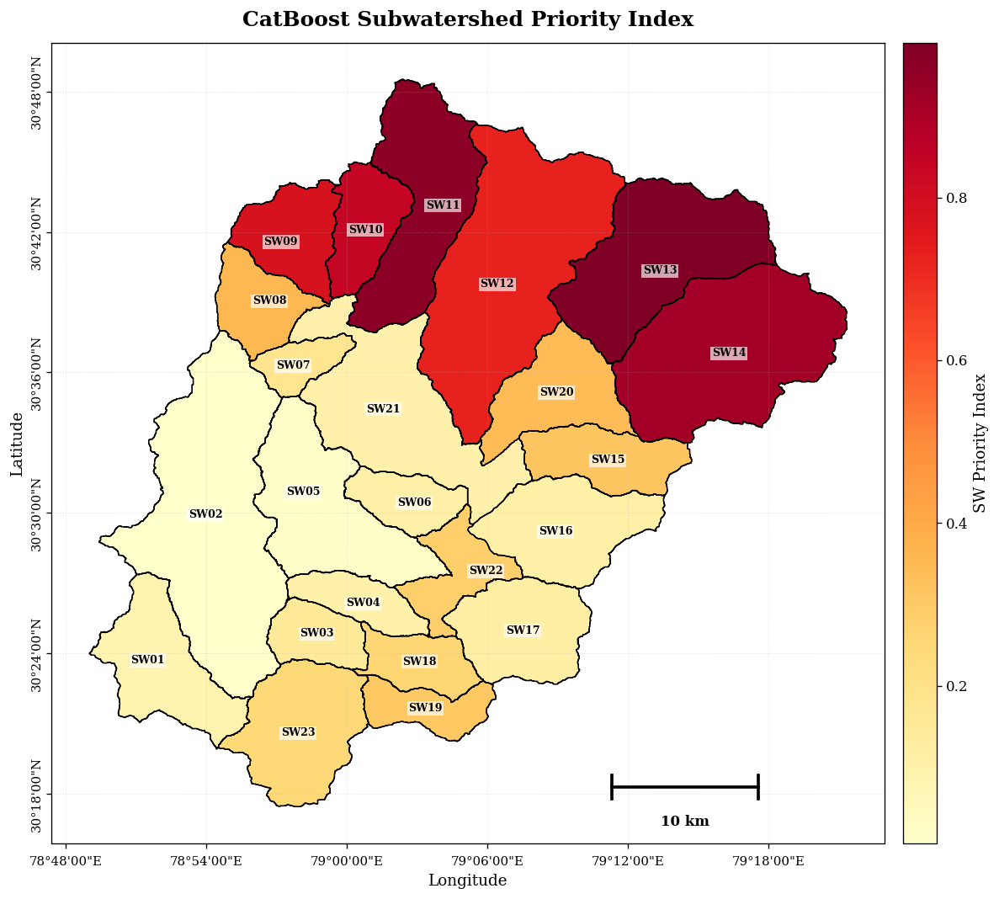

Saved SW priority map: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/publication_maps/CatBoost_SW_Priority_Index_Map.png


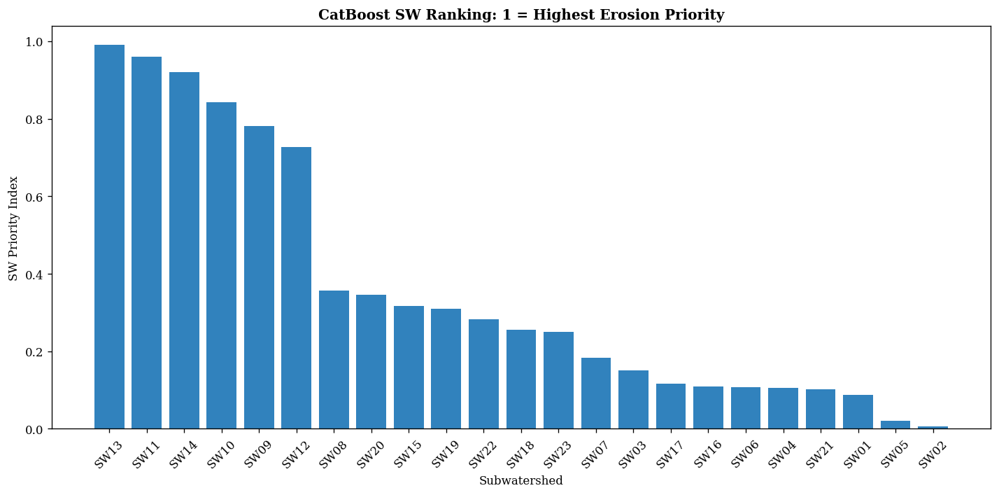

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/CatBoost_SW_Ranking_Barplot.png


,Model,SWID,OBJECTID_NUM,SW_Area_km2,Valid_Pixel_Count,Mean_Susceptibility,Mean_P_High,High_VeryHigh_Area_km2,High_VeryHigh_Percent,Mean_RUSLE,Total_RUSLE_Loss_tyr,Norm_Mean_Susceptibility,Norm_Mean_P_High,Norm_High_VeryHigh_Percent,Norm_Mean_RUSLE,SW_Priority_Index,Rank
0,CatBoost,SW13,13,115.469124,128078,0.788801,0.742257,88.8867,76.978760,128.122031,1.479414e+06,1.000000,1.000000,1.000000,0.933876,0.990081,1
1,CatBoost,SW11,11,95.099592,105520,0.765497,0.701050,69.6618,73.251418,132.809081,1.263009e+06,0.966207,0.939750,0.947104,1.000000,0.960841,2
2,CatBoost,SW14,14,146.817945,162664,0.736321,0.670355,103.9086,70.773773,130.204539,1.911636e+06,0.923901,0.894870,0.911943,0.963256,0.920155,3
3,CatBoost,SW10,10,39.055356,43368,0.684061,0.620616,25.4097,65.060730,124.563867,4.864886e+05,0.848121,0.822144,0.830867,0.883678,0.843510,4
4,CatBoost,SW09,9,44.835282,49716,0.635925,0.576332,27.0180,60.260578,122.665646,5.499749e+05,0.778322,0.757394,0.762747,0.856899,0.781762,5
5,CatBoost,SW12,12,180.621943,200521,0.602000,0.542766,103.0716,57.064827,116.336137,2.101286e+06,0.729129,0.708316,0.717395,0.767604,0.727350,6
6,CatBoost,SW08,8,36.882395,40930,0.327429,0.251733,10.1205,27.439921,106.611361,3.932082e+05,0.330988,0.282782,0.296977,0.630409,0.357048,7
7,CatBoost,SW20,20,57.583270,64015,0.318659,0.229202,14.4342,25.066656,111.210477,6.403863e+05,0.318272,0.249839,0.263297,0.695292,0.346722,8
8,CatBoost,SW15,15,45.393518,50320,0.316207,0.255176,12.4281,27.378579,90.418144,4.104398e+05,0.314716,0.287815,0.296107,0.401959,0.317355,9
9,CatBoost,SW19,19,27.668997,30546,0.273264,0.180264,5.7294,20.706930,120.400471,3.331360e+05,0.252447,0.178283,0.201427,0.824942,0.309577,10



Processing SW tables, ranking and map for: ExtraTrees


,Model,SWID,OBJECTID_NUM,SW_Area_km2,Class1_Very_Low_Pixel_Count,Class2_Low_Pixel_Count,Class3_Moderate_Pixel_Count,Class4_High_Pixel_Count,Class5_Very_High_Pixel_Count,Valid_Pixel_Count,Class1_Very_Low_Area_km2,Class1_Very_Low_Percent,Class2_Low_Area_km2,Class2_Low_Percent,Class3_Moderate_Area_km2,Class3_Moderate_Percent,Class4_High_Area_km2,Class4_High_Percent,Class5_Very_High_Area_km2,Class5_Very_High_Percent
0,ExtraTrees,SW23,23,75.956027,43224,17150,11946,7676,4118,84114,38.9016,51.387403,15.4350,20.388996,10.7514,14.202154,6.9084,9.125710,3.7062,4.895737
1,ExtraTrees,SW22,22,34.814826,18364,7166,6091,3860,3196,38677,16.5276,47.480415,6.4494,18.527807,5.4819,15.748378,3.4740,9.980092,2.8764,8.263309
2,ExtraTrees,SW21,21,119.779394,85537,18018,13825,9261,6448,133089,76.9833,64.270526,16.2162,13.538309,12.4425,10.387786,8.3349,6.958501,5.8032,4.844878
3,ExtraTrees,SW20,20,57.583270,27027,12173,9152,8008,7655,64015,24.3243,42.219792,10.9557,19.015856,8.2368,14.296649,7.2072,12.509568,6.8895,11.958135
4,ExtraTrees,SW19,19,27.668997,15274,4288,4492,4018,2474,30546,13.7466,50.003274,3.8592,14.037845,4.0428,14.705690,3.6162,13.153932,2.2266,8.099260


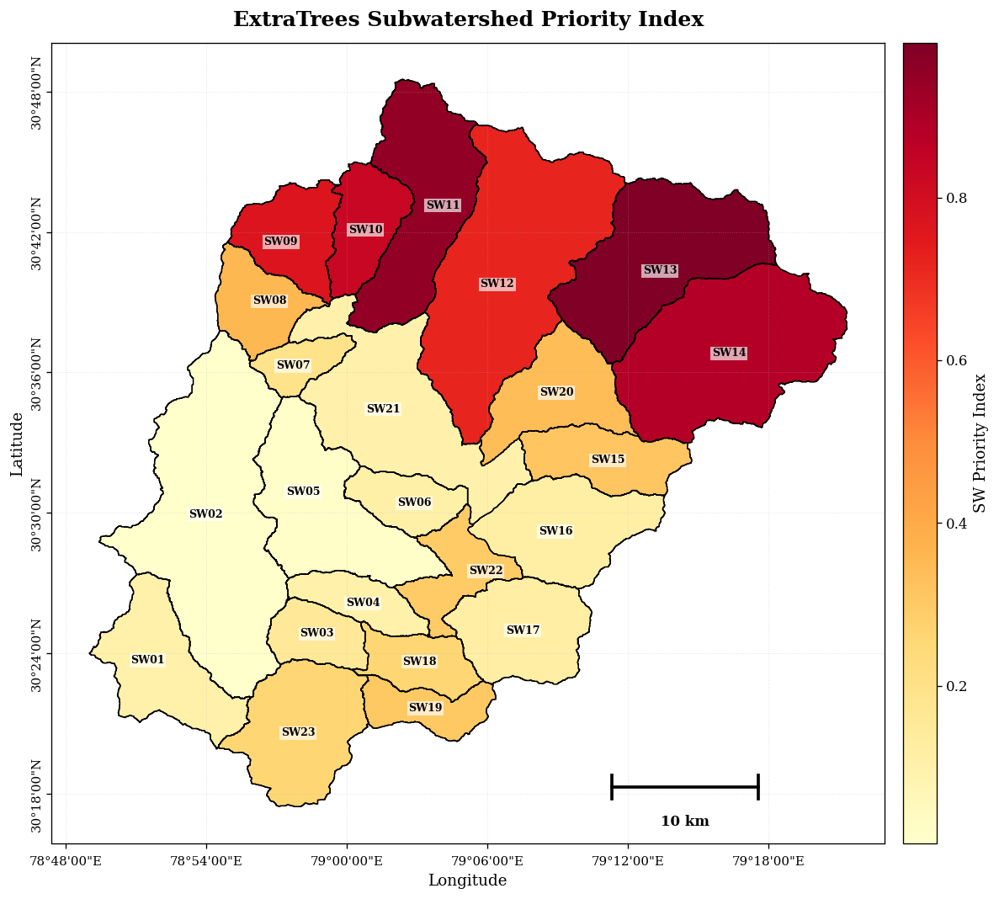

Saved SW priority map: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/publication_maps/ExtraTrees_SW_Priority_Index_Map.png


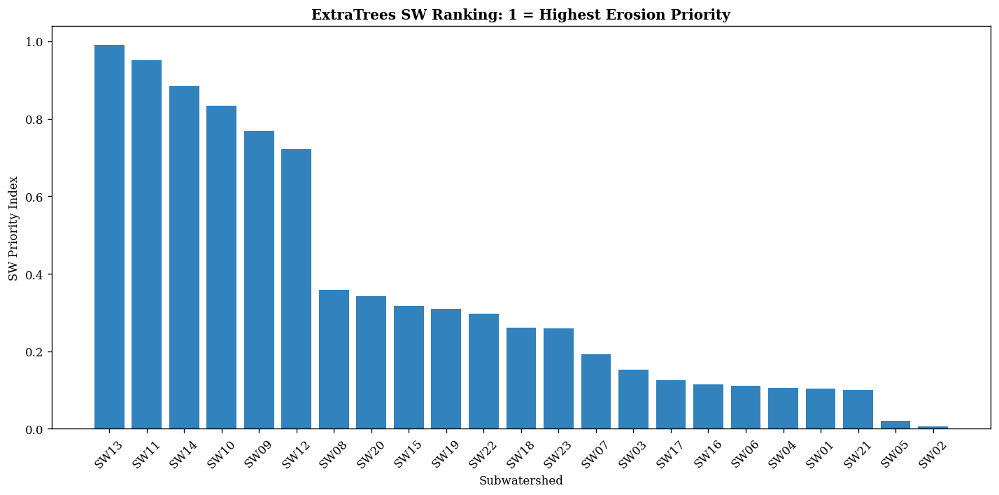

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/ExtraTrees_SW_Ranking_Barplot.png


,Model,SWID,OBJECTID_NUM,SW_Area_km2,Valid_Pixel_Count,Mean_Susceptibility,Mean_P_High,High_VeryHigh_Area_km2,High_VeryHigh_Percent,Mean_RUSLE,Total_RUSLE_Loss_tyr,Norm_Mean_Susceptibility,Norm_Mean_P_High,Norm_High_VeryHigh_Percent,Norm_Mean_RUSLE,SW_Priority_Index,Rank
0,ExtraTrees,SW13,13,115.469124,128078,0.767723,0.693705,87.3846,75.677893,128.122031,1.479414e+06,1.000000,1.000000,1.000000,0.933876,0.990081,1
1,ExtraTrees,SW11,11,95.099592,105520,0.738510,0.644507,68.4153,71.940687,132.809081,1.263009e+06,0.953801,0.920409,0.945274,1.000000,0.950677,2
2,ExtraTrees,SW14,14,146.817945,162664,0.694727,0.587766,100.5372,68.477460,130.204539,1.911636e+06,0.884560,0.828616,0.894560,0.963256,0.884379,3
3,ExtraTrees,SW10,10,39.055356,43368,0.662532,0.572125,25.1037,64.277227,124.563867,4.864886e+05,0.833646,0.803313,0.833054,0.883678,0.833449,4
4,ExtraTrees,SW09,9,44.835282,49716,0.618105,0.528828,26.5050,59.116390,122.665646,5.499749e+05,0.763385,0.733270,0.757481,0.856899,0.768703,5
5,ExtraTrees,SW12,12,180.621943,200521,0.592924,0.503280,101.6541,56.280039,116.336137,2.101286e+06,0.723564,0.691939,0.715947,0.767604,0.720740,6
6,ExtraTrees,SW08,8,36.882395,40930,0.348639,0.246959,10.1718,27.579012,106.611361,3.932082e+05,0.337237,0.277274,0.295662,0.630409,0.357907,7
7,ExtraTrees,SW20,20,57.583270,64015,0.340299,0.217907,14.0967,24.480548,111.210477,6.403863e+05,0.324047,0.230275,0.250290,0.695292,0.341540,8
8,ExtraTrees,SW15,15,45.393518,50320,0.339479,0.247090,12.3489,27.204105,90.418144,4.104398e+05,0.322752,0.277486,0.290172,0.401959,0.316801,9
9,ExtraTrees,SW19,19,27.668997,30546,0.295339,0.184494,5.8428,21.116775,120.400471,3.331360e+05,0.252946,0.176222,0.201032,0.824942,0.309181,10



Processing SW tables, ranking and map for: MLP_ANN


,Model,SWID,OBJECTID_NUM,SW_Area_km2,Class1_Very_Low_Pixel_Count,Class2_Low_Pixel_Count,Class3_Moderate_Pixel_Count,Class4_High_Pixel_Count,Class5_Very_High_Pixel_Count,Valid_Pixel_Count,Class1_Very_Low_Area_km2,Class1_Very_Low_Percent,Class2_Low_Area_km2,Class2_Low_Percent,Class3_Moderate_Area_km2,Class3_Moderate_Percent,Class4_High_Area_km2,Class4_High_Percent,Class5_Very_High_Area_km2,Class5_Very_High_Percent
0,MLP_ANN,SW23,23,75.956027,61693,3180,8358,2166,8717,84114,55.5237,73.344509,2.8620,3.780583,7.5222,9.936515,1.9494,2.575077,7.8453,10.363316
1,MLP_ANN,SW22,22,34.814826,25745,1667,4727,1212,5326,38677,23.1705,66.564108,1.5003,4.310055,4.2543,12.221734,1.0908,3.133645,4.7934,13.770458
2,MLP_ANN,SW21,21,119.779394,104429,3310,10111,2291,12948,133089,93.9861,78.465538,2.9790,2.487058,9.0999,7.597172,2.0619,1.721404,11.6532,9.728828
3,MLP_ANN,SW20,20,57.583270,38159,2399,7703,2002,13752,64015,34.3431,59.609467,2.1591,3.747559,6.9327,12.033117,1.8018,3.127392,12.3768,21.482465
4,MLP_ANN,SW19,19,27.668997,19518,1077,3750,1182,5019,30546,17.5662,63.897073,0.9693,3.525830,3.3750,12.276566,1.0638,3.869574,4.5171,16.430957


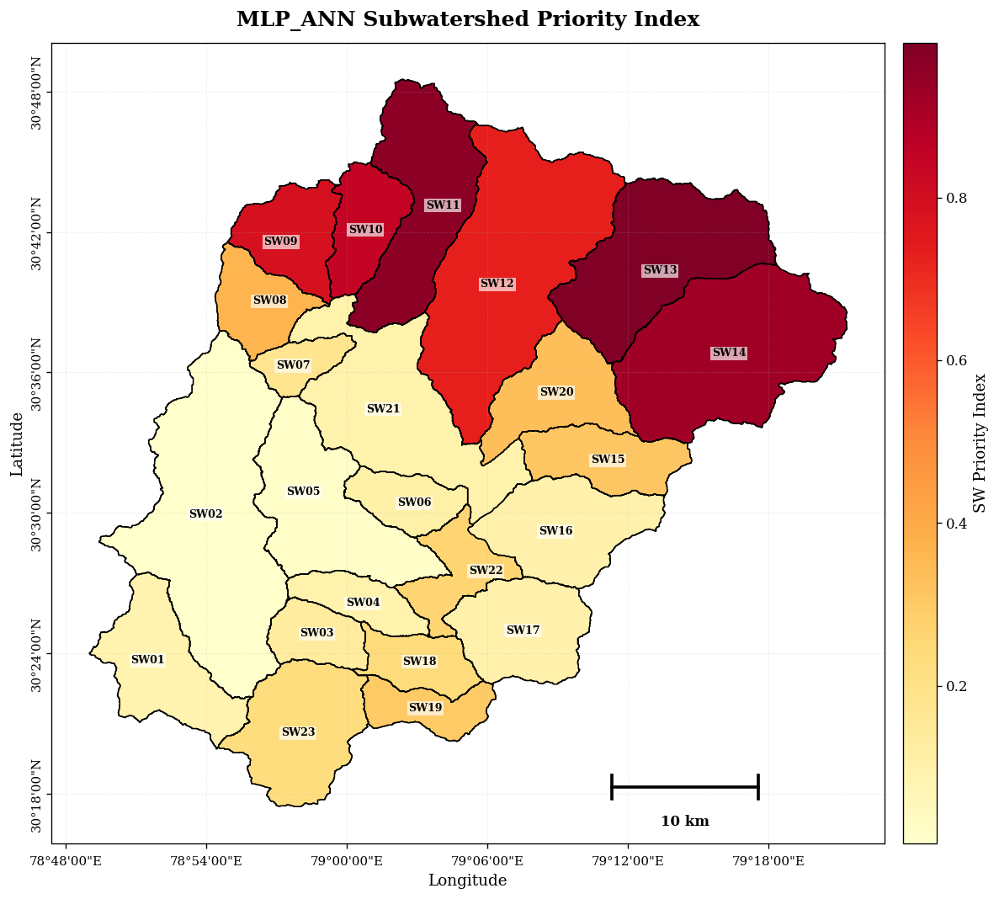

Saved SW priority map: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/publication_maps/MLP_ANN_SW_Priority_Index_Map.png


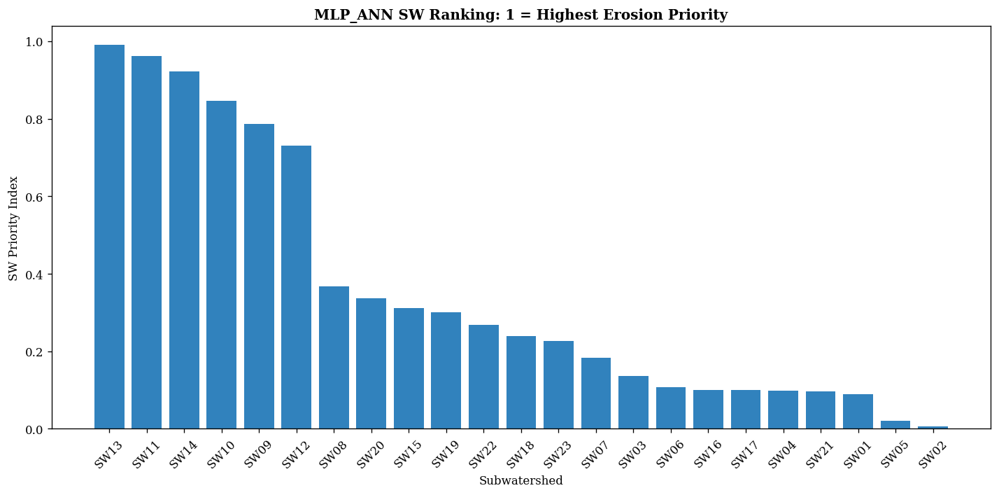

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/MLP_ANN_SW_Ranking_Barplot.png


,Model,SWID,OBJECTID_NUM,SW_Area_km2,Valid_Pixel_Count,Mean_Susceptibility,Mean_P_High,High_VeryHigh_Area_km2,High_VeryHigh_Percent,Mean_RUSLE,Total_RUSLE_Loss_tyr,Norm_Mean_Susceptibility,Norm_Mean_P_High,Norm_High_VeryHigh_Percent,Norm_Mean_RUSLE,SW_Priority_Index,Rank
0,MLP_ANN,SW13,13,115.469124,128078,0.796037,0.759171,88.8255,76.925759,128.122031,1.479414e+06,1.000000,1.000000,1.000000,0.933876,0.990081,1
1,MLP_ANN,SW11,11,95.099592,105520,0.772993,0.719580,69.8463,73.445425,132.809081,1.263009e+06,0.967089,0.943200,0.950389,1.000000,0.962713,2
2,MLP_ANN,SW14,14,146.817945,162664,0.743928,0.691292,103.5360,70.519990,130.204539,1.911636e+06,0.925577,0.902616,0.908688,0.963256,0.922111,3
3,MLP_ANN,SW10,10,39.055356,43368,0.691527,0.639079,25.4601,65.189778,124.563867,4.864886e+05,0.850735,0.827708,0.832707,0.883678,0.846314,4
4,MLP_ANN,SW09,9,44.835282,49716,0.645672,0.593549,27.1197,60.487409,122.665646,5.499749e+05,0.785244,0.762388,0.765676,0.856899,0.786365,5
5,MLP_ANN,SW12,12,180.621943,200521,0.608501,0.561406,103.6053,57.360306,116.336137,2.101286e+06,0.732155,0.716272,0.721101,0.767604,0.731291,6
6,MLP_ANN,SW08,8,36.882395,40930,0.334568,0.270820,10.4958,28.457480,106.611361,3.932082e+05,0.340915,0.299378,0.309100,0.630409,0.367592,7
7,MLP_ANN,SW20,20,57.583270,64015,0.307289,0.231006,14.1786,24.622777,111.210477,6.403863e+05,0.301955,0.242259,0.254437,0.695292,0.336528,8
8,MLP_ANN,SW15,15,45.393518,50320,0.312174,0.258669,12.3012,27.099023,90.418144,4.104398e+05,0.308931,0.281946,0.289735,0.401959,0.312300,9
9,MLP_ANN,SW19,19,27.668997,30546,0.262758,0.183908,5.5809,20.170229,120.400471,3.331360e+05,0.238354,0.174688,0.190967,0.824942,0.300948,10



Processing SW tables, ranking and map for: TabNet


,Model,SWID,OBJECTID_NUM,SW_Area_km2,Class1_Very_Low_Pixel_Count,Class2_Low_Pixel_Count,Class3_Moderate_Pixel_Count,Class4_High_Pixel_Count,Class5_Very_High_Pixel_Count,Valid_Pixel_Count,Class1_Very_Low_Area_km2,Class1_Very_Low_Percent,Class2_Low_Area_km2,Class2_Low_Percent,Class3_Moderate_Area_km2,Class3_Moderate_Percent,Class4_High_Area_km2,Class4_High_Percent,Class5_Very_High_Area_km2,Class5_Very_High_Percent
0,TabNet,SW23,23,75.956027,58478,5463,9305,3134,7734,84114,52.6302,69.522315,4.9167,6.494757,8.3745,11.062368,2.8206,3.725896,6.9606,9.194664
1,TabNet,SW22,22,34.814826,24630,2532,5092,1519,4904,38677,22.1670,63.681258,2.2788,6.546526,4.5828,13.165447,1.3671,3.927399,4.4136,12.679370
2,TabNet,SW21,21,119.779394,102352,5376,10258,3668,11435,133089,92.1168,76.904928,4.8384,4.039402,9.2322,7.707624,3.3012,2.756050,10.2915,8.591995
3,TabNet,SW20,20,57.583270,36726,4268,7462,3198,12361,64015,33.0534,57.370929,3.8412,6.667187,6.7158,11.656643,2.8782,4.995704,11.1249,19.309537
4,TabNet,SW19,19,27.668997,18942,1702,3965,1664,4273,30546,17.0478,62.011393,1.5318,5.571924,3.5685,12.980423,1.4976,5.447522,3.8457,13.988738


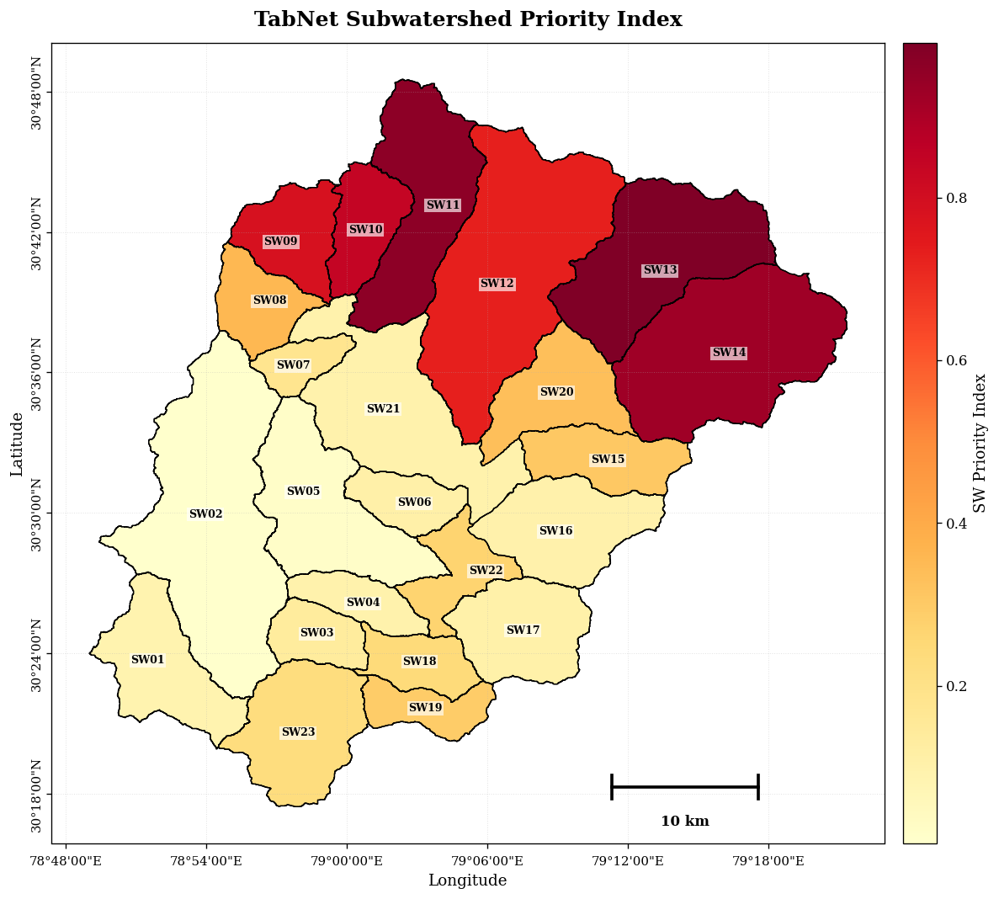

Saved SW priority map: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/publication_maps/TabNet_SW_Priority_Index_Map.png


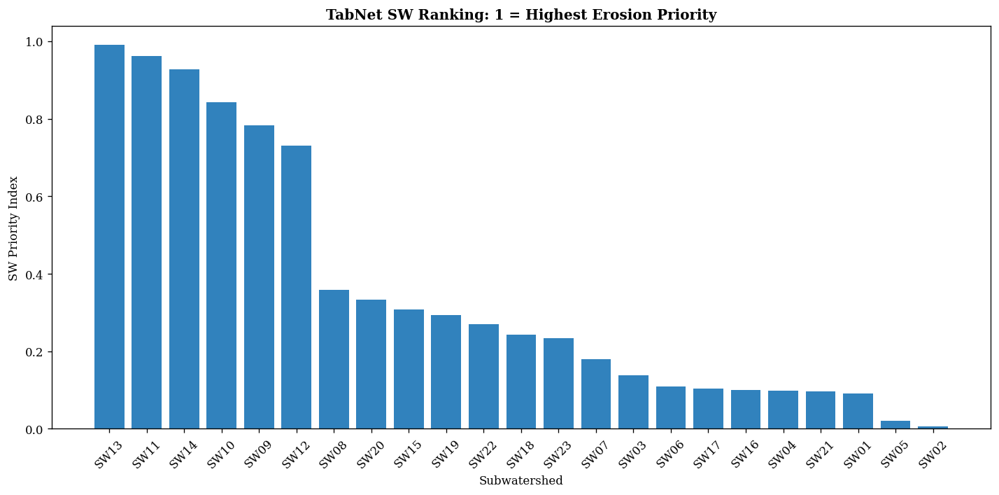

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/TabNet_SW_Ranking_Barplot.png


,Model,SWID,OBJECTID_NUM,SW_Area_km2,Valid_Pixel_Count,Mean_Susceptibility,Mean_P_High,High_VeryHigh_Area_km2,High_VeryHigh_Percent,Mean_RUSLE,Total_RUSLE_Loss_tyr,Norm_Mean_Susceptibility,Norm_Mean_P_High,Norm_High_VeryHigh_Percent,Norm_Mean_RUSLE,SW_Priority_Index,Rank
0,TabNet,SW13,13,115.469124,128078,0.789157,0.747825,88.5474,76.684915,128.122031,1.479414e+06,1.000000,1.000000,1.000000,0.933876,0.990081,1
1,TabNet,SW11,11,95.099592,105520,0.766654,0.705950,69.5403,73.123657,132.809081,1.263009e+06,0.967481,0.939174,0.949113,1.000000,0.961609,2
2,TabNet,SW14,14,146.817945,162664,0.742441,0.682241,103.8960,70.765191,130.204539,1.911636e+06,0.932491,0.904736,0.915412,0.963256,0.926751,3
3,TabNet,SW10,10,39.055356,43368,0.684137,0.622506,25.2990,64.777286,124.563867,4.864886e+05,0.848236,0.817968,0.829850,0.883678,0.842308,4
4,TabNet,SW09,9,44.835282,49716,0.637675,0.577146,27.1908,60.645989,122.665646,5.499749e+05,0.781092,0.752080,0.770818,0.856899,0.783155,5
5,TabNet,SW12,12,180.621943,200521,0.604170,0.549947,103.1220,57.092731,116.336137,2.101286e+06,0.732674,0.712572,0.720045,0.767604,0.730362,6
6,TabNet,SW08,8,36.882395,40930,0.328019,0.251391,10.2375,27.757145,106.611361,3.932082e+05,0.333605,0.278905,0.300864,0.630409,0.357902,7
7,TabNet,SW20,20,57.583270,64015,0.306003,0.220172,14.0031,24.318001,111.210477,6.403863e+05,0.301790,0.233556,0.251722,0.695292,0.333743,8
8,TabNet,SW15,15,45.393518,50320,0.309617,0.247876,12.0582,26.563705,90.418144,4.104398e+05,0.307013,0.273799,0.283811,0.401959,0.308311,9
9,TabNet,SW19,19,27.668997,30546,0.259615,0.169848,5.3433,19.311506,120.400471,3.331360e+05,0.234754,0.160458,0.180183,0.824942,0.293794,10


Model,SWID,OBJECTID_NUM,CatBoost,ExtraTrees,MLP_ANN,TabNet
0,SW01,1,21,20,21,21
1,SW02,2,23,23,23,23
2,SW03,3,15,15,15,15
3,SW04,4,19,19,19,19
4,SW05,5,22,22,22,22
5,SW06,6,18,18,16,16
6,SW07,7,14,14,14,14
7,SW08,8,7,7,7,7
8,SW09,9,5,5,5,5
9,SW10,10,4,4,4,4


,Consensus_Rank,SWID,OBJECTID_NUM,Average_Rank,Median_Rank,Average_SW_Priority_Index,Average_Mean_Susceptibility,Average_Mean_P_High,Average_High_VeryHigh_Percent,Mean_RUSLE
0,1,SW13,13,1.00,1.0,0.990081,0.785429,0.735739,76.566832,128.122031
1,2,SW11,11,2.00,2.0,0.958960,0.760913,0.692772,72.940297,132.809081
2,3,SW14,14,3.00,3.0,0.913349,0.729354,0.657914,70.134104,130.204539
3,4,SW10,10,4.00,4.0,0.841395,0.680564,0.613582,64.826255,124.563867
4,5,SW09,9,5.00,5.0,0.779996,0.634344,0.568964,60.127592,122.665646
5,6,SW12,12,6.00,6.0,0.727436,0.601899,0.539350,56.949476,116.336137
6,7,SW08,8,7.00,7.0,0.360112,0.334664,0.255226,27.808389,106.611361
7,8,SW20,20,8.00,8.0,0.339633,0.318063,0.224572,24.621995,111.210477
8,9,SW15,15,9.00,9.0,0.313692,0.319369,0.252203,27.061353,90.418144
9,10,SW19,19,10.00,10.0,0.303375,0.272744,0.179628,20.326360,120.400471


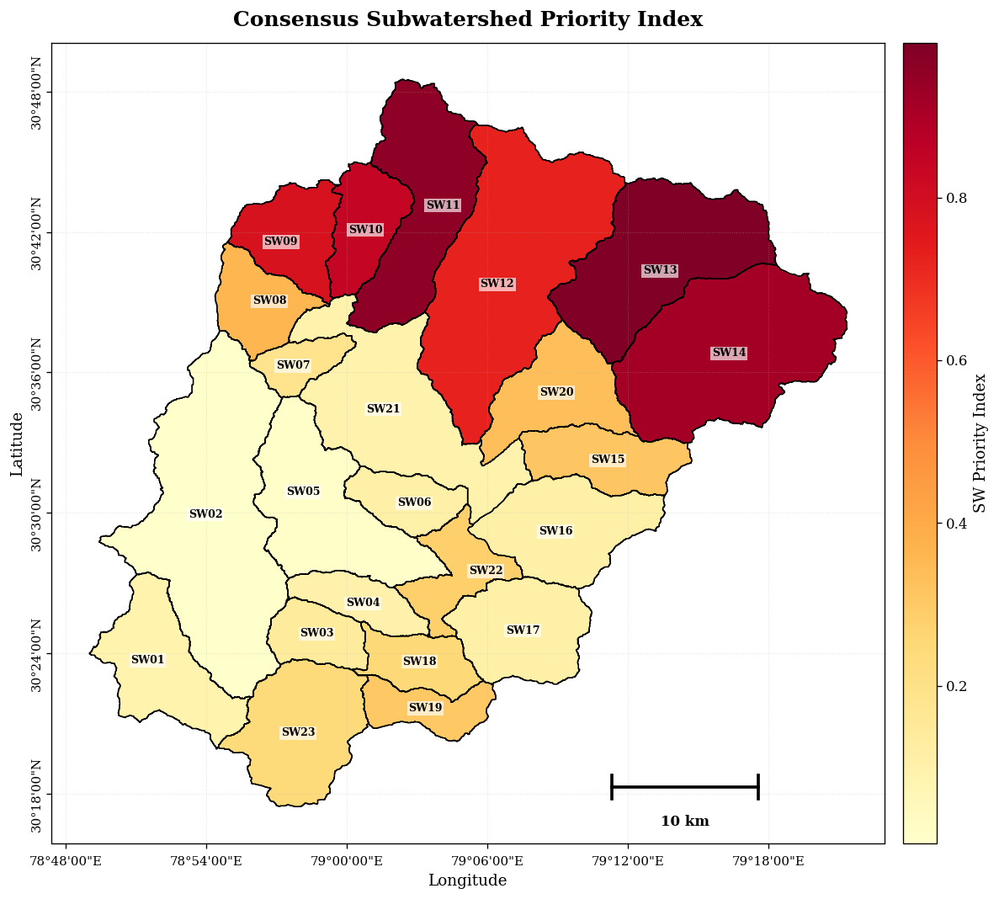

Saved SW priority map: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/publication_maps/Consensus_SW_Priority_Index_Map.png


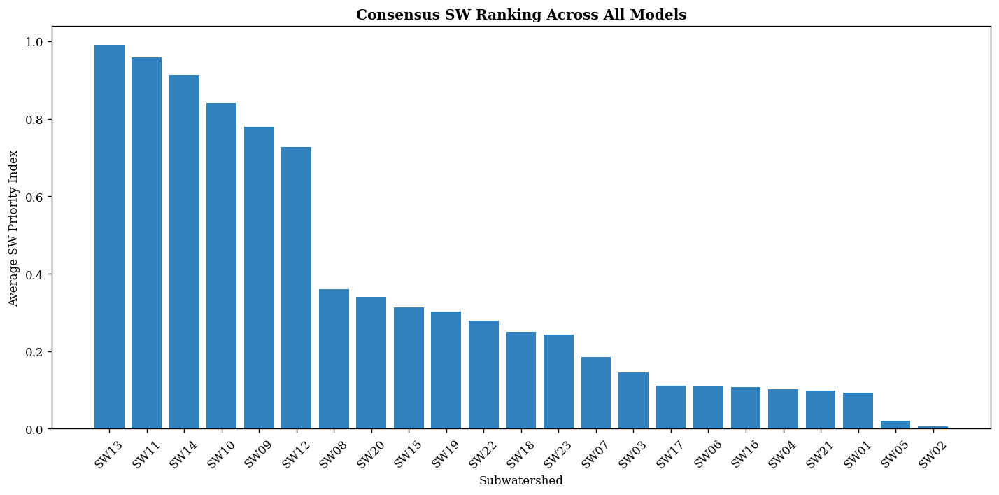

Saved: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots/Consensus_SW_Ranking_All_Models_Barplot.png
Saved combined class table: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/All_Models_SW_5Class_Pixel_Area_Percent_Table.csv
Saved long ranking table: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/All_Models_SW_Ranking_Long.csv
Saved wide ranking table: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/All_Models_SW_Ranking_Wide.csv
Saved consensus ranking table: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/tables/Consensus_SW_Ranking_All_Models.csv
Saved ranking output JSON: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_

In [21]:
# ============================================================
# CELL 16: SW CLASS AREA TABLES, RANKING AND SW PRIORITY MAPS
# For each SW and model:
# - pixel count for each 5-class category
# - area for each class
# - percentage for each class
# - ranking from highest to lowest erosion priority
# - SW priority index map with legend, DMS coordinates, grid and scale bar
# ============================================================

import json
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterstats import zonal_stats
from matplotlib.ticker import FuncFormatter
from mpl_toolkits.axes_grid1 import make_axes_locatable
from IPython.display import display

if sw_gdf is None:
    raise ValueError("SW polygons are missing. Run Cell 12 and ensure SW polygons are available.")

TABLE_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
MAP_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------
def minmax(series):
    s = pd.to_numeric(series, errors="coerce")
    mn, mx = s.min(), s.max()

    if pd.isna(mn) or pd.isna(mx) or abs(mx - mn) < 1e-12:
        return pd.Series(np.zeros(len(s)), index=s.index)

    return (s - mn) / (mx - mn)


def decimal_to_dms(value, is_lon=True):
    hemi = ("E" if value >= 0 else "W") if is_lon else ("N" if value >= 0 else "S")
    value = abs(value)

    deg = int(value)
    minutes_float = (value - deg) * 60
    minutes = int(minutes_float)
    seconds = int(round((minutes_float - minutes) * 60))

    if seconds == 60:
        seconds = 0
        minutes += 1

    if minutes == 60:
        minutes = 0
        deg += 1

    return f"{deg}°{minutes:02d}'{seconds:02d}\"{hemi}"


def lon_formatter(x, pos):
    return decimal_to_dms(x, is_lon=True)


def lat_formatter(y, pos):
    return decimal_to_dms(y, is_lon=False)


def add_scalebar_lonlat(ax, length_km=10):
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    lat_mid = (ymin + ymax) / 2
    km_per_deg_lon = 111.32 * np.cos(np.deg2rad(lat_mid))

    if km_per_deg_lon <= 0:
        return

    length_deg = length_km / km_per_deg_lon

    # Place scale bar in the lower-right empty/least intrusive area
    x_center = xmin + (xmax - xmin) * 0.76
    x0 = x_center - (length_deg / 2)
    x1 = x_center + (length_deg / 2)

    y0 = ymin + (ymax - ymin) * 0.070

    tick_height = (ymax - ymin) * 0.015
    label_offset = (ymax - ymin) * 0.035

    ax.plot([x0, x1], [y0, y0], color="black", linewidth=2.2, zorder=20)
    ax.plot([x0, x0], [y0 - tick_height, y0 + tick_height], color="black", linewidth=2.2, zorder=20)
    ax.plot([x1, x1], [y0 - tick_height, y0 + tick_height], color="black", linewidth=2.2, zorder=20)

    ax.text(
        (x0 + x1) / 2,
        y0 - label_offset,
        f"{length_km} km",
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
        color="black",
        zorder=20
    )


def plot_sw_priority_map(ranked_gdf_projected, model_name, out_png, value_col="SW_Priority_Index"):
    """
    Creates SW priority map with:
    - yellow-to-red colour ramp
    - SWID labels
    - DMS coordinates
    - grid
    - scale bar
    - colorbar legend
    """
    gdf_plot = ranked_gdf_projected.to_crs("EPSG:4326").copy()

    fig, ax = plt.subplots(figsize=(11, 9))

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.18)

    gdf_plot.plot(
        column=value_col,
        ax=ax,
        cmap="YlOrRd",
        edgecolor="black",
        linewidth=0.8,
        legend=True,
        cax=cax,
        missing_kwds={
            "color": "lightgrey",
            "edgecolor": "black",
            "label": "No data"
        }
    )

    cax.set_ylabel("SW Priority Index", fontsize=11)

    # Boundary overlay
    gdf_plot.boundary.plot(ax=ax, color="black", linewidth=0.8)

    # SW labels
    for _, row in gdf_plot.iterrows():
        rp = row.geometry.representative_point()
        ax.text(
            rp.x,
            rp.y,
            str(row["SWID"]),
            ha="center",
            va="center",
            fontsize=7.5,
            fontweight="bold",
            color="black",
            bbox=dict(facecolor="white", alpha=0.65, edgecolor="none", pad=1.0),
            zorder=15
        )

    # Add DMS coordinate formatting
    ax.xaxis.set_major_formatter(FuncFormatter(lon_formatter))
    ax.yaxis.set_major_formatter(FuncFormatter(lat_formatter))


    ax.tick_params(axis="x", labelrotation=0, labelsize=9, pad=6)
    ax.tick_params(axis="y", labelrotation=90, labelsize=9, pad=7)

    # Keep latitude labels centered on their grid tick
    for label in ax.get_yticklabels():
        label.set_verticalalignment("center")
        label.set_horizontalalignment("center")

    ax.set_xlabel("Longitude", fontsize=11)
    ax.set_ylabel("Latitude", fontsize=11)

    ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.35)

    add_scalebar_lonlat(ax, length_km=10)

    ax.set_title(
        f"{model_name} Subwatershed Priority Index",
        fontsize=15,
        fontweight="bold",
        pad=12
    )

    ax.set_aspect("equal", adjustable="box")

    fig.tight_layout()
    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved SW priority map:", out_png)


# ------------------------------------------------------------
# Main processing
# ------------------------------------------------------------
all_class_tables = []
all_rankings = []
ranking_outputs_by_model = {}

for model_name, outputs in prediction_raster_outputs_by_model.items():

    print("\nProcessing SW tables, ranking and map for:", model_name)

    f5_path = outputs["Final_5Class_Soil_Erodibility"]
    score_path = outputs["Susceptibility_Score"]
    phigh_path = outputs["P_high"]

    with rasterio.open(f5_path) as src:
        raster_crs = src.crs
        pixel_area_km2 = abs(src.transform.a * src.transform.e) / 1e6
        f5_nodata = src.nodata

    swp = sw_gdf.to_crs(raster_crs).copy()
    swp["SW_Area_km2"] = swp.geometry.area / 1e6

    # --------------------------------------------------------
    # Class pixel counts
    # --------------------------------------------------------
    class_stats = zonal_stats(
        swp,
        f5_path,
        categorical=True,
        nodata=f5_nodata,
        all_touched=False
    )

    class_rows = []

    for i, stats in enumerate(class_stats):

        row = {
            "Model": model_name,
            "SWID": swp.iloc[i]["SWID"],
            "OBJECTID_NUM": int(swp.iloc[i]["OBJECTID_NUM"]),
            "SW_Area_km2": swp.iloc[i]["SW_Area_km2"]
        }

        total_valid = 0

        for cls in range(1, 6):
            cnt = int(stats.get(cls, 0))
            row[f"Class{cls}_{CLASS5_LABELS[cls].replace(' ', '_')}_Pixel_Count"] = cnt
            total_valid += cnt

        row["Valid_Pixel_Count"] = total_valid

        for cls in range(1, 6):
            name = CLASS5_LABELS[cls].replace(" ", "_")
            cnt = row[f"Class{cls}_{name}_Pixel_Count"]

            row[f"Class{cls}_{name}_Area_km2"] = cnt * pixel_area_km2
            row[f"Class{cls}_{name}_Percent"] = (cnt / total_valid * 100) if total_valid > 0 else np.nan

        class_rows.append(row)

    class_df = pd.DataFrame(class_rows)

    class_csv = TABLE_DIR / f"{model_name}_SW_5Class_Pixel_Area_Percent_Table.csv"
    class_df.to_csv(class_csv, index=False)

    all_class_tables.append(class_df)

    display(class_df.head())

    # --------------------------------------------------------
    # Ranking stats
    # --------------------------------------------------------
    score_stats = zonal_stats(
        swp,
        score_path,
        stats=["mean", "count"],
        nodata=np.nan
    )

    phigh_stats = zonal_stats(
        swp,
        phigh_path,
        stats=["mean"],
        nodata=np.nan
    )

    rank_df = class_df[
        ["Model", "SWID", "OBJECTID_NUM", "SW_Area_km2", "Valid_Pixel_Count"]
    ].copy()

    rank_df["Mean_Susceptibility"] = [s.get("mean", np.nan) for s in score_stats]
    rank_df["Mean_P_High"] = [s.get("mean", np.nan) for s in phigh_stats]

    high_area_cols = [
        "Class4_High_Area_km2",
        "Class5_Very_High_Area_km2"
    ]

    rank_df["High_VeryHigh_Area_km2"] = class_df[high_area_cols].sum(axis=1)
    rank_df["High_VeryHigh_Percent"] = rank_df["High_VeryHigh_Area_km2"] / rank_df["SW_Area_km2"] * 100

    if rusle_sw_stats is not None and "SWID" in rusle_sw_stats.columns:
        use_cols = [
            c for c in ["SWID", "Mean_RUSLE", "Total_RUSLE_Loss_tyr"]
            if c in rusle_sw_stats.columns
        ]

        rank_df = rank_df.merge(
            rusle_sw_stats[use_cols],
            on="SWID",
            how="left"
        )

    else:
        rank_df["Mean_RUSLE"] = np.nan
        rank_df["Total_RUSLE_Loss_tyr"] = np.nan

    rank_df["Norm_Mean_Susceptibility"] = minmax(rank_df["Mean_Susceptibility"])
    rank_df["Norm_Mean_P_High"] = minmax(rank_df["Mean_P_High"])
    rank_df["Norm_High_VeryHigh_Percent"] = minmax(rank_df["High_VeryHigh_Percent"])
    rank_df["Norm_Mean_RUSLE"] = minmax(rank_df["Mean_RUSLE"])

    rank_df["SW_Priority_Index"] = (
        0.40 * rank_df["Norm_Mean_Susceptibility"].fillna(0) +
        0.25 * rank_df["Norm_Mean_P_High"].fillna(0) +
        0.20 * rank_df["Norm_High_VeryHigh_Percent"].fillna(0) +
        0.15 * rank_df["Norm_Mean_RUSLE"].fillna(0)
    )

    rank_df = rank_df.sort_values("SW_Priority_Index", ascending=False).reset_index(drop=True)
    rank_df["Rank"] = np.arange(1, len(rank_df) + 1)

    rank_csv = TABLE_DIR / f"{model_name}_SW_Ranking_1_Highest_to_23_Lowest.csv"
    rank_df.to_csv(rank_csv, index=False)

    all_rankings.append(rank_df)

    # --------------------------------------------------------
    # SW priority index map
    # --------------------------------------------------------
    ranked_gdf = swp.merge(
        rank_df,
        on=["SWID", "OBJECTID_NUM"],
        how="left"
    )

    ranking_geojson = TABLE_DIR / f"{model_name}_SW_Ranking_Map.geojson"
    ranked_gdf.to_file(ranking_geojson, driver="GeoJSON")

    priority_map_png = MAP_DIR / f"{model_name}_SW_Priority_Index_Map.png"
    plot_sw_priority_map(
        ranked_gdf_projected=ranked_gdf,
        model_name=model_name,
        out_png=priority_map_png,
        value_col="SW_Priority_Index"
    )

    # --------------------------------------------------------
    # Ranking bar plot in blue
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(12, 6))

    plot_df = rank_df.sort_values("Rank")

    ax.bar(
        plot_df["SWID"],
        plot_df["SW_Priority_Index"],
        color="#3182bd"
    )

    ax.set_title(
        f"{model_name} SW Ranking: 1 = Highest Erosion Priority",
        fontweight="bold"
    )

    ax.set_xlabel("Subwatershed")
    ax.set_ylabel("SW Priority Index")
    ax.tick_params(axis="x", rotation=45)

    fig.tight_layout()

    bar_png = PLOT_DIR / f"{model_name}_SW_Ranking_Barplot.png"
    save_show(fig, bar_png)

    display(rank_df)

    ranking_outputs_by_model[model_name] = {
        "class_table": str(class_csv),
        "ranking_table": str(rank_csv),
        "ranking_geojson": str(ranking_geojson),
        "priority_map": str(priority_map_png),
        "ranking_barplot": str(bar_png)
    }


# ------------------------------------------------------------
# Combined tables
# ------------------------------------------------------------
all_class_df = pd.concat(all_class_tables, ignore_index=True)

all_class_csv = TABLE_DIR / "All_Models_SW_5Class_Pixel_Area_Percent_Table.csv"
all_class_df.to_csv(all_class_csv, index=False)

all_rankings_df = pd.concat(all_rankings, ignore_index=True)

all_rankings_long_csv = TABLE_DIR / "All_Models_SW_Ranking_Long.csv"
all_rankings_df.to_csv(all_rankings_long_csv, index=False)

rank_wide = all_rankings_df.pivot_table(
    index=["SWID", "OBJECTID_NUM"],
    columns="Model",
    values="Rank",
    aggfunc="first"
).reset_index()

rank_wide_csv = TABLE_DIR / "All_Models_SW_Ranking_Wide.csv"
rank_wide.to_csv(rank_wide_csv, index=False)

display(rank_wide)


# ------------------------------------------------------------
# Consensus ranking
# ------------------------------------------------------------
consensus = all_rankings_df.groupby(["SWID", "OBJECTID_NUM"]).agg(
    Average_Rank=("Rank", "mean"),
    Median_Rank=("Rank", "median"),
    Average_SW_Priority_Index=("SW_Priority_Index", "mean"),
    Average_Mean_Susceptibility=("Mean_Susceptibility", "mean"),
    Average_Mean_P_High=("Mean_P_High", "mean"),
    Average_High_VeryHigh_Percent=("High_VeryHigh_Percent", "mean"),
    Mean_RUSLE=("Mean_RUSLE", "mean")
).reset_index()

consensus = consensus.sort_values(
    ["Average_Rank", "Average_SW_Priority_Index"],
    ascending=[True, False]
).reset_index(drop=True)

consensus["Consensus_Rank"] = np.arange(1, len(consensus) + 1)

consensus = consensus[
    [
        "Consensus_Rank",
        "SWID",
        "OBJECTID_NUM",
        "Average_Rank",
        "Median_Rank",
        "Average_SW_Priority_Index",
        "Average_Mean_Susceptibility",
        "Average_Mean_P_High",
        "Average_High_VeryHigh_Percent",
        "Mean_RUSLE"
    ]
]

consensus_csv = TABLE_DIR / "Consensus_SW_Ranking_All_Models.csv"
consensus.to_csv(consensus_csv, index=False)

display(consensus)

# ------------------------------------------------------------
# Consensus SW priority map
# ------------------------------------------------------------
consensus_gdf = sw_gdf.copy()

if consensus_gdf.crs is None:
    consensus_gdf = consensus_gdf.set_crs("EPSG:4326", allow_override=True)

consensus_gdf_projected = consensus_gdf.to_crs(swp.crs).merge(
    consensus,
    on=["SWID", "OBJECTID_NUM"],
    how="left"
)

consensus_geojson = TABLE_DIR / "Consensus_SW_Ranking_Map.geojson"
consensus_gdf_projected.to_file(consensus_geojson, driver="GeoJSON")

consensus_map_png = MAP_DIR / "Consensus_SW_Priority_Index_Map.png"

plot_sw_priority_map(
    ranked_gdf_projected=consensus_gdf_projected,
    model_name="Consensus",
    out_png=consensus_map_png,
    value_col="Average_SW_Priority_Index"
)

# ------------------------------------------------------------
# Consensus bar plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

plot_df = consensus.sort_values("Consensus_Rank")

ax.bar(
    plot_df["SWID"],
    plot_df["Average_SW_Priority_Index"],
    color="#3182bd"
)

ax.set_title(
    "Consensus SW Ranking Across All Models",
    fontweight="bold"
)

ax.set_xlabel("Subwatershed")
ax.set_ylabel("Average SW Priority Index")
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()

consensus_bar_png = PLOT_DIR / "Consensus_SW_Ranking_All_Models_Barplot.png"
save_show(fig, consensus_bar_png)

# ------------------------------------------------------------
# Save output reference JSON
# ------------------------------------------------------------
ranking_outputs_by_model["Consensus"] = {
    "ranking_table": str(consensus_csv),
    "ranking_geojson": str(consensus_geojson),
    "priority_map": str(consensus_map_png),
    "ranking_barplot": str(consensus_bar_png)
}

with open(TABLE_DIR / "Ranking_Outputs_By_Model.json", "w") as f:
    json.dump(ranking_outputs_by_model, f, indent=2)

print("Saved combined class table:", all_class_csv)
print("Saved long ranking table:", all_rankings_long_csv)
print("Saved wide ranking table:", rank_wide_csv)
print("Saved consensus ranking table:", consensus_csv)
print("Saved ranking output JSON:", TABLE_DIR / "Ranking_Outputs_By_Model.json")

print("Cell 16 completed.")

# EXPORT COLOR-MAPPED GEOTIFFS FOR THE FOUR MODELS


In [22]:
# ============================================================
# NEW CELL: EXPORT COLOR-MAPPED GEOTIFFS FOR THE FOUR MODELS
#
# INPUTS:
#   CatBoost_Final_5Class_Soil_Erodibility.tif
#   ExtraTrees_Final_5Class_Soil_Erodibility.tif
#   MLP_ANN_Final_5Class_Soil_Erodibility.tif
#   TabNet_Final_5Class_Soil_Erodibility.tif
#
# OUTPUTS:
#   CatBoost_colormap.tif
#   ExtraTrees_colormap.tif
#   MLP_ANN_colormap.tif
#   TabNet_colormap.tif
#
# CLASS CODING:
#   1 = Very Low
#   2 = Low
#   3 = Moderate
#   4 = High
#   5 = Very High
#
# The output rasters retain:
# - original spatial extent
# - CRS
# - transform
# - cell size
# - class values
# - embedded raster color table
# ============================================================

from pathlib import Path

import numpy as np
import rasterio

from matplotlib.colors import to_rgba


# ------------------------------------------------------------
# 1. Model names and expected source files
# ------------------------------------------------------------

MODEL_NAMES = [
    "CatBoost",
    "ExtraTrees",
    "MLP_ANN",
    "TabNet"
]


SOURCE_FILENAMES = {

    "CatBoost":
        "CatBoost_Final_5Class_Soil_Erodibility.tif",

    "ExtraTrees":
        "ExtraTrees_Final_5Class_Soil_Erodibility.tif",

    "MLP_ANN":
        "MLP_ANN_Final_5Class_Soil_Erodibility.tif",

    "TabNet":
        "TabNet_Final_5Class_Soil_Erodibility.tif"
}


# ------------------------------------------------------------
# 2. Class names
# ------------------------------------------------------------

CLASS5_LABELS = {

    1: "Very Low",

    2: "Low",

    3: "Moderate",

    4: "High",

    5: "Very High"
}


# ------------------------------------------------------------
# 3. Obtain the EXACT five colors used for the PNG maps
#
# Priority:
# 1. Use CLASS5_COLORS already defined in the notebook.
# 2. Otherwise use the approved fallback colors.
#
# This ensures the GeoTIFFs match the PNG maps.
# ------------------------------------------------------------

if "CLASS5_COLORS" in globals():

    print(
        "Using existing CLASS5_COLORS from the notebook."
    )

    existing_colors = CLASS5_COLORS


    # Handle dictionary format
    if isinstance(
        existing_colors,
        dict
    ):

        ordered_colors = [

            existing_colors[i]

            for i in range(
                1,
                6
            )
        ]


    # Handle list or tuple format
    else:

        ordered_colors = list(
            existing_colors
        )


        if len(
            ordered_colors
        ) < 5:

            raise ValueError(

                "CLASS5_COLORS exists, but it contains "
                "fewer than five colors."
            )


        ordered_colors = (
            ordered_colors[
                :5
            ]
        )


else:

    print(
        "CLASS5_COLORS was not found. "
        "Using the approved five-class color scheme."
    )


    ordered_colors = [

        "#1A9850",   # 1 = Very Low  - Green

        "#FFFF00",   # 2 = Low       - Yellow

        "#FDAE61",   # 3 = Moderate  - Orange

        "#D73027",   # 4 = High      - Red

        "#762A83"    # 5 = Very High - Purple
    ]


# ------------------------------------------------------------
# 4. Convert colors to rasterio RGBA format
# ------------------------------------------------------------

def color_to_rgba_255(color):

    r, g, b, a = to_rgba(
        color
    )


    return (

        int(
            round(
                r * 255
            )
        ),

        int(
            round(
                g * 255
            )
        ),

        int(
            round(
                b * 255
            )
        ),

        int(
            round(
                a * 255
            )
        )
    )


CLASS5_COLORMAP = {

    0:
        (
            255,
            255,
            255,
            0
        ),

    1:
        color_to_rgba_255(
            ordered_colors[
                0
            ]
        ),

    2:
        color_to_rgba_255(
            ordered_colors[
                1
            ]
        ),

    3:
        color_to_rgba_255(
            ordered_colors[
                2
            ]
        ),

    4:
        color_to_rgba_255(
            ordered_colors[
                3
            ]
        ),

    5:
        color_to_rgba_255(
            ordered_colors[
                4
            ]
        )
}


print(
    "\nEmbedded GeoTIFF color table:"
)


for class_value in range(
    1,
    6
):

    print(

        f"{class_value} = "
        f"{CLASS5_LABELS[class_value]} = "
        f"{CLASS5_COLORMAP[class_value]}"
    )


# ------------------------------------------------------------
# 5. Identify the root folder for the existing GeoTIFFs
#
# The code searches known notebook folders first, then
# DRIVE_PROJECT_DIR recursively if necessary.
# ------------------------------------------------------------

SEARCH_FOLDERS = []


for variable_name in [

    "MAP_DIR",

    "RASTER_DIR",

    "OUTPUT_DIR",

    "FULL_AREA_DIR",

    "FULL_AREA_PREDICTION_DIR",

    "DRIVE_PROJECT_DIR"

]:

    if variable_name in globals():

        folder = Path(
            globals()[
                variable_name
            ]
        )


        if folder.exists():

            SEARCH_FOLDERS.append(
                folder
            )


# Remove duplicates while preserving order

SEARCH_FOLDERS = list(

    dict.fromkeys(
        SEARCH_FOLDERS
    )
)


if len(
    SEARCH_FOLDERS
) == 0:

    raise ValueError(

        "No valid project output folder was found. "
        "Run the earlier project setup cells first."
    )


print(
    "\nSearch folders:"
)


for folder in SEARCH_FOLDERS:

    print(
        " -",
        folder
    )


# ------------------------------------------------------------
# 6. Find an existing model GeoTIFF
# ------------------------------------------------------------

def find_source_tif(
    filename
):


    # First check direct folder locations

    for folder in SEARCH_FOLDERS:


        direct_path = (

            folder /

            filename
        )


        if direct_path.exists():

            return (
                direct_path
            )


    # Then search recursively

    for folder in SEARCH_FOLDERS:


        matches = list(

            folder.rglob(
                filename
            )
        )


        if len(
            matches
        ) > 0:

            return (
                matches[
                    0
                ]
            )


    return None


# ------------------------------------------------------------
# 7. Export one color-mapped GeoTIFF
# ------------------------------------------------------------

def export_colormap_tif(
    source_tif,
    output_tif,
    model_name
):


    print(
        f"\nProcessing {model_name}"
    )


    print(
        "Input:",
        source_tif
    )


    with rasterio.open(
        source_tif
    ) as src:


        arr = (
            src.read(
                1
            )
        )


        src_profile = (
            src.profile.copy()
        )


        src_nodata = (
            src.nodata
        )


        src_tags = (
            src.tags()
        )


    # --------------------------------------------------------
    # Create valid-data mask
    # --------------------------------------------------------

    valid_mask = np.isfinite(
        arr
    )


    if src_nodata is not None:

        valid_mask &= (

            arr != src_nodata
        )


    # --------------------------------------------------------
    # Convert output to unsigned 8-bit integer
    #
    # 0 = NoData
    # 1–5 = valid erosion classes
    # --------------------------------------------------------

    out_arr = np.zeros(

        arr.shape,

        dtype=np.uint8
    )


    for class_value in range(
        1,
        6
    ):

        out_arr[

            valid_mask

            &

            np.isclose(
                arr,
                class_value
            )

        ] = class_value


    # --------------------------------------------------------
    # Check class values
    # --------------------------------------------------------

    unique_classes = np.unique(

        out_arr[
            out_arr > 0
        ]
    )


    print(
        "Classes found:",
        unique_classes.tolist()
    )


    unexpected_classes = [

        int(v)

        for v in unique_classes

        if v not in [
            1,
            2,
            3,
            4,
            5
        ]
    ]


    if unexpected_classes:

        raise ValueError(

            f"{model_name} contains unexpected classes: "
            f"{unexpected_classes}"
        )


    # --------------------------------------------------------
    # Update GeoTIFF profile
    #
    # uint8 is used because the raster contains only classes
    # 1–5 and it supports an embedded palette efficiently.
    # --------------------------------------------------------

    out_profile = (
        src_profile.copy()
    )


    out_profile.update(

        driver="GTiff",

        dtype="uint8",

        count=1,

        nodata=0,

        compress="lzw",

        predictor=2,

        tiled=True
    )


    # --------------------------------------------------------
    # Write output raster and embedded colormap
    # --------------------------------------------------------

    with rasterio.open(

        output_tif,

        "w",

        **out_profile

    ) as dst:


        dst.write(

            out_arr,

            1
        )


        dst.set_band_description(

            1,

            f"{model_name}_5Class_Soil_Erodibility"
        )


        # Write embedded raster color table

        dst.write_colormap(

            1,

            CLASS5_COLORMAP
        )


        # Preserve original metadata where available

        if src_tags:

            dst.update_tags(
                **src_tags
            )


        # Add clear class metadata

        dst.update_tags(

            MODEL=
                model_name,

            CLASS_1=
                "Very Low",

            CLASS_2=
                "Low",

            CLASS_3=
                "Moderate",

            CLASS_4=
                "High",

            CLASS_5=
                "Very High",

            COLOR_TABLE=
                "Embedded",

            NODATA_CLASS=
                "0"
        )


    # --------------------------------------------------------
    # Verification
    # --------------------------------------------------------

    with rasterio.open(
        output_tif
    ) as check:


        saved_classes = np.unique(

            check.read(
                1
            )
        )


        saved_colormap = (
            check.colormap(
                1
            )
        )


        print(
            "Output:",
            output_tif
        )


        print(
            "Saved classes:",
            saved_classes.tolist()
        )


        print(
            "Embedded colormap verified:",
            all(

                class_value
                in saved_colormap

                for class_value
                in range(
                    1,
                    6
                )
            )
        )


        print(
            "CRS:",
            check.crs
        )


        print(
            "Cell size:",
            (
                abs(
                    check.transform.a
                ),
                abs(
                    check.transform.e
                )
            )
        )


# ------------------------------------------------------------
# 8. Process all four models
# ------------------------------------------------------------

exported_colormap_tifs = {}


for model_name in MODEL_NAMES:


    source_filename = (

        SOURCE_FILENAMES[
            model_name
        ]
    )


    source_tif = find_source_tif(

        source_filename
    )


    if source_tif is None:

        raise FileNotFoundError(

            f"Could not find the classified GeoTIFF for "
            f"{model_name}:\n"
            f"{source_filename}"
        )


    # Save beside the original GeoTIFF

    output_tif = (

        source_tif.parent /

        f"{model_name}_colormap.tif"
    )


    export_colormap_tif(

        source_tif=
            source_tif,

        output_tif=
            output_tif,

        model_name=
            model_name
    )


    exported_colormap_tifs[

        model_name

    ] = output_tif


# ------------------------------------------------------------
# 9. Final summary
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 70
)


print(
    "COLOR-MAPPED GEOTIFF EXPORT COMPLETED SUCCESSFULLY"
)


print(
    "=" * 70
)


for model_name, output_tif in (
    exported_colormap_tifs.items()
):


    print(

        f"{model_name}: "
        f"{output_tif}"
    )


print(
    "\nThe four GeoTIFFs now contain:"
)


print(
    "1 = Very Low  → Green"
)


print(
    "2 = Low       → Yellow"
)


print(
    "3 = Moderate  → Orange"
)


print(
    "4 = High      → Red"
)


print(
    "5 = Very High → Purple"
)


print(
    "\nThe color table is embedded directly in each GeoTIFF."
)

Using existing CLASS5_COLORS from the notebook.

Embedded GeoTIFF color table:
1 = Very Low = (26, 152, 80, 255)
2 = Low = (255, 255, 0, 255)
3 = Moderate = (253, 174, 97, 255)
4 = High = (215, 25, 28, 255)
5 = Very High = (118, 42, 131, 255)

Search folders:
 - /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/publication_maps
 - /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/rasters
 - /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/plots
 - /content/drive/MyDrive/Mandakini_23SW_Model_Inputs

Processing CatBoost
Input: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/rasters/CatBoost_Final_5Class_Soil_Erodibility.tif
Classes found: [1, 2, 3, 4, 5]
Output: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_13074

# 17B EXPORT CONSENSUS SUBWATERSHED PRIORITY INDEX

In [23]:
# ============================================================
# NEW CELL: EXPORT CONSENSUS SUBWATERSHED PRIORITY INDEX
# AS COLOR-MAPPED GEOTIFF
#
# OUTPUT ONLY:
#   Consensus_colormap.tif
#
# THIS VERSION:
# - does NOT assume the consensus index is already in a GeoDataFrame
# - finds the 23-subwatershed polygon GeoDataFrame
# - finds the consensus priority table
# - joins the table to the polygons
# - rasterizes to the 30 m predictor grid
# - embeds the same YlOrRd color progression
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio

from rasterio.features import rasterize

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Output filename
# ------------------------------------------------------------

OUTPUT_NAME = "Consensus_colormap.tif"


# ------------------------------------------------------------
# 2. Reference 30 m raster
# ------------------------------------------------------------

if "stack_path" in globals():

    reference_raster = Path(
        stack_path
    )

else:

    reference_raster = (

        Path(
            RASTER_DIR
        )

        / "Predictor_Stack_10Bands_StrictNames.tif"
    )


if not reference_raster.exists():

    raise FileNotFoundError(

        "Reference raster not found:\n"
        f"{reference_raster}"
    )


print(
    "Reference raster:",
    reference_raster
)


# ------------------------------------------------------------
# 3. Read reference grid
# ------------------------------------------------------------

with rasterio.open(
    reference_raster
) as ref:

    ref_crs = (
        ref.crs
    )

    ref_transform = (
        ref.transform
    )

    ref_width = (
        ref.width
    )

    ref_height = (
        ref.height
    )

    ref_profile = (
        ref.profile.copy()
    )


print(
    "Reference CRS:",
    ref_crs
)


print(
    "Reference cell size:",
    (
        abs(
            ref_transform.a
        ),
        abs(
            ref_transform.e
        )
    )
)


# ============================================================
# 4. FIND THE 23-SUBWATERSHED POLYGON GEODATAFRAME
# ============================================================

polygon_gdf = None

polygon_variable_name = None


# Preferred known variable first

if (
    "sw_gdf" in globals()

    and

    isinstance(
        sw_gdf,
        gpd.GeoDataFrame
    )
):

    polygon_gdf = (
        sw_gdf.copy()
    )

    polygon_variable_name = (
        "sw_gdf"
    )


# Otherwise search all GeoDataFrames

if polygon_gdf is None:

    for var_name, obj in list(
        globals().items()
    ):

        if isinstance(
            obj,
            gpd.GeoDataFrame
        ):

            if (
                len(
                    obj
                ) == 23

                and

                "geometry"
                in obj.columns
            ):

                polygon_gdf = (
                    obj.copy()
                )

                polygon_variable_name = (
                    var_name
                )

                break


if polygon_gdf is None:

    raise ValueError(

        "Could not locate the 23-subwatershed "
        "polygon GeoDataFrame."
    )


print(
    "\nSubwatershed polygon variable:",
    polygon_variable_name
)


print(
    "Number of polygons:",
    len(
        polygon_gdf
    )
)


print(
    "Polygon columns:",
    polygon_gdf.columns.tolist()
)


# ============================================================
# 5. FIND THE TABLE CONTAINING THE CONSENSUS PRIORITY INDEX
# ============================================================

priority_table = None

priority_table_name = None

priority_col = None


# Strong candidate names first

EXACT_PRIORITY_NAMES = [

    "Consensus_Priority_Index",

    "Consensus Priority Index",

    "Consensus_Index",

    "Consensus Index",

    "Consensus_Priority",

    "Consensus Priority",

    "Consensus_Score",

    "Consensus Score",

    "SW_Priority_Index",

    "SW Priority Index",

    "Priority_Index",

    "Priority Index"
]


def detect_priority_column(df):

    # Exact names first

    for candidate in EXACT_PRIORITY_NAMES:

        if candidate in df.columns:

            if pd.api.types.is_numeric_dtype(
                df[
                    candidate
                ]
            ):

                return candidate


    # Flexible search

    for col in df.columns:

        col_lower = str(
            col
        ).lower()


        if (
            "consensus"
            in col_lower

            and

            (
                "priority"
                in col_lower

                or

                "index"
                in col_lower

                or

                "score"
                in col_lower
            )
        ):

            if pd.api.types.is_numeric_dtype(
                df[
                    col
                ]
            ):

                return col


    return None


# Search regular DataFrames and GeoDataFrames

for var_name, obj in list(
    globals().items()
):

    if isinstance(
        obj,
        (
            pd.DataFrame,
            gpd.GeoDataFrame
        )
    ):

        detected_col = (
            detect_priority_column(
                obj
            )
        )


        if detected_col is not None:

            priority_table = (
                obj.copy()
            )

            priority_table_name = (
                var_name
            )

            priority_col = (
                detected_col
            )

            break


if priority_table is None:

    print(
        "\nNo automatically detected consensus table was found."
    )


    print(
        "\nDataFrames currently available in memory:"
    )


    for var_name, obj in list(
        globals().items()
    ):

        if isinstance(
            obj,
            (
                pd.DataFrame,
                gpd.GeoDataFrame
            )
        ):

            print(
                "\nVARIABLE:",
                var_name
            )

            print(
                "Rows:",
                len(
                    obj
                )
            )

            print(
                "Columns:",
                obj.columns.tolist()
            )


    raise ValueError(

        "\nThe consensus table exists under a column name "
        "that the code could not identify.\n"
        "The available DataFrames and columns have been "
        "printed above."
    )


print(
    "\nConsensus table variable:",
    priority_table_name
)


print(
    "Consensus priority field:",
    priority_col
)


print(
    "Consensus table rows:",
    len(
        priority_table
    )
)


print(
    "Consensus table columns:",
    priority_table.columns.tolist()
)


# ============================================================
# 6. IDENTIFY THE COMMON SUBWATERSHED ID FIELD
# ============================================================

ID_CANDIDATES = [

    "SW_ID",

    "SWID",

    "SW",

    "Subwatershed_ID",

    "Subwatershed ID",

    "Subwatershed",

    "Sub_Watershed",

    "Subwatershed_Name",

    "Name",

    "NAME",

    "ID",

    "id"
]


polygon_id_col = None

table_id_col = None


# First look for exactly matching columns

for candidate in ID_CANDIDATES:

    if (
        candidate
        in polygon_gdf.columns

        and

        candidate
        in priority_table.columns
    ):

        polygon_id_col = (
            candidate
        )

        table_id_col = (
            candidate
        )

        break


# Then allow differently named ID fields

if polygon_id_col is None:

    for poly_candidate in ID_CANDIDATES:

        if poly_candidate not in polygon_gdf.columns:

            continue


        poly_values = set(

            polygon_gdf[
                poly_candidate
            ]

            .astype(
                str
            )

            .str.strip()

            .tolist()
        )


        for table_candidate in ID_CANDIDATES:

            if table_candidate not in priority_table.columns:

                continue


            table_values = set(

                priority_table[
                    table_candidate
                ]

                .astype(
                    str
                )

                .str.strip()

                .tolist()
            )


            overlap = (

                poly_values

                &

                table_values
            )


            if len(
                overlap
            ) >= 20:

                polygon_id_col = (
                    poly_candidate
                )

                table_id_col = (
                    table_candidate
                )

                break


        if polygon_id_col is not None:

            break


if polygon_id_col is None:

    raise ValueError(

        "\nThe polygon layer and consensus table were found, "
        "but no reliable common subwatershed ID field could "
        "be identified.\n\n"
        f"Polygon columns:\n"
        f"{polygon_gdf.columns.tolist()}\n\n"
        f"Consensus table columns:\n"
        f"{priority_table.columns.tolist()}"
    )


print(
    "\nPolygon ID field:",
    polygon_id_col
)


print(
    "Consensus table ID field:",
    table_id_col
)


# ============================================================
# 7. CLEAN JOIN FIELDS
# ============================================================

polygon_gdf[
    "_JOIN_ID"
] = (

    polygon_gdf[
        polygon_id_col
    ]

    .astype(
        str
    )

    .str.strip()

    .str.upper()
)


priority_table[
    "_JOIN_ID"
] = (

    priority_table[
        table_id_col
    ]

    .astype(
        str
    )

    .str.strip()

    .str.upper()
)


# Keep only needed consensus fields

priority_join = (

    priority_table[

        [
            "_JOIN_ID",
            priority_col
        ]

    ]

    .drop_duplicates(
        subset=[
            "_JOIN_ID"
        ]
    )

    .copy()
)


# ============================================================
# 8. JOIN CONSENSUS VALUES TO SUBWATERSHED POLYGONS
# ============================================================

consensus_gdf = (

    polygon_gdf

    .merge(

        priority_join,

        on=
            "_JOIN_ID",

        how=
            "left"
    )
)


consensus_gdf[
    priority_col
] = pd.to_numeric(

    consensus_gdf[
        priority_col
    ],

    errors=
        "coerce"
)


missing_count = int(

    consensus_gdf[
        priority_col
    ]

    .isna()

    .sum()
)


print(
    "\nJoined polygons:",
    len(
        consensus_gdf
    )
)


print(
    "Missing consensus values:",
    missing_count
)


if missing_count > 0:

    missing_ids = (

        consensus_gdf.loc[

            consensus_gdf[
                priority_col
            ]

            .isna(),

            "_JOIN_ID"
        ]

        .tolist()
    )


    raise ValueError(

        "Some subwatersheds did not receive a consensus "
        "priority value:\n"
        f"{missing_ids}"
    )


# ============================================================
# 9. REPROJECT TO THE 30 M REFERENCE GRID
# ============================================================

if consensus_gdf.crs is None:

    raise ValueError(

        "The subwatershed polygon layer has no CRS."
    )


consensus_gdf = (

    consensus_gdf

    .to_crs(
        ref_crs
    )

    .copy()
)


# ============================================================
# 10. CHECK PRIORITY VALUES
# ============================================================

priority_min = float(

    consensus_gdf[
        priority_col
    ]

    .min()
)


priority_max = float(

    consensus_gdf[
        priority_col
    ]

    .max()
)


print(
    "\nConsensus priority range:",
    priority_min,
    "to",
    priority_max
)


print(
    "\nConsensus values by subwatershed:"
)


print(

    consensus_gdf[

        [
            "_JOIN_ID",
            priority_col
        ]

    ]

    .sort_values(
        priority_col,
        ascending=False
    )

    .to_string(
        index=False
    )
)


# ============================================================
# 11. CONVERT CONSENSUS VALUES TO 1–255 PALETTE VALUES
#
# 0     = NoData
# 1–255 = Consensus priority color scale
# ============================================================

def priority_to_palette(
    value
):

    value = float(
        value
    )


    value = np.clip(

        value,

        0.0,

        1.0
    )


    return int(

        round(

            1

            +

            (
                value * 254
            )
        )
    )


consensus_gdf[
    "_PALETTE"
] = (

    consensus_gdf[
        priority_col
    ]

    .apply(
        priority_to_palette
    )

    .astype(
        np.uint8
    )
)


# ============================================================
# 12. RASTERIZE THE 23 SUBWATERSHEDS
# ============================================================

shapes = [

    (
        geom,

        int(
            palette_value
        )
    )

    for geom, palette_value in zip(

        consensus_gdf.geometry,

        consensus_gdf[
            "_PALETTE"
        ]
    )

    if (
        geom is not None

        and

        not geom.is_empty
    )
]


consensus_raster = rasterize(

    shapes=
        shapes,

    out_shape=
        (
            ref_height,
            ref_width
        ),

    transform=
        ref_transform,

    fill=
        0,

    dtype=
        "uint8",

    all_touched=
        False
)


# ============================================================
# 13. CREATE YlOrRd COLOR TABLE
# ============================================================

cmap = plt.get_cmap(
    "YlOrRd"
)


CONSENSUS_COLORMAP = {

    0:
        (
            255,
            255,
            255,
            0
        )
}


for palette_value in range(
    1,
    256
):


    normalized_value = (

        (
            palette_value - 1
        )

        /

        254.0
    )


    r, g, b, a = cmap(
        normalized_value
    )


    CONSENSUS_COLORMAP[

        palette_value

    ] = (

        int(
            round(
                r * 255
            )
        ),

        int(
            round(
                g * 255
            )
        ),

        int(
            round(
                b * 255
            )
        ),

        255
    )


# ============================================================
# 14. OUTPUT LOCATION
# ============================================================

if "MAP_DIR" in globals():

    output_dir = Path(
        MAP_DIR
    )

elif "RASTER_DIR" in globals():

    output_dir = Path(
        RASTER_DIR
    )

else:

    output_dir = (
        reference_raster.parent
    )


output_dir.mkdir(

    parents=True,

    exist_ok=True
)


output_tif = (

    output_dir

    / OUTPUT_NAME
)


# ============================================================
# 15. WRITE THE COLOR-MAPPED GEOTIFF
# ============================================================

out_profile = (
    ref_profile.copy()
)


out_profile.update(

    driver=
        "GTiff",

    dtype=
        "uint8",

    count=
        1,

    nodata=
        0,

    compress=
        "lzw",

    tiled=
        True
)


with rasterio.open(

    output_tif,

    "w",

    **out_profile

) as dst:


    dst.write(

        consensus_raster,

        1
    )


    dst.set_band_description(

        1,

        "Consensus_Subwatershed_Priority_Index"
    )


    dst.write_colormap(

        1,

        CONSENSUS_COLORMAP
    )


    dst.update_tags(

        PRODUCT=
            "Consensus Subwatershed Priority Index",

        ORIGINAL_PRIORITY_FIELD=
            str(
                priority_col
            ),

        ORIGINAL_MIN=
            str(
                priority_min
            ),

        ORIGINAL_MAX=
            str(
                priority_max
            ),

        ORIGINAL_RANGE=
            "0 to 1",

        COLORMAP=
            "YlOrRd",

        COLOR_TABLE=
            "Embedded"
    )


# ============================================================
# 16. VERIFY OUTPUT
# ============================================================

with rasterio.open(
    output_tif
) as check:


    saved_map = (
        check.colormap(
            1
        )
    )


    saved_arr = (
        check.read(
            1
        )
    )


    print(
        "\n"
        + "=" * 70
    )


    print(
        "CONSENSUS COLOR-MAPPED GEOTIFF EXPORTED SUCCESSFULLY"
    )


    print(
        "=" * 70
    )


    print(
        "Output:",
        output_tif
    )


    print(
        "CRS:",
        check.crs
    )


    print(
        "Cell size:",
        (
            abs(
                check.transform.a
            ),
            abs(
                check.transform.e
            )
        )
    )


    print(
        "Valid raster cells:",
        int(
            np.sum(
                saved_arr > 0
            )
        )
    )


    print(
        "Embedded color entries:",
        len(
            saved_map
        )
    )


    print(
        "Saved as:",
        output_tif.name
    )

Reference raster: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/rasters/Predictor_Stack_10Bands_StrictNames.tif
Reference CRS: EPSG:32644
Reference cell size: (30.0, 30.0)

Subwatershed polygon variable: sw_gdf
Number of polygons: 23
Polygon columns: ['geometry', 'Name', 'OBJECTID', 'Soil_loss', 'area', 'perimeter', 'soil_los_1', 'OBJECTID_NUM', 'SWID']

Consensus table variable: rank_df
Consensus priority field: SW_Priority_Index
Consensus table rows: 23
Consensus table columns: ['Model', 'SWID', 'OBJECTID_NUM', 'SW_Area_km2', 'Valid_Pixel_Count', 'Mean_Susceptibility', 'Mean_P_High', 'High_VeryHigh_Area_km2', 'High_VeryHigh_Percent', 'Mean_RUSLE', 'Total_RUSLE_Loss_tyr', 'Norm_Mean_Susceptibility', 'Norm_Mean_P_High', 'Norm_High_VeryHigh_Percent', 'Norm_Mean_RUSLE', 'SW_Priority_Index', 'Rank']

Polygon ID field: SWID
Consensus table ID field: SWID

Joined polygons: 23
Missing consensus values: 0

Consensus priority range: 0

# COMPARATIVE 5-CLASS SOIL ERODIBILITY GROUPED BAR CHART

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Searching for CSV inside:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs

CSV file found:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/5Class_Erodibility_Area_Percent_By_Model.csv

Columns found:
['Model', 'Erodibility_Class', 'Area (km2)', 'Percentage (%)']

Fields used for plotting:
['Model', 'Erodibility_Class', 'Percentage (%)']

Area (km2) is NOT used in this graph.

Percentage data used for the graph:
Model              CatBoost  Extra Trees  MLP-ANN  TabNet
Erodibility_Class                                        
Very Low             53.131       45.053   56.335  54.932
Low                   5.157       11.148    2.276   3.722
Moderate              8.148       10.369    7.875   7.981
High                  4.949       11.043    2.311   3.664
Very High            28.616       22.388   31.203  29.702

Percentage total by model:
CatBoost: 100.00

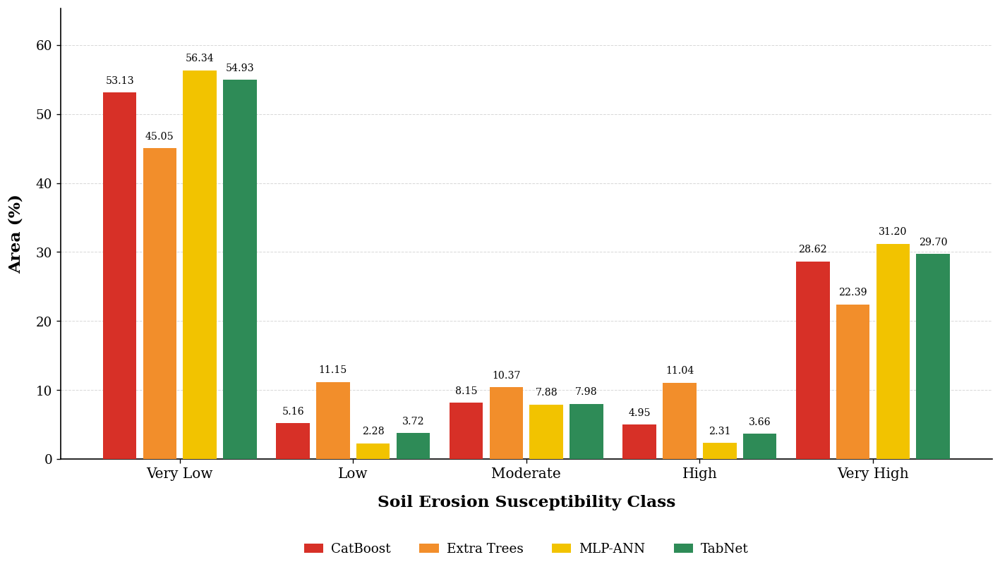


COMPARATIVE ERodIBILITY GRAPH EXPORTED SUCCESSFULLY

Source CSV:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/5Class_Erodibility_Area_Percent_By_Model.csv

Output PNG:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Comparative_Erodibility_Class_Percentage_By_Model.png

Graph settings:
- Values plotted: Percentage only
- Y-axis label: Area (%)
- Model order: CatBoost, Extra Trees, MLP-ANN, TabNet
- Bar borders: None
- Between-class gap: 3 × within-class gap
- Legend: Centered below graph
- Resolution: 300 dpi


In [24]:
# ============================================================
# COMPARATIVE 5-CLASS SOIL ERODIBILITY GROUPED BAR CHART
#
# INPUT CSV:
#   5Class_Erodibility_Area_Percent_By_Model.csv
#
# USES ONLY:
#   Model
#   Erodibility_Class
#   Percentage (%)
#
# IGNORES:
#   Area (km2)
#
# OUTPUT:
#   Comparative_Erodibility_Class_Percentage_By_Model.png
#
# GRAPH DESIGN:
# - X-axis: Erodibility classes
# - Y-axis: Area (%)
# - Four models per class
# - Fixed order:
#     CatBoost
#     Extra Trees
#     MLP-ANN
#     TabNet
# ============================================================


# ------------------------------------------------------------
# 1. Imports
# ------------------------------------------------------------

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 2. Mount Google Drive
# ------------------------------------------------------------

from google.colab import drive

drive.mount(
    "/content/drive",
    force_remount=False
)


# ------------------------------------------------------------
# 3. Exact CSV filename
# ------------------------------------------------------------

CSV_FILENAME = (
    "5Class_Erodibility_Area_Percent_By_Model.csv"
)


# ------------------------------------------------------------
# 4. Define the Drive search root
#
# Priority:
# 1. Existing DRIVE_PROJECT_DIR variable
# 2. Entire MyDrive
# ------------------------------------------------------------

if "DRIVE_PROJECT_DIR" in globals():

    SEARCH_ROOT = Path(
        DRIVE_PROJECT_DIR
    )

else:

    SEARCH_ROOT = Path(
        "/content/drive/MyDrive"
    )


if not SEARCH_ROOT.exists():

    raise FileNotFoundError(

        f"Drive search folder does not exist:\n"
        f"{SEARCH_ROOT}"
    )


print(
    "Searching for CSV inside:"
)

print(
    SEARCH_ROOT
)


# ------------------------------------------------------------
# 5. Find the exact CSV automatically
# ------------------------------------------------------------

csv_matches = list(

    SEARCH_ROOT.rglob(
        CSV_FILENAME
    )
)


if len(
    csv_matches
) == 0:

    raise FileNotFoundError(

        "\nCould not find the required CSV file:\n\n"
        f"{CSV_FILENAME}\n\n"
        f"Search location:\n"
        f"{SEARCH_ROOT}\n\n"
        "Confirm that the file exists in Google Drive."
    )


# If more than one copy exists, use the newest one

csv_matches = sorted(

    csv_matches,

    key=lambda p: p.stat().st_mtime,

    reverse=True
)


csv_path = (
    csv_matches[0]
)


print(
    "\nCSV file found:"
)

print(
    csv_path
)


if len(
    csv_matches
) > 1:

    print(

        "\nMultiple copies were found. "
        "The most recently modified file will be used."
    )


# ------------------------------------------------------------
# 6. Read the CSV
# ------------------------------------------------------------

df = pd.read_csv(
    csv_path
)


# Remove accidental spaces from column names

df.columns = [

    str(col).strip()

    for col in df.columns
]


print(
    "\nColumns found:"
)

print(
    df.columns.tolist()
)


# ------------------------------------------------------------
# 7. Use ONLY the three required fields
#
# Area (km2) is deliberately ignored.
# ------------------------------------------------------------

REQUIRED_COLUMNS = [

    "Model",

    "Erodibility_Class",

    "Percentage (%)"
]


missing_columns = [

    col

    for col in REQUIRED_COLUMNS

    if col not in df.columns
]


if missing_columns:

    raise ValueError(

        f"Required columns are missing:\n"
        f"{missing_columns}\n\n"
        f"Available columns:\n"
        f"{df.columns.tolist()}"
    )


plot_df = (

    df[

        REQUIRED_COLUMNS

    ]

    .copy()
)


print(
    "\nFields used for plotting:"
)

print(
    plot_df.columns.tolist()
)


print(
    "\nArea (km2) is NOT used in this graph."
)


# ------------------------------------------------------------
# 8. Clean text fields
# ------------------------------------------------------------

plot_df[
    "Model"
] = (

    plot_df[
        "Model"
    ]

    .astype(
        str
    )

    .str.strip()
)


plot_df[
    "Erodibility_Class"
] = (

    plot_df[
        "Erodibility_Class"
    ]

    .astype(
        str
    )

    .str.strip()
)


plot_df[
    "Percentage (%)"
] = pd.to_numeric(

    plot_df[
        "Percentage (%)"
    ],

    errors="coerce"
)


if plot_df[
    "Percentage (%)"
].isna().any():

    bad_rows = (

        plot_df[

            plot_df[
                "Percentage (%)"
            ]

            .isna()

        ]
    )


    raise ValueError(

        "Some percentage values could not be converted "
        "to numbers:\n\n"
        f"{bad_rows}"
    )


# ------------------------------------------------------------
# 9. Standardize model names
#
# This allows the code to accept common variations from
# the exported table while plotting the agreed display names.
# ------------------------------------------------------------

MODEL_NAME_MAP = {

    "catboost":
        "CatBoost",

    "extra trees":
        "Extra Trees",

    "extratrees":
        "Extra Trees",

    "extra_trees":
        "Extra Trees",

    "mlp-ann":
        "MLP-ANN",

    "mlp_ann":
        "MLP-ANN",

    "mlp ann":
        "MLP-ANN",

    "tabnet":
        "TabNet"
}


def standardize_model_name(
    name
):

    key = (

        str(
            name
        )

        .strip()

        .lower()
    )


    return MODEL_NAME_MAP.get(
        key,
        str(name).strip()
    )


plot_df[
    "Model"
] = (

    plot_df[
        "Model"
    ]

    .apply(
        standardize_model_name
    )
)


# ------------------------------------------------------------
# 10. Standardize erodibility-class names
# ------------------------------------------------------------

CLASS_NAME_MAP = {

    "very low":
        "Very Low",

    "low":
        "Low",

    "moderate":
        "Moderate",

    "high":
        "High",

    "very high":
        "Very High"
}


def standardize_class_name(
    name
):

    key = (

        str(
            name
        )

        .strip()

        .lower()
    )


    return CLASS_NAME_MAP.get(
        key,
        str(name).strip()
    )


plot_df[
    "Erodibility_Class"
] = (

    plot_df[
        "Erodibility_Class"
    ]

    .apply(
        standardize_class_name
    )
)


# ------------------------------------------------------------
# 11. Fixed plotting order
# ------------------------------------------------------------

CLASS_ORDER = [

    "Very Low",

    "Low",

    "Moderate",

    "High",

    "Very High"
]


MODEL_ORDER = [

    "CatBoost",

    "Extra Trees",

    "MLP-ANN",

    "TabNet"
]


# ------------------------------------------------------------
# 12. Check that all expected models and classes exist
# ------------------------------------------------------------

missing_models = [

    model

    for model in MODEL_ORDER

    if model not in plot_df[
        "Model"
    ].unique()
]


missing_classes = [

    erosion_class

    for erosion_class in CLASS_ORDER

    if erosion_class not in plot_df[
        "Erodibility_Class"
    ].unique()
]


if missing_models:

    raise ValueError(

        f"Missing models in CSV:\n"
        f"{missing_models}"
    )


if missing_classes:

    raise ValueError(

        f"Missing erodibility classes in CSV:\n"
        f"{missing_classes}"
    )


# ------------------------------------------------------------
# 13. Check for duplicate model-class combinations
# ------------------------------------------------------------

duplicate_rows = (

    plot_df

    .duplicated(

        subset=[

            "Model",

            "Erodibility_Class"
        ],

        keep=False
    )
)


if duplicate_rows.any():

    raise ValueError(

        "Duplicate model-class combinations were found:\n\n"

        + plot_df[

            duplicate_rows

        ].to_string(
            index=False
        )
    )


# ------------------------------------------------------------
# 14. Convert to comparison matrix
#
# Rows    = Erodibility classes
# Columns = Models
# Values  = Percentage only
# ------------------------------------------------------------

plot_matrix = (

    plot_df

    .pivot(

        index=
            "Erodibility_Class",

        columns=
            "Model",

        values=
            "Percentage (%)"
    )

    .reindex(

        index=
            CLASS_ORDER,

        columns=
            MODEL_ORDER
    )
)


if plot_matrix.isna().any().any():

    raise ValueError(

        "The final comparison table contains missing values:\n\n"

        + plot_matrix.to_string()
    )


print(
    "\nPercentage data used for the graph:"
)

print(
    plot_matrix
)


# ------------------------------------------------------------
# 15. Optional quality check
#
# Each model should total approximately 100%.
# This does not alter the data.
# ------------------------------------------------------------

percentage_totals = (

    plot_matrix

    .sum(
        axis=0
    )
)


print(
    "\nPercentage total by model:"
)


for model in MODEL_ORDER:

    print(

        f"{model}: "
        f"{percentage_totals[model]:.2f}%"
    )


# ============================================================
# 16. AGREED GRAPH DESIGN
# ============================================================


# ------------------------------------------------------------
# Bar dimensions
# ------------------------------------------------------------

BAR_WIDTH = 0.18


# Small empty space between adjacent model bars
# within the same erodibility class

WITHIN_CLASS_GAP = 0.035


# Gap between one erodibility class and the next
#
# Agreed requirement:
# 2–3 times the within-class gap
#
# Here:
# exactly 3 times the within-class gap

BETWEEN_CLASS_GAP = (

    WITHIN_CLASS_GAP

    * 3
)


print(
    "\nWithin-class gap:",
    WITHIN_CLASS_GAP
)


print(
    "Between-class gap:",
    BETWEEN_CLASS_GAP
)


print(

    "Between-class / within-class ratio:",

    BETWEEN_CLASS_GAP
    /
    WITHIN_CLASS_GAP
)


# ------------------------------------------------------------
# Width of one complete four-model group
# ------------------------------------------------------------

GROUP_WIDTH = (

    (
        len(
            MODEL_ORDER
        )

        * BAR_WIDTH
    )

    +

    (
        (
            len(
                MODEL_ORDER
            )

            - 1
        )

        * WITHIN_CLASS_GAP
    )
)


# ------------------------------------------------------------
# Distance from center of one class to center of next
# ------------------------------------------------------------

GROUP_CENTER_STEP = (

    GROUP_WIDTH

    +

    BETWEEN_CLASS_GAP
)


# ------------------------------------------------------------
# X positions of the five class centers
# ------------------------------------------------------------

class_centers = (

    np.arange(

        len(
            CLASS_ORDER
        )

    )

    * GROUP_CENTER_STEP
)


# ------------------------------------------------------------
# X offsets for the four model bars
#
# These are centered around each class position.
# ------------------------------------------------------------

BAR_STEP = (

    BAR_WIDTH

    +

    WITHIN_CLASS_GAP
)


model_offsets = (

    np.arange(

        len(
            MODEL_ORDER
        )

    )

    * BAR_STEP
)


model_offsets = (

    model_offsets

    -

    np.mean(
        model_offsets
    )
)


# ------------------------------------------------------------
# 17. Agreed model colors
#
# Important:
# - no borders
# - strong golden-yellow clearly different from orange
# ------------------------------------------------------------

MODEL_COLORS = {

    "CatBoost":
        "#D73027",     # Red

    "Extra Trees":
        "#F28E2B",     # Orange

    "MLP-ANN":
        "#F2C300",     # Strong golden-yellow

    "TabNet":
        "#2E8B57"      # Green
}


# ------------------------------------------------------------
# 18. Publication font settings
# ------------------------------------------------------------

plt.rcParams.update(

    {

        "font.family":
            "serif",

        "font.serif":
            [
                "Times New Roman",
                "DejaVu Serif"
            ],

        "font.size":
            12,

        "axes.labelsize":
            14,

        "xtick.labelsize":
            12,

        "ytick.labelsize":
            11,

        "legend.fontsize":
            11
    }
)


# ============================================================
# 19. CREATE THE GROUPED BAR CHART
# ============================================================

fig, ax = plt.subplots(

    figsize=(
        12.5,
        7.2
    ),

    facecolor="white"
)


# Keep the grid behind the bars

ax.set_axisbelow(
    True
)


bar_containers = []


for model_index, model in enumerate(
    MODEL_ORDER
):


    x_positions = (

        class_centers

        +

        model_offsets[
            model_index
        ]
    )


    percentages = (

        plot_matrix[
            model
        ]

        .values
    )


    bars = ax.bar(

        x_positions,

        percentages,

        width=
            BAR_WIDTH,

        color=
            MODEL_COLORS[
                model
            ],

        edgecolor=
            "none",

        linewidth=
            0,

        label=
            model,

        zorder=
            3
    )


    bar_containers.append(
        bars
    )


# ------------------------------------------------------------
# 20. Percentage labels above every bar
# ------------------------------------------------------------

max_percentage = float(

    plot_matrix

    .to_numpy()

    .max()
)


label_offset = (

    max_percentage

    * 0.018
)


for bars in bar_containers:


    for bar in bars:


        height = (
            bar.get_height()
        )


        ax.text(

            bar.get_x()

            +

            bar.get_width() / 2,

            height

            +

            label_offset,

            f"{height:.2f}",

            ha="center",

            va="bottom",

            fontsize=8.5,

            rotation=0,

            color="black"
        )


# ------------------------------------------------------------
# 21. X-axis
# ------------------------------------------------------------

ax.set_xticks(
    class_centers
)


ax.set_xticklabels(

    CLASS_ORDER,

    fontsize=12
)


ax.set_xlabel(

    "Soil Erosion Susceptibility Class",

    fontsize=14,

    fontweight="bold",

    labelpad=12
)


# ------------------------------------------------------------
# 22. Y-axis
#
# Agreed label:
# Area (%)
#
# Values plotted are percentage values only.
# ------------------------------------------------------------

ax.set_ylabel(

    "Area (%)",

    fontsize=14,

    fontweight="bold",

    labelpad=10
)


# ------------------------------------------------------------
# 23. Automatic y-axis limit
#
# Gives enough room for percentage labels.
# ------------------------------------------------------------

y_upper = (

    max_percentage

    * 1.16
)


ax.set_ylim(

    0,

    y_upper
)


# ------------------------------------------------------------
# 24. Light horizontal gridlines only
# ------------------------------------------------------------

ax.grid(

    axis="y",

    linestyle="--",

    linewidth=0.6,

    alpha=0.30,

    color="gray"
)


ax.grid(

    axis="x",

    visible=False
)


# ------------------------------------------------------------
# 25. Clean manuscript-style axes
# ------------------------------------------------------------

ax.spines[
    "top"
].set_visible(
    False
)


ax.spines[
    "right"
].set_visible(
    False
)


ax.spines[
    "left"
].set_linewidth(
    1.0
)


ax.spines[
    "bottom"
].set_linewidth(
    1.0
)


ax.tick_params(

    axis="both",

    direction="out"
)


# ------------------------------------------------------------
# 26. Legend centered below the graph
# ------------------------------------------------------------

ax.legend(

    loc=
        "upper center",

    bbox_to_anchor=
        (
            0.5,
            -0.16
        ),

    ncol=
        4,

    frameon=
        False,

    columnspacing=
        2.2,

    handlelength=
        1.5,

    handletextpad=
        0.6
)


# ------------------------------------------------------------
# 27. No figure title
# ------------------------------------------------------------

# Intentionally no title.


# ------------------------------------------------------------
# 28. Final layout
# ------------------------------------------------------------

fig.subplots_adjust(

    left=
        0.10,

    right=
        0.98,

    top=
        0.97,

    bottom=
        0.23
)


# ============================================================
# 29. OUTPUT PNG
#
# Save in the same folder as the source CSV.
# ============================================================

output_png = (

    csv_path.parent

    /

    "Comparative_Erodibility_Class_Percentage_By_Model.png"
)


fig.savefig(

    output_png,

    dpi=
        300,

    bbox_inches=
        "tight",

    facecolor=
        "white"
)


# ------------------------------------------------------------
# 30. Display
# ------------------------------------------------------------

plt.show()


plt.close(
    fig
)


# ------------------------------------------------------------
# 31. Final confirmation
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 75
)


print(
    "COMPARATIVE ERodIBILITY GRAPH EXPORTED SUCCESSFULLY"
)


print(
    "=" * 75
)


print(
    "\nSource CSV:"
)


print(
    csv_path
)


print(
    "\nOutput PNG:"
)


print(
    output_png
)


print(
    "\nGraph settings:"
)


print(
    "- Values plotted: Percentage only"
)


print(
    "- Y-axis label: Area (%)"
)


print(
    "- Model order: CatBoost, Extra Trees, MLP-ANN, TabNet"
)


print(
    "- Bar borders: None"
)


print(
    "- Between-class gap: 3 × within-class gap"
)


print(
    "- Legend: Centered below graph"
)


print(
    "- Resolution: 300 dpi"
)

# MANDakini 23SW COMPARATIVE ERodibility-Class PERCENTAGE PLOT
# 23 Subwatersheds (SW01–SW23) × 5 Classes × 4 Models

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CSV loaded successfully.
Shape: (92, 12)

Columns:
['Model', 'SWID', 'Very_Low (km2)', 'Very_Low (%)', 'Low_Area (km2)', 'Low (%)', 'Moderate (km2)', 'Moderate (%)', 'High (km2)', 'High (%)', 'Very_High (km2)', 'Very_High (%)']

VALIDATION PASSED SUCCESSFULLY
✓ 23 subwatersheds confirmed
✓ 4 models confirmed
✓ 92 Model-SW combinations confirmed
✓ No duplicates
✓ All values are numeric
✓ Every Model-SW row sums to 100%

FIGURE SIZE
Width: 300 mm = 11.8110 inches
Height: 210 mm = 8.2677 inches


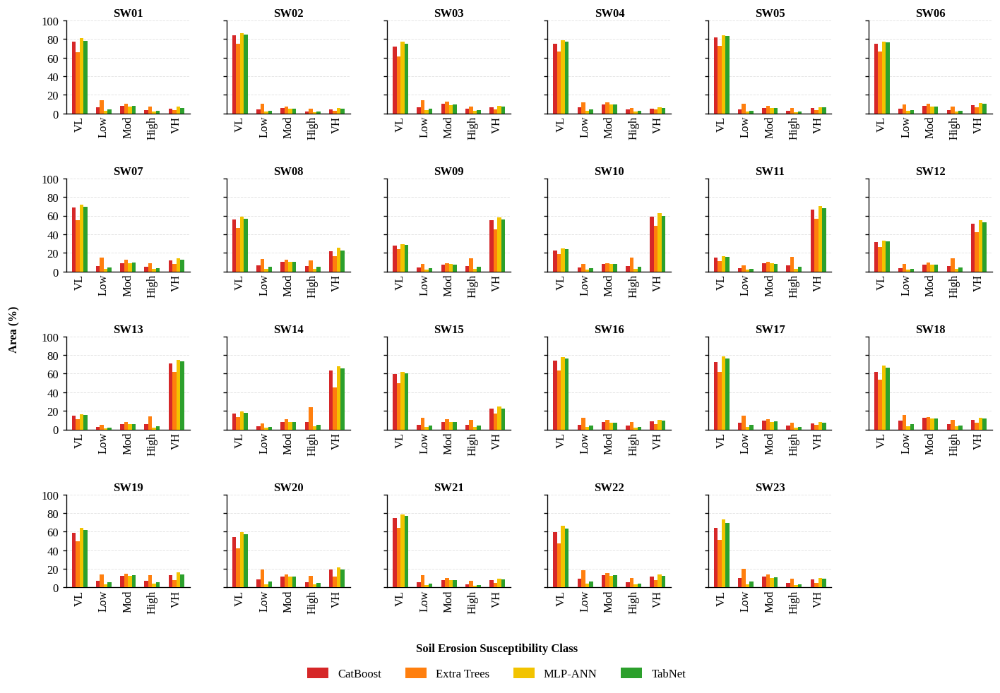


Figure saved successfully:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Mandakini_Plots/Mandakini_23SW_5Class_Model_Percentage_Comparison_300mm_x_210mm_Font10.png

OUTPUT CHECK
Pixel size: 7086 × 4960
Physical dimensions: 300 mm × 210 mm
Orientation: Landscape
Resolution: 600 dpi
Expected pixel size at 600 dpi: approximately 7087 × 4961 pixels


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
# ================================================================
# MANDAKINI 23SW COMPARATIVE PLOT
# 23 Subwatersheds × 5 Erodibility Classes × 4 Models
#
# CUSTOM LANDSCAPE SIZE:
# Width  = 300 mm
# Height = 210 mm
#
# ALL FONT SIZES = 10 pt
#
# Reads CSV directly from Google Drive
# Saves final PNG to Google Drive
# Downloads final PNG automatically
#
# Percentage labels on bars are NOT included
# ================================================================


# ================================================================
# 1. IMPORT LIBRARIES
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch
from google.colab import drive, files
from PIL import Image


# ================================================================
# 2. MOUNT GOOGLE DRIVE
# ================================================================

drive.mount("/content/drive")


# ================================================================
# 3. INPUT AND OUTPUT PATHS
# ================================================================

# Input CSV
csv_path = (
    "/content/drive/MyDrive/"
    "Mandakini_23SW_Model_Inputs/"
    "All_Models_SW_5Class_Pixel_Area_Percent_Table.csv"
)


# Output folder
output_folder = (
    "/content/drive/MyDrive/"
    "Mandakini_23SW_Model_Inputs/"
    "Mandakini_Plots"
)


# Create output folder if it does not already exist
os.makedirs(
    output_folder,
    exist_ok=True
)


# Final PNG filename
output_png = os.path.join(
    output_folder,
    "Mandakini_23SW_5Class_Model_Percentage_"
    "Comparison_300mm_x_210mm_Font10.png"
)


# ================================================================
# 4. READ THE CSV
# ================================================================

df = pd.read_csv(
    csv_path
)


print(
    "CSV loaded successfully."
)

print(
    f"Shape: {df.shape}"
)

print(
    "\nColumns:"
)

print(
    df.columns.tolist()
)


# ================================================================
# 5. FIXED MODEL ORDER
# ================================================================

model_order = [
    "CatBoost",
    "ExtraTrees",
    "MLP_ANN",
    "TabNet"
]


# ================================================================
# 6. MODEL DISPLAY NAMES
# ================================================================

model_labels = {
    "CatBoost": "CatBoost",
    "ExtraTrees": "Extra Trees",
    "MLP_ANN": "MLP-ANN",
    "TabNet": "TabNet"
}


# ================================================================
# 7. FIVE ERODIBILITY CLASSES
# ================================================================

class_columns = [
    "Very_Low (%)",
    "Low (%)",
    "Moderate (%)",
    "High (%)",
    "Very_High (%)"
]


class_labels = [
    "VL",
    "Low",
    "Mod",
    "High",
    "VH"
]


# ================================================================
# 8. FIXED SUBWATERSHED ORDER
# ================================================================

sw_order = [
    f"SW{i:02d}"
    for i in range(1, 24)
]


# ================================================================
# 9. APPROVED MODEL COLORS
# ================================================================

model_colors = {
    "CatBoost": "#D62728",     # red
    "ExtraTrees": "#FF7F0E",   # orange
    "MLP_ANN": "#F2C300",      # strong golden-yellow
    "TabNet": "#2CA02C"        # green
}


# ================================================================
# 10. CHECK REQUIRED COLUMNS
# ================================================================

required_columns = [
    "Model",
    "SWID"
] + class_columns


missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]


if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ================================================================
# 11. KEEP ONLY REQUIRED COLUMNS
# ================================================================

df = df[
    required_columns
].copy()


# ================================================================
# 12. CONVERT PERCENTAGE COLUMNS TO NUMERIC
# ================================================================

for column in class_columns:

    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )


# ================================================================
# 13. CHECK FOR MISSING OR NON-NUMERIC VALUES
# ================================================================

if df[
    class_columns
].isna().any().any():

    raise ValueError(
        "Some percentage values are missing or non-numeric."
    )


# ================================================================
# 14. CHECK FOR DUPLICATE MODEL-SW COMBINATIONS
# ================================================================

duplicates = df.duplicated(
    [
        "Model",
        "SWID"
    ]
)


if duplicates.any():

    print(
        df.loc[
            duplicates,
            [
                "Model",
                "SWID"
            ]
        ]
    )

    raise ValueError(
        "Duplicate Model-SWID rows found."
    )


# ================================================================
# 15. CHECK THAT ALL FOUR MODELS EXIST
# ================================================================

missing_models = (
    set(model_order)
    - set(df["Model"].unique())
)


if missing_models:

    raise ValueError(
        f"Missing models: {missing_models}"
    )


# ================================================================
# 16. CHECK THAT SW01-SW23 EXIST
# ================================================================

missing_sws = (
    set(sw_order)
    - set(df["SWID"].unique())
)


if missing_sws:

    raise ValueError(
        f"Missing SWIDs: {missing_sws}"
    )


# ================================================================
# 17. CHECK EXPECTED NUMBER OF ROWS
# ================================================================

expected_rows = (
    len(model_order)
    * len(sw_order)
)


if len(df) != expected_rows:

    raise ValueError(
        f"Expected {expected_rows} rows, "
        f"but found {len(df)} rows."
    )


# ================================================================
# 18. CHECK THAT EACH MODEL-SW ROW SUMS TO 100%
# ================================================================

row_totals = df[
    class_columns
].sum(axis=1)


valid_totals = np.isclose(
    row_totals,
    100.0,
    atol=1e-3
)


if not valid_totals.all():

    bad_rows = df.loc[
        ~valid_totals,
        [
            "Model",
            "SWID"
        ] + class_columns
    ].copy()


    bad_rows[
        "Total (%)"
    ] = bad_rows[
        class_columns
    ].sum(axis=1)


    print(
        "\nRows that do not sum to 100%:"
    )


    print(
        bad_rows.to_string(
            index=False
        )
    )


    raise ValueError(
        "Some rows do not sum to 100%."
    )


# ================================================================
# 19. PRINT VALIDATION SUMMARY
# ================================================================

print(
    "\nVALIDATION PASSED SUCCESSFULLY"
)

print(
    "✓ 23 subwatersheds confirmed"
)

print(
    "✓ 4 models confirmed"
)

print(
    "✓ 92 Model-SW combinations confirmed"
)

print(
    "✓ No duplicates"
)

print(
    "✓ All values are numeric"
)

print(
    "✓ Every Model-SW row sums to 100%"
)


# ================================================================
# 20. SET ONE FONT SIZE FOR THE ENTIRE FIGURE
# ================================================================

FONT_SIZE = 10


plt.rcParams.update({

    "font.family": "serif",

    "font.serif": [
        "Times New Roman",
        "Liberation Serif",
        "DejaVu Serif"
    ],

    "font.size": FONT_SIZE,

    "axes.titlesize": FONT_SIZE,

    "axes.labelsize": FONT_SIZE,

    "xtick.labelsize": FONT_SIZE,

    "ytick.labelsize": FONT_SIZE,

    "legend.fontsize": FONT_SIZE,

    "axes.unicode_minus": False

})


# ================================================================
# 21. SET EXACT FIGURE SIZE
# ================================================================

# Requested dimensions:
# Width  = 300 mm
# Height = 210 mm
#
# Matplotlib figsize requires inches.
# 1 inch = 25.4 mm

figure_width_mm = 300
figure_height_mm = 210


figure_width_inches = (
    figure_width_mm
    / 25.4
)


figure_height_inches = (
    figure_height_mm
    / 25.4
)


print(
    "\nFIGURE SIZE"
)

print(
    f"Width: {figure_width_mm} mm "
    f"= {figure_width_inches:.4f} inches"
)

print(
    f"Height: {figure_height_mm} mm "
    f"= {figure_height_inches:.4f} inches"
)


# ================================================================
# 22. CREATE THE 23-PANEL FIGURE
# ================================================================

# 4 rows × 6 columns = 24 panel positions
#
# SW01-SW23 use 23 positions
# The final unused position is hidden

fig, axes = plt.subplots(

    nrows=4,

    ncols=6,

    figsize=(
        figure_width_inches,
        figure_height_inches
    ),

    sharey=True

)


axes = axes.flatten()


# ================================================================
# 23. BAR-POSITION SETTINGS
# ================================================================

# Five class positions
#
# The spacing between one class group and the next
# is larger than the spacing between model bars.

class_x = (
    np.arange(
        len(class_labels)
    )
    * 1.25
)


# Width of each model bar
bar_width = 0.20


# Four compact model positions within each class
offsets = (

    np.array(
        [
            -1.5,
            -0.5,
             0.5,
             1.5
        ]
    )

    * bar_width

)


# ================================================================
# 24. PLOT SW01-SW23
# ================================================================

for i, swid in enumerate(sw_order):


    # Current subplot
    ax = axes[i]


    # ------------------------------------------------------------
    # EXTRACT CURRENT SUBWATERSHED DATA
    # ------------------------------------------------------------

    sw_data = (

        df[
            df["SWID"] == swid
        ]

        .set_index(
            "Model"
        )

    )


    # ------------------------------------------------------------
    # PLOT THE FOUR MODELS
    # ------------------------------------------------------------

    for j, model in enumerate(model_order):


        values = (

            sw_data

            .loc[
                model,
                class_columns
            ]

            .to_numpy(
                dtype=float
            )

        )


        ax.bar(

            class_x
            + offsets[j],

            values,

            width=bar_width,

            color=model_colors[
                model
            ],

            edgecolor="none",

            linewidth=0,

            zorder=3

        )


    # ------------------------------------------------------------
    # SUBWATERSHED TITLE
    # FONT SIZE = 10
    # ------------------------------------------------------------

    ax.set_title(

        swid,

        fontsize=FONT_SIZE,

        fontweight="bold",

        pad=3.5

    )


    # ------------------------------------------------------------
    # X-AXIS TICK LOCATIONS
    # ------------------------------------------------------------

    ax.set_xticks(
        class_x
    )


    # ------------------------------------------------------------
    # X-AXIS CLASS LABELS
    # FONT SIZE = 10
    # ------------------------------------------------------------

    ax.set_xticklabels(

        class_labels,

        rotation=90,

        ha="center",

        va="top",

        fontsize=FONT_SIZE

    )


    # ------------------------------------------------------------
    # Y-AXIS RANGE
    # ------------------------------------------------------------

    ax.set_ylim(
        0,
        100
    )


    # ------------------------------------------------------------
    # Y-AXIS TICK VALUES
    # ------------------------------------------------------------

    ax.set_yticks(

        np.arange(
            0,
            101,
            20
        )

    )


    # ------------------------------------------------------------
    # Y-AXIS TICK FONT SIZE = 10
    # ------------------------------------------------------------

    ax.tick_params(

        axis="y",

        labelsize=FONT_SIZE,

        length=3,

        width=0.8

    )


    # ------------------------------------------------------------
    # X-AXIS TICK FONT SIZE = 10
    # ------------------------------------------------------------

    ax.tick_params(

        axis="x",

        labelsize=FONT_SIZE,

        length=0,

        pad=2

    )


    # ------------------------------------------------------------
    # HORIZONTAL GRIDLINES
    # ------------------------------------------------------------

    ax.grid(

        axis="y",

        linestyle="--",

        linewidth=0.55,

        alpha=0.35,

        zorder=0

    )


    # ------------------------------------------------------------
    # REMOVE TOP AND RIGHT SPINES
    # ------------------------------------------------------------

    ax.spines[
        "top"
    ].set_visible(
        False
    )


    ax.spines[
        "right"
    ].set_visible(
        False
    )


    # ------------------------------------------------------------
    # LEFT AND BOTTOM SPINES
    # ------------------------------------------------------------

    ax.spines[
        "left"
    ].set_linewidth(
        0.8
    )


    ax.spines[
        "bottom"
    ].set_linewidth(
        0.8
    )


# ================================================================
# 25. HIDE THE UNUSED 24TH PANEL
# ================================================================

for k in range(
    len(sw_order),
    len(axes)
):

    axes[k].axis(
        "off"
    )


# ================================================================
# 26. SHARED Y-AXIS LABEL
# FONT SIZE = 10
# ================================================================

fig.text(

    0.018,

    0.535,

    "Area (%)",

    rotation=90,

    va="center",

    ha="center",

    fontsize=FONT_SIZE,

    fontweight="bold"

)


# ================================================================
# 27. SHARED X-AXIS LABEL
# FONT SIZE = 10
# ================================================================

fig.text(

    0.5,

    0.078,

    "Soil Erosion Susceptibility Class",

    va="center",

    ha="center",

    fontsize=FONT_SIZE,

    fontweight="bold"

)


# ================================================================
# 28. CREATE THE LEGEND
# ================================================================

legend_handles = [

    Patch(

        facecolor=model_colors[
            model
        ],

        edgecolor="none",

        label=model_labels[
            model
        ]

    )

    for model in model_order

]


# ================================================================
# 29. ADD THE LEGEND
# FONT SIZE = 10
# ================================================================

fig.legend(

    handles=legend_handles,

    loc="lower center",

    bbox_to_anchor=(
        0.5,
        0.018
    ),

    ncol=4,

    frameon=False,

    fontsize=FONT_SIZE,

    handlelength=1.8,

    handleheight=1.0,

    columnspacing=2.0

)


# ================================================================
# 30. FINAL LAYOUT ADJUSTMENT
# ================================================================

plt.subplots_adjust(

    left=0.070,

    right=0.995,

    top=0.975,

    bottom=0.165,

    wspace=0.30,

    hspace=0.70

)


# ================================================================
# 31. SAVE THE FINAL FIGURE
# ================================================================

fig.savefig(

    output_png,

    dpi=600,

    facecolor="white",

    bbox_inches=None,

    pad_inches=0

)


# ================================================================
# 32. DISPLAY THE FINAL FIGURE
# ================================================================

plt.show()


# Close figure after display
plt.close(
    fig
)


# ================================================================
# 33. PRINT OUTPUT LOCATION
# ================================================================

print(
    "\nFigure saved successfully:"
)

print(
    output_png
)


# ================================================================
# 34. VERIFY OUTPUT DIMENSIONS
# ================================================================

with Image.open(
    output_png
) as img:


    print(
        "\nOUTPUT CHECK"
    )


    print(
        f"Pixel size: "
        f"{img.size[0]} × "
        f"{img.size[1]}"
    )


    print(
        "Physical dimensions: "
        "300 mm × 210 mm"
    )


    print(
        "Orientation: Landscape"
    )


    print(
        "Resolution: 600 dpi"
    )


    print(
        "Expected pixel size at 600 dpi: "
        "approximately 7087 × 4961 pixels"
    )


# ================================================================
# 35. DOWNLOAD THE FINAL PNG
# ================================================================

files.download(
    output_png
)

MANDAKINI RIVER BASIN — TABNET SHAP-IQ (FSII)

Installing missing package: shapiq
shapiq version: 1.6.0

SHAP-IQ settings
  Model: TabNet
  Index: FSII
  Maximum order: 3
  Effects evaluated: 175
  Top effects plotted: 15
  Test explanations: 1000

Original run directory:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744

SHAP-IQ output directory:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet_SHAP_IQ_FSII_Order3

Original split verified:
  Train: 14490
  Validation: 3105
  Test: 3105

Test target distribution:
Target
0    1035
1    1035
2    1035
Name: count, dtype: int64

TabNet successfully resolved.
Source: final_models["TabNet"] from notebook memory

TabNet susceptibility-score check:
  Min: 2.6049521872906212e-08
  Max: 0.9999211626345641
  Mean: 0.5086744217197567

SHAP-IQ TEST-ONLY sample:
  Available test points: 3105
  Selected test points: 1000

Stratified sample distribution:
Tar

TabNet FSII order 1–3: 0it [00:00, ?it/s]


All 1,000 TabNet SHAP-IQ explanations completed.


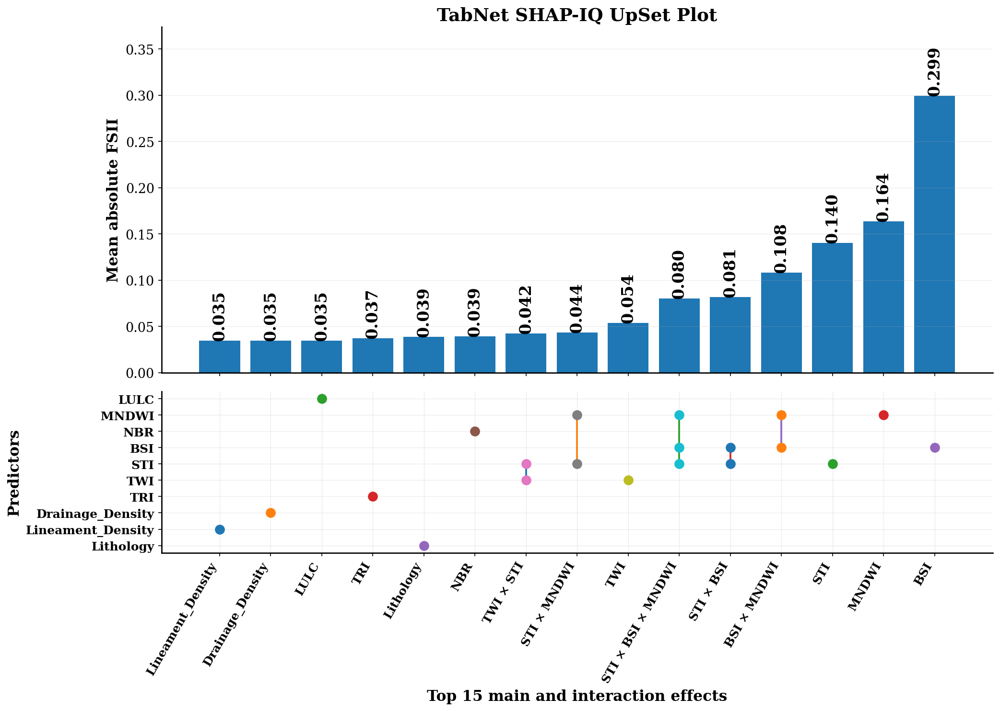


TABNET SHAP-IQ FSII ORDER-3 ANALYSIS COMPLETED SUCCESSFULLY

Core settings:
  Model: TabNet
  Fitted model source: final_models["TabNet"] from notebook memory
  Full test set: 3105
  Explained test sample: 1000
  Index: FSII
  Maximum interaction order: 3
  Effects evaluated: 175
  Top effects displayed: 15
  Susceptibility score: P(Target 2) + 0.5 * P(Target 1)

Effects by order:
  Order 1: 10
  Order 2: 45
  Order 3: 120

Top 15 global FSII effects:


,Global_Rank,Effect_Type,Feature_Set,Order,Mean_Absolute_FSII,Mean_Signed_FSII,Positive_Fraction,Negative_Fraction
0,1,Main effect,BSI,1,0.299266,-0.026386,0.485,0.515
1,2,Main effect,MNDWI,1,0.163814,-0.021075,0.426,0.574
2,3,Main effect,STI,1,0.140207,-0.013726,0.534,0.466
3,4,Pairwise interaction,BSI × MNDWI,2,0.108143,0.045072,0.649,0.351
4,5,Pairwise interaction,STI × BSI,2,0.081488,-0.003181,0.451,0.549
5,6,Third-order interaction,STI × BSI × MNDWI,3,0.080126,0.009583,0.566,0.434
6,7,Main effect,TWI,1,0.053732,-0.021554,0.404,0.596
7,8,Pairwise interaction,STI × MNDWI,2,0.043571,-0.005152,0.413,0.587
8,9,Pairwise interaction,TWI × STI,2,0.042184,0.037163,0.827,0.173
9,10,Main effect,NBR,1,0.039440,0.007916,0.564,0.436



BSI × MNDWI × STI three-way interaction:


,Global_Rank,Feature_Set,Mean_Absolute_FSII,Mean_Signed_FSII,Positive_Fraction,Negative_Fraction
5,6,STI × BSI × MNDWI,0.080126,0.009583,0.566,0.434



Publication figure files:
  /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet_SHAP_IQ_FSII_Order3/01_Publication_Figure/TabNet_SHAP_IQ_FSII_Order3_Top15_UpSet_Plot.png
  /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet_SHAP_IQ_FSII_Order3/01_Publication_Figure/TabNet_SHAP_IQ_FSII_Order3_Top15_UpSet_Plot.pdf
  /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet_SHAP_IQ_FSII_Order3/01_Publication_Figure/TabNet_SHAP_IQ_FSII_Order3_Top15_UpSet_Plot.svg

Output root:
/content/drive/MyDrive/Mandakini_23SW_Model_Inputs/Colab_Outputs/RUN_UPDATED_10PREDICTORS_20260703_130744/model_explainability/TabNet_SHAP_IQ_FSII_Order3


In [26]:
# ============================================================
# MANDAKINI RIVER BASIN — TABNET SHAP-IQ (FSII) ANALYSIS
#

# ============================================================
# 1. IMPORTS AND PACKAGE READINESS
# ============================================================

import os
import sys
import json
import math
import hashlib
import warnings
import subprocess
import importlib
from pathlib import Path
from itertools import combinations
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedShuffleSplit

warnings.filterwarnings("ignore")


def ensure_package(import_name, pip_name=None):
    pip_name = pip_name or import_name

    try:
        return importlib.import_module(import_name)

    except ModuleNotFoundError:

        print(
            f"Installing missing package: {pip_name}"
        )

        subprocess.check_call(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                pip_name
            ]
        )

        return importlib.import_module(
            import_name
        )


shapiq = ensure_package(
    "shapiq",
    "shapiq"
)

joblib = ensure_package(
    "joblib",
    "joblib"
)

ensure_package(
    "pytorch_tabnet",
    "pytorch-tabnet"
)

from pytorch_tabnet.tab_model import TabNetClassifier
from tqdm.auto import tqdm


print(
    "shapiq version:",
    getattr(
        shapiq,
        "__version__",
        "unknown"
    )
)


# ============================================================
# 2. GOOGLE DRIVE CHECK
# ============================================================

try:

    from google.colab import drive

    if not os.path.exists(
        "/content/drive/MyDrive"
    ):

        drive.mount(
            "/content/drive"
        )

except Exception as e:

    print(
        "Google Drive mount check:",
        e
    )


# ============================================================
# 3. AGREED SHAP-IQ SETTINGS
# ============================================================

SHAP_IQ_MODEL_NAME = "TabNet"

SHAP_IQ_INDEX = "FSII"

SHAP_IQ_MAX_ORDER = 3

SHAP_IQ_N_INTERACTIONS = 15

SHAP_IQ_SOURCE_DATA = "TEST_SET_ONLY"

SHAP_IQ_SAMPLE_SIZE = 1000

SHAP_IQ_RANDOM_STATE = 42

# Training-only background for the marginal imputer
SHAP_IQ_BACKGROUND_SIZE = 300

# Number of training-background replacement rows used by
# the marginal imputer for each coalition evaluation.
SHAP_IQ_IMPUTER_SAMPLE_SIZE = 32

# FSII approximation budget per explained test observation.
SHAP_IQ_BUDGET = 256

# Preserve empirical joint background rows when imputing
# missing predictors.
SHAP_IQ_JOINT_MARGINAL = True

# Long-run protection
SHAP_IQ_CHECKPOINT_EVERY = 25
SHAP_IQ_RESUME = True


# ------------------------------------------------------------
# Publication-quality figure settings
# Preserved from the previous SMC SHAP-IQ design
# ------------------------------------------------------------

SHAP_IQ_FIGSIZE = (
    14,
    10
)

SHAP_IQ_DPI = 600

SHAP_IQ_BAR_LABEL_FONT_SIZE = 16

SHAP_IQ_FEATURE_FONT_SIZE = 12

SHAP_IQ_TITLE_FONT_SIZE = 18

SHAP_IQ_AXIS_LABEL_FONT_SIZE = 15

SHAP_IQ_TICK_FONT_SIZE = 13

SHAP_IQ_SAVE_FORMATS = [
    "png",
    "pdf",
    "svg"
]

SHAP_IQ_BAR_YLIM_PADDING_FACTOR = 1.25

SHAP_IQ_FONT_FAMILY = "DejaVu Serif"

SHAP_IQ_GRID_ALPHA = 0.25

SHAP_IQ_GRID_LINEWIDTH = 0.6

SHAP_IQ_AXIS_LINEWIDTH = 1.3


plt.rcParams[
    "font.family"
] = SHAP_IQ_FONT_FAMILY

plt.rcParams[
    "font.serif"
] = [
    SHAP_IQ_FONT_FAMILY,
    "DejaVu Serif"
]

plt.rcParams[
    "axes.linewidth"
] = SHAP_IQ_AXIS_LINEWIDTH

plt.rcParams[
    "savefig.dpi"
] = SHAP_IQ_DPI

plt.rcParams[
    "figure.dpi"
] = 150

plt.rcParams[
    "axes.unicode_minus"
] = False


# ============================================================
# 4. EXACT ORIGINAL MANDAKINI PREDICTORS
# ============================================================

FEATURES_SHAP_IQ = [
    "Lithology",
    "Lineament_Density",
    "Drainage_Density",
    "TRI",
    "TWI",
    "STI",
    "BSI",
    "NBR",
    "MNDWI",
    "LULC"
]


CATEGORICAL_FEATURES_SHAP_IQ = [
    "Lithology",
    "LULC"
]


NUMERIC_FEATURES_SHAP_IQ = [
    "Lineament_Density",
    "Drainage_Density",
    "TRI",
    "TWI",
    "STI",
    "BSI",
    "NBR",
    "MNDWI"
]


CLASS_ORDER_SHAP_IQ = [
    0,
    1,
    2
]


N_FEATURES_SHAP_IQ = len(
    FEATURES_SHAP_IQ
)


CATEGORICAL_FEATURE_INDICES = [
    FEATURES_SHAP_IQ.index(
        feature
    )
    for feature in CATEGORICAL_FEATURES_SHAP_IQ
]


EXPECTED_TOTAL_INVENTORY = 20700
EXPECTED_TRAIN_ROWS = 14490
EXPECTED_VALIDATION_ROWS = 3105
EXPECTED_TEST_ROWS = 3105


EXPECTED_EFFECTS = sum(
    math.comb(
        N_FEATURES_SHAP_IQ,
        order
    )
    for order in range(
        1,
        SHAP_IQ_MAX_ORDER + 1
    )
)


print(
    "\nSHAP-IQ settings"
)

print(
    "  Model:",
    SHAP_IQ_MODEL_NAME
)

print(
    "  Index:",
    SHAP_IQ_INDEX
)

print(
    "  Maximum order:",
    SHAP_IQ_MAX_ORDER
)

print(
    "  Effects evaluated:",
    EXPECTED_EFFECTS
)

print(
    "  Top effects plotted:",
    SHAP_IQ_N_INTERACTIONS
)

print(
    "  Test explanations:",
    SHAP_IQ_SAMPLE_SIZE
)


# ============================================================
# 5. RESTORE ORIGINAL PROJECT/RUN PATHS
# ============================================================

if "DRIVE_PROJECT_DIR" in globals():

    DRIVE_PROJECT_DIR_SHAP_IQ = Path(
        DRIVE_PROJECT_DIR
    )

else:

    DRIVE_PROJECT_DIR_SHAP_IQ = Path(
        "/content/drive/MyDrive/"
        "Mandakini_23SW_Model_Inputs"
    )


RUN_ID_FILE_SHAP_IQ = (
    DRIVE_PROJECT_DIR_SHAP_IQ
    /
    "run_id_updated_10predictors.txt"
)


if "RUN_DIR" in globals():

    RUN_DIR_SHAP_IQ = Path(
        RUN_DIR
    )

else:

    if not RUN_ID_FILE_SHAP_IQ.exists():

        raise FileNotFoundError(
            "The original run ID file was not found:\n"
            f"{RUN_ID_FILE_SHAP_IQ}\n\n"
            "Run the original Mandakini setup cells first."
        )

    RUN_NAME_SHAP_IQ = (
        RUN_ID_FILE_SHAP_IQ
        .read_text()
        .strip()
    )

    RUN_DIR_SHAP_IQ = (
        DRIVE_PROJECT_DIR_SHAP_IQ
        /
        "Colab_Outputs"
        /
        RUN_NAME_SHAP_IQ
    )


MODEL_DIR_SHAP_IQ = (
    Path(MODEL_DIR)
    if "MODEL_DIR" in globals()
    else RUN_DIR_SHAP_IQ / "models"
)


CHECKPOINT_DIR_SHAP_IQ = (
    Path(CHECKPOINT_DIR)
    if "CHECKPOINT_DIR" in globals()
    else RUN_DIR_SHAP_IQ / "checkpoints"
)


EXPLAIN_DIR_SHAP_IQ = (
    Path(EXPLAIN_DIR)
    if "EXPLAIN_DIR" in globals()
    else RUN_DIR_SHAP_IQ / "model_explainability"
)


SHAP_IQ_ROOT_DIR = (
    EXPLAIN_DIR_SHAP_IQ
    /
    "TabNet_SHAP_IQ_FSII_Order3"
)


SHAP_IQ_DIRS = {

    "root":
        SHAP_IQ_ROOT_DIR,

    "figure":
        SHAP_IQ_ROOT_DIR
        /
        "01_Publication_Figure",

    "tables":
        SHAP_IQ_ROOT_DIR
        /
        "02_Tables",

    "samples":
        SHAP_IQ_ROOT_DIR
        /
        "03_Samples",

    "metadata":
        SHAP_IQ_ROOT_DIR
        /
        "04_Metadata",

    "checkpoint":
        SHAP_IQ_ROOT_DIR
        /
        "05_Checkpoint"
}


for folder in SHAP_IQ_DIRS.values():

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


CHECKPOINT_NPZ = (
    SHAP_IQ_DIRS[
        "checkpoint"
    ]
    /
    "TabNet_SHAP_IQ_Order3_Progress.npz"
)


CHECKPOINT_JSON = (
    SHAP_IQ_DIRS[
        "checkpoint"
    ]
    /
    "TabNet_SHAP_IQ_Order3_Progress_Metadata.json"
)


print(
    "\nOriginal run directory:"
)

print(
    RUN_DIR_SHAP_IQ
)


print(
    "\nSHAP-IQ output directory:"
)

print(
    SHAP_IQ_ROOT_DIR
)


# ============================================================
# 6. RESTORE ORIGINAL TRAIN/VALIDATION/TEST DATA IF NEEDED
# ============================================================

def load_original_split_from_saved_files():
    """
    Reconstruct the ORIGINAL saved 70/15/15 split without making
    a new split.

    This function uses:
    1. the corrected 20,700-point modelling table
    2. the original saved Train_Validation_Test_Indices.json

    Therefore the exact same train/validation/test observations
    used in the manuscript are restored.
    """

    corrected_csv_candidates = [

        DRIVE_PROJECT_DIR_SHAP_IQ
        /
        "Mandakini_20700_TargetSamples_10Predictors_LithologyCorrected.csv",

        RUN_DIR_SHAP_IQ
        /
        "tables"
        /
        "TargetSamples_10Predictors_LithologyCorrected.csv",

        RUN_DIR_SHAP_IQ
        /
        "tables"
        /
        "Clean_TargetSamples_10Predictors_StrictNames.csv"
    ]


    corrected_csv = None


    for candidate in corrected_csv_candidates:

        if candidate.exists():

            corrected_csv = candidate
            break


    if corrected_csv is None:

        raise FileNotFoundError(
            "Could not locate the original corrected 20,700-point "
            "Mandakini modelling table.\n"
            "Checked:\n"
            + "\n".join(
                str(p)
                for p in corrected_csv_candidates
            )
        )


    split_path = (
        CHECKPOINT_DIR_SHAP_IQ
        /
        "Train_Validation_Test_Indices.json"
    )


    if not split_path.exists():

        raise FileNotFoundError(
            "Original split-index file not found:\n"
            f"{split_path}\n\n"
            "A new split will NOT be created because SHAP-IQ must use "
            "the exact original test observations."
        )


    print(
        "\nReloading original modelling table:"
    )

    print(
        corrected_csv
    )


    data_df = pd.read_csv(
        corrected_csv
    )


    missing_features = [
        c
        for c in FEATURES_SHAP_IQ
        if c not in data_df.columns
    ]


    if missing_features:

        raise ValueError(
            "The saved modelling table is missing predictors:\n"
            f"{missing_features}"
        )


    if "Target" not in data_df.columns:

        raise ValueError(
            "The saved modelling table does not contain the Target column."
        )


    if len(
        data_df
    ) != EXPECTED_TOTAL_INVENTORY:

        raise ValueError(
            "Expected the original 20,700-point inventory, "
            f"but found {len(data_df)} rows."
        )


    X_all = data_df[
        FEATURES_SHAP_IQ
    ].copy()


    y_all = (
        pd.to_numeric(
            data_df[
                "Target"
            ],
            errors="raise"
        )
        .astype(int)
    )


    split_info = json.loads(
        split_path.read_text()
    )


    train_idx = np.asarray(
        split_info[
            "train_idx"
        ],
        dtype=int
    )


    val_idx = np.asarray(
        split_info[
            "val_idx"
        ],
        dtype=int
    )


    test_idx = np.asarray(
        split_info[
            "test_idx"
        ],
        dtype=int
    )


    return (
        X_all.iloc[
            train_idx
        ].copy(),

        y_all.iloc[
            train_idx
        ].copy(),

        X_all.iloc[
            val_idx
        ].copy(),

        y_all.iloc[
            val_idx
        ].copy(),

        X_all.iloc[
            test_idx
        ].copy(),

        y_all.iloc[
            test_idx
        ].copy(),

        corrected_csv,

        split_path
    )


# ------------------------------------------------------------
# Use in-memory original split if it is available.
# Otherwise restore the exact split from Drive.
# ------------------------------------------------------------

required_split_objects = [
    "X_train",
    "y_train",
    "X_val",
    "y_val",
    "X_test",
    "y_test"
]


if all(
    name in globals()
    for name in required_split_objects
):

    X_TRAIN_SHAP_IQ = (
        X_train[
            FEATURES_SHAP_IQ
        ]
        .copy()
    )

    Y_TRAIN_SHAP_IQ = (
        pd.to_numeric(
            y_train,
            errors="raise"
        )
        .astype(int)
        .copy()
    )

    X_VAL_SHAP_IQ = (
        X_val[
            FEATURES_SHAP_IQ
        ]
        .copy()
    )

    Y_VAL_SHAP_IQ = (
        pd.to_numeric(
            y_val,
            errors="raise"
        )
        .astype(int)
        .copy()
    )

    X_TEST_SHAP_IQ = (
        X_test[
            FEATURES_SHAP_IQ
        ]
        .copy()
    )

    Y_TEST_SHAP_IQ = (
        pd.to_numeric(
            y_test,
            errors="raise"
        )
        .astype(int)
        .copy()
    )

    ORIGINAL_DATA_SOURCE = (
        "Original split objects already present in notebook memory"
    )

    ORIGINAL_SPLIT_SOURCE = (
        str(
            CHECKPOINT_DIR_SHAP_IQ
            /
            "Train_Validation_Test_Indices.json"
        )
    )


else:

    (
        X_TRAIN_SHAP_IQ,
        Y_TRAIN_SHAP_IQ,
        X_VAL_SHAP_IQ,
        Y_VAL_SHAP_IQ,
        X_TEST_SHAP_IQ,
        Y_TEST_SHAP_IQ,
        ORIGINAL_DATA_SOURCE,
        ORIGINAL_SPLIT_SOURCE
    ) = load_original_split_from_saved_files()


# ------------------------------------------------------------
# Reset indexes only AFTER the original rows have been selected.
# This does not alter which observations belong to each subset.
# ------------------------------------------------------------

X_TRAIN_SHAP_IQ = (
    X_TRAIN_SHAP_IQ
    .reset_index(
        drop=True
    )
)

Y_TRAIN_SHAP_IQ = (
    Y_TRAIN_SHAP_IQ
    .reset_index(
        drop=True
    )
)

X_VAL_SHAP_IQ = (
    X_VAL_SHAP_IQ
    .reset_index(
        drop=True
    )
)

Y_VAL_SHAP_IQ = (
    Y_VAL_SHAP_IQ
    .reset_index(
        drop=True
    )
)

X_TEST_SHAP_IQ = (
    X_TEST_SHAP_IQ
    .reset_index(
        drop=True
    )
)

Y_TEST_SHAP_IQ = (
    Y_TEST_SHAP_IQ
    .reset_index(
        drop=True
    )
)


# ============================================================
# 7. STRICTLY VALIDATE THE ORIGINAL 70/15/15 SPLIT
# ============================================================

if len(
    X_TRAIN_SHAP_IQ
) != EXPECTED_TRAIN_ROWS:

    raise ValueError(
        "Training-set size mismatch. "
        f"Expected {EXPECTED_TRAIN_ROWS}, "
        f"found {len(X_TRAIN_SHAP_IQ)}."
    )


if len(
    X_VAL_SHAP_IQ
) != EXPECTED_VALIDATION_ROWS:

    raise ValueError(
        "Validation-set size mismatch. "
        f"Expected {EXPECTED_VALIDATION_ROWS}, "
        f"found {len(X_VAL_SHAP_IQ)}."
    )


if len(
    X_TEST_SHAP_IQ
) != EXPECTED_TEST_ROWS:

    raise ValueError(
        "Test-set size mismatch. "
        f"Expected {EXPECTED_TEST_ROWS}, "
        f"found {len(X_TEST_SHAP_IQ)}."
    )


test_class_counts = (
    Y_TEST_SHAP_IQ
    .value_counts()
    .sort_index()
)


print(
    "\nOriginal split verified:"
)

print(
    "  Train:",
    len(
        X_TRAIN_SHAP_IQ
    )
)

print(
    "  Validation:",
    len(
        X_VAL_SHAP_IQ
    )
)

print(
    "  Test:",
    len(
        X_TEST_SHAP_IQ
    )
)

print(
    "\nTest target distribution:"
)

print(
    test_class_counts
)


# ============================================================
# 8. RESOLVE THE ORIGINAL FITTED TABNET PACKAGE
# ============================================================

TABNET_PACK_SHAP_IQ = None
TABNET_MODEL_SOURCE = None


# ------------------------------------------------------------
# Preferred source:
# final_models["TabNet"] from original Cell 8
# ------------------------------------------------------------

if (
    "final_models" in globals()
    and isinstance(
        final_models,
        dict
    )
    and "TabNet" in final_models
):

    candidate = final_models[
        "TabNet"
    ]


    if (
        isinstance(
            candidate,
            dict
        )
        and "preprocessor" in candidate
        and "model" in candidate
    ):

        TABNET_PACK_SHAP_IQ = candidate

        TABNET_MODEL_SOURCE = (
            'final_models["TabNet"] from notebook memory'
        )


# ------------------------------------------------------------
# Fallback:
# reload the EXACT files created by train_tabnet_final()
# ------------------------------------------------------------

if TABNET_PACK_SHAP_IQ is None:

    model_zip = (
        MODEL_DIR_SHAP_IQ
        /
        "TabNet_final.zip"
    )


    prep_path = (
        MODEL_DIR_SHAP_IQ
        /
        "TabNet_preprocessor_final.joblib"
    )


    if not model_zip.exists():

        raise FileNotFoundError(
            "Saved TabNet model not found:\n"
            f"{model_zip}\n\n"
            "The original workflow saves the final TabNet model "
            "as TabNet_final.zip."
        )


    if not prep_path.exists():

        raise FileNotFoundError(
            "Saved TabNet preprocessor not found:\n"
            f"{prep_path}\n\n"
            "The original workflow saves the fitted TabNet "
            "preprocessor separately."
        )


    print(
        "\nReloading original fitted TabNet model:"
    )

    print(
        model_zip
    )


    fitted_preprocessor = joblib.load(
        prep_path
    )


    fitted_tabnet_model = TabNetClassifier()


    fitted_tabnet_model.load_model(
        str(
            model_zip
        )
    )


    TABNET_PACK_SHAP_IQ = {

        "preprocessor":
            fitted_preprocessor,

        "model":
            fitted_tabnet_model
    }


    TABNET_MODEL_SOURCE = (
        f"Reloaded from {model_zip} "
        f"and {prep_path}"
    )


# ------------------------------------------------------------
# Final structure validation
# ------------------------------------------------------------

if not isinstance(
    TABNET_PACK_SHAP_IQ,
    dict
):

    raise TypeError(
        "The resolved TabNet package is not a dictionary."
    )


for required_key in [
    "preprocessor",
    "model"
]:

    if required_key not in TABNET_PACK_SHAP_IQ:

        raise KeyError(
            "Resolved TabNet package is missing key: "
            f"{required_key}"
        )


if not hasattr(
    TABNET_PACK_SHAP_IQ[
        "preprocessor"
    ],
    "transform"
):

    raise TypeError(
        "The resolved TabNet preprocessor does not have transform()."
    )


if not hasattr(
    TABNET_PACK_SHAP_IQ[
        "model"
    ],
    "predict_proba"
):

    raise TypeError(
        "The resolved TabNet model does not have predict_proba()."
    )


print(
    "\nTabNet successfully resolved."
)

print(
    "Source:",
    TABNET_MODEL_SOURCE
)


# ============================================================
# 9. RAW-FEATURE PREPARATION
# Mirrors the original clean_raw_features() logic
# ============================================================

def prepare_raw_shap_iq_features(
    X_input
):

    if isinstance(
        X_input,
        pd.DataFrame
    ):

        Xdf = X_input.copy()

    else:

        Xdf = pd.DataFrame(
            np.asarray(
                X_input
            ),
            columns=
                FEATURES_SHAP_IQ
        )


    Xdf = Xdf[
        FEATURES_SHAP_IQ
    ].copy()


    for feature in NUMERIC_FEATURES_SHAP_IQ:

        Xdf[
            feature
        ] = pd.to_numeric(
            Xdf[
                feature
            ],
            errors="coerce"
        )


    for feature in CATEGORICAL_FEATURES_SHAP_IQ:

        Xdf[
            feature
        ] = pd.to_numeric(
            Xdf[
                feature
            ],
            errors="coerce"
        )


        if Xdf[
            feature
        ].isna().any():

            raise ValueError(
                f"{feature} contains NaN during "
                "SHAP-IQ prediction."
            )


        Xdf[
            feature
        ] = np.rint(
            Xdf[
                feature
            ]
        ).astype(
            int
        )


    if Xdf.isna().any().any():

        bad = (
            Xdf
            .isna()
            .sum()
        )

        bad = bad[
            bad > 0
        ]


        raise ValueError(
            "Missing/non-numeric values were found in "
            "the SHAP-IQ predictor matrix:\n"
            f"{bad}"
        )


    return Xdf


# ============================================================
# 10. EXACT ORIGINAL TABNET SUSCEPTIBILITY-SCORE FUNCTION
# ============================================================
#
# This matches the original workflow:
#
#   predict_susceptibility_score()
#
# where:
#
#   score = P(Target 2) + 0.5 * P(Target 1)
#
# ============================================================

def align_tabnet_probabilities_to_012(
    raw_probabilities,
    model_classes
):

    raw_probabilities = np.asarray(
        raw_probabilities,
        dtype=float
    )


    aligned = np.zeros(
        (
            raw_probabilities.shape[
                0
            ],
            3
        ),
        dtype=float
    )


    for source_column, cls in enumerate(
        model_classes
    ):

        cls_int = int(
            cls
        )


        if cls_int in CLASS_ORDER_SHAP_IQ:

            target_column = (
                CLASS_ORDER_SHAP_IQ
                .index(
                    cls_int
                )
            )


            aligned[
                :,
                target_column
            ] = raw_probabilities[
                :,
                source_column
            ]


    return aligned


def tabnet_susceptibility_score_shap_iq(
    arr
):
    """
    Callable supplied to shapiq.

    Input:
        raw 10-predictor rows in the original study order.

    Output:
        one continuous susceptibility score per row:

        P(Target 2) + 0.5 * P(Target 1)
    """

    Xraw = prepare_raw_shap_iq_features(
        arr
    )


    transformed = (
        TABNET_PACK_SHAP_IQ[
            "preprocessor"
        ]
        .transform(
            Xraw
        )
    )


    if hasattr(
        transformed,
        "toarray"
    ):

        transformed = (
            transformed
            .toarray()
        )


    transformed = np.asarray(
        transformed,
        dtype=np.float32
    )


    raw_proba = (
        TABNET_PACK_SHAP_IQ[
            "model"
        ]
        .predict_proba(
            transformed
        )
    )


    model_classes = getattr(
        TABNET_PACK_SHAP_IQ[
            "model"
        ],
        "classes_",
        CLASS_ORDER_SHAP_IQ
    )


    aligned_proba = (
        align_tabnet_probabilities_to_012(
            raw_proba,
            model_classes
        )
    )


    score = (
        aligned_proba[
            :,
            2
        ]
        +
        0.5
        *
        aligned_proba[
            :,
            1
        ]
    )


    return np.asarray(
        score,
        dtype=float
    ).reshape(
        -1
    )


# ------------------------------------------------------------
# Sanity check
# ------------------------------------------------------------

score_check = (
    tabnet_susceptibility_score_shap_iq(
        X_TEST_SHAP_IQ[
            FEATURES_SHAP_IQ
        ]
        .iloc[
            :25
        ]
        .to_numpy()
    )
)


if not np.all(
    np.isfinite(
        score_check
    )
):

    raise ValueError(
        "TabNet susceptibility score returned "
        "NaN or infinite values."
    )


if (
    score_check.min() < -1e-8
    or score_check.max() > 1 + 1e-8
):

    raise ValueError(
        "TabNet susceptibility score fell outside 0–1."
    )


print(
    "\nTabNet susceptibility-score check:"
)

print(
    "  Min:",
    float(
        score_check.min()
    )
)

print(
    "  Max:",
    float(
        score_check.max()
    )
)

print(
    "  Mean:",
    float(
        score_check.mean()
    )
)


# ============================================================
# 11. STRATIFIED 1,000-POINT SAMPLE FROM TEST SET ONLY
# ============================================================

if SHAP_IQ_SAMPLE_SIZE > len(
    X_TEST_SHAP_IQ
):

    raise ValueError(
        "SHAP_IQ_SAMPLE_SIZE exceeds the available "
        "3,105-point test set."
    )


splitter = StratifiedShuffleSplit(
    n_splits=1,
    train_size=
        SHAP_IQ_SAMPLE_SIZE,
    random_state=
        SHAP_IQ_RANDOM_STATE
)


sample_positions, _ = next(
    splitter.split(
        X_TEST_SHAP_IQ,
        Y_TEST_SHAP_IQ
    )
)


X_SHAP_IQ_TEST = (
    X_TEST_SHAP_IQ
    .iloc[
        sample_positions
    ]
    .reset_index(
        drop=True
    )
)


Y_SHAP_IQ_TEST = (
    Y_TEST_SHAP_IQ
    .iloc[
        sample_positions
    ]
    .reset_index(
        drop=True
    )
)


sample_class_counts = (
    Y_SHAP_IQ_TEST
    .value_counts()
    .sort_index()
)


print(
    "\nSHAP-IQ TEST-ONLY sample:"
)

print(
    "  Available test points:",
    len(
        X_TEST_SHAP_IQ
    )
)

print(
    "  Selected test points:",
    len(
        X_SHAP_IQ_TEST
    )
)

print(
    "\nStratified sample distribution:"
)

print(
    sample_class_counts
)


# ============================================================
# 12. TRAINING-ONLY BACKGROUND SAMPLE
# ============================================================

background_size = min(
    SHAP_IQ_BACKGROUND_SIZE,
    len(
        X_TRAIN_SHAP_IQ
    )
)


background_splitter = StratifiedShuffleSplit(
    n_splits=1,
    train_size=
        background_size,
    random_state=
        SHAP_IQ_RANDOM_STATE
)


background_positions, _ = next(
    background_splitter.split(
        X_TRAIN_SHAP_IQ,
        Y_TRAIN_SHAP_IQ
    )
)


X_SHAP_IQ_BACKGROUND = (
    X_TRAIN_SHAP_IQ
    .iloc[
        background_positions
    ]
    .reset_index(
        drop=True
    )
)


Y_SHAP_IQ_BACKGROUND = (
    Y_TRAIN_SHAP_IQ
    .iloc[
        background_positions
    ]
    .reset_index(
        drop=True
    )
)


print(
    "\nSHAP-IQ background:"
)

print(
    "  Source: TRAINING SET ONLY"
)

print(
    "  Background points:",
    len(
        X_SHAP_IQ_BACKGROUND
    )
)


# ============================================================
# 13. SAVE THE EXACT SAMPLES USED
# ============================================================

test_sample_save = (
    X_SHAP_IQ_TEST
    .copy()
)


test_sample_save.insert(
    0,
    "Original_Test_Position",
    sample_positions
)


test_sample_save.insert(
    1,
    "True_Target",
    Y_SHAP_IQ_TEST.values
)


test_sample_save[
    "TabNet_Susceptibility_Score"
] = tabnet_susceptibility_score_shap_iq(
    X_SHAP_IQ_TEST[
        FEATURES_SHAP_IQ
    ].to_numpy()
)


test_sample_save.to_csv(
    SHAP_IQ_DIRS[
        "samples"
    ]
    /
    "TabNet_SHAP_IQ_1000_Stratified_Test_Points.csv",
    index=False
)


background_save = (
    X_SHAP_IQ_BACKGROUND
    .copy()
)


background_save.insert(
    0,
    "Original_Training_Position",
    background_positions
)


background_save.insert(
    1,
    "True_Target",
    Y_SHAP_IQ_BACKGROUND.values
)


background_save.to_csv(
    SHAP_IQ_DIRS[
        "samples"
    ]
    /
    "TabNet_SHAP_IQ_Training_Background.csv",
    index=False
)


# ============================================================
# 14. DEFINE ALL ORDER 1–3 EFFECTS
# ============================================================

INTERACTION_KEYS = []


for order in range(
    1,
    SHAP_IQ_MAX_ORDER + 1
):

    INTERACTION_KEYS.extend(
        list(
            combinations(
                range(
                    N_FEATURES_SHAP_IQ
                ),
                order
            )
        )
    )


if len(
    INTERACTION_KEYS
) != EXPECTED_EFFECTS:

    raise RuntimeError(
        "Expected 175 order 1–3 effects, "
        f"but generated {len(INTERACTION_KEYS)}."
    )


INTERACTION_TO_COLUMN = {

    interaction:
        idx

    for idx, interaction in enumerate(
        INTERACTION_KEYS
    )
}


def interaction_label(
    interaction
):

    return " × ".join(
        FEATURES_SHAP_IQ[
            idx
        ]
        for idx in interaction
    )


INTERACTION_LABELS = [
    interaction_label(
        interaction
    )
    for interaction in INTERACTION_KEYS
]


# ============================================================
# 15. BUILD GENUINE SHAP-IQ FSII EXPLAINER
# ============================================================
#
# shapiq automatically uses RegressionFSII for index="FSII".
#
# Input space remains the ORIGINAL 10 raw predictors.
# The fitted TabNet preprocessor is applied inside the model
# callable exactly as in the original Mandakini workflow.
# ============================================================

X_BACKGROUND_NP = (
    X_SHAP_IQ_BACKGROUND[
        FEATURES_SHAP_IQ
    ]
    .to_numpy(
        dtype=float
    )
)


SHAP_IQ_EXPLAINER = shapiq.TabularExplainer(

    model=
        tabnet_susceptibility_score_shap_iq,

    data=
        X_BACKGROUND_NP,

    index=
        SHAP_IQ_INDEX,

    max_order=
        SHAP_IQ_MAX_ORDER,

    imputer=
        "marginal",

    approximator=
        "auto",

    random_state=
        SHAP_IQ_RANDOM_STATE,

    verbose=
        False,

    sample_size=
        SHAP_IQ_IMPUTER_SAMPLE_SIZE,

    categorical_features=
        CATEGORICAL_FEATURE_INDICES,

    joint_marginal_distribution=
        SHAP_IQ_JOINT_MARGINAL
)


print(
    "\nGenuine SHAP-IQ explainer created."
)

print(
    "  Index:",
    SHAP_IQ_EXPLAINER.index
)

print(
    "  Maximum order:",
    SHAP_IQ_EXPLAINER.max_order
)

print(
    "  Approximator:",
    type(
        SHAP_IQ_EXPLAINER.approximator
    ).__name__
)

print(
    "  Imputer:",
    type(
        SHAP_IQ_EXPLAINER.imputer
    ).__name__
)


# ============================================================
# 16. CHECKPOINT SIGNATURE
# ============================================================

def fingerprint_array(
    arr
):

    arr = np.ascontiguousarray(
        np.asarray(
            arr,
            dtype=np.float32
        )
    )


    return hashlib.sha256(
        arr.tobytes()
    ).hexdigest()[
        :20
    ]


run_signature = {

    "Model":
        "TabNet",

    "Index":
        SHAP_IQ_INDEX,

    "Maximum_Order":
        SHAP_IQ_MAX_ORDER,

    "Top_Effects":
        SHAP_IQ_N_INTERACTIONS,

    "Test_Sample_Size":
        SHAP_IQ_SAMPLE_SIZE,

    "Background_Size":
        SHAP_IQ_BACKGROUND_SIZE,

    "Imputer_Sample_Size":
        SHAP_IQ_IMPUTER_SAMPLE_SIZE,

    "Budget":
        SHAP_IQ_BUDGET,

    "Random_State":
        SHAP_IQ_RANDOM_STATE,

    "Features":
        FEATURES_SHAP_IQ,

    "Score_Function":
        "P(Target2) + 0.5 * P(Target1)",

    "Test_Sample_Fingerprint":
        fingerprint_array(
            X_SHAP_IQ_TEST[
                FEATURES_SHAP_IQ
            ].to_numpy()
        ),

    "Background_Fingerprint":
        fingerprint_array(
            X_BACKGROUND_NP
        )
}


signature_hash = hashlib.sha256(
    json.dumps(
        run_signature,
        sort_keys=True
    ).encode(
        "utf-8"
    )
).hexdigest()


# ============================================================
# 17. PREPARE OR RESUME LOCAL FSII MATRIX
# ============================================================

LOCAL_FSII_MATRIX = np.full(
    (
        SHAP_IQ_SAMPLE_SIZE,
        EXPECTED_EFFECTS
    ),
    np.nan,
    dtype=np.float32
)


PROCESSED_MASK = np.zeros(
    SHAP_IQ_SAMPLE_SIZE,
    dtype=bool
)


def save_shap_iq_checkpoint():

    np.savez_compressed(

        CHECKPOINT_NPZ,

        local_fsii=
            LOCAL_FSII_MATRIX,

        processed_mask=
            PROCESSED_MASK.astype(
                np.uint8
            )
    )


    metadata = {

        "Saved_At":
            datetime.now().isoformat(),

        "Signature_Hash":
            signature_hash,

        "Run_Signature":
            run_signature,

        "Processed":
            int(
                PROCESSED_MASK.sum()
            ),

        "Total":
            int(
                SHAP_IQ_SAMPLE_SIZE
            )
    }


    CHECKPOINT_JSON.write_text(
        json.dumps(
            metadata,
            indent=2
        )
    )


if (
    SHAP_IQ_RESUME
    and CHECKPOINT_NPZ.exists()
    and CHECKPOINT_JSON.exists()
):

    try:

        old_metadata = json.loads(
            CHECKPOINT_JSON.read_text()
        )


        if (
            old_metadata.get(
                "Signature_Hash"
            )
            ==
            signature_hash
        ):

            checkpoint = np.load(
                CHECKPOINT_NPZ
            )


            loaded_matrix = checkpoint[
                "local_fsii"
            ]


            loaded_mask = checkpoint[
                "processed_mask"
            ].astype(
                bool
            )


            if (
                loaded_matrix.shape
                ==
                LOCAL_FSII_MATRIX.shape
                and loaded_mask.shape
                ==
                PROCESSED_MASK.shape
            ):

                LOCAL_FSII_MATRIX[
                    :
                ] = loaded_matrix


                PROCESSED_MASK[
                    :
                ] = loaded_mask


                print(
                    "\nCheckpoint resumed:"
                )

                print(
                    "  Completed:",
                    int(
                        PROCESSED_MASK.sum()
                    ),
                    "/",
                    SHAP_IQ_SAMPLE_SIZE
                )


        else:

            print(
                "\nOld checkpoint belongs to different "
                "settings/data. Starting a fresh run."
            )


    except Exception as e:

        print(
            "\nCheckpoint could not be restored. "
            "Starting fresh."
        )

        print(
            "Reason:",
            e
        )


# ============================================================
# 18. COMPUTE TRUE FSII VALUES
# ============================================================

X_EXPLAIN_NP = (
    X_SHAP_IQ_TEST[
        FEATURES_SHAP_IQ
    ]
    .to_numpy(
        dtype=float
    )
)


remaining_positions = np.where(
    ~PROCESSED_MASK
)[
    0
]


print(
    "\n"
    +
    "=" * 78
)

print(
    "STARTING TABNET SHAP-IQ FSII ORDER-3 COMPUTATION"
)

print(
    "=" * 78
)

print(
    "Held-out test set:",
    EXPECTED_TEST_ROWS
)

print(
    "Test observations selected:",
    SHAP_IQ_SAMPLE_SIZE
)

print(
    "Already completed:",
    int(
        PROCESSED_MASK.sum()
    )
)

print(
    "Remaining:",
    len(
        remaining_positions
    )
)

print(
    "Effects per observation:",
    EXPECTED_EFFECTS
)

print(
    "FSII budget per observation:",
    SHAP_IQ_BUDGET
)


for loop_number, sample_position in enumerate(

    tqdm(
        remaining_positions,
        desc=
            "TabNet FSII order 1–3"
    ),

    start=1
):


    x_one = X_EXPLAIN_NP[
        sample_position
    ]


    point_seed = (
        SHAP_IQ_RANDOM_STATE
        +
        int(
            sample_position
        )
    )


    fsii_values = (
        SHAP_IQ_EXPLAINER
        .explain(
            x_one,
            budget=
                SHAP_IQ_BUDGET,
            random_state=
                point_seed
        )
    )


    if str(
        fsii_values.index
    ).upper() != SHAP_IQ_INDEX:

        raise RuntimeError(
            "Returned interaction index is not FSII. "
            f"Received: {fsii_values.index}"
        )


    if int(
        fsii_values.max_order
    ) != SHAP_IQ_MAX_ORDER:

        raise RuntimeError(
            "Returned interaction maximum order does not "
            f"equal {SHAP_IQ_MAX_ORDER}. "
            f"Received: {fsii_values.max_order}"
        )


    interaction_values_dict = (
        fsii_values.dict_values
    )


    for interaction, column_index in (
        INTERACTION_TO_COLUMN.items()
    ):


        if interaction not in interaction_values_dict:

            raise KeyError(
                "SHAP-IQ result is missing interaction: "
                f"{interaction}"
            )


        LOCAL_FSII_MATRIX[
            sample_position,
            column_index
        ] = float(
            interaction_values_dict[
                interaction
            ]
        )


    PROCESSED_MASK[
        sample_position
    ] = True


    if (
        loop_number
        %
        SHAP_IQ_CHECKPOINT_EVERY
        ==
        0
        or loop_number
        ==
        len(
            remaining_positions
        )
    ):

        save_shap_iq_checkpoint()


if not PROCESSED_MASK.all():

    raise RuntimeError(
        "SHAP-IQ computation ended before all "
        "1,000 test observations were completed."
    )


if not np.isfinite(
    LOCAL_FSII_MATRIX
).all():

    raise ValueError(
        "Completed FSII matrix contains NaN or infinite values."
    )


print(
    "\nAll 1,000 TabNet SHAP-IQ explanations completed."
)


# ============================================================
# 19. SAVE LOCAL 1,000 × 175 FSII MATRIX
# ============================================================

LOCAL_FSII_DF = pd.DataFrame(
    LOCAL_FSII_MATRIX,
    columns=
        INTERACTION_LABELS
)


LOCAL_FSII_DF.insert(
    0,
    "Original_Test_Position",
    sample_positions
)


LOCAL_FSII_DF.insert(
    1,
    "True_Target",
    Y_SHAP_IQ_TEST.values
)


LOCAL_FSII_CSV = (
    SHAP_IQ_DIRS[
        "tables"
    ]
    /
    "TabNet_SHAP_IQ_Local_FSII_1000_Test_Points.csv"
)


LOCAL_FSII_DF.to_csv(
    LOCAL_FSII_CSV,
    index=False
)


LOCAL_FSII_NPY = (
    SHAP_IQ_DIRS[
        "tables"
    ]
    /
    "TabNet_SHAP_IQ_Local_FSII_1000x175.npy"
)


np.save(
    LOCAL_FSII_NPY,
    LOCAL_FSII_MATRIX
)


# ============================================================
# 20. AGGREGATE GLOBAL ORDER 1–3 FSII EFFECTS
# ============================================================

effect_records = []


for column_index, interaction in enumerate(
    INTERACTION_KEYS
):

    local_values = (
        LOCAL_FSII_MATRIX[
            :,
            column_index
        ]
        .astype(
            float
        )
    )


    order = len(
        interaction
    )


    feature_names = [
        FEATURES_SHAP_IQ[
            i
        ]
        for i in interaction
    ]


    if order == 1:

        effect_type = (
            "Main effect"
        )

    elif order == 2:

        effect_type = (
            "Pairwise interaction"
        )

    elif order == 3:

        effect_type = (
            "Third-order interaction"
        )

    else:

        effect_type = (
            f"Order-{order} interaction"
        )


    effect_records.append({

        "Model":
            "TabNet",

        "Index":
            "FSII",

        "Effect_Type":
            effect_type,

        "Order":
            order,

        "Feature_Set":
            " × ".join(
                feature_names
            ),

        "Feature_1":
            feature_names[
                0
            ],

        "Feature_2":
            (
                feature_names[
                    1
                ]
                if order >= 2
                else ""
            ),

        "Feature_3":
            (
                feature_names[
                    2
                ]
                if order >= 3
                else ""
            ),

        "Mean_Absolute_FSII":
            float(
                np.mean(
                    np.abs(
                        local_values
                    )
                )
            ),

        "Mean_Signed_FSII":
            float(
                np.mean(
                    local_values
                )
            ),

        "Median_Absolute_FSII":
            float(
                np.median(
                    np.abs(
                        local_values
                    )
                )
            ),

        "Std_FSII":
            float(
                np.std(
                    local_values
                )
            ),

        "Positive_Fraction":
            float(
                np.mean(
                    local_values
                    >
                    0
                )
            ),

        "Negative_Fraction":
            float(
                np.mean(
                    local_values
                    <
                    0
                )
            ),

        "N_Explained_Test_Points":
            int(
                len(
                    local_values
                )
            )
    })


TABNET_SHAP_IQ_EFFECT_DF = (
    pd.DataFrame(
        effect_records
    )
    .sort_values(
        "Mean_Absolute_FSII",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


TABNET_SHAP_IQ_EFFECT_DF[
    "Global_Rank"
] = np.arange(
    1,
    len(
        TABNET_SHAP_IQ_EFFECT_DF
    )
    +
    1
)


# ============================================================
# 21. SAVE ALL EFFECT TABLES
# ============================================================

ALL_EFFECTS_PATH = (
    SHAP_IQ_DIRS[
        "tables"
    ]
    /
    "TabNet_SHAP_IQ_FSII_All_Order1_to_Order3_Effects.csv"
)


TABNET_SHAP_IQ_EFFECT_DF.to_csv(
    ALL_EFFECTS_PATH,
    index=False
)


for order in range(
    1,
    SHAP_IQ_MAX_ORDER + 1
):

    order_df = (

        TABNET_SHAP_IQ_EFFECT_DF[

            TABNET_SHAP_IQ_EFFECT_DF[
                "Order"
            ]
            ==
            order

        ]

        .copy()

        .sort_values(
            "Mean_Absolute_FSII",
            ascending=False
        )

        .reset_index(
            drop=True
        )
    )


    order_df[
        "Within_Order_Rank"
    ] = np.arange(
        1,
        len(
            order_df
        )
        +
        1
    )


    order_df.to_csv(

        SHAP_IQ_DIRS[
            "tables"
        ]
        /
        f"TabNet_SHAP_IQ_FSII_Order_{order}_Effects.csv",

        index=False
    )


TOP15_DF = (
    TABNET_SHAP_IQ_EFFECT_DF
    .head(
        SHAP_IQ_N_INTERACTIONS
    )
    .copy()
)


TOP15_CSV = (
    SHAP_IQ_DIRS[
        "tables"
    ]
    /
    "TabNet_SHAP_IQ_FSII_Top15_Effects.csv"
)


TOP15_DF.to_csv(
    TOP15_CSV,
    index=False
)


# ============================================================
# 22. CHECK BSI × MNDWI × STI WITHOUT FORCING ITS RANK
# ============================================================

DOMINANT_TRIPLE = {
    "BSI",
    "MNDWI",
    "STI"
}


dominant_triple_rows = (

    TABNET_SHAP_IQ_EFFECT_DF[

        TABNET_SHAP_IQ_EFFECT_DF.apply(

            lambda row: (

                row[
                    "Order"
                ]
                ==
                3

                and

                {
                    row[
                        "Feature_1"
                    ],
                    row[
                        "Feature_2"
                    ],
                    row[
                        "Feature_3"
                    ]
                }
                ==
                DOMINANT_TRIPLE
            ),

            axis=1
        )

    ]

    .copy()
)


dominant_triple_rows.to_csv(

    SHAP_IQ_DIRS[
        "tables"
    ]
    /
    "TabNet_SHAP_IQ_BSI_MNDWI_STI_ThreeWay_Interaction.csv",

    index=False
)


# ============================================================
# 23. PUBLICATION-QUALITY TOP-15 UPSET-STYLE PLOT
# ============================================================

def plot_tabnet_shap_iq_upset(
    effect_df
):

    top_df = (

        effect_df

        .head(
            SHAP_IQ_N_INTERACTIONS
        )

        .copy()

        .sort_values(
            "Mean_Absolute_FSII",
            ascending=True
        )

        .reset_index(
            drop=True
        )
    )


    feature_to_y = {

        feature:
            idx

        for idx, feature in enumerate(
            FEATURES_SHAP_IQ
        )
    }


    fig, (
        ax_bar,
        ax_matrix
    ) = plt.subplots(

        2,
        1,

        figsize=
            SHAP_IQ_FIGSIZE,

        gridspec_kw={
            "height_ratios":
                [
                    3,
                    1.4
                ]
        },

        sharex=True
    )


    x_positions = np.arange(
        len(
            top_df
        )
    )


    bar_values = (
        top_df[
            "Mean_Absolute_FSII"
        ]
        .to_numpy(
            dtype=float
        )
    )


    ax_bar.bar(
        x_positions,
        bar_values
    )


    max_strength = np.nanmax(
        bar_values
    )


    if (
        np.isfinite(
            max_strength
        )
        and max_strength > 0
    ):

        ax_bar.set_ylim(
            0,
            max_strength
            *
            SHAP_IQ_BAR_YLIM_PADDING_FACTOR
        )


    ax_bar.set_title(
        "TabNet SHAP-IQ UpSet Plot",
        fontsize=
            SHAP_IQ_TITLE_FONT_SIZE,
        fontweight=
            "bold"
    )


    ax_bar.set_ylabel(
        "Mean absolute FSII",
        fontsize=
            SHAP_IQ_AXIS_LABEL_FONT_SIZE,
        fontweight=
            "bold"
    )


    ax_bar.tick_params(
        axis="y",
        labelsize=
            SHAP_IQ_TICK_FONT_SIZE
    )


    ax_bar.grid(
        True,
        axis="y",
        linewidth=
            SHAP_IQ_GRID_LINEWIDTH,
        alpha=
            SHAP_IQ_GRID_ALPHA
    )


    # --------------------------------------------------------
    # Value above each bar
    # --------------------------------------------------------

    for x_position, value in zip(
        x_positions,
        bar_values
    ):

        ax_bar.text(
            x_position,
            value,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=
                SHAP_IQ_BAR_LABEL_FONT_SIZE,
            rotation=90,
            fontweight="bold"
        )


    # --------------------------------------------------------
    # Predictor-membership matrix
    # Works for main, pairwise and third-order effects
    # --------------------------------------------------------

    for x_position, (_, row) in zip(
        x_positions,
        top_df.iterrows()
    ):

        involved_features = [
            row[
                "Feature_1"
            ]
        ]


        if (
            int(
                row[
                    "Order"
                ]
            )
            >=
            2
            and str(
                row[
                    "Feature_2"
                ]
            ).strip()
            !=
            ""
        ):

            involved_features.append(
                row[
                    "Feature_2"
                ]
            )


        if (
            int(
                row[
                    "Order"
                ]
            )
            >=
            3
            and str(
                row[
                    "Feature_3"
                ]
            ).strip()
            !=
            ""
        ):

            involved_features.append(
                row[
                    "Feature_3"
                ]
            )


        y_values = [
            feature_to_y[
                feature
            ]
            for feature in involved_features
        ]


        if len(
            y_values
        ) > 1:

            ax_matrix.plot(
                [
                    x_position,
                    x_position
                ],
                [
                    min(
                        y_values
                    ),
                    max(
                        y_values
                    )
                ],
                linewidth=1.8
            )


        ax_matrix.scatter(
            [
                x_position
            ]
            *
            len(
                y_values
            ),
            y_values,
            s=80,
            zorder=3
        )


    ax_matrix.set_yticks(
        np.arange(
            len(
                FEATURES_SHAP_IQ
            )
        )
    )


    ax_matrix.set_yticklabels(
        FEATURES_SHAP_IQ,
        fontsize=
            SHAP_IQ_FEATURE_FONT_SIZE,
        fontweight=
            "bold"
    )


    ax_matrix.set_xticks(
        x_positions
    )


    ax_matrix.set_xticklabels(
        top_df[
            "Feature_Set"
        ].values,
        rotation=60,
        ha="right",
        fontsize=
            SHAP_IQ_FEATURE_FONT_SIZE,
        fontweight=
            "bold"
    )


    ax_matrix.set_xlabel(
        "Top 15 main and interaction effects",
        fontsize=
            SHAP_IQ_AXIS_LABEL_FONT_SIZE,
        fontweight=
            "bold"
    )


    ax_matrix.set_ylabel(
        "Predictors",
        fontsize=
            SHAP_IQ_AXIS_LABEL_FONT_SIZE,
        fontweight=
            "bold"
    )


    ax_matrix.grid(
        True,
        linewidth=
            SHAP_IQ_GRID_LINEWIDTH,
        alpha=
            SHAP_IQ_GRID_ALPHA
    )


    for axis in [
        ax_bar,
        ax_matrix
    ]:

        axis.spines[
            "top"
        ].set_visible(
            False
        )

        axis.spines[
            "right"
        ].set_visible(
            False
        )


    fig.tight_layout()


    figure_paths = []


    for file_format in SHAP_IQ_SAVE_FORMATS:

        output_path = (

            SHAP_IQ_DIRS[
                "figure"
            ]

            /

            (
                "TabNet_SHAP_IQ_FSII_"
                "Order3_Top15_UpSet_Plot."
                f"{file_format}"
            )
        )


        fig.savefig(
            output_path,
            dpi=
                SHAP_IQ_DPI,
            bbox_inches=
                "tight"
        )


        figure_paths.append(
            str(
                output_path
            )
        )


    plt.show()

    plt.close(
        fig
    )


    return (
        top_df,
        figure_paths
    )


TOP15_PLOT_DF, SHAP_IQ_FIGURE_PATHS = (
    plot_tabnet_shap_iq_upset(
        TABNET_SHAP_IQ_EFFECT_DF
    )
)


# ============================================================
# 24. SAVE FINAL METADATA
# ============================================================

SHAP_IQ_METADATA = {

    "Run_Time":
        datetime.now().isoformat(),

    "Study":
        "Mandakini River basin soil erosion susceptibility",

    "Model":
        "TabNet",

    "TabNet_Model_Source":
        TABNET_MODEL_SOURCE,

    "Original_Data_Source":
        str(
            ORIGINAL_DATA_SOURCE
        ),

    "Original_Split_Source":
        str(
            ORIGINAL_SPLIT_SOURCE
        ),

    "Original_Run_Directory":
        str(
            RUN_DIR_SHAP_IQ
        ),

    "Total_Inventory_Rows":
        EXPECTED_TOTAL_INVENTORY,

    "Training_Rows":
        len(
            X_TRAIN_SHAP_IQ
        ),

    "Validation_Rows":
        len(
            X_VAL_SHAP_IQ
        ),

    "Test_Rows":
        len(
            X_TEST_SHAP_IQ
        ),

    "Explanation_Source":
        "Held-out 15% TEST SET ONLY",

    "Explanation_Test_Sample_Rows":
        SHAP_IQ_SAMPLE_SIZE,

    "Explanation_Test_Class_Counts":
        {
            str(
                k
            ):
            int(
                v
            )
            for k, v in sample_class_counts.items()
        },

    "Background_Source":
        "TRAINING SET ONLY",

    "Background_Rows":
        len(
            X_SHAP_IQ_BACKGROUND
        ),

    "Marginal_Imputer_Sample_Size":
        SHAP_IQ_IMPUTER_SAMPLE_SIZE,

    "Joint_Marginal_Distribution":
        SHAP_IQ_JOINT_MARGINAL,

    "SHAP_IQ_Index":
        SHAP_IQ_INDEX,

    "SHAP_IQ_Max_Order":
        SHAP_IQ_MAX_ORDER,

    "SHAP_IQ_Approximator":
        type(
            SHAP_IQ_EXPLAINER.approximator
        ).__name__,

    "SHAP_IQ_Imputer":
        type(
            SHAP_IQ_EXPLAINER.imputer
        ).__name__,

    "SHAP_IQ_Budget_Per_Test_Point":
        SHAP_IQ_BUDGET,

    "Number_Order1_Effects":
        math.comb(
            N_FEATURES_SHAP_IQ,
            1
        ),

    "Number_Order2_Effects":
        math.comb(
            N_FEATURES_SHAP_IQ,
            2
        ),

    "Number_Order3_Effects":
        math.comb(
            N_FEATURES_SHAP_IQ,
            3
        ),

    "Total_Order1_to3_Effects":
        EXPECTED_EFFECTS,

    "Global_Ranking_Metric":
        (
            "Mean absolute local FSII across "
            "1,000 held-out test observations"
        ),

    "Displayed_Effects":
        SHAP_IQ_N_INTERACTIONS,

    "Feature_Columns":
        FEATURES_SHAP_IQ,

    "Categorical_Features":
        CATEGORICAL_FEATURES_SHAP_IQ,

    "Explanation_Target":
        "Original Mandakini model-level susceptibility score",

    "Explanation_Target_Formula":
        "P(Target 2) + 0.5 * P(Target 1)",

    "Random_State":
        SHAP_IQ_RANDOM_STATE,

    "Run_Signature_Hash":
        signature_hash,

    "All_Effects_Table":
        str(
            ALL_EFFECTS_PATH
        ),

    "Top15_Table":
        str(
            TOP15_CSV
        ),

    "Local_FSII_Table":
        str(
            LOCAL_FSII_CSV
        ),

    "Local_FSII_Array":
        str(
            LOCAL_FSII_NPY
        ),

    "Publication_Figure_Paths":
        SHAP_IQ_FIGURE_PATHS,

    "shapiq_Version":
        getattr(
            shapiq,
            "__version__",
            "unknown"
        )
}


metadata_path = (

    SHAP_IQ_DIRS[
        "metadata"
    ]

    /

    "TabNet_SHAP_IQ_FSII_Order3_Metadata.json"
)


metadata_path.write_text(
    json.dumps(
        SHAP_IQ_METADATA,
        indent=2,
        default=str
    )
)


# ============================================================
# 25. FINAL SUMMARY
# ============================================================

print(
    "\n"
    +
    "=" * 78
)

print(
    "TABNET SHAP-IQ FSII ORDER-3 ANALYSIS COMPLETED SUCCESSFULLY"
)

print(
    "=" * 78
)


print(
    "\nCore settings:"
)

print(
    "  Model: TabNet"
)

print(
    "  Fitted model source:",
    TABNET_MODEL_SOURCE
)

print(
    "  Full test set:",
    len(
        X_TEST_SHAP_IQ
    )
)

print(
    "  Explained test sample:",
    SHAP_IQ_SAMPLE_SIZE
)

print(
    "  Index:",
    SHAP_IQ_INDEX
)

print(
    "  Maximum interaction order:",
    SHAP_IQ_MAX_ORDER
)

print(
    "  Effects evaluated:",
    EXPECTED_EFFECTS
)

print(
    "  Top effects displayed:",
    SHAP_IQ_N_INTERACTIONS
)

print(
    "  Susceptibility score: "
    "P(Target 2) + 0.5 * P(Target 1)"
)


print(
    "\nEffects by order:"
)

print(
    "  Order 1:",
    math.comb(
        N_FEATURES_SHAP_IQ,
        1
    )
)

print(
    "  Order 2:",
    math.comb(
        N_FEATURES_SHAP_IQ,
        2
    )
)

print(
    "  Order 3:",
    math.comb(
        N_FEATURES_SHAP_IQ,
        3
    )
)


print(
    "\nTop 15 global FSII effects:"
)


try:

    display(

        TOP15_DF[
            [
                "Global_Rank",
                "Effect_Type",
                "Feature_Set",
                "Order",
                "Mean_Absolute_FSII",
                "Mean_Signed_FSII",
                "Positive_Fraction",
                "Negative_Fraction"
            ]
        ]
    )

except Exception:

    print(

        TOP15_DF[
            [
                "Global_Rank",
                "Effect_Type",
                "Feature_Set",
                "Order",
                "Mean_Absolute_FSII",
                "Mean_Signed_FSII",
                "Positive_Fraction",
                "Negative_Fraction"
            ]
        ]
        .to_string(
            index=False
        )
    )


print(
    "\nBSI × MNDWI × STI three-way interaction:"
)


if dominant_triple_rows.empty:

    print(
        "  Not found. Check feature naming."
    )

else:

    try:

        display(

            dominant_triple_rows[
                [
                    "Global_Rank",
                    "Feature_Set",
                    "Mean_Absolute_FSII",
                    "Mean_Signed_FSII",
                    "Positive_Fraction",
                    "Negative_Fraction"
                ]
            ]
        )

    except Exception:

        print(

            dominant_triple_rows[
                [
                    "Global_Rank",
                    "Feature_Set",
                    "Mean_Absolute_FSII",
                    "Mean_Signed_FSII",
                    "Positive_Fraction",
                    "Negative_Fraction"
                ]
            ]
            .to_string(
                index=False
            )
        )


print(
    "\nPublication figure files:"
)


for path in SHAP_IQ_FIGURE_PATHS:

    print(
        " ",
        path
    )


print(
    "\nOutput root:"
)

print(
    SHAP_IQ_ROOT_DIR
)



# Last Cell - Create final ZIP and download

In [27]:
# ============================================================
# Last CELL: CREATE FINAL ZIP AND DOWNLOAD
# Fixed: avoids conflict with dictionary variable named "files"
# ============================================================

import zipfile
from pathlib import Path

# ------------------------------------------------------------
# 1. Safely import Colab download tool
# ------------------------------------------------------------
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except Exception:
    colab_files = None
    IN_COLAB = False

# ------------------------------------------------------------
# 2. Create ZIP path
# ------------------------------------------------------------
zip_path = DRIVE_PROJECT_DIR / f"{RUN_NAME}_Outputs.zip"

if zip_path.exists():
    zip_path.unlink()

print("Creating ZIP:", zip_path)

# ------------------------------------------------------------
# 3. Folders to include
# ------------------------------------------------------------
folders_to_zip = [
    TABLE_DIR,
    PLOT_DIR,
    RASTER_DIR,
    EXPLAIN_DIR,
    MAP_DIR,
    MODEL_DIR
]

# ------------------------------------------------------------
# 4. Create ZIP
# ------------------------------------------------------------
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for folder in folders_to_zip:
        if folder.exists():
            for p in folder.rglob("*"):
                if p.is_file():
                    try:
                        z.write(p, p.relative_to(RUN_DIR))
                    except Exception:
                        z.write(p, p.name)

print("ZIP created:", zip_path)
print("ZIP size MB:", round(zip_path.stat().st_size / (1024 * 1024), 2))

# ------------------------------------------------------------
# 5. Download ZIP safely
# ------------------------------------------------------------
if IN_COLAB and colab_files is not None:
    print("Starting browser download...")
    colab_files.download(str(zip_path))
else:
    print("Not running in Colab download mode.")
    print("ZIP saved here:", zip_path)

print("All Cells completed.")

Creating ZIP: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/RUN_UPDATED_10PREDICTORS_20260703_130744_Outputs.zip
ZIP created: /content/drive/MyDrive/Mandakini_23SW_Model_Inputs/RUN_UPDATED_10PREDICTORS_20260703_130744_Outputs.zip
ZIP size MB: 378.2
Starting browser download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All Cells completed.
